# Explicabilidade de decisões automatizadas por IA: o que explicar, a quem e de que forma

**Apêndice B do TCC** — demonstração descrita na Seção 3.2.

Este notebook aplica a um caso de crédito (base *South German Credit*; *Random Forest*) o manual da Seção 4.1 do TCC: para cada um dos 17 componentes, mostra o que explicar e de que forma, para cada público indicado.

- **Pergunta norteadora.** Quais componentes de um sistema de decisão automatizada baseado em IA devem ser explicados, a quem e de que forma?
- **Organização.** Os componentes seguem os cinco passos do ciclo de vida, que agrupam as etapas de Amershi et al. [2019]: requisitos; dados; treinamento e avaliação; implantação e inferência; monitoramento. Cada componente traz **O que é**, **Classe, público e LGPD** (iguais aos da Seção 4.1 do TCC), **Neste notebook** e a **forma para cada público**, impressa pelo código nos blocos **«>>> Forma para …»**.
- **Leitura.** O essencial é a forma de cada componente e o **relatório ao titular** (componente 15). As partes marcadas **Complementar** são de leitura opcional e servem à equipe e ao auditor. O glossário está no fim, antes das referências.
- **Método.** Estudo de caso ilustrativo, executado de ponta a ponta, com semente mestra e versões registradas. A avaliação é funcional (métricas e verificações automáticas); **não houve teste com pessoas**.
- **Estrutura.** O manual (tabela dos 17 componentes) → Preparação → Passos 1 a 5, com um bloco por componente → Conclusão (quadro componente → exemplo, resultados, formas por público e limites) → Glossário → Referências.

> **MODELO ILUSTRATIVO.** Base pública (*South German Credit*, versão corrigida da *German Credit*; créditos de 1973 a 1975 no sul da Alemanha, valores em marcos alemães, DM), sem relação com instituição real. O modelo, as regras, o limiar e o canal de revisão são **inventados** para ilustrar. O notebook **não é parecer jurídico** e **não declara conformidade** com norma alguma.

**Avisos.** (1) Os «titulares» são linhas históricas da base, não pessoas atendidas por um sistema real. (2) O modelo é didático; SHAP e LIME descrevem o modelo, não provam causa. (3) A compreensão por leigos **não foi testada**. (4) A **pontuação de risco não é probabilidade**: a calibração é verificada em Métricas de desempenho. (5) Os lotes do Monitoramento são **simulados** a partir da própria base.

**Como executar.** No Google Colab: *Ambiente de execução → Reiniciar e executar tudo*. A base é procurada em arquivo local; se não houver, o notebook tenta baixá-la da UCI e, por fim, pede o envio do arquivo. O código executa de cima para baixo.

> **Cópia com ajustes de revisão (VS40-rev1), NÃO executada.** As alterações estão listadas em `registro_alteracoes_notebook.md`. As saídas gravadas abaixo são da execução anterior e ficam desatualizadas até «Reiniciar e executar tudo».


**O manual:** os 17 componentes, a classificação e onde está a demonstração
Origem dos componentes. Os 17 componentes foram identificados pelo procedimento da Seção 3.1 do TCC e estão descritos na Seção 4.1; os itens das fontes que identificaram cada um estão no Apêndice A do TCC. As colunas Passo, Classe, Público e LGPD abaixo reproduzem a Seção 4.1; as colunas Forma e Seção são deste notebook.

Classe. Nesta coluna, O significa que, conforme a interpretação adotada neste trabalho, a informação sobre o componente deve ser fornecida ao titular; R significa que sua apresentação ao titular é recomendável. Essa classificação considera os arts. 18, 19 e 20 da LGPD e as perguntas da Seção 3.1 do TCC. Ela não indica se o componente é obrigatório ou opcional para a existência do sistema, classificação apresentada separadamente no TCC.

A análise considera três perguntas: P1, condição de aplicação — a decisão foi tomada unicamente com base em tratamento automatizado e afeta os interesses do titular? Para esta análise, isso pressupõe ausência de participação humana efetiva na decisão final, conforme a hipótese D1 da Seção 3.1; o simples encaminhamento à revisão ou uma conferência meramente formal não bastam. P2, objeto — a informação se refere a dado pessoal do titular usado na decisão, a critério ou procedimento aplicado ao caso, ou ao meio de pedir revisão? P3, alcance — a informação se aplica ao caso daquele titular?

A classificação O/R diz respeito à informação perante o titular. Para a equipe de desenvolvimento, a área de negócio e o auditor, a apresentação dos componentes classificados como obrigatórios ao titular é recomendável. Se P1 não se verificar — por exemplo, se houver participação humana efetiva na decisão final —, o direito de revisão previsto no art. 20 e a informação sobre a Inferência poderão não ser devidos naquele caso. Os demais componentes classificados como obrigatórios continuam relacionados aos direitos previstos nos arts. 18, II, e 19, II, mediante requerimento; permanece também o meio para encaminhar esses pedidos. Este notebook não executa uma revisão humana nem demonstra que ela seja efetiva.

Público. T = titular; E = equipe de desenvolvimento; N = área de negócio (a área do controlador que define e utiliza o sistema); A = auditor.

Forma. As explicações variam conforme o público (Laato et al., 2022). Ao titular, devem ser fornecidas informações claras e adequadas (Brasil, 2018, art. 20, § 1º). Neste notebook, nenhuma figura é destinada ao titular: ele recebe texto no relatório do componente 15 e uma tabela com seus dados.


In [ ]:
# Tabela do manual: definida UMA vez aqui e reutilizada na conclusão (Quadro «componente → exemplo real» e tabela por público).
# As colunas passo, classe, publico e lgpd são CÓPIA da Seção 4.1 do TCC; forma e secao são deste notebook (teste e itens ficam só para conferência interna).
from IPython.display import display, Markdown

PASSOS = {1: "Requisitos", 2: "Dados", 3: "Treinamento e avaliação", 4: "Implantação e inferência", 5: "Monitoramento"}
MANUAL = [
    dict(n=1, componente="Regras de negócio", passo=1, classe="O", teste="sim (P2b)", publico="T, E, N, A",
         lgpd='art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados")', itens="M6; N6",
         forma="T → regra aplicada ao caso, em uma frase; E, N, A → conjunto das regras e justificativa (tabela)"),
    dict(n=2, componente="Base de dados de treinamento e teste", passo=2, classe="R", teste="não (P2, P3)", publico="E, A",
         lgpd="apoia o art. 20, § 2º", itens="D1–D4; 4.5, 4.6; S2, S3; A2–A4; T2; B1–B4; N1, N2; J1–J5, J13",
         forma="E, A → ficha da base (origem, período, composição, limitações, *hash*, divisão treino/teste)"),
    dict(n=3, componente="Treinamento", passo=3, classe="R", teste="não (P2, P3)", publico="E, A", lgpd="—",
         itens="4.1; S4, S5; A5, A6; T3; B5, B14; N3; J11, J14–J16",
         forma="E, A → algoritmo, hiperparâmetros escolhidos por validação cruzada, variáveis usadas e vedadas"),
    dict(n=4, componente="Métricas de desempenho", passo=3, classe="R", teste="não (P2, P3)", publico="E, N, A", lgpd="—",
         itens="C8; 4.4; A7; T4; B6; N9; J11, J17",
         forma="E, A → matriz de confusão, métricas com IC95%, AUC, calibração; N → resumo em frequências («de cada 100 reprovados…»)"),
    dict(n=5, componente="Desempenho por grupos", passo=3, classe="R", teste="não (P2, P3)", publico="E, N, A",
         lgpd="apoia o art. 6º, IX, e o art. 20, § 2º", itens="4.3, 4.7",
         forma="E, A → taxas por grupo com IC95%, teste de *proxy* e figura; N → grupos sinalizados, em uma frase"),
    dict(n=6, componente="Estabilidade da decisão", passo=3, classe="R", teste="não (P2)", publico="E, N, A", lgpd="—",
         itens="nenhum (exceção)",
         forma="E, A → fração de retreinos que mantém cada decisão, por classe; N → carga de revisão humana que a regra geraria"),
    dict(n=7, componente="Seleção e aceite do modelo", passo=3, classe="R", teste="não (P2, P3)", publico="E, N, A", lgpd="—",
         itens="A7; T1, T4; B6; J27",
         forma="E, A → critério fixado antes, valor obtido, teste reservado, linha de base; N → aceito ou não, em uma frase"),
    dict(n=8, componente="Limiar de decisão", passo=3, classe="O", teste="sim (P2b)", publico="T, E, N, A",
         lgpd='art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados")', itens="4.4",
         forma="T → valor do corte e pontuação do caso em relação a ele; E, N, A → valor vigente, quem definiu e custos (tabela)"),
    dict(n=9, componente="Modelo treinado e versão", passo=3, classe="R", teste="não (P2)", publico="E, A",
         lgpd="apoia o art. 20, § 2º", itens="M1–M3, M5; C4, C5; 4.1, 4.2; K6, K7; N4; J9",
         forma="E, A → registro de modelos (versão por *hash*, uso pretendido, parâmetros) e funcionamento interno; T → não se descreve"),
    dict(n=10, componente="Inferência", passo=4, classe="O", teste="sim (P2b)", publico="T, E, N, A",
         lgpd='art. 20, § 1º ("procedimentos")', itens="M4, M7; C2, C3; S9; A8; T5; B7; K8; J23, J24, J28",
         forma="T → uma frase com a ordem regras → modelo → limiar (→ estabilidade); E, N, A → passos do caso e camada que decidiu"),
    dict(n=11, componente="Dados individuais do titular", passo=4, classe="O", teste="sim (P2a)", publico="T",
         lgpd="art. 18, II e III; origem dos dados: art. 19, II", itens="C9",
         forma="T → tabela campo, valor, unidade, uso e origem"),
    dict(n=12, componente="Fatores da decisão", passo=4, classe="O", teste="sim (P2b)", publico="T (linguagem simples); E, N, A (técnica)",
         lgpd='art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados")', itens="M6; P1–P3, P7; C7",
         forma="T → até 5 fatores em linguagem simples, com a conta; E, N, A → SHAP e LIME, comparação e avaliação funcional"),
    dict(n=13, componente="Alterações possíveis", passo=4, classe="R", teste="não (P2)", publico="T", lgpd="—", itens="P4–P6",
         forma="T → uma simulação mínima e robusta, em uma frase («simulação, não garantia»)"),
    dict(n=14, componente="Dados possivelmente errados", passo=4, classe="R", teste="não (P2)", publico="T",
         lgpd="apoia o art. 18, III", itens="P4",
         forma="T → lista dos campos que, se errados, poderiam mudar o resultado"),
    dict(n=15, componente="Direito e meio para solicitar revisão", passo=4, classe="O", teste="sim (P2c)", publico="T", lgpd="art. 20, caput (direito de solicitar revisão); art. 41, § 2º, I (apoio quanto ao meio)",
         itens="— (só LGPD)", forma="T → como e a quem pedir a revisão, em uma frase, com o resultado"),
    dict(n=16, componente="Registro da decisão", passo=4, classe="R", teste="não (P2)", publico="E, N, A",
         lgpd="art. 37 (por extensão deste trabalho)", itens="J33",
         forma="E → esquema do registro (JSON/CSV); N → contagem por resultado; A → reconstrução de uma decisão a partir do registro"),
    dict(n=17, componente="Monitoramento", passo=5, classe="R", teste="não (P2, P3)", publico="E, N, A", lgpd="—",
         itens="S10; A9; T6; B11, B13; K9, K10; N10, N11; J12, J25, J26",
         forma="E, A → PSI por variável e da pontuação, AUC por lote; N → taxa de aprovação por lote e alerta"),
]
for m in MANUAL:
    m["secao"] = f"Passo {m['passo']}, componente {m['n']}"

def tabela_markdown(cabecalho, linhas):
    return ("| " + " | ".join(cabecalho) + " |\n| " + " | ".join("---" for _ in cabecalho) + " |\n"
            + "\n".join("| " + " | ".join(str(x) for x in l) + " |" for l in linhas))

def tabela_manual():
    return tabela_markdown(["Nº", "Componente", "Passo", "Classe", "Público", "LGPD [Brasil 2018]", "Forma (este notebook)", "Seção"],
                           [[m["n"], m["componente"], m["passo"], f"**{m['classe']}**", m["publico"], m["lgpd"], m["forma"], m["secao"]] for m in MANUAL])

assert [m["n"] for m in MANUAL] == list(range(1, 18)), "o manual deve cobrir os 17 componentes, na ordem da Seção 4.1 do TCC"
assert sum(m["classe"] == "O" for m in MANUAL) == 6 and sum(m["classe"] == "R" for m in MANUAL) == 11, "6 obrigatórios e 11 recomendáveis (Seção 4.1 do TCC)"
assert [m["passo"] for m in MANUAL] == sorted(m["passo"] for m in MANUAL), "componentes em ordem de passo"
display(Markdown("**Tabela do manual** (Passo, Classe, Público e LGPD iguais aos da Seção 4.1 do TCC)\n\n" + tabela_manual()))
print("Obrigatórios (O):", ", ".join(m["componente"] for m in MANUAL if m["classe"] == "O"))
print("Recomendáveis (R):", ", ".join(m["componente"] for m in MANUAL if m["classe"] == "R"))
print("Componentes com o titular (T) no público:", ", ".join(m["componente"] for m in MANUAL if "T" in m["publico"].replace("(técnica)", "")))

**Tabela do manual** (Passo, Classe, Público e LGPD iguais aos da Seção 4.1 do TCC)

| Nº | Componente | Passo | Classe | Público | LGPD [Brasil 2018] | Forma (este notebook) | Seção |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Regras de negócio | 1 | **O** | T, E, N, A | art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados") | T → regra aplicada ao caso, em uma frase; E, N, A → conjunto das regras e justificativa (tabela) | Passo 1, componente 1 |
| 2 | Base de dados de treinamento e teste | 2 | **R** | E, A | apoia o art. 20, § 2º | E, A → ficha da base (origem, período, composição, limitações, *hash*, divisão treino/teste) | Passo 2, componente 2 |
| 3 | Treinamento | 3 | **R** | E, A | — | E, A → algoritmo, hiperparâmetros escolhidos por validação cruzada, variáveis usadas e vedadas | Passo 3, componente 3 |
| 4 | Métricas de desempenho | 3 | **R** | E, N, A | — | E, A → matriz de confusão, métricas com IC95%, AUC, calibração; N → resumo em frequências («de cada 100 reprovados…») | Passo 3, componente 4 |
| 5 | Desempenho por grupos | 3 | **R** | E, N, A | apoia o art. 6º, IX, e o art. 20, § 2º | E, A → taxas por grupo com IC95%, teste de *proxy* e figura; N → grupos sinalizados, em uma frase | Passo 3, componente 5 |
| 6 | Estabilidade da decisão | 3 | **R** | E, N, A | — | E, A → fração de retreinos que mantém cada decisão, por classe; N → carga de revisão humana que a regra geraria | Passo 3, componente 6 |
| 7 | Seleção e aceite do modelo | 3 | **R** | E, N, A | — | E, A → critério fixado antes, valor obtido, teste reservado, linha de base; N → aceito ou não, em uma frase | Passo 3, componente 7 |
| 8 | Limiar de decisão | 3 | **O** | T, E, N, A | art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados") | T → valor do corte e pontuação do caso em relação a ele; E, N, A → valor vigente, quem definiu e custos (tabela) | Passo 3, componente 8 |
| 9 | Modelo treinado e versão | 3 | **R** | E, A | apoia o art. 20, § 2º | E, A → registro de modelos (versão por *hash*, uso pretendido, parâmetros) e funcionamento interno; T → não se descreve | Passo 3, componente 9 |
| 10 | Inferência | 4 | **O** | T, E, N, A | art. 20, § 1º ("procedimentos") | T → uma frase com a ordem regras → modelo → limiar (→ estabilidade); E, N, A → passos do caso e camada que decidiu | Passo 4, componente 10 |
| 11 | Dados individuais do titular | 4 | **O** | T | art. 18, II e III; origem dos dados: art. 19, II | T → tabela campo, valor, unidade, uso e origem | Passo 4, componente 11 |
| 12 | Fatores da decisão | 4 | **O** | T (linguagem simples); E, N, A (técnica) | art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados") | T → até 5 fatores em linguagem simples, com a conta; E, N, A → SHAP e LIME, comparação e avaliação funcional | Passo 4, componente 12 |
| 13 | Alterações possíveis | 4 | **R** | T | — | T → uma simulação mínima e robusta, em uma frase («simulação, não garantia») | Passo 4, componente 13 |
| 14 | Dados possivelmente errados | 4 | **R** | T | apoia o art. 18, III | T → lista dos campos que, se errados, poderiam mudar o resultado | Passo 4, componente 14 |
| 15 | Direito e meio para solicitar revisão | 4 | **O** | T | art. 20, caput (direito de solicitar revisão); art. 41, § 2º, I (apoio quanto ao meio) | T → como e a quem pedir a revisão, em uma frase, com o resultado | Passo 4, componente 15 |
| 16 | Registro da decisão | 4 | **R** | E, N, A | art. 37 (por extensão deste trabalho) | E → esquema do registro (JSON/CSV); N → contagem por resultado; A → reconstrução de uma decisão a partir do registro | Passo 4, componente 16 |
| 17 | Monitoramento | 5 | **R** | E, N, A | — | E, A → PSI por variável e da pontuação, AUC por lote; N → taxa de aprovação por lote e alerta | Passo 5, componente 17 |

Obrigatórios (O): Regras de negócio, Limiar de decisão, Inferência, Dados individuais do titular, Fatores da decisão, Direito e meio para solicitar revisão
Recomendáveis (R): Base de dados de treinamento e teste, Treinamento, Métricas de desempenho, Desempenho por grupos, Estabilidade da decisão, Seleção e aceite do modelo, Modelo treinado e versão, Alterações possíveis, Dados possivelmente errados, Registro da decisão, Monitoramento
Componentes com o titular (T) no público: Regras de negócio, Limiar de decisão, Inferência, Dados individuais do titular, Fatores da decisão, Alterações possíveis, Dados possivelmente errados, Direito e meio para solicitar revisão


## Seção 0 — Preparação: ambiente, utilitários e leitura da base

Registra as versões das bibliotecas, fixa a **semente mestra** (as demais derivam dela, por finalidade), declara os **parâmetros fixados antes dos resultados** (entre eles o limiar de decisão e o critério de aceite do modelo, explicados nos componentes 8 e 7), define utilitários e lê o arquivo da base. A documentação da base é o componente 2.

**Figuras.** São salvas em `saidas/figuras/` (PNG a 300 dpi e PDF), com numeração própria do notebook (NB1 a NB7; NBC1 a NBC3 são complementares), que não coincide com a do TCC. Nas barras, laranja e lisa = aumenta o risco; azul e hachurada = reduz. Cada figura tem título acima e legenda e fonte abaixo.


In [ ]:
# Instala shap e lime SÓ se faltarem (o Colab já traz numpy, pandas, scikit-learn, scipy e matplotlib).
# Se existir `requirements_executado.txt` (gravado ao fim de uma execução), instala as versões fixadas de shap, lime e scikit-learn que diferirem das instaladas.
import os, sys, subprocess, re, importlib.util
from importlib import metadata as _md
_PACOTES_PIP = ("shap", "lime", "scikit-learn")

def _versao_instalada(pacote):
    try:
        return _md.version(pacote)
    except _md.PackageNotFoundError:
        return None

_pins = []
if os.path.exists("requirements_executado.txt"):
    for _linha in open("requirements_executado.txt", encoding="utf-8"):
        _m = re.fullmatch(r"\s*([A-Za-z0-9_.\-]+)==(\S+)\s*", _linha)
        if _m and _m.group(1).lower() in _PACOTES_PIP and _versao_instalada(_m.group(1)) != _m.group(2):
            _pins.append(f"{_m.group(1)}=={_m.group(2)}")
_faltam = [p for p in ("shap", "lime") if importlib.util.find_spec(p) is None]
if _pins or _faltam:
    _cmd = [sys.executable, "-m", "pip", "-q", "install"] + (_pins + [p for p in _faltam if not any(x.startswith(p + "==") for x in _pins)])
    _r = subprocess.run(_cmd, check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)   # saída do pip omitida; as versões usadas são impressas na célula seguinte
    if _r.returncode != 0:
        print("AVISO: a instalação falhou; as bibliotecas podem estar ausentes ou em outra versão. Não prossiga sem conferir.")
    elif _pins:
        print("AVISO: se o pip trocou a versão de um pacote já carregado (por exemplo scikit-learn), reinicie a sessão e execute de novo.")


In [ ]:
import sys, os, platform, json, time, hashlib, itertools, re, math, textwrap, io, glob, zipfile, csv, datetime
from importlib import metadata as _metadata

import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", None)   # tabelas sem corte de texto ("...") desde o início
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
import scipy
from scipy.stats import spearmanr

import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, confusion_matrix)
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

# ----------------------------------------------------------------------------- parâmetros de desenho (ilustrativos)
SEMENTE_MESTRA = 42   # todas as outras sementes derivam desta, por finalidade (ver semente())
LIMIAR_RISCO = 0.40   # HIPOTÉTICO: reprovar se a pontuação de risco for >= 40 pontos de 100 (componente 8, Limiar de decisão)
AUC_MIN_ACEITE = 0.70  # critério de aceite fixado ANTES do resultado (convenção deste trabalho; componente 7, Seleção e aceite do modelo)
TOL_ADITIVIDADE = 1e-6   # tolerância das identidades aritméticas (valor base + soma das contribuições = pontuação); diferenças esperadas são de arredondamento

PARAMETROS = dict(
    n_retreinos_semente=30,     # retreinos do mesmo pipeline com sementes de floresta diferentes
    n_retreinos_reamostra=30,   # retreinos com reamostragem (bootstrap) do conjunto de treino
    n_fundo=100,                # linhas de fundo do treino para a marginalização
    n_perm_aleatorias=30,       # permutações aleatórias por caso (linha de base)
    n_boot=2000,                # repetições dos bootstraps de intervalos de confiança
    lime_amostras=5000,         # num_samples do LIME (o MESMO valor em todos os usos)
    n_sementes_lime=30,         # sementes na estabilidade do LIME
    n_repeticoes_cv=2,          # repetições da validação cruzada 5 partes no treino
    n_rep_permutacao=10,        # repetições da importância por permutação
    cv_interno_calibracao=5,    # partes internas da calibração
)

PASTA_SAIDAS = "saidas"
os.makedirs(os.path.join(PASTA_SAIDAS, "figuras"), exist_ok=True)

# ----------------------------------------------------------------------------- estado único
class Estado(dict):
    """Dicionário com acesso por atributo. Toda saída de seção fica aqui; nada depende de variável solta."""
    def __getattr__(self, nome):
        try:
            return self[nome]
        except KeyError:
            raise AttributeError(f"ESTADO não tem '{nome}': execute antes a seção que o produz.") from None
    def __setattr__(self, nome, valor):
        self[nome] = valor

ESTADO = Estado(figuras=[], checks={}, tempos={})

def exigir(*chaves):
    """Pré-requisitos de uma seção: falha com mensagem clara se uma seção anterior não foi executada e traz do ESTADO os nomes declarados."""
    faltando = [c for c in chaves if c not in ESTADO]
    assert not faltando, f"Pré-requisito ausente: {faltando}. Execute as seções anteriores (Reiniciar e executar tudo)."
    escopo = sys._getframe(1).f_globals
    for nome in chaves:
        escopo[nome] = ESTADO[nome]

def conferir(nome, condicao, detalhe=""):
    """Registra e EXIGE uma checagem de integridade (falha alto)."""
    ESTADO.checks[nome] = bool(condicao)
    assert condicao, f"Checagem '{nome}' falhou. {detalhe}"

class Secao:
    """Registra o tempo de cada seção em ESTADO.tempos (resumo único ao fim da conclusão)."""
    def __init__(self, nome):
        self.nome = nome
    def __enter__(self):
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, tipo, valor, tb):
        ESTADO.tempos[self.nome] = time.perf_counter() - self.t0

# ----------------------------------------------------------------------------- sementes por finalidade
def semente(finalidade):
    """Semente inteira derivada de SEMENTE_MESTRA e do nome da finalidade (determinística)."""
    h = hashlib.sha256(f"{SEMENTE_MESTRA}|{finalidade}".encode("utf-8")).digest()
    return int.from_bytes(h[:4], "big") % (2 ** 31 - 1)

def gerador(finalidade):
    return np.random.default_rng(semente(finalidade))

# ----------------------------------------------------------------------------- versões
def versao_pacote(nome, modulo=None):
    try:
        return _metadata.version(nome)
    except Exception:
        return getattr(modulo, "__version__", "desconhecida")

VERSOES = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "shap": versao_pacote("shap", shap),
           "lime": versao_pacote("lime", lime), "numpy": np.__version__, "pandas": pd.__version__,
           "matplotlib": matplotlib.__version__, "scipy": scipy.__version__}
ESTADO.versoes = VERSOES
print("Versões efetivamente usadas:", json.dumps(VERSOES, ensure_ascii=False))
print(f"Semente mestra: {SEMENTE_MESTRA}")

Versões efetivamente usadas: {"python": "3.13.18", "scikit-learn": "1.6.1", "shap": "0.54.1", "lime": "0.2.0.1", "numpy": "2.4.6", "pandas": "2.2.3", "matplotlib": "3.10.0", "scipy": "1.16.3"}
Semente mestra: 42


In [ ]:
# ----------------------------------------------------------------------------- utilitários numéricos e de texto
def wilson(k, n, z=1.959964):
    """Intervalo de Wilson (95%) para uma proporção k/n."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / den
    margem = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return max(0.0, centro - margem), min(1.0, centro + margem)

def ic_metrica_bootstrap(funcao, y, p, rng, B, nivel=0.95):
    """IC percentil de uma métrica por bootstrap de casos."""
    y, p = np.asarray(y), np.asarray(p)
    n, valores = len(y), []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) < 2:
            continue
        valores.append(funcao(y[i], p[i]))
    a = (1 - nivel) / 2
    return float(np.quantile(valores, a)), float(np.quantile(valores, 1 - a))

def br(x, casas=1):
    """Número no formato brasileiro (vírgula decimal); valor ausente vira «—»."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:.{casas}f}".replace(".", ",")

def pct(x, casas=1):
    """Porcentagem de uma frequência real (acurácia, taxa observada). NÃO usar para a pontuação de risco."""
    return "—" if x is None else br(100 * x, casas) + "%"

def pts(x, casas=1):
    """Pontuação de risco na escala de 0 a 100 pontos (a pontuação NÃO é probabilidade)."""
    return "—" if x is None else br(100 * x, casas) + " pontos"

def dpts(x, casas=1):
    """Diferença de pontuação, em pontos, com sinal (sem sinal quando arredonda para zero)."""
    t = f"{100 * x:+.{casas}f}"
    if float(t) == 0:
        t = t[1:]
    return t.replace(".", ",") + " pontos"

def pct_ic(k, n, casas=1):
    lo, hi = wilson(k, n)
    return f"{pct(k / n, casas)} ({k}/{n}; IC95% {pct(lo, casas)} a {pct(hi, casas)})"

def milhar(x):
    return f"{x:,.0f}".replace(",", ".")

def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()

def valor_nativo(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    if isinstance(v, (int, float)):
        return v
    return str(v)

# ----------------------------------------------------------------------------- figuras: estilo único, desenhadas na LARGURA FINAL do texto
LARG_1COL, LARG_2COL = 3.5, 7.0      # polegadas: 1 coluna ≈ 3,5 pol; 2 colunas (largura da página) ≈ 7 pol
FONTE_MIN_PT = 7                      # fonte mínima na largura final (critério L6)
MAX_PALAVRAS_TITULO = 15              # L1: título curto
MAX_ITENS_LEIGO = 7                   # L3: no máximo 7 itens visíveis
NOMES_PUBLICO = {"T": "titular", "E": "equipe de desenvolvimento", "N": "área de negócio", "A": "auditor"}
PUBLICOS = ("E", "A", "E, A", "E, N, A")     # públicos possíveis de uma figura: nenhuma figura vai ao titular (T)
DESTINOS = {"principal": "principal (demonstra a forma do componente)", "complementar": "complementar (leitura opcional)"}

def nomes_publico(codigos):
    """«E, N, A» -> «equipe de desenvolvimento, área de negócio e auditor»."""
    nomes = [NOMES_PUBLICO[c.strip()] for c in codigos.split(",")]
    return (", ".join(nomes[:-1]) + " e " + nomes[-1]) if len(nomes) > 1 else nomes[0]

def forma(codigos, titulo=""):
    """Cabeçalho da FORMA de explicação de um componente para um público (códigos de público: T, E, N, A)."""
    print(f"\n>>> Forma para {nomes_publico(codigos)} ({codigos})" + (f": {titulo}" if titulo else ""))
FONTE_FIGURAS = "Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook."
JARGOES = ["shap", "lime", "bootstrap", "hiperparâmetro", "one-hot", "feature", "random forest", "floresta aleatória", "oob", "kappa", "auc", "brier",
           "limiar", "retreino", "pipeline", "quartil", "decil", "marginaliza", "p.p."]     # termos que não vão ao titular (relatório e critério L2)
JARGOES_FIGURA = JARGOES + ["r²", "ic95", "fpr", "fnr", "oráculo", "valor base", "permutação", "dp"]

COR_AUMENTA = "#D55E00"    # laranja: aumenta o risco (sempre liso)
COR_REDUZ = "#0072B2"      # azul: reduz o risco (sempre hachurado: em cinza, laranja e azul ficam quase iguais)
COR_NEUTRA = "#7A7A7A"
COR_ESCURA = "#222222"
COR_CLARA = "#D9D9D9"      # só preenchimento com borda; nunca linha isolada (some na impressão)
ESTILO_METODOS = {          # métodos distinguidos por marcador e traço (as cores de sinal ficam reservadas ao sinal)
    "SHAP": dict(color="#222222", marker="o", linestyle="-"),
    "LIME": dict(color="#CC79A7", marker="^", linestyle=":"),
    "Importância global": dict(color="#56B4E9", marker="D", linestyle="-."),
    "Oráculo guloso": dict(color="#595959", marker="v", linestyle=(0, (5, 2))),
    "Aleatório": dict(color="#7A7A7A", marker="x", linestyle=(0, (1, 1))),
}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "figure.dpi": 150, "savefig.dpi": 300, "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.constrained_layout.use": True, "hatch.linewidth": 0.8,
    "pdf.fonttype": 42, "svg.fonttype": "none",       # texto editável e pesquisável no PDF/SVG
})

def cor_sinal(v):
    return COR_AUMENTA if v > 0 else COR_REDUZ

def hachura_sinal(v):
    """Direção também em textura (escala de cinza): barras que REDUZEM o risco são hachuradas."""
    return "//" if v < 0 else ""

def nova_figura(largura=LARG_2COL, altura=3.0, linhas=1, colunas=1, **kw):
    """Figura já no tamanho final do texto (largura de 1 ou 2 colunas), com layout restrito para não cortar texto."""
    return plt.subplots(linhas, colunas, figsize=(largura, altura), layout="constrained", **kw)

def eixo_x_br(ax):
    """Marcas do eixo x com vírgula decimal."""
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−").replace(".", ",")))

def _textos_visiveis(fig):
    return [t for t in fig.findobj(matplotlib.text.Text) if t.get_visible() and t.get_text().strip()]

def checklist_figura(fig, titulo, confere_texto=None):
    """Checklist de LEGIBILIDADE FORMAL (L1-L7). Não mede compreensão: isso só se mede com pessoas [Doshi-Velez e Kim 2017]."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    textos = _textos_visiveis(fig)
    eixos = [ax for ax in fig.axes if ax.get_visible() and ax.axison]
    fonte_min = min(t.get_fontsize() for t in textos)
    caixa = fig.get_tightbbox(renderer)
    larg, alt = fig.get_size_inches()
    dentro = bool(caixa.x0 >= -0.02 and caixa.y0 >= -0.02 and caixa.x1 <= larg + 0.02 and caixa.y1 <= alt + 0.02)
    def numerico(rotulos):
        return all(re.fullmatch(r"[−\-+]?[\d.,]*", r.get_text().strip()) for r in rotulos if r.get_text().strip())
    eixo_x_ok = all(ax.get_xlabel().strip() for ax in eixos)
    eixo_y_ok = (not any(numerico(ax.get_yticklabels()) and ax.get_yticklabels() for ax in eixos)) or any(ax.get_ylabel().strip() for ax in eixos)
    palavras = len(re.findall(r"\w+", titulo))
    tudo = " ".join([titulo] + [t.get_text() for t in textos]).lower()
    jargao = sorted({j for j in JARGOES_FIGURA if re.search(r"(?<![a-zà-ú])" + re.escape(j) + r"(?![a-zà-ú])", tudo)})
    itens = max([sum(1 for r in ax.get_yticklabels() if re.search(r"[A-Za-zÀ-ú]", r.get_text())) for ax in eixos]
                + [len(ax.get_legend().get_texts()) if ax.get_legend() else 0 for ax in eixos] + [sum(len(l.get_texts()) for l in fig.legends)])
    def mesma_cor(face, hexa):
        return np.allclose(face[:3], matplotlib.colors.to_rgb(hexa), atol=0.02)
    barras = [p for ax in eixos for p in ax.patches]
    reduz = [p for p in barras if mesma_cor(p.get_facecolor(), COR_REDUZ)]
    return dict(
        L1_titulo_frase=bool(4 <= palavras <= MAX_PALAVRAS_TITULO),
        L2_eixos_sem_jargao=bool(eixo_x_ok and eixo_y_ok and not jargao),
        L3_uma_mensagem=bool(len(eixos) <= 1 and itens <= MAX_ITENS_LEIGO),
        L4_cinza_textura=bool(all(p.get_hatch() for p in reduz)) if reduz else None,     # sem barra azul: não se aplica
        L5_legenda_autonoma=None,                     # revisão humana: não verificável por código
        L6_fonte_min=bool(fonte_min >= FONTE_MIN_PT),
        L7_bate_com_relatorio=confere_texto,          # None = não se aplica (a figura não tem par no relatório)
        _fonte_min=float(fonte_min), _texto_dentro=dentro, _eixos_rotulados=bool(eixo_x_ok and eixo_y_ok), _jargao=jargao,
        _paineis=len(eixos), _itens=int(itens), _palavras_titulo=palavras)

def figura(numero, nome, fig, titulo, legenda, publico, destino="principal", confere_texto=None):
    """Numera com prefixo próprio do notebook («NB»; não coincide com a numeração do TCC), confere o checklist, salva PNG 300 dpi e PDF vetorial em saidas/figuras/ e imprime
    «Figura N – título» acima e legenda + fonte abaixo (ABNT). `publico`: para quem é a figura; nenhuma vai ao titular."""
    assert publico in PUBLICOS, f"público inválido: {publico}"
    assert destino in DESTINOS, f"destino inválido: {destino}"
    rotulo = f"{numero:02d}" if isinstance(numero, int) else (str(numero).zfill(3) if str(numero)[0].isdigit() else str(numero))
    ck = checklist_figura(fig, titulo, confere_texto)
    # L2 (sem jargão) e L3 (uma mensagem) são critérios de figura para leigo; nenhuma figura vai ao titular: «n/a» (valores calculados ficam em _L2, _L3)
    ck.update(_L2=ck["L2_eixos_sem_jargao"], _L3=ck["L3_uma_mensagem"], L2_eixos_sem_jargao=None, L3_uma_mensagem=None)
    conferir(f"figura_{rotulo}_fonte_min_{FONTE_MIN_PT}pt", ck["L6_fonte_min"], f"fonte de {ck['_fonte_min']} pt na largura final")
    conferir(f"figura_{rotulo}_texto_nao_cortado", ck["_texto_dentro"], "há texto fora da área da figura")
    conferir(f"figura_{rotulo}_eixos_rotulados", ck["_eixos_rotulados"], "todo eixo quantitativo precisa de rótulo com unidade")
    conferir(f"figura_{rotulo}_titulo", bool(titulo.strip()))
    if confere_texto is not None:
        conferir(f"figura_{rotulo}_bate_com_relatorio", confere_texto)
    base = os.path.join(PASTA_SAIDAS, "figuras", f"fig{rotulo}_{nome}")
    for ext in ("png", "pdf"):
        fig.savefig(f"{base}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)
    largura = fig.get_size_inches()[0]
    ESTADO.figuras.append(dict(numero=str(numero), nome=nome, titulo=titulo, publico=publico, destino=destino, largura_pol=float(largura),
                               arquivos=[f"{base}.png", f"{base}.pdf"], **ck))
    print(f"Figura NB{numero} – {titulo}")
    plt.show()
    print(legenda)
    print(FONTE_FIGURAS)          # o checklist L1-L7 de cada figura aparece só na tabela da conclusão
    return numero

In [ ]:
# Leitura do arquivo da base (a documentação da base é o componente 2, no Passo 2)
with Secao("Seção 0 – Leitura da base"):
    NOME_ASC = "SouthGermanCredit.asc"
    SHA256_REFERENCIA = "5f363343f356ca38a0236baab849e472846399b2176ccc5bd686483dd8a7562f"   # arquivo da UCI (conjunto 573) usado no desenvolvimento
    PASTAS_BUSCA = [os.getcwd(), "/content"]
    URL_UCI_ZIP = "https://archive.ics.uci.edu/static/public/573/south+german+credit.zip"   # endereço de download da UCI (conjunto 573)

    def ler_asc_de_zip(conteudo_zip):
        """Bytes do .asc dentro de um .zip (qualquer pasta interna); None se o .zip não o contém."""
        with zipfile.ZipFile(io.BytesIO(conteudo_zip)) as z:
            nomes = [n for n in z.namelist() if os.path.basename(n) == NOME_ASC]
            return z.read(nomes[0]) if nomes else None

    def localizar_base():
        """Ordem: (1) arquivo local indicado em SGC_ASC; (2) .asc ou .zip que o contenha no diretório atual e em /content;
        (3) download da UCI; (4) no Colab, envio manual. Só baixa se não houver arquivo local."""
        caminho_env = os.environ.get("SGC_ASC", "")
        if caminho_env and os.path.isdir(caminho_env):
            caminho_env = os.path.join(caminho_env, NOME_ASC)
        if caminho_env and os.path.isfile(caminho_env):
            return open(caminho_env, "rb").read(), f"{caminho_env} (variável SGC_ASC)"
        for pasta in PASTAS_BUSCA:
            caminho = os.path.join(pasta, NOME_ASC)
            if os.path.isfile(caminho):
                return open(caminho, "rb").read(), caminho
        for pasta in PASTAS_BUSCA:
            for caminho in sorted(glob.glob(os.path.join(pasta, "*.zip"))):
                try:
                    conteudo = ler_asc_de_zip(open(caminho, "rb").read())
                except zipfile.BadZipFile:
                    continue
                if conteudo is not None:
                    return conteudo, f"{caminho} -> {NOME_ASC}"
        try:
            import urllib.request
            with urllib.request.urlopen(URL_UCI_ZIP, timeout=60) as resposta:
                conteudo = ler_asc_de_zip(resposta.read())
            if conteudo is not None:
                return conteudo, f"baixado de {URL_UCI_ZIP} -> {NOME_ASC}"
        except Exception:
            pass          # download indisponível: segue para o envio manual; a origem efetiva do arquivo é impressa abaixo
        try:
            from google.colab import files as arquivos_colab
        except ImportError:
            arquivos_colab = None
        if arquivos_colab is not None:
            print(f"Envie o arquivo {NOME_ASC} ou o .zip da UCI (South German Credit, conjunto 573) no botão abaixo.")
            enviados = arquivos_colab.upload()
            try:                                   # remove da saída final o pedido e o botão de envio (a origem do arquivo é impressa abaixo)
                from google.colab import output as saida_colab
                saida_colab.clear()
            except Exception:
                pass
            for nome, conteudo in enviados.items():
                if nome.lower().endswith(".asc"):
                    return conteudo, f"enviado: {nome}"
                if nome.lower().endswith(".zip") and ler_asc_de_zip(conteudo) is not None:
                    return ler_asc_de_zip(conteudo), f"enviado: {nome} -> {NOME_ASC}"
        raise FileNotFoundError(f"Base não encontrada: coloque {NOME_ASC} (ou o .zip da UCI que o contém) em {' ou '.join(PASTAS_BUSCA)} e execute de novo. "
                                "Download: https://archive.ics.uci.edu/dataset/573/south+german+credit")

    bytes_asc, origem_asc = localizar_base()
    sha_asc = sha256_bytes(bytes_asc)
    bruto = pd.read_csv(io.BytesIO(bytes_asc), sep=r"\s+")

    # Tradução dos códigos (codetable.txt da base). Onde o significado coincide com o da German Credit (OpenML credit-g), usa-se o mesmo
    # rótulo do credit-g; onde difere (faixas, rótulos corrigidos), usa-se o rótulo da South German Credit. Os rótulos coincidem, mas não as linhas:
    # a versão corrigida reatribui os códigos, e as contagens por categoria NÃO devem ser comparadas com as do credit-g.
    MAPA_SGC = {      # coluna alemã -> (nome usado no notebook, {código: categoria}; None = número)
        "laufkont": ("checking_status", {1: "no checking", 2: "<0", 3: "0<=X<200", 4: ">=200 or salary"}),
        "laufzeit": ("duration", None),
        "moral": ("credit_history", {0: "delay in past", 1: "critical/other credits elsewhere", 2: "no credits/all paid duly",
                                     3: "existing paid duly till now", 4: "all at this bank paid duly"}),
        "verw": ("purpose", {0: "other", 1: "new car", 2: "used car", 3: "furniture/equipment", 4: "radio/tv", 5: "domestic appliance",
                             6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"}),
        "hoehe": ("credit_amount", None),
        "sparkont": ("savings_status", {1: "no known savings", 2: "<100", 3: "100<=X<500", 4: "500<=X<1000", 5: ">=1000"}),
        "beszeit": ("employment", {1: "unemployed", 2: "<1", 3: "1<=X<4", 4: "4<=X<7", 5: ">=7"}),
        "rate": ("installment_rate", {1: ">=35", 2: "25<=X<35", 3: "20<=X<25", 4: "<20"}),
        "famges": ("personal_status", {1: "male div/sep", 2: "female non-single or male single", 3: "male mar/wid", 4: "female single"}),
        "buerge": ("other_parties", {1: "none", 2: "co applicant", 3: "guarantor"}),
        "wohnzeit": ("present_residence", {1: "<1", 2: "1<=X<4", 3: "4<=X<7", 4: ">=7"}),
        "verm": ("property_magnitude", {1: "no known property", 2: "car or other", 3: "savings agreement/life insurance", 4: "real estate"}),
        "alter": ("age", None),
        "weitkred": ("other_payment_plans", {1: "bank", 2: "stores", 3: "none"}),
        "wohn": ("housing", {1: "for free", 2: "rent", 3: "own"}),
        "bishkred": ("number_credits", {1: "1", 2: "2-3", 3: "4-5", 4: ">=6"}),
        "beruf": ("job", {1: "unemp/unskilled non res", 2: "unskilled resident", 3: "skilled", 4: "high qualif/self emp/mgmt"}),
        "pers": ("people_liable", {1: "3 or more", 2: "0 to 2"}),
        "telef": ("own_telephone", {1: "none", 2: "yes"}),
        "gastarb": ("foreign_worker", {1: "yes", 2: "no"}),
    }
    conferir("base_colunas_esperadas", list(bruto.columns) == list(MAPA_SGC) + ["kredit"], f"colunas lidas: {list(bruto.columns)}")
    conferir("base_1000_linhas", len(bruto) == 1000, f"{len(bruto)} linhas")
    X_completo = pd.DataFrame(index=pd.RangeIndex(1, len(bruto) + 1, name="linha_do_arquivo"))     # índice = linha de dados do .asc (1 a 1.000)
    for col_de, (nome, codigos) in MAPA_SGC.items():
        valores = bruto[col_de].values
        if codigos is None:
            X_completo[nome] = valores.astype("int64")
        else:
            fora = sorted(set(valores) - set(codigos))
            conferir(f"codigos_validos_{col_de}", not fora, f"códigos sem rótulo em {col_de}: {fora}")
            X_completo[nome] = pd.Categorical([codigos[v] for v in valores], categories=list(codigos.values()))
    conferir("rotulo_codificado", set(bruto["kredit"]) == {0, 1}, "kredit deveria ter só 0 (mau) e 1 (bom)")
    y = pd.Series((bruto["kredit"].values == 0).astype(int), index=X_completo.index, name="inadimplencia_observada")   # kredit 0 = mau -> 1
    conferir("base_indice_unico", X_completo.index.is_unique and len(X_completo) == len(y))

    ESTADO.X_completo, ESTADO.y = X_completo, y
    ESTADO.dados_info = dict(arquivo=NOME_ASC, origem=origem_asc, sha256_asc=sha_asc, sha256_igual_referencia=bool(sha_asc == SHA256_REFERENCIA),
                             n_linhas=int(len(X_completo)), n_colunas=int(X_completo.shape[1]), n_inadimplentes=int(y.sum()), fracao_inadimplencia=float(y.mean()))
    print(f"Arquivo lido: {origem_asc}")
    print(f"SHA-256 de {NOME_ASC}: {sha_asc} " + ("(igual ao de referência)" if sha_asc == SHA256_REFERENCIA
                                                 else "(DIFERENTE do de referência: conferir a versão do arquivo antes de comparar números)"))
    print(f"Casos históricos: {X_completo.shape[0]} | variáveis: {X_completo.shape[1]} | inadimplência observada: {int(y.sum())} ({pct(y.mean())}; maus sobreamostrados, não é a taxa da carteira)")

Arquivo lido: enviado: south+german+credit+update.zip -> SouthGermanCredit.asc
SHA-256 de SouthGermanCredit.asc: 5f363343f356ca38a0236baab849e472846399b2176ccc5bd686483dd8a7562f (igual ao de referência)
Casos históricos: 1000 | variáveis: 20 | inadimplência observada: 300 (30,0%; maus sobreamostrados, não é a taxa da carteira)


In [ ]:
# Dicionário de dados (Seção 0): usado por todos os componentes para mostrar nomes e valores em português.
# Dicionário de variáveis: nomes em português (usados nos relatórios) e tradução dos valores. Valores sem tradução aparecem no original.
ROTULOS_PT = {
    "checking_status": "Situação da conta corrente",
    "duration": "Prazo do financiamento (meses)",
    "credit_history": "Histórico de crédito",
    "purpose": "Finalidade do crédito",
    "credit_amount": "Valor solicitado",
    "savings_status": "Poupança / reservas",
    "employment": "Tempo no emprego atual",
    "installment_rate": "Parcela em relação à renda disponível",
    "personal_status": "Estado civil e sexo (rótulo da base)",
    "other_parties": "Outros devedores ou avalistas",
    "present_residence": "Tempo na residência atual",
    "property_magnitude": "Patrimônio (bens)",
    "age": "Idade",
    "other_payment_plans": "Outros planos de pagamento",
    "housing": "Moradia",
    "number_credits": "Créditos neste banco (com o atual)",
    "job": "Tipo de ocupação",
    "people_liable": "Pessoas que dependem financeiramente do cliente",
    "own_telephone": "Possui telefone",
    "foreign_worker": "Trabalhador estrangeiro",
}

TRAD_VALORES = {
    "checking_status": {"<0": "saldo negativo", "0<=X<200": "saldo entre 0 e 200 DM", ">=200 or salary": "saldo de 200 DM ou mais, ou salário há 1 ano ou mais",
                        "no checking": "sem conta corrente"},
    "savings_status": {"<100": "abaixo de 100 DM", "100<=X<500": "entre 100 e 500 DM", "500<=X<1000": "entre 500 e 1.000 DM",
                       ">=1000": "a partir de 1.000 DM", "no known savings": "sem poupança ou desconhecida"},
    "housing": {"own": "própria", "rent": "alugada", "for free": "cedida"},
    "purpose": {"radio/tv": "rádio ou TV", "education": "educação", "furniture/equipment": "móveis ou equipamentos",
                "new car": "carro novo", "used car": "carro usado", "business": "negócio",
                "domestic appliance": "eletrodoméstico", "repairs": "reparos", "other": "outra finalidade",
                "retraining": "requalificação", "vacation": "férias"},
    "employment": {"<1": "menos de 1 ano", "1<=X<4": "de 1 a 4 anos", "4<=X<7": "de 4 a 7 anos",
                   ">=7": "7 anos ou mais", "unemployed": "desempregado"},
    "installment_rate": {">=35": "35% ou mais", "25<=X<35": "de 25% a 35%", "20<=X<25": "de 20% a 25%", "<20": "menos de 20%"},
    "personal_status": {"male div/sep": "homem divorciado ou separado", "female non-single or male single": "mulher não solteira ou homem solteiro",
                        "male mar/wid": "homem casado ou viúvo", "female single": "mulher solteira"},
    "other_parties": {"none": "nenhum", "guarantor": "avalista", "co applicant": "co-solicitante"},
    "present_residence": {"<1": "menos de 1 ano", "1<=X<4": "de 1 a 4 anos", "4<=X<7": "de 4 a 7 anos", ">=7": "7 anos ou mais"},
    "property_magnitude": {"real estate": "imóvel", "savings agreement/life insurance": "poupança habitacional ou seguro de vida",
                           "car or other": "carro ou outros bens", "no known property": "sem bens ou desconhecidos"},
    "other_payment_plans": {"none": "nenhum", "bank": "banco", "stores": "lojas"},
    "number_credits": {"1": "1", "2-3": "2 ou 3", "4-5": "4 ou 5", ">=6": "6 ou mais"},
    "job": {"skilled": "qualificado", "unskilled resident": "não qualificado, residente",
            "high qualif/self emp/mgmt": "alta qualificação, autônomo ou gestão",
            "unemp/unskilled non res": "desempregado ou não qualificado, não residente"},
    "people_liable": {"3 or more": "3 ou mais", "0 to 2": "de 0 a 2"},
    "own_telephone": {"none": "não", "yes": "sim, em nome do cliente"},
    "credit_history": {"delay in past": "atraso de pagamento no passado", "critical/other credits elsewhere": "conta crítica ou créditos em outro banco",
                       "no credits/all paid duly": "sem créditos ou todos pagos em dia", "existing paid duly till now": "créditos atuais pagos em dia até agora",
                       "all at this bank paid duly": "todos os créditos neste banco pagos em dia"},
    "foreign_worker": {"yes": "sim", "no": "não"},
}
SEM_TRADUCAO_POR_DESENHO = set()      # todas as categorias têm tradução (as vedadas também, para o Desempenho por grupos)

# Variáveis que a base guarda como faixas de um número [Grömping 2019]: no notebook são categorias, e a unidade vai junto do valor
SUFIXO_FAIXA = {"installment_rate": " da renda disponível", "present_residence": "", "number_credits": " créditos", "people_liable": " pessoas"}

def valor_legivel(coluna, valor):
    """Valor em português (categorias traduzidas; números sem casas decimais inúteis)."""
    if isinstance(valor, (int, float, np.integer, np.floating)) and float(valor).is_integer():
        return str(int(valor))
    return TRAD_VALORES.get(coluna, {}).get(str(valor), str(valor))

def valor_com_unidade(coluna, valor, curto=False):
    """Valor com unidade/escala, conforme o dicionário de dados. `curto=True` não usa parênteses (para frases que já estão entre parênteses)."""
    base = valor_legivel(coluna, valor)
    if coluna == "duration":
        return f"{base} meses"
    if coluna == "credit_amount":
        return f"{milhar(float(valor))} DM" + ("" if curto else " (marcos alemães)")
    if coluna == "age":
        return f"{base} anos"
    if coluna in SUFIXO_FAIXA:
        return base + (" crédito" if coluna == "number_credits" and base == "1" else SUFIXO_FAIXA[coluna])
    return base

# Unidade ou escala de cada variável (as demais são categorias).
UNIDADES = {"duration": "meses", "credit_amount": "marcos alemães (DM)", "age": "anos",
            "installment_rate": "faixa da parcela em % da renda disponível (4 faixas)", "present_residence": "faixa de anos (4 faixas)",
            "number_credits": "faixa de quantidade (1; 2 ou 3; 4 ou 5; 6 ou mais)", "people_liable": "faixa (0 a 2; 3 ou mais)",
            "checking_status": "categoria (faixas de saldo, DM; inclui «sem conta corrente»)",
            "savings_status": "categoria (faixas de saldo, DM; inclui «sem poupança ou desconhecida»)",
            "personal_status": "categoria; VEDADA no modelo (Regras de negócio); sexo só parcialmente recuperável (Desempenho por grupos)",
            "foreign_worker": "categoria; VEDADA no modelo (Regras de negócio); auditada em Desempenho por grupos (n pequeno)"}

exigir("X_completo")
colunas_sem_rotulo = [c for c in X_completo.columns if c not in ROTULOS_PT]
conferir("rotulos_cobrem_todas_as_colunas", not colunas_sem_rotulo, f"Colunas sem rótulo: {colunas_sem_rotulo}")
faltam_traducao = [(c, str(v)) for c in X_completo.columns if not pd.api.types.is_numeric_dtype(X_completo[c]) and c not in SEM_TRADUCAO_POR_DESENHO
                   for v in X_completo[c].dropna().unique() if str(v) not in TRAD_VALORES.get(c, {})]
print("Valores sem tradução (aparecerão no original):", faltam_traducao if faltam_traducao else "nenhum")
vazias = [(c, v) for c in X_completo.columns if isinstance(X_completo[c].dtype, pd.CategoricalDtype)
          for v, n in X_completo[c].value_counts().items() if n == 0]
print("Categorias da tabela de códigos sem nenhum caso na base:", ", ".join(f"{ROTULOS_PT[c]} = {valor_legivel(c, v)}" for c, v in vazias) if vazias else "nenhuma")

Valores sem tradução (aparecerão no original): nenhum
Categorias da tabela de códigos sem nenhum caso na base: Finalidade do crédito = educação


## Passo 1 — Requisitos

Define o que o sistema deve fazer, antes de haver dados ou modelo. Reúne o **componente 1**, Regras de negócio (obrigatório), que também fixa a ordem das etapas da decisão, retomada na Inferência (componente 10).


### Componente 1 — Regras de negócio

**O que é.** As condições fixas definidas pela instituição, e não aprendidas pelo modelo, como vedações e limites de valor. A arquitetura de sistemas de aprendizado de máquina separa essa lógica de negócio dos componentes de aprendizado [Nazir et al. 2024, seção 4.1].

**Classe, público e LGPD.** **Obrigatório** (critério ou procedimento aplicado ao caso) · T, E, N, A · art. 20, § 1º («critérios»); art. 19, II («critérios utilizados»). Ao titular, informa-se a regra aplicada ao seu caso; à equipe, que as implementa e mantém, à área de negócio e ao auditor, o conjunto das regras e sua justificativa.

**Neste notebook.** Duas regras de **política**, ilustrativas e não calibradas com a base: reprovar se o prazo passar de 36 meses e se o valor passar de 8.000 DM. Duas variáveis (`personal_status`, estado civil e sexo, e `foreign_worker`, trabalhador estrangeiro) são **vedadas** por política hipotética: o cadastro as contém, mas o modelo não as usa; elas ficam no cadastro para o componente 5 (Desempenho por grupos). Variáveis **preditivas**, como a situação da conta corrente, **não** são regras: são entradas do modelo e aparecem nos Fatores da decisão (componente 12).

**Ordem em que o sistema hipotético aplica as camadas** (detalhada na Inferência, componente 10):

| Etapa | O que o sistema faz | Condição | Resultado |
| --- | --- | --- | --- |
| **1. Regras de negócio** | Verifica o prazo e o valor do pedido | Alguma regra é acionada | **Reprovado por regra** (o motivo é a regra acionada) |
| | | Nenhuma regra é acionada | Segue para a etapa 2 |
| **2. Modelo** | Calcula a pontuação de risco | — | Segue para a etapa 3 |
| **3. Limiar** | Compara a pontuação com o limiar | Pontuação abaixo do limiar | **Aprovado** |
| | | Pontuação igual ou acima do limiar | Segue para a etapa 4 |
| **4. Verificação de estabilidade** | Repete a decisão com o modelo retreinado | Decisão instável | **Revisão humana** antes da decisão |
| | | Decisão estável ou pouco estável | **Reprovado pelo modelo** |

A etapa 4 é **boa prática de projeto** adotada aqui (componente 6), não exigência legal.

In [ ]:
exigir("X_completo", "y")

LIMITE_PRAZO_MESES = 36
LIMITE_VALOR = 8000
VARIAVEIS_VEDADAS = ["personal_status", "foreign_worker"]   # política: não usar no modelo

def decidir_por_regras(pessoa):
    """Camada de regras de negócio: aplica as regras e devolve os motivos."""
    motivos = []
    if pessoa["duration"] > LIMITE_PRAZO_MESES:
        motivos.append(f"prazo de {int(pessoa['duration'])} meses (limite da política: {LIMITE_PRAZO_MESES})")
    if pessoa["credit_amount"] > LIMITE_VALOR:
        motivos.append(f"valor solicitado de {milhar(float(pessoa['credit_amount']))} DM (limite da política: {milhar(LIMITE_VALOR)} DM)")
    return ("reprovado" if motivos else "aprovado"), motivos

REGRAS_CURTO = "prazo e valor"      # nomes curtos das regras, usados na frase do procedimento ao titular (Inferência)
REGRAS_TEXTO = [f"R1: prazo acima de {LIMITE_PRAZO_MESES} meses → reprova", f"R2: valor solicitado acima de {milhar(LIMITE_VALOR)} DM → reprova"]
REGRAS_TABELA = [   # conjunto das regras e sua justificativa (forma para E, N, A); a justificativa é HIPOTÉTICA, declarada por este trabalho
    dict(regra="R1", condicao=f"prazo > {LIMITE_PRAZO_MESES} meses", efeito="reprova", justificativa="limitar o prazo máximo de exposição (hipotética; não calibrada com a base)"),
    dict(regra="R2", condicao=f"valor solicitado > {milhar(LIMITE_VALOR)} DM", efeito="reprova", justificativa="limitar o valor máximo por pedido (hipotética; não calibrada com a base)"),
    dict(regra="V1", condicao="não usar «estado civil e sexo» no modelo", efeito="variável vedada", justificativa="atributo potencialmente discriminatório (política hipotética)"),
    dict(regra="V2", condicao="não usar «trabalhador estrangeiro» no modelo", efeito="variável vedada", justificativa="atributo potencialmente discriminatório (política hipotética)"),
]

def frase_regra_titular(motivos):
    """Motivo de uma reprovação por regra, na forma em que vai ao titular (o mesmo texto usado no relatório)."""
    return f"**Resultado: crédito reprovado.** Regra de política acionada: {'; '.join(motivos)}."

def frase_regras_nao_acionadas(pessoa, curto=False):
    """Forma ao titular quando nenhuma regra reprovou: a regra aplicada ao caso, com o valor da pessoa e o limite."""
    if curto:
        return (f"Nenhuma reprovou: prazo de {int(pessoa['duration'])} meses (reprova acima de {LIMITE_PRAZO_MESES}); valor de "
                f"{milhar(float(pessoa['credit_amount']))} DM (reprova acima de {milhar(LIMITE_VALOR)}).")
    return (f"Nenhuma das duas regras reprovou o seu pedido: o prazo de {int(pessoa['duration'])} meses está dentro do limite de {LIMITE_PRAZO_MESES} meses, "
            f"e o valor de {milhar(float(pessoa['credit_amount']))} DM, dentro do limite de {milhar(LIMITE_VALOR)} DM.")

with Secao("Componente 1 – Regras de negócio"):
    regras_base = [decidir_por_regras(X_completo.iloc[i]) for i in range(len(X_completo))]
    n_reprov_regras = sum(d == "reprovado" for d, _ in regras_base)
    n_r1 = int((X_completo["duration"] > LIMITE_PRAZO_MESES).sum())
    n_r2 = int((X_completo["credit_amount"] > LIMITE_VALOR).sum())
    REGRAS_TABELA[0]["casos da base que a regra reprovaria"] = f"{n_r1} de {len(X_completo)}"
    REGRAS_TABELA[1]["casos da base que a regra reprovaria"] = f"{n_r2} de {len(X_completo)}"
    REGRAS_TABELA[2]["casos da base que a regra reprovaria"] = REGRAS_TABELA[3]["casos da base que a regra reprovaria"] = "— (não reprova)"

    forma("E, N, A", "conjunto das regras e sua justificativa")
    display(pd.DataFrame(REGRAS_TABELA).rename(columns={"regra": "regra", "condicao": "condição", "efeito": "efeito", "justificativa": "justificativa (hipotética)"}))
    print(f"As regras R1 e R2, juntas, reprovam {n_reprov_regras} dos {len(X_completo)} casos da base ({pct(n_reprov_regras / len(X_completo))}), antes do modelo.")

    i_ex = next((i for i, (d, _) in enumerate(regras_base) if d == "reprovado"), None)       # primeiro caso da base reprovado por regra
    forma("T", "a regra aplicada ao caso, em uma frase")
    if i_ex is not None:
        linha_ex = X_completo.iloc[i_ex]
        print(f"Caso reprovado por regra (linha {X_completo.index[i_ex]} da base; prazo de {valor_com_unidade('duration', linha_ex['duration'])}; "
              f"valor de {valor_com_unidade('credit_amount', linha_ex['credit_amount'], curto=True)}):")
        print("  «" + frase_regra_titular(regras_base[i_ex][1]).replace("**", "") + "»")
    i_ok = next(i for i, (d, _) in enumerate(regras_base) if d == "aprovado")
    print(f"Caso em que nenhuma regra reprovou (linha {X_completo.index[i_ok]} da base), quando o modelo decide:")
    print("  «" + frase_regras_nao_acionadas(X_completo.iloc[i_ok]) + "»")
    ESTADO.regras = dict(texto=REGRAS_TEXTO, n_reprovados=int(n_reprov_regras), n=int(len(X_completo)), n_r1=n_r1, n_r2=n_r2,
                         exemplo_linha=(int(X_completo.index[i_ex]) if i_ex is not None else None),
                         exemplo_frase=(frase_regra_titular(regras_base[i_ex][1]).replace("**", "") if i_ex is not None else None))


>>> Forma para equipe de desenvolvimento, área de negócio e auditor (E, N, A): conjunto das regras e sua justificativa


,regra,condição,efeito,justificativa (hipotética),casos da base que a regra reprovaria
0,R1,prazo > 36 meses,reprova,limitar o prazo máximo de exposição (hipotética; não calibrada com a base),87 de 1000
1,R2,valor solicitado > 8.000 DM,reprova,limitar o valor máximo por pedido (hipotética; não calibrada com a base),70 de 1000
2,V1,não usar «estado civil e sexo» no modelo,variável vedada,atributo potencialmente discriminatório (política hipotética),— (não reprova)
3,V2,não usar «trabalhador estrangeiro» no modelo,variável vedada,atributo potencialmente discriminatório (política hipotética),— (não reprova)


As regras R1 e R2, juntas, reprovam 127 dos 1000 casos da base (12,7%), antes do modelo.

>>> Forma para titular (T): a regra aplicada ao caso, em uma frase
Caso reprovado por regra (linha 14 da base; prazo de 48 meses; valor de 7.582 DM):
  «Resultado: crédito reprovado. Regra de política acionada: prazo de 48 meses (limite da política: 36).»
Caso em que nenhuma regra reprovou (linha 1 da base), quando o modelo decide:
  «Nenhuma das duas regras reprovou o seu pedido: o prazo de 18 meses está dentro do limite de 36 meses, e o valor de 1.049 DM, dentro do limite de 8.000 DM.»


## Passo 2 — Dados

Documenta a base usada para treinar e testar o modelo. Reúne o **componente 2**, Base de dados de treinamento e teste (recomendável; equipe e auditor).


### Componente 2 — Base de dados de treinamento e teste

**O que é.** O conjunto de exemplos passados com que o modelo é treinado e avaliado: cada linha é um cliente do passado, com as informações da época (**variáveis**) e o que aconteceu depois (**rótulo**: pagou ou não). A equipe deve documentar a origem, o período, a composição e as limitações da base, porque vieses presentes nela podem ser reproduzidos pelo modelo [Gebru et al. 2021].

**Classe, público e LGPD.** **Recomendável** (não atende a P2 nem a P3: atua antes da decisão e não se aplica só ao caso) · E, A · apoia o art. 20, § 2º (auditoria).

**Neste notebook.** Base *South German Credit*: 1.000 créditos concedidos de 1973 a 1975, com 20 variáveis, numa amostra estratificada em que os maus pagadores foram fortemente sobreamostrados (700 bons e 300 maus) [South German Credit 2020]. A taxa de 30% da base, portanto, **não é** a inadimplência de uma carteira real. A base corrige os erros de codificação da *Statlog German Credit* [Hofmann 1994], documentados por Grömping [2019]. Codificação do rótulo: **1 = inadimplência observada** (mau pagador), **0 = pagou**; «inadimplência observada» é uma definição humana da base, que é antiga e de outro país, e um uso real exigiria revalidação. A forma para a equipe e o auditor é uma **ficha da base**, com o *hash* do arquivo e a **divisão em treino (80%) e teste (20%)**, feita aqui, com sorteio estratificado e semente derivada da mestra, **antes de qualquer ajuste**: nenhuma escolha de modelo, de hiperparâmetro ou de limiar usa o teste.

In [ ]:
exigir("X_completo", "y", "dados_info")

with Secao("Componente 2 – Base de dados de treinamento e teste"):
    # Divisão treino/teste ANTES de qualquer ajuste (mesma semente e mesmos parâmetros das versões anteriores do notebook)
    colunas_usadas = [c for c in X_completo.columns if c not in VARIAVEIS_VEDADAS]
    X = X_completo[colunas_usadas].copy()
    colunas_num = X.select_dtypes(include="number").columns.tolist()
    colunas_cat = [c for c in X.columns if c not in colunas_num]
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=semente("divisao_treino_teste"))
    conferir("divisao_disjunta", set(X_treino.index).isdisjoint(set(X_teste.index)) and len(X_treino) + len(X_teste) == len(X))
    hash_divisao = sha256_bytes(",".join(map(str, sorted(X_teste.index))).encode())     # identifica QUAIS linhas são de teste
    ESTADO.update(colunas_usadas=colunas_usadas, colunas_num=colunas_num, colunas_cat=colunas_cat,
                  X_treino=X_treino, X_teste=X_teste, y_treino=y_treino, y_teste=y_teste, hash_divisao=hash_divisao)

    di = ESTADO.dados_info
    vazias_base = [f"{ROTULOS_PT[c]} = {valor_legivel(c, v)}" for c in X_completo.columns if isinstance(X_completo[c].dtype, pd.CategoricalDtype)
                   for v, n in X_completo[c].value_counts().items() if n == 0]
    ficha = [
        ("Nome e origem", "South German Credit (UCI, conjunto 573), versão corrigida da Statlog German Credit; licença CC BY 4.0"),
        ("Período", "créditos concedidos de 1973 a 1975, no sul da Alemanha; valores em marcos alemães (DM)"),
        ("Composição", f"{milhar(di['n_linhas'])} casos, {di['n_colunas']} variáveis e o rótulo; {di['n_inadimplentes']} maus pagadores ({pct(di['fracao_inadimplencia'], 0)})"),
        ("Amostragem", "estratificada, com maus pagadores sobreamostrados: a taxa de 30% NÃO é a inadimplência de uma carteira real"),
        ("Rótulo", "1 = inadimplência observada (definição humana da base); 0 = pagou"),
        ("Variáveis no cadastro e no modelo", f"{len(colunas_usadas)} usadas pelo modelo; {len(VARIAVEIS_VEDADAS)} vedadas pelas regras de negócio ({', '.join(ROTULOS_PT[v] for v in VARIAVEIS_VEDADAS)})"),
        ("Codificação", "números guardados como faixas em 4 variáveis; categorias que juntam «não tem» e «não se sabe» (poupança, patrimônio)"),
        ("Categorias sem casos", "; ".join(vazias_base) if vazias_base else "nenhuma"),
        ("Limitações", "base antiga, de outro país, com maus sobreamostrados; sexo só parcialmente recuperável; poucos estrangeiros; um uso real exigiria revalidação"),
        ("Arquivo e versão", f"{di['arquivo']}; SHA-256 {di['sha256_asc']} ({'igual ao' if di['sha256_igual_referencia'] else 'DIFERENTE do'} de referência)"),
        ("Divisão treino/teste", f"{len(X_treino)} treino e {len(X_teste)} teste (20%), estratificada; inadimplência {pct(y_treino.mean())} no treino e {pct(y_teste.mean())} no teste; "
                                 f"SHA-256 da lista de linhas de teste {hash_divisao[:12]}…"),
    ]
    forma("E, A", "ficha da base (origem, período, composição, limitações, versão e divisão)")
    display(pd.DataFrame(ficha, columns=["item", "valor"]))
    ESTADO.ficha_base = dict(ficha)


>>> Forma para equipe de desenvolvimento e auditor (E, A): ficha da base (origem, período, composição, limitações, versão e divisão)


,item,valor
0,Nome e origem,"South German Credit (UCI, conjunto 573), versão corrigida da Statlog German Credit; licença CC BY 4.0"
1,Período,"créditos concedidos de 1973 a 1975, no sul da Alemanha; valores em marcos alemães (DM)"
2,Composição,"1.000 casos, 20 variáveis e o rótulo; 300 maus pagadores (30%)"
3,Amostragem,"estratificada, com maus pagadores sobreamostrados: a taxa de 30% NÃO é a inadimplência de uma carteira real"
4,Rótulo,1 = inadimplência observada (definição humana da base); 0 = pagou
5,Variáveis no cadastro e no modelo,"18 usadas pelo modelo; 2 vedadas pelas regras de negócio (Estado civil e sexo (rótulo da base), Trabalhador estrangeiro)"
6,Codificação,"números guardados como faixas em 4 variáveis; categorias que juntam «não tem» e «não se sabe» (poupança, patrimônio)"
7,Categorias sem casos,Finalidade do crédito = educação
8,Limitações,"base antiga, de outro país, com maus sobreamostrados; sexo só parcialmente recuperável; poucos estrangeiros; um uso real exigiria revalidação"
9,Arquivo e versão,SouthGermanCredit.asc; SHA-256 5f363343f356ca38a0236baab849e472846399b2176ccc5bd686483dd8a7562f (igual ao de referência)


## Passo 3 — Treinamento e avaliação

Constrói o modelo e verifica se ele pode ser usado. Reúne os **componentes 3 a 9**: Treinamento, Métricas de desempenho, Desempenho por grupos, Estabilidade da decisão, Seleção e aceite do modelo, Limiar de decisão e Modelo treinado e versão. Só o Limiar de decisão é obrigatório; os demais são recomendáveis e dão à equipe, à área de negócio e ao auditor a base para as explicações do Passo 4.


### Componente 3 — Treinamento

**O que é.** O processo em que o algoritmo aprende padrões a partir da base, como um aluno que estuda com provas antigas com gabarito. A equipe deve registrar o algoritmo, seus parâmetros e as variáveis usadas, como prevê o cartão de modelo [Mitchell et al. 2019, Figura 1]. A validação cruzada estima o erro de previsão e serve para escolher os parâmetros de ajuste (hiperparâmetros) do modelo [Hastie et al. 2009, seção 7.10]; por decisão do TCC, essa escolha integra o Treinamento, e não a Seleção e aceite do modelo (componente 7).

**Classe, público e LGPD.** **Recomendável** (não atende a P2 nem a P3) · E, A · sem dispositivo.

**Neste notebook.** Algoritmo *Random Forest*, que combina muitas árvores de decisão [Breiman 2001], na implementação do scikit-learn [Pedregosa et al. 2011]. O pré-processamento (categorias em colunas 0/1) e o modelo formam **um único `Pipeline`**; os números **não são padronizados**, para que «24 meses» continue legível nas explicações. Os hiperparâmetros são escolhidos por validação cruzada em 5 partes, **só no treino**, medindo a AUC (capacidade de ordenar por risco, sem depender do limiar). Entre as configurações dentro de 1 erro-padrão da melhor, escolhe-se a **mais simples** (menos profunda, folhas maiores), pela regra de 1 erro-padrão [Hastie et al. 2009, seção 7.10]. O erro-padrão trata as partes como independentes e é uma heurística. A mais simples não é, necessariamente, a de maior AUC, e por ser rasa ela comprime a escala da pontuação, com efeito na calibração (Métricas de desempenho).

In [ ]:
def criar_pipeline(colunas_cat, colunas_num, **parametros_floresta):
    """Pipeline = pré-processamento (one-hot nas categorias; números intactos) + Random Forest."""
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(colunas_cat)),
        ("num", "passthrough", list(colunas_num)),
    ])
    return Pipeline([("prep", prep), ("modelo", RandomForestClassifier(**parametros_floresta))])

def descrever_features(pipe, colunas_cat, colunas_num):
    """Nomes das colunas após o one-hot, variável original de cada uma e categorias observadas no treino."""
    codificador = pipe.named_steps["prep"].named_transformers_["cat"]
    nomes, mapa, categorias = [], [], {}
    for coluna, cats in zip(colunas_cat, codificador.categories_):
        categorias[coluna] = [str(c) for c in cats]
        for c in cats:
            nomes.append(f"{coluna} = {c}")
            mapa.append(coluna)
    for coluna in colunas_num:
        nomes.append(coluna)
        mapa.append(coluna)
    return nomes, mapa, categorias

exigir("X_treino", "y_treino", "colunas_cat", "colunas_num")

with Secao("Componente 3 – Treinamento"):
    grade = {"modelo__max_depth": [4, 8, None], "modelo__min_samples_leaf": [1, 5, 10]}
    N_ARVORES = 200
    N_PARTES = 5
    busca = GridSearchCV(
        criar_pipeline(colunas_cat, colunas_num, n_estimators=N_ARVORES, bootstrap=True, max_features="sqrt", random_state=semente("floresta_selecao")),
        param_grid=grade, scoring="roc_auc", cv=StratifiedKFold(n_splits=N_PARTES, shuffle=True, random_state=semente("cv_selecao")), n_jobs=-1, refit=False)
    busca.fit(X_treino, y_treino)

    res = pd.DataFrame(busca.cv_results_["params"]).rename(columns={"modelo__max_depth": "max_depth", "modelo__min_samples_leaf": "min_samples_leaf"})
    partes = np.column_stack([busca.cv_results_[f"split{k}_test_score"] for k in range(N_PARTES)])
    res["AUC média"] = partes.mean(axis=1)
    res["erro-padrão"] = partes.std(axis=1, ddof=1) / np.sqrt(N_PARTES)

    def sem_limite(v):
        return v is None or (isinstance(v, float) and np.isnan(v))

    melhor = res["AUC média"].idxmax()
    res["dentro de 1 erro-padrão"] = res["AUC média"] >= res.loc[melhor, "AUC média"] - res.loc[melhor, "erro-padrão"]
    elegiveis = res[res["dentro de 1 erro-padrão"]]
    escolhida = min(elegiveis.index, key=lambda i: (999 if sem_limite(elegiveis.loc[i, "max_depth"]) else int(elegiveis.loc[i, "max_depth"]),
                                                    -int(elegiveis.loc[i, "min_samples_leaf"])))
    params_escolhidos = {"max_depth": None if sem_limite(res.loc[escolhida, "max_depth"]) else int(res.loc[escolhida, "max_depth"]),
                         "min_samples_leaf": int(res.loc[escolhida, "min_samples_leaf"])}

    tabela_selecao = res.sort_values("AUC média", ascending=False).copy()
    tabela_selecao["max_depth"] = tabela_selecao["max_depth"].apply(lambda v: "sem limite" if sem_limite(v) else int(v))
    display(tabela_selecao.rename(columns={"max_depth": "profundidade máx.", "min_samples_leaf": "mín. por folha"}).round(3))
    n_dentro = int(res["dentro de 1 erro-padrão"].sum())
    print(f"Melhor AUC de validação: {br(res.loc[melhor, 'AUC média'], 3)} (erro-padrão {br(res.loc[melhor, 'erro-padrão'], 3)}) | configurações dentro de 1 erro-padrão: {n_dentro} de {len(res)}")
    if n_dentro == len(res):
        print("Todas as configurações ficaram a até 1 erro-padrão da melhor; pela regra de um erro-padrão, foi escolhida a mais simples. A seleção não distinguiu as configurações; não houve teste de equivalência.")
    posicao_escolhida = int((res["AUC média"] > res.loc[escolhida, "AUC média"]).sum()) + 1
    e_a_menor = bool(res.loc[escolhida, "AUC média"] <= res["AUC média"].min())
    print("Configuração escolhida:", params_escolhidos, f"| AUC média {br(res.loc[escolhida, 'AUC média'], 3)}, {posicao_escolhida}ª de {len(res)}"
          + (" (a menor AUC média da grade; a regra de 1 erro-padrão prefere a simplicidade)." if e_a_menor else "."))

    HIPERPARAMETROS_FINAIS = dict(n_estimators=N_ARVORES, bootstrap=True, max_features="sqrt", oob_score=True, n_jobs=1,
                                  random_state=semente("floresta_final"), **params_escolhidos)
    pipe_final = criar_pipeline(colunas_cat, colunas_num, **HIPERPARAMETROS_FINAIS)
    pipe_final.fit(X_treino, y_treino)
    modelo, prep = pipe_final.named_steps["modelo"], pipe_final.named_steps["prep"]
    nomes_features, mapa_variavel_original, categorias_por_variavel = descrever_features(pipe_final, colunas_cat, colunas_num)
    X_treino_num, X_teste_num = prep.transform(X_treino), prep.transform(X_teste)
    conferir("colunas_codificadas_coerentes", X_treino_num.shape[1] == len(nomes_features) == len(mapa_variavel_original))
    print("Colunas que o modelo enxerga (após o one-hot):", len(nomes_features))

    ESTADO.update(pipe_final=pipe_final, modelo=modelo, prep=prep, nomes_features=nomes_features, mapa_variavel=mapa_variavel_original,
                  categorias=categorias_por_variavel, X_treino_num=X_treino_num, X_teste_num=X_teste_num, params_escolhidos=params_escolhidos,
                  variaveis_orig=list(dict.fromkeys(mapa_variavel_original)),
                  cols_da_variavel={v: [i for i, m in enumerate(mapa_variavel_original) if m == v] for v in dict.fromkeys(mapa_variavel_original)},
                  selecao=dict(n_configuracoes=int(len(res)), n_dentro_1ep=n_dentro, melhor_auc=float(res.loc[melhor, "AUC média"]), escolhida=params_escolhidos,
                              auc_escolhida=float(res.loc[escolhida, "AUC média"]), posicao_escolhida=posicao_escolhida, escolhida_e_a_menor=e_a_menor))

    forma("E, A", "algoritmo, hiperparâmetros e variáveis (ficha de treinamento)")
    ficha_treino = [
        ("Algoritmo", f"Random Forest (scikit-learn {sklearn.__version__}), {N_ARVORES} árvores, bootstrap, max_features = raiz quadrada"),
        ("Hiperparâmetros escolhidos", f"profundidade máxima {params_escolhidos['max_depth']}, mínimo de {params_escolhidos['min_samples_leaf']} casos por folha"),
        ("Como foram escolhidos", f"validação cruzada em {N_PARTES} partes no treino, AUC; regra de 1 erro-padrão entre {len(res)} configurações ({n_dentro} dentro de 1 erro-padrão)"),
        ("Variáveis usadas", f"{len(colunas_usadas)}: " + ", ".join(ROTULOS_PT[c].lower() for c in colunas_usadas)),
        ("Variáveis vedadas (no cadastro, fora do modelo)", ", ".join(ROTULOS_PT[c].lower() for c in VARIAVEIS_VEDADAS)),
        ("Dados de treino", f"{len(X_treino)} casos (o teste, {len(X_teste)} casos, não participa)"),
        ("Pré-processamento", f"categorias em colunas 0/1 ({len(nomes_features)} colunas após a codificação); números sem padronização"),
        ("Semente", f"derivada da semente mestra {SEMENTE_MESTRA} pela finalidade «floresta_final»"),
    ]
    display(pd.DataFrame(ficha_treino, columns=["item", "valor"]))

,profundidade máx.,mín. por folha,AUC média,erro-padrão,dentro de 1 erro-padrão
4,8,5,0.782,0.025,True
8,sem limite,10,0.782,0.024,True
5,8,10,0.781,0.024,True
3,8,1,0.781,0.028,True
1,4,5,0.779,0.027,True
0,4,1,0.779,0.027,True
7,sem limite,5,0.778,0.025,True
2,4,10,0.777,0.025,True
6,sem limite,1,0.776,0.027,True


Melhor AUC de validação: 0,782 (erro-padrão 0,025) | configurações dentro de 1 erro-padrão: 9 de 9
Todas as configurações ficaram a até 1 erro-padrão da melhor; pela regra de um erro-padrão, foi escolhida a mais simples. A seleção não distinguiu as configurações; não houve teste de equivalência.
Configuração escolhida: {'max_depth': 4, 'min_samples_leaf': 10} | AUC média 0,777, 8ª de 9.
Colunas que o modelo enxerga (após o one-hot): 65

>>> Forma para equipe de desenvolvimento e auditor (E, A): algoritmo, hiperparâmetros e variáveis (ficha de treinamento)


,item,valor
0,Algoritmo,"Random Forest (scikit-learn 1.6.1), 200 árvores, bootstrap, max_features = raiz quadrada"
1,Hiperparâmetros escolhidos,"profundidade máxima 4, mínimo de 10 casos por folha"
2,Como foram escolhidos,"validação cruzada em 5 partes no treino, AUC; regra de 1 erro-padrão entre 9 configurações (9 dentro de 1 erro-padrão)"
3,Variáveis usadas,"18: situação da conta corrente, prazo do financiamento (meses), histórico de crédito, finalidade do crédito, valor solicitado, poupança / reservas, tempo no emprego atual, parcela em relação à renda disponível, outros devedores ou avalistas, tempo na residência atual, patrimônio (bens), idade, outros planos de pagamento, moradia, créditos neste banco (com o atual), tipo de ocupação, pessoas que dependem financeiramente do cliente, possui telefone"
4,"Variáveis vedadas (no cadastro, fora do modelo)","estado civil e sexo (rótulo da base), trabalhador estrangeiro"
5,Dados de treino,"800 casos (o teste, 200 casos, não participa)"
6,Pré-processamento,categorias em colunas 0/1 (65 colunas após a codificação); números sem padronização
7,Semente,derivada da semente mestra 42 pela finalidade «floresta_final»


### Componente 4 — Métricas de desempenho

**O que é.** Indicam quanto o modelo acerta e erra. A matriz de confusão separa os tipos de erro, e a curva ROC, resumida pela área sob a curva (AUC), mostra a troca entre eles em cada limiar; a acurácia sozinha pode enganar quando as classes são desbalanceadas [Fawcett 2006].

**Classe, público e LGPD.** **Recomendável** (não atende a P2 nem a P3: descreve o desempenho agregado) · E, N, A · sem dispositivo.

**Neste notebook.** A matriz de confusão do **teste** usa **classe positiva = «não paga»**, ou seja, previsão positiva = reprovado:

| | Previsto: **reprovado** (positivo) | Previsto: **aprovado** (negativo) |
| --- | --- | --- |
| **Real: não pagou** (1) | **VP**, verdadeiro positivo: inadimplente reprovado | **FN**, falso negativo: inadimplente aprovado |
| **Real: pagou** (0) | **FP**, falso positivo: bom pagador reprovado | **VN**, verdadeiro negativo: bom pagador aprovado |

Métricas, escritas a partir da matriz: **acurácia** = (VP + VN) / total; **precisão** = VP / (VP + FP); **recall** = VP / (VP + FN); **bons pagadores entre os reprovados** = FP / (VP + FP) = 1 − precisão; **taxa de falso positivo (FPR)** = FP / (FP + VN); **taxa de falso negativo (FNR)** = FN / (VP + FN) = 1 − recall; **F1** = 2VP / (2VP + FP + FN). **AUC** e **Brier** usam a pontuação, não a matriz. As métricas da matriz dependem do limiar, fixado na Seção 0 e explicado no componente 8. O FP (bom pagador reprovado) é o erro que recai sobre o titular; o FN é o custo do credor.

Métricas do teste com **IC95%** (Wilson para proporções; *bootstrap* de casos para F1, AUC e Brier). A **AUC do teste**, com IC95%, é o resultado principal; a **validação cruzada repetida no treino** é informação complementar, levemente otimista porque os hiperparâmetros saíram do mesmo treino. O teste tem poucos casos e vale para **esta divisão única**. A forma para a **área de negócio** traduz a matriz em frequências («de cada 100 reprovados…»).

In [ ]:
exigir("pipe_final", "X_teste", "y_teste", "X_treino", "y_treino")

with Secao("Componente 4 – Métricas de desempenho"):
    rng_m = gerador("bootstrap_metricas_teste")
    yt = y_teste.values
    prob_teste = pipe_final.predict_proba(X_teste)[:, 1]
    previsao_teste = (prob_teste >= LIMIAR_RISCO).astype(int)
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(yt, previsao_teste, labels=[0, 1]).ravel())
    n_teste = len(yt)

    # Matriz de confusão do TESTE (classe positiva = não paga; previsão positiva = reprovado)
    matriz_tab = pd.DataFrame(
        {"Previsto: reprovado (positivo)": [f"VP = {tp} (inadimplente reprovado)", f"FP = {fp} (bom pagador reprovado)", tp + fp],
         "Previsto: aprovado (negativo)": [f"FN = {fn} (inadimplente aprovado)", f"VN = {tn} (bom pagador aprovado)", fn + tn],
         "Total": [tp + fn, fp + tn, n_teste]},
        index=["Real: não pagou (1)", "Real: pagou (0)", "Total"])
    forma("E, A", "matriz de confusão e métricas com IC95%")
    print(f"Matriz de confusão no TESTE (n = {n_teste}), limiar de {pts(LIMIAR_RISCO, 0)} (componente 8):")
    display(matriz_tab)

    def linha_prop(nome, k, n):
        lo, hi = wilson(k, n)
        return dict(metrica=nome, valor=(k / n if n else float("nan")), ic_inf=lo, ic_sup=hi, detalhe=f"{k}/{n}")

    B = PARAMETROS["n_boot"]
    f1_teste, auc_teste, brier_teste = f1_score(yt, previsao_teste), roc_auc_score(yt, prob_teste), brier_score_loss(yt, prob_teste)
    ic_f1 = ic_metrica_bootstrap(lambda a, b: f1_score(a, (b >= LIMIAR_RISCO).astype(int)), yt, prob_teste, rng_m, B)
    ic_auc = ic_metrica_bootstrap(roc_auc_score, yt, prob_teste, rng_m, B)
    ic_brier = ic_metrica_bootstrap(brier_score_loss, yt, prob_teste, rng_m, B)
    linhas_metricas = [
        linha_prop("acurácia: (VP+VN)/total", tp + tn, n_teste),
        linha_prop("precisão: VP/(VP+FP)", tp, tp + fp),
        linha_prop("recall: VP/(VP+FN)", tp, tp + fn),
        linha_prop("bons pagadores entre os reprovados: FP/(VP+FP)", fp, tp + fp),
        linha_prop("taxa de falso positivo (FPR): FP/(FP+VN)", fp, fp + tn),
        linha_prop("taxa de falso negativo (FNR): FN/(VP+FN)", fn, tp + fn),
        dict(metrica="F1", valor=f1_teste, ic_inf=ic_f1[0], ic_sup=ic_f1[1], detalhe=""),
        dict(metrica="AUC", valor=auc_teste, ic_inf=ic_auc[0], ic_sup=ic_auc[1], detalhe=""),
        dict(metrica="Brier (menor = melhor)", valor=brier_teste, ic_inf=ic_brier[0], ic_sup=ic_brier[1], detalhe=""),
    ]
    print(f"Métricas no TESTE (n = {n_teste}), ponto de corte de {pts(LIMIAR_RISCO, 0)}, com IC95%:")
    for l in linhas_metricas:
        print(f"  {l['metrica']:50s} {br(l['valor'], 3)}  [{br(l['ic_inf'], 3)}; {br(l['ic_sup'], 3)}]  {l['detalhe']}")
    print(f"Taxa observada de inadimplência no teste: {pct(yt.mean())} | reprovados pelo modelo: {pct(previsao_teste.mean())}")
    if tp + fp and tp + fn:
        print(f"Leitura: o modelo é didático e não é vendido como bom; {fp} dos {tp + fp} reprovados ({pct(fp / (tp + fp), 0)}) são bons pagadores e o recall é {br(tp / (tp + fn), 2)}. "
              "Esses erros motivam a revisão e a contestação (componentes 6, 14 e 15); a contribuição é o processo de explicar, não o modelo.")

    # A matriz é mostrada só como tabela (acima); a figura repetiria a mesma informação.

    # Validação cruzada repetida, somente no treino: informação complementar (o resultado principal é a AUC do teste)
    rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=PARAMETROS["n_repeticoes_cv"], random_state=semente("cv_repetida"))
    linhas_cv = []
    particoes_cv = list(rcv.split(X_treino, y_treino))      # guardadas: a linha de base (Seleção e aceite) usa as MESMAS partições
    for tr, va in particoes_cv:
        m = clone(pipe_final).fit(X_treino.iloc[tr], y_treino.iloc[tr])
        pv = m.predict_proba(X_treino.iloc[va])[:, 1]
        dv = (pv >= LIMIAR_RISCO).astype(int)
        yv = y_treino.iloc[va].values
        linhas_cv.append(dict(auc=roc_auc_score(yv, pv), acuracia=accuracy_score(yv, dv), precisao=precision_score(yv, dv, zero_division=0), recall=recall_score(yv, dv)))
    resumo_cv = pd.DataFrame(linhas_cv).agg(["mean", "std"]).T
    n_rep_cv = PARAMETROS['n_repeticoes_cv']
    print(f"\nValidação cruzada 5 partes × {n_rep_cv} {'repetição' if n_rep_cv == 1 else 'repetições'} NO TREINO (média ± desvio entre as {len(linhas_cv)} partes; levemente otimista, pois os hiperparâmetros saíram do mesmo treino):")
    for nome, l in resumo_cv.iterrows():
        print(f"  {nome:9s} {br(l['mean'], 3)} ± {br(l['std'], 3)}")
    auc_cv = float(resumo_cv.loc["auc", "mean"])
    dentro_ic = bool(ic_auc[0] <= auc_cv <= ic_auc[1])
    print(f"AUC no teste (resultado principal; uma só divisão): {br(auc_teste, 3)} (IC95% {br(ic_auc[0], 3)} a {br(ic_auc[1], 3)}) | validação cruzada no treino (complementar): {br(auc_cv, 3)}; "
          f"diferença {f'{auc_teste - auc_cv:+.3f}'.replace('.', ',')}" + (f", dentro do IC95% do teste ({n_teste} casos)." if dentro_ic else f", fora do IC95% do teste ({n_teste} casos)."))

    ESTADO.update(prob_teste=prob_teste, previsao_teste=previsao_teste, matriz=dict(vp=tp, fp=fp, fn=fn, vn=tn),
                  metricas_teste={l["metrica"]: dict(valor=float(l["valor"]), ic95=[float(l["ic_inf"]), float(l["ic_sup"])]) for l in linhas_metricas},
                  fp_entre_reprovados=dict(k=fp, n=tp + fp, ic95=list(wilson(fp, tp + fp))),
                  cv_repetida={k: dict(media=float(v["mean"]), desvio=float(v["std"])) for k, v in resumo_cv.iterrows()}, auc_cv=auc_cv,
                  particoes_cv=particoes_cv, auc_cv_partes=[float(l["auc"]) for l in linhas_cv])

    forma("N", "resumo em frequências, sem jargão estatístico")
    print(f"No teste com {n_teste} pedidos antigos, o modelo reprovou {tp + fp}. De cada 100 reprovados, cerca de {round(100 * fp / (tp + fp)) if tp + fp else 0} eram de clientes que pagaram (bons pagadores reprovados); "
          f"de cada 100 clientes que não pagaram, cerca de {round(100 * fn / (tp + fn)) if tp + fn else 0} foram aprovados. "
          f"A capacidade de ordenar os pedidos por risco (AUC) é {br(auc_cv, 2)} na validação cruzada (0,5 seria sorteio; 1, ordenação perfeita).")


>>> Forma para equipe de desenvolvimento e auditor (E, A): matriz de confusão e métricas com IC95%
Matriz de confusão no TESTE (n = 200), limiar de 40 pontos (componente 8):


,Previsto: reprovado (positivo),Previsto: aprovado (negativo),Total
Real: não pagou (1),VP = 25 (inadimplente reprovado),FN = 35 (inadimplente aprovado),60
Real: pagou (0),FP = 19 (bom pagador reprovado),VN = 121 (bom pagador aprovado),140
Total,44,156,200


Métricas no TESTE (n = 200), ponto de corte de 40 pontos, com IC95%:
  acurácia: (VP+VN)/total                            0,730  [0,665; 0,787]  146/200
  precisão: VP/(VP+FP)                               0,568  [0,422; 0,703]  25/44
  recall: VP/(VP+FN)                                 0,417  [0,301; 0,543]  25/60
  bons pagadores entre os reprovados: FP/(VP+FP)     0,432  [0,297; 0,578]  19/44
  taxa de falso positivo (FPR): FP/(FP+VN)           0,136  [0,089; 0,202]  19/140
  taxa de falso negativo (FNR): FN/(VP+FN)           0,583  [0,457; 0,699]  35/60
  F1                                                 0,481  [0,362; 0,589]  
  AUC                                                0,742  [0,668; 0,810]  
  Brier (menor = melhor)                             0,184  [0,163; 0,207]  
Taxa observada de inadimplência no teste: 30,0% | reprovados pelo modelo: 22,0%
Leitura: o modelo é didático e não é vendido como bom; 19 dos 44 reprovados (43%) são bons pagadores e o recall é 0,42. Esses

#### Complementar: calibração da pontuação

> **Complementar** (leitura opcional; o essencial cabe em 1 frase e 1 número: o ECE e a consequência «a pontuação não é probabilidade»).

A **calibração** (se a pontuação se comporta como probabilidade) é verificada fora da amostra (Figura NB1), porque florestas costumam não sair calibradas [Niculescu-Mizil e Caruana 2005]. Mesmo calibrada, ela se referiria à base, em que os maus estão sobreamostrados (componente 2). Se o critério fixado antes não for atendido, a pontuação é apresentada como **escala de 0 a 100 pontos**, nunca como «%» ou «chance».

Curva de confiabilidade (predições FORA DA AMOSTRA no treino, 5 partes; n = 800):


,faixa de pontuação (pontos),n,pontuação média (pontos),inadimplência observada (%),IC95% inf.,IC95% sup.
0,0 a 10,5,8.9,0.0,0.0,43.4
1,10 a 20,170,15.7,5.9,3.2,10.5
2,20 a 30,233,24.6,18.0,13.6,23.5
3,30 a 40,205,34.6,35.6,29.4,42.4
4,40 a 50,160,44.1,61.3,53.5,68.5
5,50 a 60,27,53.1,63.0,44.2,78.5


Brier fora da amostra (partição da curva de confiabilidade) 0,176 | AUC 0,784 | ECE (erro médio de calibração) 0,081 | teste: Brier 0,184, ECE 0,064
Pontuação máxima: 59,8 pontos fora da amostra e 57,0 pontos no teste, numa escala de 0 a 100.
Critério (a priori): ECE ≤ 0,05 e, nas faixas com n ≥ 30, a pontuação média dentro do IC95% da taxa observada.
ECE ok: False | diagonal dentro do IC nas faixas grandes: False -> calibrado_ok = False
Consequência: a pontuação NÃO é probabilidade e é apresentada como pontuação (escala de 0 a 100), sem '%'; ao titular, ela é informada como escala, junto do ponto de corte (componente 8).

Brier fora da amostra (aninhado): sem calibração 0,1747; sigmoide (Platt) 0,1633; isotônica 0,1641
Melhor alternativa: sigmoide (Platt), melhoria relativa de 6,6% (critério: ≥ 5%; margem de 1,6 ponto percentual acima do limiar).
Troca declarada: o critério indicaria calibrar, mas aqui NÃO se calibra, para que a soma do SHAP feche exatamente na pontuação exibida ao ti

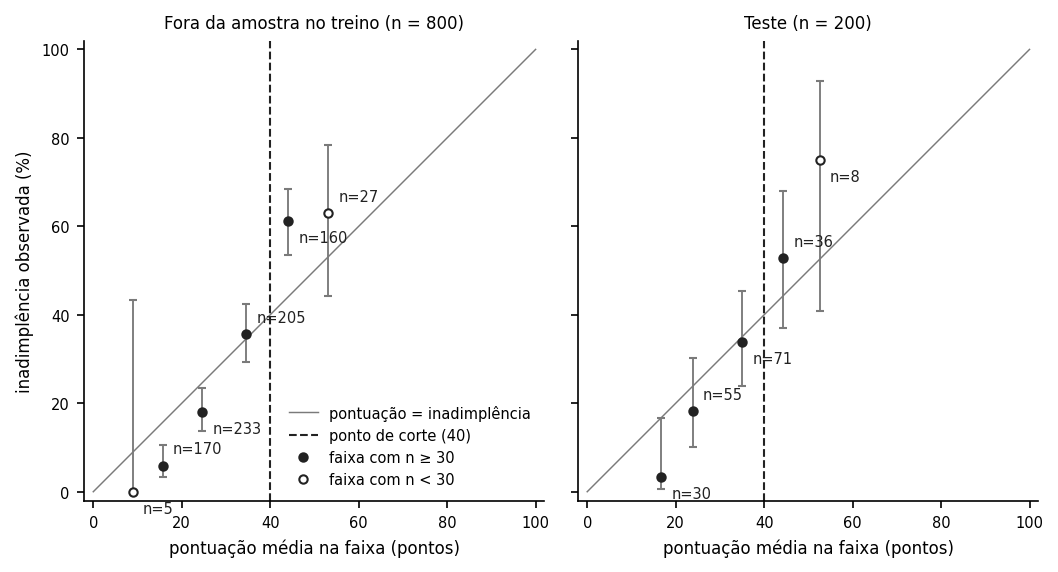

Legenda: cada ponto é uma faixa de 10 pontos; barras = IC95% de Wilson da inadimplência observada; n = pedidos na faixa (marcador vazado: n < 30, intervalo largo). Pontos sobre a diagonal indicariam que a pontuação se comporta como probabilidade.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("pipe_final", "X_treino", "y_treino", "y_teste", "prob_teste")

with Secao("Componente 4 – Calibração (complementar)"):
    yt, ytr = y_teste.values, y_treino.values
    p_oof = cross_val_predict(clone(pipe_final), X_treino, y_treino, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semente("cv_calibracao")),
                              method="predict_proba", n_jobs=-1)[:, 1]
    BORDAS = np.linspace(0, 1, 11)

    def tabela_confiabilidade(y_, p_):
        linhas = []
        for i, (lo, hi) in enumerate(zip(BORDAS[:-1], BORDAS[1:])):
            m = (p_ >= lo) & ((p_ < hi) if i < len(BORDAS) - 2 else (p_ <= hi))
            n = int(m.sum())
            if n == 0:
                continue
            k = int(y_[m].sum())
            ic = wilson(k, n)
            linhas.append(dict(faixa=f"{lo * 100:.0f} a {hi * 100:.0f}", lo=float(lo), hi=float(hi), n=n, pontuacao_media=float(p_[m].mean()), taxa_observada=k / n, ic_inf=ic[0], ic_sup=ic[1]))
        return pd.DataFrame(linhas)

    def ece(tab):
        return float((tab["n"] * (tab["taxa_observada"] - tab["pontuacao_media"]).abs()).sum() / tab["n"].sum())

    conf_oof, conf_teste = tabela_confiabilidade(ytr, p_oof), tabela_confiabilidade(yt, prob_teste)
    ece_oof, ece_teste = ece(conf_oof), ece(conf_teste)
    brier_oof, auc_oof, brier_teste = brier_score_loss(ytr, p_oof), roc_auc_score(ytr, p_oof), brier_score_loss(yt, prob_teste)
    mostrar = conf_oof.drop(columns=["lo", "hi"]).assign(pontuacao_media=(conf_oof["pontuacao_media"] * 100).round(1), taxa_observada=(conf_oof["taxa_observada"] * 100).round(1),
                              ic_inf=(conf_oof["ic_inf"] * 100).round(1), ic_sup=(conf_oof["ic_sup"] * 100).round(1))
    mostrar.columns = ["faixa de pontuação (pontos)", "n", "pontuação média (pontos)", "inadimplência observada (%)", "IC95% inf.", "IC95% sup."]
    print(f"Curva de confiabilidade (predições FORA DA AMOSTRA no treino, 5 partes; n = {len(ytr)}):")
    display(mostrar)
    print(f"Brier fora da amostra (partição da curva de confiabilidade) {br(brier_oof, 3)} | AUC {br(auc_oof, 3)} | ECE (erro médio de calibração) {br(ece_oof, 3)} | teste: Brier {br(brier_teste, 3)}, ECE {br(ece_teste, 3)}")
    print(f"Pontuação máxima: {pts(p_oof.max())} fora da amostra e {pts(prob_teste.max())} no teste, numa escala de 0 a 100.")

    ECE_MAX, N_MIN_FAIXA = 0.05, 30      # critério fixado ANTES do resultado (convenção deste trabalho, não norma)
    grandes = conf_oof[conf_oof["n"] >= N_MIN_FAIXA]
    diagonal_ok = bool(((grandes["pontuacao_media"] >= grandes["ic_inf"]) & (grandes["pontuacao_media"] <= grandes["ic_sup"])).all())
    calibrado_ok = bool(ece_oof <= ECE_MAX and diagonal_ok)
    print(f"Critério (a priori): ECE ≤ {br(ECE_MAX, 2)} e, nas faixas com n ≥ {N_MIN_FAIXA}, a pontuação média dentro do IC95% da taxa observada.")
    print(f"ECE ok: {ece_oof <= ECE_MAX} | diagonal dentro do IC nas faixas grandes: {diagonal_ok} -> calibrado_ok = {calibrado_ok}")
    print("Consequência: " + ("a pontuação se comporta como probabilidade no conjunto, mas isso não garante o número de um caso individual."
                              if calibrado_ok else "a pontuação NÃO é probabilidade e é apresentada como pontuação (escala de 0 a 100), sem '%'; "
                                                   "ao titular, ela é informada como escala, junto do ponto de corte (componente 8)."))

    # Alternativas de calibração, avaliadas por validação aninhada no treino (o teste não participa)
    cv_ext = StratifiedKFold(n_splits=5, shuffle=True, random_state=semente("cv_calibracao_externa"))
    resultados_cal = {"sem calibração": brier_score_loss(ytr, cross_val_predict(clone(pipe_final), X_treino, y_treino, cv=cv_ext, method="predict_proba", n_jobs=-1)[:, 1])}   # mesma partição das alternativas
    for metodo, nome in (("sigmoid", "sigmoide (Platt)"), ("isotonic", "isotônica")):
        cal = CalibratedClassifierCV(estimator=clone(pipe_final), method=metodo,
                                     cv=StratifiedKFold(PARAMETROS["cv_interno_calibracao"], shuffle=True, random_state=semente("cv_calibracao_interna")))
        resultados_cal[nome] = brier_score_loss(ytr, cross_val_predict(cal, X_treino, y_treino, cv=cv_ext, method="predict_proba", n_jobs=-1)[:, 1])
    melhor_alt = min((k for k in resultados_cal if k != "sem calibração"), key=lambda k: resultados_cal[k])
    melhoria = (resultados_cal["sem calibração"] - resultados_cal[melhor_alt]) / resultados_cal["sem calibração"]
    MELHORIA_MIN_CALIBRAR = 0.05      # critério a priori (convenção deste trabalho): calibrar se o Brier cair pelo menos 5%
    recomenda_calibrar = bool(melhoria >= MELHORIA_MIN_CALIBRAR)
    print("\nBrier fora da amostra (aninhado): " + "; ".join(f"{k} {br(v, 4)}" for k, v in resultados_cal.items()))
    print(f"Melhor alternativa: {melhor_alt}, melhoria relativa de {pct(melhoria)} (critério: ≥ {pct(MELHORIA_MIN_CALIBRAR, 0)}; "
          f"margem de {br(abs(melhoria - MELHORIA_MIN_CALIBRAR) * 100)} {'ponto percentual' if abs(melhoria - MELHORIA_MIN_CALIBRAR) < 0.02 else 'pontos percentuais'} {'acima' if recomenda_calibrar else 'abaixo'} do limiar).")
    if recomenda_calibrar:
        print("Troca declarada: o critério indicaria calibrar, mas aqui NÃO se calibra, para que a soma do SHAP feche exatamente na pontuação exibida ao titular. "
              "A calibração preserva a ordem, mas muda a escala e exigiria refazer a explicação. Em produção: calibrar e refazer a explicação sobre o modelo calibrado. "
              "Até lá, a pontuação é escala, não probabilidade.")
    else:
        print("O critério não indica calibrar; a pontuação continua apresentada como escala, não como probabilidade.")

    ESTADO.calibracao = dict(n_oof=int(len(ytr)), brier_oof=float(brier_oof), auc_oof=float(auc_oof), ece_oof=ece_oof, ece_teste=ece_teste, calibrado_ok=calibrado_ok,
                             melhor_alternativa=melhor_alt, melhoria_relativa=float(melhoria), recomenda_calibrar=recomenda_calibrar,
                             confiabilidade_oof=conf_oof.to_dict(orient="records"), maximo_oof=float(p_oof.max()))
    ESTADO.p_oof = p_oof

    forma("E, A", "curva de confiabilidade (Figura NB1)")
    fig, eixos = nova_figura(LARG_2COL, 3.7, 1, 2, sharey=True)
    for ax, tab, titulo in ((eixos[0], conf_oof, f"Fora da amostra no treino (n = {len(ytr)})"), (eixos[1], conf_teste, f"Teste (n = {len(yt)})")):
        ax.plot([0, 100], [0, 100], color=COR_NEUTRA, linestyle="-", linewidth=0.7, label="pontuação = inadimplência")
        ax.axvline(LIMIAR_RISCO * 100, color=COR_ESCURA, linestyle="--", linewidth=1.0, label=f"ponto de corte ({br(LIMIAR_RISCO * 100, 0)})")
        erro = np.vstack([tab["taxa_observada"] - tab["ic_inf"], tab["ic_sup"] - tab["taxa_observada"]]) * 100
        ax.errorbar(tab["pontuacao_media"] * 100, tab["taxa_observada"] * 100, yerr=erro, fmt="none", ecolor=COR_NEUTRA, capsize=2, linewidth=0.9)
        grande = (tab["n"] >= N_MIN_FAIXA).values
        ax.plot(tab["pontuacao_media"][grande] * 100, tab["taxa_observada"][grande] * 100, "o", color=COR_ESCURA, markersize=4, label=f"faixa com n ≥ {N_MIN_FAIXA}")
        ax.plot(tab["pontuacao_media"][~grande] * 100, tab["taxa_observada"][~grande] * 100, "o", markerfacecolor="white", markeredgecolor=COR_ESCURA, markersize=4, label=f"faixa com n < {N_MIN_FAIXA}")
        for i_f, (_, l) in enumerate(tab.iterrows()):      # rótulos alternados acima/abaixo: faixas vizinhas não se sobrepõem
            ax.annotate(f"n={l['n']}", (l["pontuacao_media"] * 100, l["taxa_observada"] * 100), xytext=(5, 6 if i_f % 2 else -10), textcoords="offset points", fontsize=7, color=COR_ESCURA)
        ax.set_xlim(-2, 102)          # folga para o marcador de uma faixa em 0 ou 100 não ser cortado pela borda
        ax.set_ylim(-2, 102)
        ax.set_aspect("equal")
        ax.set_xlabel("pontuação média na faixa (pontos)")
        ax.set_title(titulo)
    eixos[0].set_ylabel("inadimplência observada (%)")
    eixos[0].legend(frameon=False, loc="lower right")
    figura(1, "confiabilidade", fig,
           "Calibração: pontuação e inadimplência observada, por faixa de pontuação",
           f"Legenda: cada ponto é uma faixa de 10 pontos; barras = IC95% de Wilson da inadimplência observada; n = pedidos na faixa (marcador vazado: n < {N_MIN_FAIXA}, "
           "intervalo largo). Pontos sobre a diagonal indicariam que a pontuação se comporta como probabilidade.", "E, A", destino="complementar")

### Componente 5 — Desempenho por grupos

**O que é.** Mesmo sem usar atributos como idade ou sexo, o modelo pode discriminar por meio de variáveis correlacionadas a eles [Barocas e Selbst 2016]. A equipe deve comparar os erros entre grupos.

**Classe, público e LGPD.** **Recomendável** (não atende a P2 nem a P3) · E, N, A · apoia o art. 6º, IX (não discriminação), e o art. 20, § 2º (auditoria).

**Neste notebook.** As variáveis vedadas pelas regras de negócio (componente 1) ficam no cadastro para esta verificação. **Estrangeiro e sexo.** Na base corrigida, `foreign_worker` tem codificação válida, mas há só 37 estrangeiros: os intervalos ficam largos. O sexo é só parcialmente recuperável de `personal_status`, porque a categoria 2 reúne «mulher não solteira» e «homem solteiro» [Grömping 2019]. Compara-se, então, «mulher solteira» (categoria 4) com os homens das categorias 1 e 3 (divorciados, separados, casados ou viúvos), sem os 310 casos da categoria 2; a comparação mistura sexo e estado civil e vale só como indício.

**O que se verifica, sem decisão normativa.** (1) O efeito da **idade**, que o modelo usa: AUC e decisões com e sem a variável (o peso médio da idade no SHAP está nos Fatores da decisão). (2) ***Proxies*:** se as variáveis do modelo reconstroem os atributos vedados [Feldman et al. 2015], medido pela AUC fora da amostra de uma floresta que tenta prevê-los. (3) **Métricas por grupo** (faixa etária, estrangeiro e sexo parcial; faixas etárias ilustrativas, sem fonte, e o teste é repetido com o corte de 25 anos): taxa de reprovação, **FPR** (bons pagadores reprovados / bons pagadores) e **FNR** (inadimplentes aprovados / inadimplentes), em **1.000 previsões fora da amostra**. Um grupo é **sinalizado** quando o IC95% de Wilson de sua taxa **não se sobrepõe** ao do grupo de comparação; é só descritivo (não se testa nem se impõe igualdade). Atributos potencialmente discriminatórios não vedados, como a idade, podem pesar na decisão; a explicação **expõe** isso, e decidir se vedar ou justificar é questão **normativa**, fora do escopo.

['personal_status', 'foreign_worker']: vedadas no modelo; auditadas por grupo abaixo (estrangeiro com n pequeno; sexo só em parte).

>>> Forma para equipe de desenvolvimento e auditor (E, A): efeito da idade, teste de proxy e métricas por grupo com IC95% (Figura NB2)

Idade: AUC fora da amostra com idade 0,784 x sem idade 0,782; decisões que mudariam sem a idade: 29 de 800 (3,6%).
Poucas decisões mudando não implica ausência de efeito desigual. O modelo USA a idade; vedar ou justificar o uso é decisão normativa, fora do escopo.
Proxy de «trabalhador estrangeiro» (n = 1000, 37 no grupo): AUC fora da amostra 0,82 (IC95% 0,75 a 0,89) -> as variáveis do modelo reconstroem bem o atributo: a vedação, sozinha, não retira essa informação das entradas do modelo; se ela pesa na decisão, ver as métricas por grupo.
Proxy de «mulher solteira (x homens das categorias 1 e 3)» (n = 690, 92 no grupo): AUC fora da amostra 0,82 (IC95% 0,77 a 0,86) -> as variáveis do modelo reconstroem bem o atributo: a v

,família,grupo,n,comparação,taxa de reprovação,FPR: bons pagadores reprovados / bons pagadores,FNR: inadimplentes aprovados / inadimplentes,IC sem sobreposição com a comparação
0,Faixa etária,até 24 anos,150,25 a 59 anos (referência) (n = 799),43% (65/150; IC95% 36% a 51%),33% (29/88; IC95% 24% a 43%),42% (26/62; IC95% 30% a 54%),reprovação FPR
1,Faixa etária,60 anos ou mais,51,25 a 59 anos (referência) (n = 799),20% (10/51; IC95% 11% a 32%),13% (5/38; IC95% 6% a 27%),62% (8/13; IC95% 36% a 82%),não
2,Trabalhador estrangeiro,trabalhador estrangeiro,37,não estrangeiros (n = 963),16% (6/37; IC95% 8% a 31%),9% (3/33; IC95% 3% a 24%),25% (1/4; IC95% 5% a 70%),não
3,Sexo (parcial),mulher solteira,92,homens (categorias 1 e 3) (n = 598),17% (16/92; IC95% 11% a 26%),13% (9/67; IC95% 7% a 24%),72% (18/25; IC95% 52% a 86%),não


Grupos sinalizados (IC95% sem sobreposição com o da comparação): até 24 anos (n = 150): FPR 33% contra 10% em 25 a 59 anos (referência), reprovação 43% contra 20%
O menor grupo ('trabalhador estrangeiro') tem 37 casos, e seus intervalos são largos. 'Sem sinal' não prova ausência de tratamento desigual, e 'sinal' não prova discriminação; o que fazer com um sinal é decisão normativa (governança e revisão jurídica), fora do escopo.
Sensibilidade ao corte da faixa jovem (FPR, bons pagadores reprovados): até 24 anos 33% (29/88) contra 10% na referência até 59 anos (57/574), sinalizada; até 25 anos 29% (32/110) contra 10% na referência até 59 anos (54/552), sinalizada. O sinal se mantém com os dois cortes.
Figura NB2 – Reprovação e erros por grupo, com IC95%


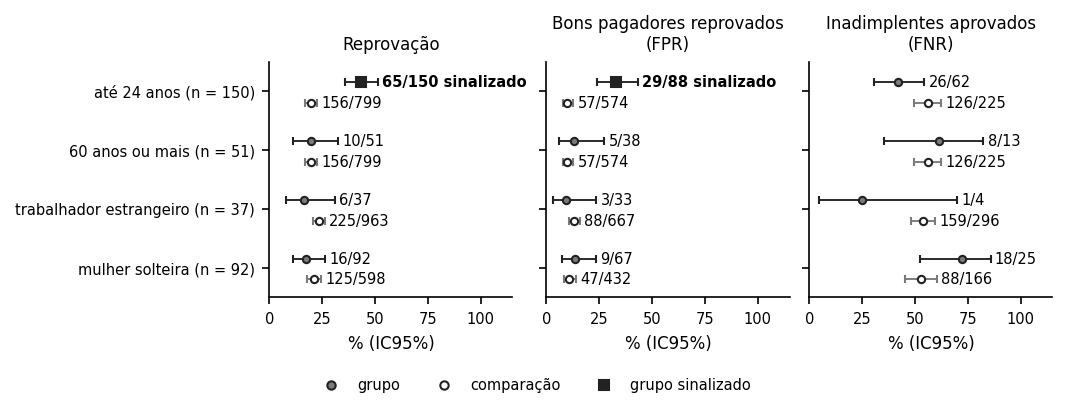

Legenda: por grupo, em 1.000 previsões fora da amostra, ponto = taxa e barra = IC95% de Wilson; ao lado, numerador/denominador da taxa (FPR: bons pagadores reprovados / bons pagadores; FNR: inadimplentes aprovados / inadimplentes). Marcador vazado = comparação: nas faixas etárias, a de 25 a 59 anos (referência); no estrangeiro, os não estrangeiros; na mulher solteira, os homens das categorias 1 e 3 (sem a categoria mista). Quadrado preto = grupo sinalizado, quando o IC95% de sua reprovação ou FPR não se sobrepõe ao da comparação; é descritivo, não prova discriminação. Estrangeiros: n pequeno.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.

>>> Forma para área de negócio (N): grupos sinalizados, em uma frase
Atenção: no grupo «até 24 anos» (150 pedidos), 33% dos bons pagadores foram reprovados, contra 10% em 25 a 59 anos (referência). É um sinal descritivo, não prova de discriminação; a decisão sobre o que fazer é de governança.
As vari

In [ ]:
exigir("X_completo", "X_treino", "X_teste", "y_treino", "y_teste", "p_oof", "prob_teste", "colunas_usadas", "colunas_cat", "colunas_num", "pipe_final")
conferir("vedadas_fora_do_modelo", all(v not in colunas_usadas for v in VARIAVEIS_VEDADAS))
print(f"{VARIAVEIS_VEDADAS}: vedadas no modelo; auditadas por grupo abaixo (estrangeiro com n pequeno; sexo só em parte).")

def sem_sobreposicao(k1, n1, k2, n2):
    """True se os IC95% de Wilson de k1/n1 e k2/n2 não se sobrepõem."""
    if n1 == 0 or n2 == 0:
        return False
    a, b = wilson(k1, n1), wilson(k2, n2)
    return bool(a[0] > b[1] or b[0] > a[1])

with Secao("Componente 5 – Desempenho por grupos"):
    forma("E, A", "efeito da idade, teste de proxy e métricas por grupo com IC95% (Figura NB2)")
    # ----- 1) idade (o peso médio no SHAP é calculado nos Fatores da decisão, componente 12)
    sem_idade = [c for c in colunas_usadas if c != "age"]
    params_modelo = {k: v for k, v in pipe_final.named_steps["modelo"].get_params().items() if k in ("n_estimators", "max_depth", "min_samples_leaf", "bootstrap", "max_features")}
    clf_sem = criar_pipeline(colunas_cat, [c for c in colunas_num if c != "age"], **params_modelo, random_state=semente("floresta_final"))
    p_sem = cross_val_predict(clf_sem, X_treino[sem_idade], y_treino, cv=StratifiedKFold(5, shuffle=True, random_state=semente("cv_calibracao")), method="predict_proba", n_jobs=-1)[:, 1]
    auc_com, auc_sem = roc_auc_score(y_treino, p_oof), roc_auc_score(y_treino, p_sem)
    mudam = int(((p_oof >= LIMIAR_RISCO) != (p_sem >= LIMIAR_RISCO)).sum())
    print(f"\nIdade: AUC fora da amostra com idade {br(auc_com, 3)} x sem idade {br(auc_sem, 3)}; "
          f"decisões que mudariam sem a idade: {mudam} de {len(p_oof)} ({pct(mudam / len(p_oof))}).")
    print("Poucas decisões mudando não implica ausência de efeito desigual. O modelo USA a idade; vedar ou justificar o uso é decisão normativa, fora do escopo.")
    ESTADO.idade = dict(auc_com=float(auc_com), auc_sem=float(auc_sem), decisoes_que_mudam=mudam, n=int(len(p_oof)))

    # ----- 2) proxies: as variáveis do modelo reconstroem os atributos vedados? (AUC fora da amostra, 5 partes, na base inteira)
    PROXY_FORTE = 0.70        # convenção deste trabalho (ilustrativa): AUC a partir da qual o atributo é bem reconstruído pelas demais variáveis
    status_ps, estrangeiro = X_completo["personal_status"].astype(str), X_completo["foreign_worker"].astype(str)
    CATS_HOMEM, CAT_MISTA = ["male div/sep", "male mar/wid"], "female non-single or male single"
    alvos_proxy = {"trabalhador estrangeiro": (estrangeiro.isin(["yes", "no"]), (estrangeiro == "yes").astype(int)),
                   "mulher solteira (x homens das categorias 1 e 3)": (status_ps != CAT_MISTA, (status_ps == "female single").astype(int))}
    proxies = {}
    for nome, (filtro, alvo) in alvos_proxy.items():
        Xp, yp = X_completo.loc[filtro, colunas_usadas], alvo[filtro]
        clf_p = criar_pipeline(colunas_cat, colunas_num, **params_modelo, random_state=semente(f"floresta_proxy|{nome}"))
        pp = cross_val_predict(clf_p, Xp, yp, cv=StratifiedKFold(5, shuffle=True, random_state=semente(f"cv_proxy|{nome}")), method="predict_proba", n_jobs=-1)[:, 1]
        auc_p = float(roc_auc_score(yp, pp))
        ic_p = ic_metrica_bootstrap(roc_auc_score, yp.values, pp, gerador(f"bootstrap_proxy|{nome}"), PARAMETROS["n_boot"])
        proxies[nome] = dict(n=int(len(yp)), n_grupo=int(yp.sum()), auc=auc_p, ic95=[float(ic_p[0]), float(ic_p[1])], forte=bool(auc_p >= PROXY_FORTE))
        print(f"Proxy de «{nome}» (n = {len(yp)}, {int(yp.sum())} no grupo): AUC fora da amostra {br(auc_p, 2)} (IC95% {br(ic_p[0], 2)} a {br(ic_p[1], 2)}) -> "
              + ("as variáveis do modelo reconstroem bem o atributo: a vedação, sozinha, não retira essa informação das entradas do modelo; se ela pesa na decisão, ver as métricas por grupo." if auc_p >= PROXY_FORTE
                 else f"reconstrução abaixo de {br(PROXY_FORTE, 2)} (convenção deste trabalho); não prova ausência de efeito por grupo."))
    print("No sexo, a separação também reflete estado civil e idade (a categoria 4 é de mulheres solteiras; as 1 e 3, de homens que já se casaram).")
    ESTADO.proxies = proxies

    # ----- 3) métricas por grupo, em 1.000 previsões fora da amostra
    idx_todos = list(X_treino.index) + list(X_teste.index)
    dec_todos = (np.concatenate([p_oof, prob_teste]) >= LIMIAR_RISCO).astype(int)
    y_todos = np.concatenate([y_treino.values, y_teste.values])
    meta = X_completo.loc[idx_todos]
    idade = meta["age"].astype(float).values
    ps_t, fw_t = meta["personal_status"].astype(str).values, meta["foreign_worker"].astype(str).values
    IDADE_JOVEM_MAX, IDADE_IDOSO_MIN = 24, 60      # faixas ILUSTRATIVAS (convenção deste trabalho, sem fonte); a sensibilidade ao corte de 25 anos é impressa abaixo
    faixas = {f"até {IDADE_JOVEM_MAX} anos": idade <= IDADE_JOVEM_MAX, f"{IDADE_JOVEM_MAX + 1} a {IDADE_IDOSO_MIN - 1} anos": (idade > IDADE_JOVEM_MAX) & (idade < IDADE_IDOSO_MIN),
              f"{IDADE_IDOSO_MIN} anos ou mais": idade >= IDADE_IDOSO_MIN}
    NOME_REF_IDADE = f"{IDADE_JOVEM_MAX + 1} a {IDADE_IDOSO_MIN - 1} anos"
    grupos = {      # família -> {grupo: (máscara do grupo, máscara da comparação, nome da comparação)}
        # faixas etárias comparadas com a faixa de REFERÊNCIA (25 a 59 anos), não com o «restante»: evita contar duas vezes o mesmo achado
        "Faixa etária": {nome: (m, faixas[NOME_REF_IDADE], f"{NOME_REF_IDADE} (referência)") for nome, m in faixas.items() if nome != NOME_REF_IDADE},
        "Trabalhador estrangeiro": {"trabalhador estrangeiro": (fw_t == "yes", fw_t == "no", "não estrangeiros")},
        "Sexo (parcial)": {"mulher solteira": (ps_t == "female single", np.isin(ps_t, CATS_HOMEM), "homens (categorias 1 e 3)")},
    }
    linhas_g, resultado_grupos = [], []
    for familia, dic in grupos.items():
        for nome, (m, rest, nome_comp) in dic.items():
            n = int(m.sum())
            if n == 0:
                continue
            def contagens(mask):
                bons, maus = int((y_todos[mask] == 0).sum()), int((y_todos[mask] == 1).sum())
                return dict(n=int(mask.sum()), rep=int(dec_todos[mask].sum()), bons=bons, maus=maus,
                            fp=int(((dec_todos[mask] == 1) & (y_todos[mask] == 0)).sum()), fn=int(((dec_todos[mask] == 0) & (y_todos[mask] == 1)).sum()))
            g, r = contagens(m), contagens(rest)
            sinal_rep = sem_sobreposicao(g["rep"], g["n"], r["rep"], r["n"])
            sinal_fpr = sem_sobreposicao(g["fp"], g["bons"], r["fp"], r["bons"])
            linhas_g.append({"família": familia, "grupo": nome, "n": n, "comparação": f"{nome_comp} (n = {r['n']})", "taxa de reprovação": pct_ic(g["rep"], g["n"], 0),
                             "FPR: bons pagadores reprovados / bons pagadores": pct_ic(g["fp"], g["bons"], 0) if g["bons"] else "—",
                             "FNR: inadimplentes aprovados / inadimplentes": pct_ic(g["fn"], g["maus"], 0) if g["maus"] else "—",
                             "IC sem sobreposição com a comparação": ("reprovação " if sinal_rep else "") + ("FPR" if sinal_fpr else "") or "não"})
            resultado_grupos.append(dict(familia=familia, grupo=nome, comparacao=nome_comp, **g, taxa_reprovacao=g["rep"] / n, ic_reprovacao=list(wilson(g["rep"], n)),
                                         fpr=(g["fp"] / g["bons"] if g["bons"] else None), ic_fpr=list(wilson(g["fp"], g["bons"])) if g["bons"] else [None, None],
                                         fnr=(g["fn"] / g["maus"] if g["maus"] else None), ic_fnr=list(wilson(g["fn"], g["maus"])) if g["maus"] else [None, None],
                                         fpr_restante=(r["fp"] / r["bons"] if r["bons"] else None), sinal_reprovacao=sinal_rep, sinal_fpr=sinal_fpr, restante=r))
    pd.set_option("display.max_colwidth", None)
    pd.set_option("display.width", 220)
    print("\nMétricas por grupo (1.000 previsões fora da amostra; ponto de corte atual):")
    display(pd.DataFrame(linhas_g))
    sinalizados = [r for r in resultado_grupos if r["sinal_fpr"] or r["sinal_reprovacao"]]
    print("Grupos sinalizados (IC95% sem sobreposição com o da comparação): " + ("; ".join(
        f"{r['grupo']} (n = {r['n']}): FPR {pct(r['fpr'], 0)} contra {pct(r['fpr_restante'], 0)} em {r['comparacao']}, reprovação {pct(r['taxa_reprovacao'], 0)} contra {pct(r['restante']['rep'] / r['restante']['n'], 0)}" for r in sinalizados) if sinalizados else "nenhum"))
    menor = min(resultado_grupos, key=lambda r: r["n"]) if resultado_grupos else dict(grupo="—", n=0)
    print(f"O menor grupo ('{menor['grupo']}') tem {menor['n']} casos, e seus intervalos são largos. 'Sem sinal' não prova ausência de tratamento desigual, e 'sinal' não prova discriminação; "
          "o que fazer com um sinal é decisão normativa (governança e revisão jurídica), fora do escopo.")
    ESTADO.grupos = resultado_grupos
    # Sensibilidade ao corte da faixa jovem (o achado depende de uma faixa ilustrativa): repete o teste com outro corte
    sens_corte = []
    for corte in (IDADE_JOVEM_MAX, IDADE_JOVEM_MAX + 1):
        m_j, m_ref = idade <= corte, (idade > corte) & (idade < IDADE_IDOSO_MIN)      # jovem × referência (até 59 anos)
        bons_j, bons_r = (y_todos == 0) & m_j, (y_todos == 0) & m_ref
        fp_j, fp_r = int((dec_todos[bons_j] == 1).sum()), int((dec_todos[bons_r] == 1).sum())
        sens_corte.append(dict(corte=corte, fp=fp_j, bons=int(bons_j.sum()), fp_r=fp_r, bons_r=int(bons_r.sum()),
                               sinal=sem_sobreposicao(fp_j, int(bons_j.sum()), fp_r, int(bons_r.sum()))))
    print("Sensibilidade ao corte da faixa jovem (FPR, bons pagadores reprovados): " + "; ".join(
        f"até {s_['corte']} anos {pct(s_['fp'] / s_['bons'], 0) if s_['bons'] else '—'} ({s_['fp']}/{s_['bons']}) contra {pct(s_['fp_r'] / s_['bons_r'], 0) if s_['bons_r'] else '—'} na referência até {IDADE_IDOSO_MIN - 1} anos "
        f"({s_['fp_r']}/{s_['bons_r']}), {'sinalizada' if s_['sinal'] else 'não sinalizada'}" for s_ in sens_corte)
          + (". O sinal se mantém com os dois cortes." if all(s_["sinal"] for s_ in sens_corte) else ". O sinal depende do corte: tratar como indício frágil." if any(s_["sinal"] for s_ in sens_corte) else "."))
    ESTADO.sensibilidade_corte_idade = sens_corte

    fig, eixos = nova_figura(LARG_2COL, max(2.6, 1.0 + 0.38 * len(resultado_grupos)), 1, 3, sharey=True)
    paineis = (("Reprovação", "rep", "n", "sinal_reprovacao"), ("Bons pagadores reprovados\n(FPR)", "fp", "bons", "sinal_fpr"),
               ("Inadimplentes aprovados\n(FNR)", "fn", "maus", None))
    for ax, (titulo, num, den, chave_sinal) in zip(eixos, paineis):
        for i, r in enumerate(resultado_grupos):
            sinal = bool(chave_sinal and r[chave_sinal])
            for dy, cont, cheio in ((-0.15, r, True), (0.2, r["restante"], False)):
                k_, n_ = cont[num], cont[den]
                if not n_:
                    continue
                v, (a, b) = 100 * k_ / n_, wilson(k_, n_)
                ax.errorbar(v, i + dy, xerr=[[v - 100 * a], [100 * b - v]], fmt="s" if (cheio and sinal) else "o", markersize=4.5 if (cheio and sinal) else 3.5,
                            markerfacecolor=(COR_ESCURA if sinal else COR_NEUTRA) if cheio else "white", markeredgecolor=COR_ESCURA,
                            ecolor=COR_ESCURA if cheio else COR_NEUTRA, elinewidth=0.9, capsize=2)
                ax.text(100 * b + 2, i + dy, f"{k_}/{n_}" + (" sinalizado" if (cheio and sinal) else ""), va="center", fontsize=7,
                        fontweight="bold" if (cheio and sinal) else "normal")
        ax.set_title(titulo)
        ax.set_xlabel("% (IC95%)")
        ax.set_xlim(0, 115)
        ax.set_xticks([0, 25, 50, 75, 100])
    eixos[0].set_yticks(range(len(resultado_grupos)), [f"{r['grupo']} (n = {r['n']})" for r in resultado_grupos])
    eixos[0].set_ylim(len(resultado_grupos) - 0.5, -0.5)
    from matplotlib.lines import Line2D
    itens_leg = [(Line2D([], [], marker="o", linestyle="none", markerfacecolor=COR_NEUTRA, markeredgecolor=COR_ESCURA, markersize=4), "grupo"),
                 (Line2D([], [], marker="o", linestyle="none", markerfacecolor="white", markeredgecolor=COR_ESCURA, markersize=4), "comparação")]
    if sinalizados:      # o item só entra se houver faixa sinalizada
        itens_leg.append((Line2D([], [], marker="s", linestyle="none", markerfacecolor=COR_ESCURA, markeredgecolor=COR_ESCURA, markersize=5), "grupo sinalizado"))
    fig.legend([h for h, _ in itens_leg], [r_ for _, r_ in itens_leg], loc="outside lower center", ncol=len(itens_leg), frameon=False)
    if sinalizados:
        s = sinalizados[0]
        tx_rest = s["restante"]["rep"] / s["restante"]["n"]
        titulo_g = "Reprovação e erros por grupo, com IC95%"
    else:
        titulo_g = "Reprovação e erros por grupo, com IC95%"
    figura(2, "metricas_por_grupo", fig, titulo_g,
           "Legenda: por grupo, em 1.000 previsões fora da amostra, ponto = taxa e barra = IC95% de Wilson; ao lado, numerador/denominador da taxa "
           "(FPR: bons pagadores reprovados / bons pagadores; FNR: inadimplentes aprovados / inadimplentes). Marcador vazado = comparação: nas faixas etárias, a de 25 a 59 anos (referência); "
           "no estrangeiro, os não estrangeiros; na mulher solteira, os homens das categorias 1 e 3 (sem a categoria mista). Quadrado preto = grupo sinalizado, quando o IC95% "
           "de sua reprovação ou FPR não se sobrepõe ao da comparação; é descritivo, não prova discriminação. Estrangeiros: n pequeno.",
           "E, N, A")

    forma("N", "grupos sinalizados, em uma frase")
    if sinalizados:
        print("Atenção: " + "; ".join(f"no grupo «{r['grupo']}» ({r['n']} pedidos), {pct(r['fpr'], 0) if r['fpr'] is not None else '—'} dos bons pagadores foram reprovados, "
                                      f"contra {pct(r['fpr_restante'], 0) if r['fpr_restante'] is not None else '—'} em {r['comparacao']}" for r in sinalizados)
              + ". É um sinal descritivo, não prova de discriminação; a decisão sobre o que fazer é de governança.")
    else:
        print("Nenhum grupo se separou da comparação na reprovação nem nos bons pagadores reprovados; isso não prova ausência de tratamento desigual.")
    print("As variáveis do modelo reconstroem os atributos vedados com AUC de " + " e ".join(f"{br(v['auc'], 2)} ({k})" for k, v in proxies.items())
          + ": vedar a variável, sozinho, não retira essa informação do modelo.")

### Componente 6 — Estabilidade da decisão

**O que é.** Modelos com desempenho semelhante podem dar decisões diferentes para a mesma pessoa [Marx et al. 2020]. A equipe deve medir quanto a decisão de cada caso varia e, como **boa prática**, encaminhar os casos instáveis à revisão humana. Quando esse encaminhamento integra o fluxo de decisão, ele é um passo do procedimento e consta da Inferência (componente 10, obrigatório); a medida em si é recomendável, porque descreve a variação entre modelos, e não um critério aplicado ao caso.

**Classe, público e LGPD.** **Recomendável** (não atende a P2) · E, N, A · sem dispositivo. É a exceção declarada da Seção 3.1: não tem item nas fontes da Etapa 1 e foi incluída a partir de Marx et al. [2020].

**Neste notebook (a forma de medir é escolha deste trabalho).** A pontuação depende de **sorteios** (amostra de cada árvore, colunas consideradas em cada pergunta) e dos **dados de treino**. O mesmo `Pipeline` é **treinado de novo** 30 vezes com outras sementes e 30 vezes com **reamostragem do treino** (*bootstrap*, sem repetir a escolha de hiperparâmetros). Para cada pedido, mede-se a fração dos retreinos que mantém a decisão do modelo em uso: **estável** (≥ 95%), **pouco estável** (80% a 95%) ou **instável** (< 80%), pela menor das duas frações (convenção deste trabalho: abaixo de 80%, a decisão muda em mais de 1 a cada 5 retreinos). A regra do fluxo hipotético: um pedido **reprovado pelo modelo e instável** vai à **revisão humana antes da decisão final**. Isso é boa prática de projeto, não exigência legal: o texto vigente do art. 20 da LGPD garante o direito de solicitar a revisão, sem exigir que ela seja feita por pessoa natural [Brasil 2019]. Os retreinos são reutilizados na Inferência (verificação de cada caso), nas Alterações possíveis e nos Dados possivelmente errados (robustez das simulações) e no Registro da decisão.

**Incertezas que esta medida não cobre.** A estabilidade mede a variação entre retreinos do mesmo procedimento; não mede a incerteza de a base ser antiga, de outro país e com os maus sobreamostrados (componente 2), nem a de outros algoritmos.

In [ ]:
exigir("pipe_final", "X_treino", "y_treino", "X_teste", "y_teste", "prob_teste")

ESTAVEL_MIN, INSTAVEL_ABAIXO = 0.95, 0.80      # convenção deste trabalho (ilustrativa): classes de estabilidade e gatilho da revisão humana

def classe_estabilidade(f):
    return "estável" if f >= ESTAVEL_MIN else ("pouco estável" if f >= INSTAVEL_ABAIXO else "instável")

def verificar_estabilidade(df_pedidos, decisao_modelo=None):
    """Para cada pedido (DataFrame com as colunas do modelo): fração dos retreinos que mantém a decisão do modelo em uso,
    com outra semente e com treino reamostrado, e a classe pela MENOR das duas frações. Usada na Inferência e no Registro."""
    if decisao_modelo is None:
        decisao_modelo = pipe_final.predict_proba(df_pedidos)[:, 1] >= LIMIAR_RISCO
    Ps = np.array([m.predict_proba(df_pedidos)[:, 1] for m in ESTADO.retreinos_semente])
    Pr = np.array([m.predict_proba(df_pedidos)[:, 1] for m in ESTADO.retreinos_reamostra])
    ms, mr = ((Ps >= LIMIAR_RISCO) == decisao_modelo).mean(axis=0), ((Pr >= LIMIAR_RISCO) == decisao_modelo).mean(axis=0)
    return dict(P_semente=Ps, P_reamostra=Pr, mantida_semente=ms, mantida_reamostra=mr,
                classe=[classe_estabilidade(min(a, b)) for a, b in zip(ms, mr)])

with Secao("Componente 6 – Estabilidade da decisão (retreinos)"):
    n_s, n_r = PARAMETROS["n_retreinos_semente"], PARAMETROS["n_retreinos_reamostra"]
    retreinos_semente, retreinos_reamostra = [], []
    for k in range(n_s):
        m = clone(pipe_final).set_params(modelo__random_state=semente(f"floresta_retreino_semente|{k}"), modelo__oob_score=False)
        retreinos_semente.append(m.fit(X_treino, y_treino))
    for k in range(n_r):
        idx = gerador(f"reamostra_treino|{k}").integers(0, len(X_treino), len(X_treino))
        m = clone(pipe_final).set_params(modelo__random_state=semente(f"floresta_reamostra|{k}"), modelo__oob_score=False)
        retreinos_reamostra.append(m.fit(X_treino.iloc[idx], y_treino.iloc[idx]))
    ESTADO.update(retreinos_semente=retreinos_semente, retreinos_reamostra=retreinos_reamostra)

    decisao_prod = prob_teste >= LIMIAR_RISCO
    est_teste = verificar_estabilidade(X_teste, decisao_prod)
    P_semente, P_reamostra = est_teste["P_semente"], est_teste["P_reamostra"]
    mantida_semente, mantida_reamostra = est_teste["mantida_semente"], est_teste["mantida_reamostra"]

    reprov = np.where(decisao_prod)[0]
    instaveis = [int(i) for i in reprov if min(mantida_semente[i], mantida_reamostra[i]) < ESTAVEL_MIN]
    n_rep_teste = max(len(reprov), 1)
    yt_rep = y_teste.values[reprov]
    classes_rep = [est_teste["classe"][i] for i in reprov]
    por_classe = {cl: dict(n=sum(1 for x in classes_rep if x == cl), fp=int(sum(1 for x, yy in zip(classes_rep, yt_rep) if x == cl and yy == 0)))
                  for cl in ("estável", "pouco estável", "instável")}
    n_reamostra_menor = int((mantida_reamostra[reprov] < mantida_semente[reprov]).sum())
    # Universo do SISTEMA (regras antes do modelo): só chegam à verificação de estabilidade os aprovados pelas regras e reprovados pelo modelo
    regras_ok_teste = np.array([decidir_por_regras(X_teste.iloc[i])[0] == "aprovado" for i in range(len(X_teste))])
    reprov_sis = [i for i in reprov if regras_ok_teste[i]]
    inst_sis = [i for i in reprov_sis if est_teste["classe"][i] == "instável"]
    revisao_sistema = dict(n_reprovados_pelo_modelo_e_aprovados_pelas_regras=len(reprov_sis), n=len(inst_sis),
                           fp=int(sum(1 for i in inst_sis if y_teste.values[i] == 0)))

    forma("E, A", "fração de retreinos que mantém a decisão, por classe de estabilidade (reprovados do teste)")
    display(pd.DataFrame([{"classe (menor das duas frações)": cl, "reprovados do teste": d["n"], "dos quais FP (bons pagadores)": d["fp"],
                           "fração dos reprovados": pct(d["n"] / n_rep_teste, 0)} for cl, d in por_classe.items()]))
    print(f"Dos {len(reprov)} reprovados do teste, {len(instaveis)} ({pct(len(instaveis) / n_rep_teste, 0)}) mantêm a decisão em menos de {pct(ESTAVEL_MIN, 0)} dos retreinos "
          f"({n_s} com outra semente e {n_r} com treino reamostrado).")
    print(f"A fração de retreinos que mantém a reprovação é menor com treino reamostrado que com outra semente em {n_reamostra_menor} dos {len(reprov)} reprovados"
          + (": a incerteza do sorteio das árvores, sozinha, subestima a incerteza do sistema." if n_reamostra_menor > len(reprov) / 2
             else "; neste teste, o sorteio das árvores não subestima de forma geral a incerteza dos dados de treino."))

    print(f"Universo desta tabela: o MODELO ISOLADO (os {len(reprov)} pedidos do teste que o modelo reprova, sem considerar as regras de negócio).")

    forma("N", "carga de revisão humana que a regra de estabilidade geraria no fluxo do sistema")
    print(f"No fluxo do sistema (regras de negócio antes do modelo), só passam pela verificação os pedidos aprovados pelas regras e reprovados pelo modelo: "
          f"{revisao_sistema['n_reprovados_pelo_modelo_e_aprovados_pelas_regras']} dos 200 do teste. Com a regra «reprovado e instável → encaminhado à revisão humana antes da decisão (simulado)», "
          f"{revisao_sistema['n']} pedidos seriam encaminhados a uma pessoa; {revisao_sistema['fp']} deles eram, no histórico, de bons pagadores. "
          f"(Sem considerar as regras, seriam {por_classe['instável']['n']}: os outros {por_classe['instável']['n'] - revisao_sistema['n']} já são reprovados por regra e não chegam ao modelo.) "
          "É o mesmo número que o Registro da decisão (componente 16) mostra para este lote.")

    ESTADO.update(P_semente=P_semente, P_reamostra=P_reamostra, mantida_semente=mantida_semente, mantida_reamostra=mantida_reamostra,
                  classe_estab_teste=est_teste["classe"],
                  estabilidade_global=dict(n_reprovados_teste=int(len(reprov)), n_decisao_sensivel_ou_instavel=len(instaveis), fracao=float(len(instaveis) / n_rep_teste),
                                           n_reamostra_menor=n_reamostra_menor, por_classe=por_classe, revisao_sistema=revisao_sistema))


>>> Forma para equipe de desenvolvimento e auditor (E, A): fração de retreinos que mantém a decisão, por classe de estabilidade (reprovados do teste)


,classe (menor das duas frações),reprovados do teste,dos quais FP (bons pagadores),fração dos reprovados
0,estável,16,6,36%
1,pouco estável,15,6,34%
2,instável,13,7,30%


Dos 44 reprovados do teste, 28 (64%) mantêm a decisão em menos de 95% dos retreinos (30 com outra semente e 30 com treino reamostrado).
A fração de retreinos que mantém a reprovação é menor com treino reamostrado que com outra semente em 30 dos 44 reprovados: a incerteza do sorteio das árvores, sozinha, subestima a incerteza do sistema.
Universo desta tabela: o MODELO ISOLADO (os 44 pedidos do teste que o modelo reprova, sem considerar as regras de negócio).

>>> Forma para área de negócio (N): carga de revisão humana que a regra de estabilidade geraria no fluxo do sistema
No fluxo do sistema (regras de negócio antes do modelo), só passam pela verificação os pedidos aprovados pelas regras e reprovados pelo modelo: 30 dos 200 do teste. Com a regra «reprovado e instável → encaminhado à revisão humana antes da decisão (simulado)», 9 pedidos seriam encaminhados a uma pessoa; 7 deles eram, no histórico, de bons pagadores. (Sem considerar as regras, seriam 13: os outros 4 já são reprovados p

### Componente 7 — Seleção e aceite do modelo

**O que é.** A regra que define quando um modelo pode ser usado. O critério de sucesso é fixado no entendimento do negócio, antes do resultado [Studer et al. 2021, seção 3.1.2], e verificado na avaliação [Studer et al. 2021, seção 3.4]. O desempenho final do modelo é medido num conjunto de teste reservado, usado só ao fim da análise [Hastie et al. 2009, seção 7.2].

**Classe, público e LGPD.** **Recomendável** (não atende a P2 nem a P3) · E, N, A · sem dispositivo.

**Neste notebook.** O critério foi fixado **antes** do resultado, na Seção 0, por convenção deste trabalho (não é norma): o modelo só é aceito se a **AUC média da validação cruzada repetida no treino** (Métricas de desempenho) for **≥ 0,70**. O teste reservado entra só como confirmação final, com o seu IC95%. A escolha dos hiperparâmetros não é este componente: ela integra o Treinamento (componente 3). Se o critério não for atingido, o modelo não deveria seguir para uso, e o notebook continua só como ilustração.

**Linha de base (complementar).** Para decisões de alto impacto, Rudin [2019] defende modelos interpretáveis por construção em vez de caixas-pretas explicadas *post hoc*. Por isso uma regressão logística regularizada (L2, força escolhida por validação cruzada interna; números padronizados) é avaliada **nas mesmas partições** da validação cruzada e da curva de confiabilidade. Ela entra só como **referência de desempenho e calibração** para a decisão de aceite: não é explicada (sem SHAP nem LIME), e o *Random Forest* continua o modelo explicado, porque o manual trata o caso que exige explicação *post hoc*.

In [ ]:
def avaliar_aceite(auc, minimo):
    """Critério de aceite do modelo: AUC de validação >= mínimo declarado. AUC ausente (None/NaN) conta como NÃO atingido."""
    valida = auc is not None and not (isinstance(auc, float) and math.isnan(auc))
    aceito = bool(valida and auc >= minimo)
    texto = (f"Critério de aceite (a priori): AUC de validação cruzada ≥ {br(minimo, 2)}. Obtida: {br(auc, 3) if valida else '—'} -> "
             + ("ATINGIDO: o modelo é aceito para seguir." if aceito else "NÃO ATINGIDO: o modelo não deveria seguir para uso; o restante do notebook vale só como ilustração."))
    return dict(auc=(float(auc) if valida else None), minimo=float(minimo), aceito=aceito, texto=texto)

exigir("auc_cv", "metricas_teste")

with Secao("Componente 7 – Seleção e aceite do modelo"):
    aceite = avaliar_aceite(ESTADO.auc_cv, AUC_MIN_ACEITE)
    ESTADO.checks["modelo_aceito"] = aceite["aceito"]      # registra, não interrompe: se não aceito, o notebook segue só como ilustração
    ESTADO.aceite, ESTADO.auc_min_aceite = aceite, AUC_MIN_ACEITE
    auc_t = ESTADO.metricas_teste["AUC"]
    forma("E, A", "critério fixado antes, valor obtido e teste reservado")
    print(aceite["texto"])
    print(f"Teste reservado (usado só ao fim, sem participar de nenhuma escolha): AUC {br(auc_t['valor'], 3)} (IC95% {br(auc_t['ic95'][0], 3)} a {br(auc_t['ic95'][1], 3)}); "
          + ("o critério também fica dentro do IC95% do teste." if auc_t["ic95"][0] <= AUC_MIN_ACEITE <= auc_t["ic95"][1]
             else ("o IC95% do teste fica todo acima do critério." if auc_t["ic95"][0] > AUC_MIN_ACEITE else "o IC95% do teste fica todo abaixo do critério: rever o aceite.")))
    forma("N", "aceito ou não, em uma frase")
    print(("O modelo foi ACEITO para seguir: " if aceite["aceito"] else "O modelo NÃO foi aceito: ")
          + f"a regra combinada antes era ordenar os pedidos por risco com AUC de pelo menos {br(AUC_MIN_ACEITE, 2)}, e ele obteve {br(ESTADO.auc_cv, 2)} na validação "
          f"e {br(auc_t['valor'], 2)} no teste reservado. O aceite não diz se o limiar é adequado (componente 8).")


>>> Forma para equipe de desenvolvimento e auditor (E, A): critério fixado antes, valor obtido e teste reservado
Critério de aceite (a priori): AUC de validação cruzada ≥ 0,70. Obtida: 0,792 -> ATINGIDO: o modelo é aceito para seguir.
Teste reservado (usado só ao fim, sem participar de nenhuma escolha): AUC 0,742 (IC95% 0,668 a 0,810); o critério também fica dentro do IC95% do teste.

>>> Forma para área de negócio (N): aceito ou não, em uma frase
O modelo foi ACEITO para seguir: a regra combinada antes era ordenar os pedidos por risco com AUC de pelo menos 0,70, e ele obteve 0,79 na validação e 0,74 no teste reservado. O aceite não diz se o limiar é adequado (componente 8).


In [ ]:
exigir("pipe_final", "X_treino", "y_treino", "p_oof", "particoes_cv", "auc_cv_partes", "calibracao", "colunas_cat", "colunas_num")

import warnings
with Secao("Componente 7 – Linha de base (regressão logística)"), warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)      # avisos de mudança de padrão do LogisticRegressionCV em versões novas do scikit-learn; não alteram o resultado
    forma("E, A", "linha de base interpretável nas mesmas partições (complementar)")
    def criar_logistica():
        prep_lr = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(colunas_cat)), ("num", StandardScaler(), list(colunas_num))])
        lr = LogisticRegressionCV(Cs=np.logspace(-3, 1, 13), cv=StratifiedKFold(5, shuffle=True, random_state=semente("lr_cv_interno")), scoring="neg_log_loss", max_iter=5000)
        return Pipeline([("prep", prep_lr), ("modelo", lr)])
    ytr = y_treino.values
    auc_lr_partes = np.array([roc_auc_score(ytr[va], criar_logistica().fit(X_treino.iloc[tr], y_treino.iloc[tr]).predict_proba(X_treino.iloc[va])[:, 1])
                              for tr, va in ESTADO.particoes_cv])
    auc_rf_partes = np.array(ESTADO.auc_cv_partes)
    p_oof_lr = cross_val_predict(criar_logistica(), X_treino, y_treino, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=semente("cv_calibracao")),
                                 method="predict_proba", n_jobs=-1)[:, 1]          # mesma partição de p_oof (calibração)
    ece_lr = ece(tabela_confiabilidade(ytr, p_oof_lr))
    linhas_lb = [dict(modelo=nome, auc=a.mean(), dp=a.std(ddof=1), brier=brier_score_loss(ytr, po), ece=e_)
                 for nome, a, po, e_ in (("Random Forest (explicado)", auc_rf_partes, p_oof, ESTADO.calibracao["ece_oof"]),
                                         ("Regressão logística L2 (linha de base)", auc_lr_partes, p_oof_lr, ece_lr))]
    display(pd.DataFrame({"modelo": [l["modelo"] for l in linhas_lb],
                          f"AUC de validação cruzada ({len(auc_rf_partes)} partes, média ± dp)": [f"{br(l['auc'], 3)} ± {br(l['dp'], 3)}" for l in linhas_lb],
                          "Brier fora da amostra": [br(l["brier"], 3) for l in linhas_lb],
                          f"ECE fora da amostra (critério ≤ {br(ECE_MAX, 2)})": [br(l["ece"], 3) for l in linhas_lb]}))
    dif = auc_lr_partes - auc_rf_partes
    ep_ingenuo = dif.std(ddof=1) / np.sqrt(len(dif))     # erro-padrão ingênuo: ignora a sobreposição dos treinos, logo SUBESTIMA a incerteza
    empata = bool(abs(dif.mean()) < 2 * ep_ingenuo)
    lr_calibrada = bool(ece_lr <= ECE_MAX)
    print(f"Diferença pareada de AUC (logística − Random Forest, mesmas {len(dif)} partes): {f'{dif.mean():+.3f}'.replace('.', ',')}; "
          + ("menor que 2 erros-padrão ingênuos (que subestimam a incerteza): sem evidência clara de superioridade de um modelo em ordenação; não houve teste formal de equivalência." if empata
             else f"maior que 2 erros-padrão ingênuos: a {'logística' if dif.mean() > 0 else 'floresta'} ordena melhor nestas partições."))
    print(f"Calibração: ECE {br(ece_lr, 3)} na logística × {br(ESTADO.calibracao['ece_oof'], 3)} no Random Forest; a logística "
          + ("atende" if lr_calibrada else "não atende") + f" ao critério de calibração (ECE ≤ {br(ECE_MAX, 2)}).")
    if empata and lr_calibrada and not ESTADO.calibracao["calibrado_ok"]:
        print("Leitura: aqui não há evidência de ganho de ordenação da caixa-preta, que também calibra pior; para uso real, isso favoreceria o modelo interpretável. O notebook mantém o Random Forest como objeto do manual.")
    ESTADO.linha_de_base = dict(auc_lr=float(auc_lr_partes.mean()), dp_lr=float(auc_lr_partes.std(ddof=1)), auc_rf=float(auc_rf_partes.mean()), ece_lr=float(ece_lr),
                                brier_lr=float(brier_score_loss(ytr, p_oof_lr)), dif_auc=float(dif.mean()), empata=empata, lr_calibrada=lr_calibrada)


>>> Forma para equipe de desenvolvimento e auditor (E, A): linha de base interpretável nas mesmas partições (complementar)


,modelo,"AUC de validação cruzada (10 partes, média ± dp)",Brier fora da amostra,"ECE fora da amostra (critério ≤ 0,05)"
0,Random Forest (explicado),"0,792 ± 0,027","0,176","0,081"
1,Regressão logística L2 (linha de base),"0,795 ± 0,018","0,163","0,033"


Diferença pareada de AUC (logística − Random Forest, mesmas 10 partes): +0,004; menor que 2 erros-padrão ingênuos (que subestimam a incerteza): sem evidência clara de superioridade de um modelo em ordenação; não houve teste formal de equivalência.
Calibração: ECE 0,033 na logística × 0,081 no Random Forest; a logística atende ao critério de calibração (ECE ≤ 0,05).
Leitura: aqui não há evidência de ganho de ordenação da caixa-preta, que também calibra pior; para uso real, isso favoreceria o modelo interpretável. O notebook mantém o Random Forest como objeto do manual.


### Componente 8 — Limiar de decisão

**O que é.** O valor da pontuação que separa um resultado do outro, por exemplo aprovar ou reprovar. Sua escolha depende do custo de cada tipo de erro, e não apenas do modelo [Elkan 2001], e deve ser justificada por quem a definiu; a equipe, que o implementa, documenta o valor vigente. Ao titular, informam-se o limiar e a pontuação do seu caso em relação a ele; por decisão do TCC, a pontuação integra o obrigatório, pois é o valor a que o critério se aplica.

**Classe, público e LGPD.** **Obrigatório** (critério ou procedimento aplicado ao caso) · T, E, N, A · art. 20, § 1º («critérios»); art. 19, II («critérios utilizados»).

**Neste notebook.** O limiar é **40 pontos de 100 (hipotético)**: pontuação de 40 ou mais leva à reprovação. Foi fixado por convenção deste trabalho, sem análise de custos real, decisão de comitê ou norma; num sistema real, quem o definiu e com qual critério precisaria estar registrado. Para a equipe, a área de negócio e o auditor, o limiar é confrontado com custos hipotéticos, com o custo de reprovar todos e com a razão de 5:1 da matriz de custo da documentação original da base [Hofmann 1994], cujo rótulo a versão corrigida não altera; o corte de custo mínimo depende da proporção de maus [Elkan 2001] e vale só para esta amostra sobreamostrada. Ao titular, o limiar é chamado de **ponto de corte**, e a pontuação, que não é probabilidade (Métricas de desempenho), é dada em pontos.

In [ ]:
ORIGEM_LIMIAR = "valor hipotético fixado por convenção deste trabalho, sem análise de custos real, sem decisão de comitê e sem base normativa"
LIMIAR_RISCO = float(LIMIAR_RISCO)
assert 0 < LIMIAR_RISCO < 1

def aplicar_limiar(pontuacao, limiar=None):
    limiar = LIMIAR_RISCO if limiar is None else limiar
    return "reprovado" if pontuacao >= limiar else "aprovado"

ESTADO.limiar = dict(valor=LIMIAR_RISCO, origem=ORIGEM_LIMIAR)

def txt_decimos_simples(t):
    """Décimos de ponto (inteiro) -> texto com 1 casa e vírgula."""
    return f"{t / 10:.1f}".replace(".", ",")

def frase_limiar_titular(prob, curto=False):
    """Forma ao titular: ponto de corte e pontuação do caso em relação a ele, com 1 casa (os mesmos décimos da conta dos fatores)."""
    p_, corte = int(round(float(prob) * 1000)), int(round(LIMIAR_RISCO * 1000))
    rel, dif = ("acima" if p_ >= corte else "abaixo"), txt_decimos_simples(abs(p_ - corte))
    if curto:
        return f"{txt_decimos_simples(p_)} pontos, {dif} {rel} do corte de {br(LIMIAR_RISCO * 100, 0)} (hipotético); não é probabilidade."
    return (f"O pedido é reprovado quando a pontuação de risco, de 0 a 100, é {br(LIMIAR_RISCO * 100, 0)} ou mais (corte hipotético). "
            f"A sua pontuação foi {txt_decimos_simples(p_)} pontos, {dif} {rel} do corte. A pontuação não é uma probabilidade.")

exigir("p_oof", "y_treino", "limiar")

with Secao("Componente 8 – Limiar de decisão"):
    forma("E, N, A", "valor vigente, quem definiu e custos hipotéticos")
    print(f"Limiar vigente: {pts(LIMIAR_RISCO, 0)}; reprova com pontuação ≥ limiar. Quem definiu e como: {ORIGEM_LIMIAR}.")
    ytr = y_treino.values
    RAZOES_CUSTO = [1.5, 3.0, 5.0]       # custo de um FN (inadimplente aprovado) / custo de um FP (bom pagador reprovado); 5:1 é a razão da matriz de custo da documentação original (Statlog)
    grade_lim = np.round(np.arange(0.05, 0.96, 0.01), 2)

    def custo(t, r):
        return float((r * ((p_oof < t) & (ytr == 1)).sum() + ((p_oof >= t) & (ytr == 0)).sum()) / len(ytr) * 100)

    linhas = []
    for r in RAZOES_CUSTO:
        t_min = float(grade_lim[int(np.argmin([custo(t, r) for t in grade_lim]))])
        linhas.append({"razão de custos": f"{r:g}:1", "limiar de custo mínimo (pontos)": round(t_min * 100), "custo por 100 pedidos nesse limiar": round(custo(t_min, r), 1),
                       f"custo por 100 pedidos no limiar adotado ({LIMIAR_RISCO * 100:.0f})": round(custo(LIMIAR_RISCO, r), 1)})
    custo_reprovar_todos = float((ytr == 0).mean() * 100)      # todo bom pagador vira FP; não há FN: vale para qualquer razão
    tabela_custos = pd.DataFrame(linhas + [{"razão de custos": "qualquer", "limiar de custo mínimo (pontos)": "reprovar todos", "custo por 100 pedidos nesse limiar": round(custo_reprovar_todos, 1),
                                            f"custo por 100 pedidos no limiar adotado ({LIMIAR_RISCO * 100:.0f})": "—"}])
    display(tabela_custos)
    print("Em predições fora da amostra no treino (n = %d); custo em unidades arbitrárias (1 = custo de um FP, bom pagador reprovado; a razão da linha = custo de um FN, inadimplente aprovado). Vale para a pontuação como ela é, calibrada ou não." % len(ytr))
    t5, t_ad = int(linhas[-1]["limiar de custo mínimo (pontos)"]), round(LIMIAR_RISCO * 100)
    print(f"O limiar adotado ({t_ad} pontos) é arbitrário em relação aos custos. Com a razão de 5:1 da matriz de custo da documentação original da base [Hofmann 1994], o corte de custo mínimo é {t5} pontos (vale para a proporção de maus desta amostra, sobreamostrada), "
          + ("menor que o adotado: com esse custo, o corte deveria reprovar mais pedidos." if t5 < t_ad else "igual ou maior que o adotado."))
    c_ad_5 = float(linhas[-1][f"custo por 100 pedidos no limiar adotado ({LIMIAR_RISCO * 100:.0f})"])
    print(f"Com 5:1, o corte adotado custa {br(c_ad_5)} por 100 pedidos; reprovar todos custaria {br(custo_reprovar_todos)} "
          + ("(os bons pagadores desta amostra): com esse custo e esta proporção de maus, o corte adotado sai mais caro que não conceder crédito, outro sinal de que ele é hipotético." if c_ad_5 > custo_reprovar_todos
             else "(os bons pagadores desta amostra): o corte adotado custa menos que não conceder crédito."))
    ESTADO.custos = dict(tabela=tabela_custos.to_dict(orient="records"), limiar_minimo_5_1=float(linhas[-1]["limiar de custo mínimo (pontos)"]) / 100,
                         razoes=[float(r) for r in RAZOES_CUSTO], custo_adotado_5_1=c_ad_5, custo_reprovar_todos=custo_reprovar_todos)

    forma("T", "o ponto de corte e a pontuação do caso em relação a ele (modelo de frase; os valores do caso entram na Inferência e no relatório)")
    print(f"Exemplo com a mediana das pontuações reprovadas fora da amostra no treino ({pts(float(np.median(p_oof[p_oof >= LIMIAR_RISCO])))}):")
    print("  «" + frase_limiar_titular(float(np.median(p_oof[p_oof >= LIMIAR_RISCO]))) + "»")


>>> Forma para equipe de desenvolvimento, área de negócio e auditor (E, N, A): valor vigente, quem definiu e custos hipotéticos
Limiar vigente: 40 pontos; reprova com pontuação ≥ limiar. Quem definiu e como: valor hipotético fixado por convenção deste trabalho, sem análise de custos real, sem decisão de comitê e sem base normativa.


,razão de custos,limiar de custo mínimo (pontos),custo por 100 pedidos nesse limiar,custo por 100 pedidos no limiar adotado (40)
0,1.5:1,39,31.2,32.4
1,3:1,27,43.2,55.9
2,5:1,26,51.2,87.1
3,qualquer,reprovar todos,70.0,—


Em predições fora da amostra no treino (n = 800); custo em unidades arbitrárias (1 = custo de um FP, bom pagador reprovado; a razão da linha = custo de um FN, inadimplente aprovado). Vale para a pontuação como ela é, calibrada ou não.
O limiar adotado (40 pontos) é arbitrário em relação aos custos. Com a razão de 5:1 da matriz de custo da documentação original da base [Hofmann 1994], o corte de custo mínimo é 26 pontos (vale para a proporção de maus desta amostra, sobreamostrada), menor que o adotado: com esse custo, o corte deveria reprovar mais pedidos.
Com 5:1, o corte adotado custa 87,1 por 100 pedidos; reprovar todos custaria 70,0 (os bons pagadores desta amostra): com esse custo e esta proporção de maus, o corte adotado sai mais caro que não conceder crédito, outro sinal de que ele é hipotético.

>>> Forma para titular (T): o ponto de corte e a pontuação do caso em relação a ele (modelo de frase; os valores do caso entram na Inferência e no relatório)
Exemplo com a mediana das po

### Componente 9 — Modelo treinado e versão

**O que é.** O artefato que calcula a pontuação: no *Random Forest*, as **árvores** aprendidas (perguntas do tipo «o prazo é maior que 25 meses?», encadeadas). A equipe deve registrar sua versão e o uso pretendido [Mitchell et al. 2019] num registro de modelos [Kreuzberger et al. 2023, seção IV.B] e, para a equipe e o auditor, descrever seu funcionamento interno. Os parâmetros aprendidos não são legíveis diretamente: são centenas de árvores combinadas, o problema da «caixa-preta» [Adadi e Berrada 2018], que motiva as técnicas dos Fatores da decisão.

**Classe, público e LGPD.** **Recomendável** (não atende a P2: o modelo não pode ser descrito sem revelar o artefato; o que ele aplica ao caso é explicado por Inferência e Fatores da decisão) · E, A · apoia o art. 20, § 2º. **Ao titular, o artefato não é descrito.**

**Neste notebook.** Imprimem-se os hiperparâmetros (`get_params()`, escolha humana) e o tamanho das árvores (aprendido). A **versão do modelo** não é digitada: deriva do SHA-256 do conteúdo das árvores. O código arquiva o modelo serializado (`saidas/modelo_<versão>.joblib`) e grava uma **entrada no registro de modelos** (`saidas/registro_modelos.json`), com versão, caminho e SHA-256 do arquivo do modelo, uso pretendido, versão da base, divisão, hiperparâmetros e métricas; o conteúdo da entrada é proposta deste trabalho. O caminho de um caso numa árvore real está na Inferência (complementar).

In [ ]:
exigir("modelo", "pipe_final", "nomes_features", "dados_info", "hash_divisao", "aceite", "metricas_teste", "auc_cv")

def hash_conteudo_arvores(rf):
    """SHA-256 do conteúdo numérico das árvores (estrutura, limiares e valores)."""
    h = hashlib.sha256()
    for arvore in rf.estimators_:
        t = arvore.tree_
        for arr in (t.children_left, t.children_right, t.feature, t.threshold, t.value):
            h.update(np.ascontiguousarray(arr).tobytes())
    return h.hexdigest()

with Secao("Componente 9 – Modelo treinado e versão"):
    forma("E, A", "parâmetros, tamanho das árvores e versão")
    parametros_rf = {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in modelo.get_params().items()}
    print("Hiperparâmetros da floresta (get_params()):", json.dumps(parametros_rf, ensure_ascii=False))
    profundidades = [a.get_depth() for a in modelo.estimators_]
    nos_por_arvore = [a.tree_.node_count for a in modelo.estimators_]
    hash_arvores = hash_conteudo_arvores(modelo)
    versao_modelo = "rf-" + hash_arvores[:12]
    print(f"Parâmetros aprendidos: {len(modelo.estimators_)} árvores | profundidade média {br(np.mean(profundidades))} (máx. {max(profundidades)}) | nós por árvore (média) {np.mean(nos_por_arvore):.0f}")
    print(f"Versão do modelo (derivada do conteúdo das árvores): {versao_modelo}")
    ESTADO.update(parametros_rf=parametros_rf, hash_arvores=hash_arvores, versao_modelo=versao_modelo)

    # Artefato do modelo arquivado (para reconstruir decisões depois de um retreinamento)
    import joblib
    caminho_artefato = os.path.join(PASTA_SAIDAS, f"modelo_{versao_modelo}.joblib")
    joblib.dump(pipe_final, caminho_artefato)
    sha_artefato = sha256_bytes(open(caminho_artefato, "rb").read())
    # Entrada do registro de modelos (conteúdo proposto por este trabalho)
    entrada_registro = dict(
        versao_modelo=versao_modelo, sha256_arvores=hash_arvores, artefato=dict(caminho=caminho_artefato, sha256=sha_artefato), registrado_em=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        uso_pretendido="ILUSTRATIVO: demonstrar o manual de explicabilidade num caso de crédito; não usar para decisões reais",
        fora_do_escopo="decisões reais de crédito; outras carteiras, países ou épocas",
        algoritmo="RandomForestClassifier (scikit-learn " + sklearn.__version__ + ")", hiperparametros=parametros_rf,
        base=dict(arquivo=ESTADO.dados_info["arquivo"], sha256=ESTADO.dados_info["sha256_asc"], sha256_lista_teste=ESTADO.hash_divisao),
        variaveis_usadas=list(ESTADO.colunas_usadas), variaveis_vedadas=list(VARIAVEIS_VEDADAS),
        metricas=dict(auc_validacao_cruzada=round(ESTADO.auc_cv, 4), auc_teste=round(ESTADO.metricas_teste["AUC"]["valor"], 4)),
        aceite=dict(criterio=f"AUC de validação cruzada >= {AUC_MIN_ACEITE}", aceito=ESTADO.aceite["aceito"]),
        semente_mestra=SEMENTE_MESTRA, versoes_bibliotecas=ESTADO.versoes)
    caminho_registro_modelos = os.path.join(PASTA_SAIDAS, "registro_modelos.json")
    with open(caminho_registro_modelos, "w", encoding="utf-8") as arq:
        json.dump([entrada_registro], arq, ensure_ascii=False, indent=2)
    print(f"Entrada gravada no registro de modelos: {caminho_registro_modelos}")
    display(pd.DataFrame([(k, json.dumps(v, ensure_ascii=False) if isinstance(v, (dict, list)) else v) for k, v in entrada_registro.items()
                          if k not in ("hiperparametros", "versoes_bibliotecas", "variaveis_usadas")], columns=["campo", "valor"]))
    ESTADO.registro_modelo = entrada_registro
    forma("T", "não se descreve o artefato ao titular (o que o modelo aplica ao caso vai em Inferência e Fatores da decisão)")


>>> Forma para equipe de desenvolvimento e auditor (E, A): parâmetros, tamanho das árvores e versão
Hiperparâmetros da floresta (get_params()): {"bootstrap": true, "ccp_alpha": 0.0, "class_weight": null, "criterion": "gini", "max_depth": 4, "max_features": "sqrt", "max_leaf_nodes": null, "max_samples": null, "min_impurity_decrease": 0.0, "min_samples_leaf": 10, "min_samples_split": 2, "min_weight_fraction_leaf": 0.0, "monotonic_cst": null, "n_estimators": 200, "n_jobs": 1, "oob_score": true, "random_state": 451237399, "verbose": 0, "warm_start": false}
Parâmetros aprendidos: 200 árvores | profundidade média 4,0 (máx. 4) | nós por árvore (média) 23
Versão do modelo (derivada do conteúdo das árvores): rf-6d8abcfb63d1
Entrada gravada no registro de modelos: saidas/registro_modelos.json


,campo,valor
0,versao_modelo,rf-6d8abcfb63d1
1,sha256_arvores,6d8abcfb63d1c88bb0c9161e27c5bed1f3553ef4b98363007ee69105922041fc
2,artefato,"{""caminho"": ""saidas/modelo_rf-6d8abcfb63d1.joblib"", ""sha256"": ""b32737dd6faae06faefd9134cdf0b82fe97fd57eac3a9ec1779ee119206fa0a7""}"
3,registrado_em,2026-11-17T15:45:23+00:00
4,uso_pretendido,ILUSTRATIVO: demonstrar o manual de explicabilidade num caso de crédito; não usar para decisões reais
5,fora_do_escopo,"decisões reais de crédito; outras carteiras, países ou épocas"
6,algoritmo,RandomForestClassifier (scikit-learn 1.6.1)
7,base,"{""arquivo"": ""SouthGermanCredit.asc"", ""sha256"": ""5f363343f356ca38a0236baab849e472846399b2176ccc5bd686483dd8a7562f"", ""sha256_lista_teste"": ""57ecbb004b4fe51a23cc8c5bf81f05f47a2effa7d9f3e0ce1497343951ae9c4c""}"
8,variaveis_vedadas,"[""personal_status"", ""foreign_worker""]"
9,metricas,"{""auc_validacao_cruzada"": 0.7915, ""auc_teste"": 0.742}"



>>> Forma para titular (T): não se descreve o artefato ao titular (o que o modelo aplica ao caso vai em Inferência e Fatores da decisão)


## Passo 4 — Implantação e inferência

Aplica o sistema a pedidos individuais e produz o que se informa ao titular. Reúne os **componentes 10 a 16**: Inferência, Dados individuais do titular, Fatores da decisão, Alterações possíveis, Dados possivelmente errados, Direito e meio para solicitar revisão e Registro da decisão. Estão aqui quatro dos seis componentes obrigatórios (10, 11, 12 e 15). Os casos A e B são escolhidos na Inferência e acompanhados até o relatório ao titular (componente 15).


### Componente 10 — Inferência

**O que é.** O procedimento aplicado a cada novo pedido: em que ordem regras, modelo, limiar e, quando houver, a verificação de estabilidade são aplicados ao pedido. Arquiteturas de MLOps preveem componentes distintos para fornecer as previsões do modelo e para derivar delas as decisões [Amou Najafabadi et al. 2024, Tabela 2]. Ao titular, informa-se, em linguagem simples e em uma frase, em que ordem regras, modelo e limiar foram aplicados ao seu pedido.

**Classe, público e LGPD.** **Obrigatório** (critério ou procedimento aplicado ao caso) · T, E, N, A · art. 20, § 1º («procedimentos»). Deixa de ser devido quando a decisão não é unicamente automatizada ou não afeta os interesses do titular (P1). A hipótese D1 (Seção 3.1) condiciona isso à participação humana efetiva na decisão final; este notebook não executa a revisão humana.

**Neste notebook.** A inferência aplica o modelo já treinado a **um caso novo**; ele não aprende mais nada, só calcula. No *Random Forest*, a pontuação é a **média das estimativas das árvores**; cada árvore devolve, na sua folha, a proporção de inadimplentes na amostra de treino sorteada para aquela árvore. O modelo **não compara o caso com casos antigos**: aplica regras aprendidas do histórico. A inferência não guarda estado entre pedidos; o que se guarda é o Registro da decisão (componente 16). A ordem das camadas é a do diagrama do componente 1: **regras → modelo → limiar → verificação de estabilidade** (só para reprovados pelo modelo). O código abaixo (1) mostra, no teste, qual camada decidiu cada reprovação (forma para N e A); (2) escolhe, por critério declarado, os **casos A e B** do estudo; (3) aplica o procedimento a cada caso, passo a passo (forma para E, N, A), e dá a frase ao titular (forma para T); (4) abre a caixa-preta (complementar).

In [ ]:
# Funções puras de leitura das árvores (usam a regra de divisão do scikit-learn: valor <= limiar vai para a esquerda)
def prob_no(arvore, no):
    """Proporção de inadimplentes (classe 1) no nó."""
    v = arvore.tree_.value[no, 0, :]
    return float(v[1] / v.sum())

def percorrer_arvore(arvore, x):
    """Nós visitados da raiz à folha (X é convertido para float32, como no scikit-learn)."""
    t = arvore.tree_
    no, nos = 0, [0]
    while t.children_left[no] != -1:
        f = int(t.feature[no])
        no = int(t.children_left[no]) if float(np.float32(x[f])) <= float(t.threshold[no]) else int(t.children_right[no])
        nos.append(no)
    return nos

def passos_do_caminho(arvore, x):
    """Lista COMPLETA de perguntas (uma por nó interno visitado) e dados da folha."""
    t = arvore.tree_
    nos = percorrer_arvore(arvore, x)
    passos = []
    for no in nos[:-1]:
        f = int(t.feature[no])
        lim, val = float(t.threshold[no]), float(x[f])
        passos.append(dict(no=int(no), feature=f, limiar=lim, valor=val, esquerda=bool(float(np.float32(val)) <= lim)))
    folha = nos[-1]
    return passos, dict(no=int(folha), n_amostras=int(t.n_node_samples[folha]), estimativa=prob_no(arvore, folha), profundidade=len(passos))

def num_br(x, casas=2):
    return f"{x:.{casas}f}".rstrip("0").rstrip(".").replace(".", ",")

def descrever_passo(passo, nomes):
    """Frase da pergunta que a árvore fez e da resposta. Colunas 0/1 de categoria viram «a pessoa está nesta categoria?»."""
    nome = nomes[passo["feature"]]
    if " = " in nome:
        coluna, categoria = nome.split(" = ", 1)
        return f"{ROTULOS_PT[coluna]} é «{valor_legivel(coluna, categoria)}»? {'não' if passo['esquerda'] else 'sim'}"
    return f"{ROTULOS_PT[nome]} é maior que {num_br(passo['limiar'])}? {'não' if passo['esquerda'] else 'sim'}"

def agregar_por_variavel(vetor, mapa):
    """Soma as colunas one-hot de volta na variável original."""
    return pd.Series(np.asarray(vetor, dtype=float)).groupby(mapa).sum()

def vetor_float32(x):
    return np.asarray(x, dtype=np.float32).reshape(1, -1)

# Teste mínimo: o percurso coincide com apply() e decision_path() do scikit-learn
from sklearn.datasets import make_classification
Xt, yt_ = make_classification(n_samples=300, n_features=6, n_informative=4, random_state=semente("teste_unitario"))
rf_t = RandomForestClassifier(n_estimators=12, max_depth=4, min_samples_leaf=5, random_state=semente("teste_unitario_rf")).fit(Xt, yt_)
for linha in Xt[:25]:
    xs = vetor_float32(linha)
    for arv in rf_t.estimators_:
        nos = percorrer_arvore(arv, linha)
        assert nos[-1] == int(arv.apply(xs)[0]) and sorted(nos) == sorted(arv.decision_path(xs).indices.tolist()), "percurso difere do scikit-learn"
assert num_br(2774.5) == "2774,5" and num_br(36.0) == "36"

In [ ]:
exigir("X_teste", "y_teste", "prob_teste", "previsao_teste")

with Secao("Componente 10 – Camadas do sistema no teste"):
    forma("E, N, A", "qual camada decidiu cada reprovação no teste")
    yt = y_teste.values
    regras_teste = [decidir_por_regras(X_teste.iloc[i]) for i in range(len(X_teste))]
    regras_reprovam = np.array([d == "reprovado" for d, _ in regras_teste])
    modelo_reprova = previsao_teste == 1
    sistema_reprova = regras_reprovam | modelo_reprova
    vp, fp_, fn_, vn = (int(((sistema_reprova == a) & (yt == b)).sum()) for a, b in ((1, 1), (1, 0), (0, 1), (0, 0)))
    pd.set_option("display.max_colwidth", None)
    pd.set_option("display.width", 220)
    print(f"Análise das camadas (reprova se a regra OU o modelo isolado reprova; no fluxo, o modelo só é aplicado se as regras aprovam), no teste (n = {len(yt)}): VP {vp}, FP {fp_}, FN {fn_}, VN {vn} | reprovados {pct((vp + fp_) / len(yt), 0)} | "
          f"acurácia {pct_ic(vp + vn, len(yt))} | precisão {pct_ic(vp, vp + fp_) if vp + fp_ else '—'} | recall {pct_ic(vp, vp + fn_) if vp + fn_ else '—'}")
    camadas = {"só regra de política": regras_reprovam & ~modelo_reprova, "só modelo": ~regras_reprovam & modelo_reprova, "regra e modelo": regras_reprovam & modelo_reprova}
    linhas_c = [{"camada que reprovou": nome, "reprovações": int(m.sum()), "das quais FP (bom pagador)": int((m & (yt == 0)).sum()),
                 "motivo dado ao titular": "a regra acionada" if nome != "só modelo" else "limiar, pontuação e fatores do modelo (componentes 8 e 12)"} for nome, m in camadas.items()]
    tab_camadas = pd.DataFrame(linhas_c)
    tab_camadas["camada que reprovou"] = tab_camadas["camada que reprovou"].replace({"regra e modelo": "regra (o modelo isolado também reprova)"})   # só exibição; as chaves de ESTADO.camadas e fp_por_camada não mudam
    display(tab_camadas)
    so_regras, so_modelo, ambos = (l["reprovações"] for l in linhas_c)
    print(f"Das {vp + fp_} reprovações do sistema, {so_modelo} dependem só do modelo e exigem explicar o modelo (de onde saem os casos A e B); a incidência do art. 20 sobre elas depende da participação humana efetiva (D1). Nas {so_regras + ambos} em que uma regra atua, o fluxo usa a regra e não aplica o modelo.")
    ESTADO.regras_aprovam_teste = ~regras_reprovam
    ESTADO.regras_teste = regras_teste
    ESTADO.camadas = dict(so_regras=so_regras, so_modelo=so_modelo, ambos=ambos, fp_por_camada={l["camada que reprovou"]: l["das quais FP (bom pagador)"] for l in linhas_c},
                          matriz_sistema=dict(vp=vp, fp=fp_, fn=fn_, vn=vn))


>>> Forma para equipe de desenvolvimento, área de negócio e auditor (E, N, A): qual camada decidiu cada reprovação no teste
Análise das camadas (reprova se a regra OU o modelo isolado reprova; no fluxo, o modelo só é aplicado se as regras aprovam), no teste (n = 200): VP 28, FP 27, FN 32, VN 113 | reprovados 28% | acurácia 70,5% (141/200; IC95% 63,8% a 76,4%) | precisão 50,9% (28/55; IC95% 38,1% a 63,6%) | recall 46,7% (28/60; IC95% 34,6% a 59,1%)


,camada que reprovou,reprovações,das quais FP (bom pagador),motivo dado ao titular
0,só regra de política,11,8,a regra acionada
1,só modelo,30,17,"limiar, pontuação e fatores do modelo (componentes 8 e 12)"
2,regra (o modelo isolado também reprova),14,2,a regra acionada


Das 55 reprovações do sistema, 30 dependem só do modelo e exigem explicar o modelo (de onde saem os casos A e B); a incidência do art. 20 sobre elas depende da participação humana efetiva (D1). Nas 25 em que uma regra atua, o fluxo usa a regra e não aplica o modelo.


#### Casos do estudo: escolha declarada

**Critério (fixado antes de olhar estabilidade ou explicações).** Entre os casos de teste **reprovados pelo modelo e aprovados pelas regras** (onde a IA realmente decide): o **caso A** é o de pontuação mais próxima do **1º quartil** dessas pontuações (perto do ponto de corte, onde há algo a mudar); o **caso B** é o mais próximo do **3º quartil** (mais acima do corte que o caso A) **entre os que têm outro fator de maior peso no SHAP** (Fatores da decisão, componente 12), para que os dois casos ilustrem perfis diferentes. O SHAP é calculado aqui apenas para isso. Casos escolhidos pela pontuação tendem a ficar no extremo do intervalo de retreinos (regressão à média); a verificação de estabilidade abaixo mede isso. É possível fixar os casos por índice original.

In [ ]:
exigir("X_teste", "X_teste_num", "prob_teste", "regras_aprovam_teste", "pipe_final", "modelo", "limiar", "versao_modelo", "mapa_variavel", "variaveis_orig")

def extrair_classe_mau(valores):
    """Versões diferentes do SHAP devolvem formatos diferentes; aqui se pega sempre a classe 1 (inadimplência observada)."""
    if isinstance(valores, list):
        return np.asarray(valores[1])
    valores = np.asarray(valores)
    return valores[:, :, 1] if valores.ndim == 3 else valores

def valor_base_de(explicador):
    esperado = np.atleast_1d(explicador.expected_value)
    return float(esperado[1] if len(esperado) > 1 else esperado[0])

with Secao("Componente 10 – Casos do estudo"):
    explicador_shap = shap.TreeExplainer(modelo, feature_perturbation="tree_path_dependent")
    shap_teste = extrair_classe_mau(explicador_shap.shap_values(X_teste_num))
    valor_base = valor_base_de(explicador_shap)
    conferir("shap_formato", shap_teste.shape == X_teste_num.shape)
    erro_teste = np.abs(valor_base + shap_teste.sum(axis=1) - prob_teste)
    conferir("shap_aditividade_teste", erro_teste.max() <= TOL_ADITIVIDADE, f"erro máximo {erro_teste.max():.3e}")
    print(f"SHAP (TreeSHAP, tree_path_dependent): valor base {pts(valor_base)} | erro máximo de aditividade nos {len(prob_teste)} casos de teste: {erro_teste.max():.2e}")
    dominante = pd.DataFrame(shap_teste).T.groupby(mapa_variavel).sum().T.abs().idxmax(axis=1).values   # variável de maior peso em cada caso
    ESTADO.update(explicador_shap=explicador_shap, shap_teste=shap_teste, valor_base=valor_base, erro_aditividade_max=float(erro_teste.max()))

    INDICE_ORIGINAL_CASO_A = None     # opcional: fixar pelo índice original da base
    INDICE_ORIGINAL_CASO_B = None
    reprovados_modelo = np.where(prob_teste >= LIMIAR_RISCO)[0]
    candidatos = np.where((prob_teste >= LIMIAR_RISCO) & regras_aprovam_teste)[0]
    criterio_populacao = "reprovados pelo modelo e aprovados pelas regras"
    if len(candidatos) < 4:
        candidatos, criterio_populacao = reprovados_modelo, "todos os reprovados pelo modelo (poucos candidatos aprovados pelas regras)"
    print(f"Reprovados pelo modelo no teste: {len(reprovados_modelo)} | candidatos ({criterio_populacao}): {len(candidatos)}")
    q1, q3 = np.quantile(prob_teste[candidatos], [0.25, 0.75])

    def mais_proximo(alvo, lista):
        return int(sorted(lista, key=lambda i: (abs(prob_teste[i] - alvo), i))[0])

    pos_a = mais_proximo(q1, candidatos)
    outros = [i for i in candidatos if i != pos_a and dominante[i] != dominante[pos_a]]
    pos_b = mais_proximo(q3, outros if outros else [i for i in candidatos if i != pos_a])
    indices_teste_lista = list(X_teste.index)
    if INDICE_ORIGINAL_CASO_A is not None:
        pos_a = indices_teste_lista.index(INDICE_ORIGINAL_CASO_A)
    if INDICE_ORIGINAL_CASO_B is not None:
        pos_b = indices_teste_lista.index(INDICE_ORIGINAL_CASO_B)
    posicoes = {"A": pos_a, "B": pos_b}
    descricao_criterio = {
        "A": f"mais próximo do 1º quartil ({pts(q1)}) das pontuações dos {criterio_populacao} (perto do ponto de corte)",
        "B": f"mais próximo do 3º quartil ({pts(q3)}) das pontuações dos {criterio_populacao}" + (", com fator de maior peso diferente do caso A" if outros else " (todos têm o mesmo fator de maior peso do caso A)")}
    for chave, pos in posicoes.items():
        print(f"Caso {chave}: índice original {X_teste.index[pos]} | pontuação {pts(prob_teste[pos])} | fator de maior peso: {ROTULOS_PT[dominante[pos]]} | {descricao_criterio[chave]}")
    conferir("casos_distintos", pos_a != pos_b)
    ESTADO.posicoes_casos, ESTADO.criterio_casos, ESTADO.criterio_populacao = posicoes, descricao_criterio, criterio_populacao
    ESTADO.n_candidatos = int(len(candidatos))

SHAP (TreeSHAP, tree_path_dependent): valor base 30,1 pontos | erro máximo de aditividade nos 200 casos de teste: 6.66e-16
Reprovados pelo modelo no teste: 44 | candidatos (reprovados pelo modelo e aprovados pelas regras): 30
Caso A: índice original 889 | pontuação 41,4 pontos | fator de maior peso: Situação da conta corrente | mais próximo do 1º quartil (41,6 pontos) das pontuações dos reprovados pelo modelo e aprovados pelas regras (perto do ponto de corte)
Caso B: índice original 23 | pontuação 47,0 pontos | fator de maior peso: Moradia | mais próximo do 3º quartil (47,0 pontos) das pontuações dos reprovados pelo modelo e aprovados pelas regras, com fator de maior peso diferente do caso A



>>> Forma para equipe de desenvolvimento, área de negócio e auditor (E, N, A): passos do procedimento em cada caso

Caso A (índice original 889; modelo rf-6d8abcfb63d1):
  [1] regras de negócio: aprovado (nenhuma acionada: segue para o modelo)
  [2] modelo: pontuação 0.41445305921551856 (41,4 pontos)
  [3] limiar de 40 pontos: reprovado (margem +1,4 pontos)
  [4] verificação de estabilidade: instável (pela menor das duas frações); outra semente (30): reprovado em 90%, 95% das pontuações entre 39,9 pontos e 43,8 pontos; treino reamostrado (30): reprovado em 77%, 95% entre 34,3 pontos e 49,6 pontos
  Resultado: ENCAMINHADO À REVISÃO HUMANA (SIMULADO; REPROVAÇÃO INDICADA PELO MODELO, INSTÁVEL) (encaminhamento simulado: a revisão não é executada)
  Na base histórica, o caso não pagou: é um VP (inadimplente reprovado) (em produção isso não seria conhecido).

Caso B (índice original 23; modelo rf-6d8abcfb63d1):
  [1] regras de negócio: aprovado (nenhuma acionada: segue para o modelo)
  [2] 

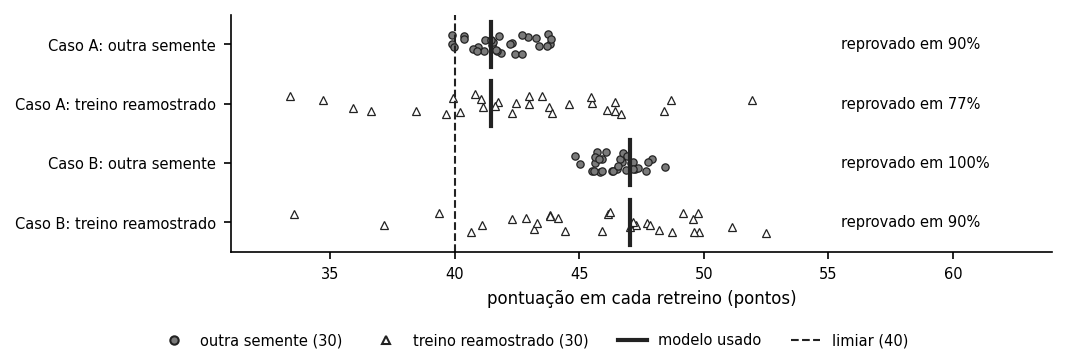

Legenda: cada ponto é um retreino do mesmo pipeline (30 com outra semente, círculos; 30 com treino reamostrado, triângulos vazados); à direita, a fração de retreinos que reprova o caso. A classe da decisão (estável, pouco estável, instável) usa a menor das duas frações (componente 6); instável leva o pedido à revisão humana antes da decisão (etapa [4] da Inferência).
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("posicoes_casos", "X_teste", "X_teste_num", "pipe_final", "prob_teste", "y_teste", "versao_modelo", "limiar", "regras_teste",
       "retreinos_semente", "retreinos_reamostra", "mantida_semente", "mantida_reamostra")

NUM_EXTENSO = {1: "uma", 2: "duas", 3: "três", 4: "quatro"}

def aplicar_procedimento(df_pedido):
    """Inferência de UM pedido, na ordem do sistema: regras -> modelo -> limiar -> verificação de estabilidade (só se o modelo reprovar).
    Devolve as etapas e o resultado; é a mesma função usada no Registro da decisão (componente 16)."""
    pessoa = df_pedido.iloc[0]
    dec_regras, motivos = decidir_por_regras(pessoa)
    etapas = dict(regras=dec_regras, motivos_regras=motivos, pontuacao=None, decisao_modelo=None, estabilidade=None, resultado=None, em_revisao_humana=False)
    if dec_regras == "reprovado":
        etapas["resultado"] = "reprovado por regra"
        return etapas
    p = float(pipe_final.predict_proba(df_pedido)[0, 1])
    etapas.update(pontuacao=p, decisao_modelo=aplicar_limiar(p))
    if etapas["decisao_modelo"] == "aprovado":
        etapas["resultado"] = "aprovado"
        return etapas
    est = verificar_estabilidade(df_pedido, np.array([True]))
    etapas["estabilidade"] = dict(mantida_semente=float(est["mantida_semente"][0]), mantida_reamostra=float(est["mantida_reamostra"][0]), classe=est["classe"][0])
    etapas["em_revisao_humana"] = est["classe"][0] == "instável"
    # em_revisao_humana = encaminhamento SIMULADO: a revisão não é executada e não se demonstra participação humana efetiva (hipótese D1)
    etapas["resultado"] = "encaminhado à revisão humana (simulado; reprovação indicada pelo modelo, instável)" if etapas["em_revisao_humana"] else "reprovado pelo modelo"
    return etapas

def frase_procedimento(c, nivel=0):
    """Forma ao titular (art. 20, § 1º, «procedimentos»): a ordem regras -> modelo -> limiar (-> estabilidade), em UMA frase. Valores lidos das constantes."""
    n_r = len(REGRAS_TEXTO)
    regras = f"Primeiro, {NUM_EXTENSO.get(n_r, str(n_r))} regras ({REGRAS_CURTO})" if nivel < 3 else f"Regras de {REGRAS_CURTO}"
    if c["decisao_regras"] != "aprovado":
        return f"{regras}; aqui, uma delas reprovou o pedido, e o modelo não foi usado."
    modelo = ("um modelo treinado com pedidos antigos calcula uma pontuação de risco, de 0 a 100," if nivel < 3 else "um modelo dá uma pontuação (0 a 100)")
    revisao = ("; se a reprovação muda entre novos treinos do modelo, o pedido é encaminhado a uma pessoa antes da decisão final" + (", como aqui" if c.get("em_revisao_humana") else "")
               if nivel < 3 else ("; reprovação instável é encaminhada a uma pessoa, como aqui" if c.get("em_revisao_humana") else "; reprovação instável é encaminhada a uma pessoa"))
    corte = f"e o pedido é reprovado com {br(LIMIAR_RISCO * 100, 0)} ou mais (corte hipotético)" if nivel < 3 else f"que reprova com {br(LIMIAR_RISCO * 100, 0)} ou mais"
    return f"{regras}; se nenhuma reprova, como aqui, {modelo} {corte}{revisao}."

with Secao("Componente 10 – Procedimento aplicado aos casos"):
    CASOS = {}
    for chave, pos in ESTADO.posicoes_casos.items():
        caso_df = X_teste.iloc[[pos]]
        etapas = aplicar_procedimento(caso_df)
        conferir(f"inferencia_{chave}_pontuacao_igual_lote", etapas["pontuacao"] is not None and abs(etapas["pontuacao"] - float(prob_teste[pos])) <= TOL_ADITIVIDADE,
                 "o procedimento e a predição em lote deveriam coincidir")
        conferir(f"inferencia_{chave}_estabilidade_igual_lote", etapas["estabilidade"] is not None
                 and abs(etapas["estabilidade"]["mantida_semente"] - mantida_semente[pos]) < 1e-12 and abs(etapas["estabilidade"]["mantida_reamostra"] - mantida_reamostra[pos]) < 1e-12)
        prob = etapas["pontuacao"]
        ps, pr = ESTADO.P_semente[:, pos], ESTADO.P_reamostra[:, pos]
        real = "não pagou" if int(y_teste.iloc[pos]) == 1 else "pagou"
        decisao = aplicar_limiar(prob)
        celula = {("reprovado", "pagou"): "FP (bom pagador reprovado)", ("reprovado", "não pagou"): "VP (inadimplente reprovado)",
                  ("aprovado", "não pagou"): "FN (inadimplente aprovado)", ("aprovado", "pagou"): "VN (bom pagador aprovado)"}.get((decisao, real), "")
        CASOS[chave] = dict(
            chave=chave, posicao=pos, indice_original=int(X_teste.index[pos]), caso_df=caso_df, x=X_teste_num[pos], prob=prob, etapas=etapas,
            decisao=decisao, decisao_regras=etapas["regras"], motivos_regras=etapas["motivos_regras"], em_revisao_humana=etapas["em_revisao_humana"],
            resultado=etapas["resultado"], rotulo_historico=real, celula_matriz=celula,
            entrada_bruta={col: valor_nativo(caso_df[col].iloc[0]) for col in caso_df.columns},
            estabilidade=dict(n_retreinos_semente=len(ps), n_retreinos_reamostra=len(pr),
                              fracao_reprovado_semente=float((ps >= LIMIAR_RISCO).mean()), fracao_reprovado_reamostra=float((pr >= LIMIAR_RISCO).mean()),
                              media_semente=float(ps.mean()), p2_5_semente=float(np.quantile(ps, .025)), p97_5_semente=float(np.quantile(ps, .975)),
                              media_reamostra=float(pr.mean()), p2_5_reamostra=float(np.quantile(pr, .025)), p97_5_reamostra=float(np.quantile(pr, .975)),
                              margem_ao_limiar=float(prob - LIMIAR_RISCO), classe=etapas["estabilidade"]["classe"]))
        conferir(f"decisao_coerente_{chave}", (decisao == "reprovado") == (prob >= LIMIAR_RISCO))
    ESTADO.casos = CASOS

    forma("E, N, A", "passos do procedimento em cada caso")
    for chave, c in CASOS.items():
        e = c["estabilidade"]
        print(f"\nCaso {chave} (índice original {c['indice_original']}; modelo {versao_modelo}):")
        print(f"  [1] regras de negócio: {c['decisao_regras']}" + (f" ({'; '.join(c['motivos_regras'])})" if c["motivos_regras"] else " (nenhuma acionada: segue para o modelo)"))
        print(f"  [2] modelo: pontuação {c['prob']!r} ({pts(c['prob'])})")
        print(f"  [3] limiar de {pts(LIMIAR_RISCO, 0)}: {c['decisao']} (margem {dpts(e['margem_ao_limiar'])})")
        print(f"  [4] verificação de estabilidade: {e['classe']} (pela menor das duas frações); outra semente ({e['n_retreinos_semente']}): reprovado em {pct(e['fracao_reprovado_semente'], 0)}, "
              f"95% das pontuações entre {pts(e['p2_5_semente'])} e {pts(e['p97_5_semente'])}; treino reamostrado ({e['n_retreinos_reamostra']}): reprovado em "
              f"{pct(e['fracao_reprovado_reamostra'], 0)}, 95% entre {pts(e['p2_5_reamostra'])} e {pts(e['p97_5_reamostra'])}")
        if c["prob"] > e["p97_5_semente"]:
            print(f"      O caso {chave} fica acima de 95% dos retreinos: casos escolhidos pela pontuação tendem a estar no extremo do intervalo (regressão à média).")
        print(f"  Resultado: {c['resultado'].upper()}" + (" (encaminhamento simulado: a revisão não é executada)" if c["em_revisao_humana"] else ""))
        print(f"  Na base histórica, o caso {c['rotulo_historico']}" + (f": é um {c['celula_matriz']}" if c["celula_matriz"] else "") + " (em produção isso não seria conhecido).")
    if all(str(c.get("celula_matriz", "")).startswith("FP") for c in CASOS.values()):
        print("\nO rótulo histórico não entra no critério de escolha (fixado antes, por quartil): todos os casos do estudo serem FP é coincidência, e informativa,"
              " pois é o tipo de caso em que a revisão importa.")

    forma("T", "uma frase com a ordem em que regras, modelo e limiar foram aplicados ao pedido")
    for chave, c in CASOS.items():
        print(f"Caso {chave}: «{frase_procedimento(c)}»")

    # Figura: a verificação de estabilidade de cada caso (forma para E e A)
    fig, ax = nova_figura(LARG_2COL, 2.3)
    rng_fig = gerador("dispersao_vertical_figura_2")       # só desloca os pontos na vertical para não se sobreporem (mesma semente das versões anteriores)
    linhas_fig, todos = [], []
    n_s, n_r = PARAMETROS["n_retreinos_semente"], PARAMETROS["n_retreinos_reamostra"]
    for chave, c in CASOS.items():
        pos, e = c["posicao"], c["estabilidade"]
        for rotulo_r, P_, frac, marcador in (("outra semente", ESTADO.P_semente, e["fracao_reprovado_semente"], "o"),
                                             ("treino reamostrado", ESTADO.P_reamostra, e["fracao_reprovado_reamostra"], "^")):
            linhas_fig.append((f"Caso {chave}: {rotulo_r}", P_[:, pos] * 100, frac, marcador, c["prob"] * 100))
            todos.extend(P_[:, pos] * 100)
    lo_f, hi_f = np.floor(min(min(todos), LIMIAR_RISCO * 100) - 2), np.ceil(max(todos) + 2)
    for i, (rot, valores, frac, marcador, prob) in enumerate(linhas_fig):
        ax.plot(valores, i + rng_fig.uniform(-0.18, 0.18, len(valores)), marcador, markersize=3.5, markerfacecolor="white" if marcador == "^" else COR_NEUTRA,
                markeredgecolor=COR_ESCURA, markeredgewidth=0.6, linestyle="none")
        ax.plot([prob, prob], [i - 0.38, i + 0.38], color=COR_ESCURA, linewidth=2.0)
        ax.text(hi_f + 0.5, i, f"reprovado em {pct(frac, 0)}", va="center", ha="left", fontsize=7)
    ax.axvline(LIMIAR_RISCO * 100, color=COR_ESCURA, linestyle="--", linewidth=1.0)
    ax.set_yticks(range(len(linhas_fig)), [l[0] for l in linhas_fig])
    ax.set_ylim(len(linhas_fig) - 0.5, -0.5)
    ax.set_xlim(lo_f, hi_f + 9)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel("pontuação em cada retreino (pontos)")
    from matplotlib.lines import Line2D
    fig.legend([Line2D([], [], marker="o", linestyle="none", markerfacecolor=COR_NEUTRA, markeredgecolor=COR_ESCURA, markersize=4),
                Line2D([], [], marker="^", linestyle="none", markerfacecolor="white", markeredgecolor=COR_ESCURA, markersize=4),
                Line2D([], [], color=COR_ESCURA, linewidth=2.0), Line2D([], [], color=COR_ESCURA, linestyle="--", linewidth=1.0)],
               [f"outra semente ({n_s})", f"treino reamostrado ({n_r})", "modelo usado", f"limiar ({br(LIMIAR_RISCO * 100, 0)})"],
               loc="outside lower center", ncol=4, frameon=False)
    classes = "; ".join(f"{k}: {c['estabilidade']['classe']}" for k, c in CASOS.items())
    titulo_estab = f"Estabilidade da decisão nos retreinos ({classes})"
    figura(3, "estabilidade_da_decisao", fig, titulo_estab,
           f"Legenda: cada ponto é um retreino do mesmo pipeline ({n_s} com outra semente, círculos; {n_r} com treino reamostrado, triângulos vazados); "
           "à direita, a fração de retreinos que reprova o caso. A classe da decisão (estável, pouco estável, instável) usa a menor das duas frações (componente 6); "
           "instável leva o pedido à revisão humana antes da decisão (etapa [4] da Inferência).",
           "E, A")

#### Complementar: abrindo a caixa-preta (forma técnica para E e A)

> **Complementar** (leitura opcional; o essencial cabe em 1 frase: a pontuação é a média das árvores, conferida com o modelo; ao titular vai só a frase do procedimento). Descreve o funcionamento interno do Modelo treinado (componente 9) aplicado a cada caso.

Em vez de olhar só o resultado, abre-se o modelo e acompanha-se **cada caso escolhido**. O *Random Forest* é um **conjunto de árvores de decisão** [Breiman 2001]: cada árvore faz perguntas sim/não sobre os dados da pessoa até uma **folha**, que traz uma estimativa de risco (a proporção de inadimplentes na amostra de treino sorteada para aquela árvore). A pontuação é a **média** das estimativas das árvores. **A decisão é tomada pela média, não pela contagem de árvores acima do limiar** (Figura NBC1, complementar); as estimativas individuais variam muito entre árvores (os valores mínimo e máximo são impressos abaixo).

O código **recomputa** a pontuação como a média das estimativas e **confere** com a do `Pipeline`; confere também que o caminho de cada árvore tem tantas perguntas quanto a profundidade da folha e termina na folha de `apply()`; e mostra o caminho da árvore cuja estimativa é a mais próxima da mediana.


>>> Forma para equipe de desenvolvimento e auditor (E, A): o caminho do caso nas árvores e a média que forma a pontuação

Caso A (índice original 889): pontuação 41,45 pontos = média das 200 árvores
  estimativas das árvores: mínimo 10 pontos, mediana 40 pontos, máximo 83 pontos; 95% delas entre 14 pontos e 74 pontos
  árvore de exemplo nº 65 (estimativa mais próxima da mediana): 4 perguntas; folha com 84 casos distintos da amostra sorteada e estimativa 39,6 pontos
    - Idade é maior que 25,5? sim
    - Prazo do financiamento (meses) é maior que 16,5? sim
    - Prazo do financiamento (meses) é maior que 27,5? não
    - Situação da conta corrente é «saldo de 200 DM ou mais, ou salário há 1 ano ou mais»? não

Caso B (índice original 23): pontuação 47,02 pontos = média das 200 árvores
  estimativas das árvores: mínimo 11 pontos, mediana 45 pontos, máximo 100 pontos; 95% delas entre 16 pontos e 83 pontos
  árvore de exemplo nº 46 (estimativa mais próxima da mediana): 4 perguntas; folha c

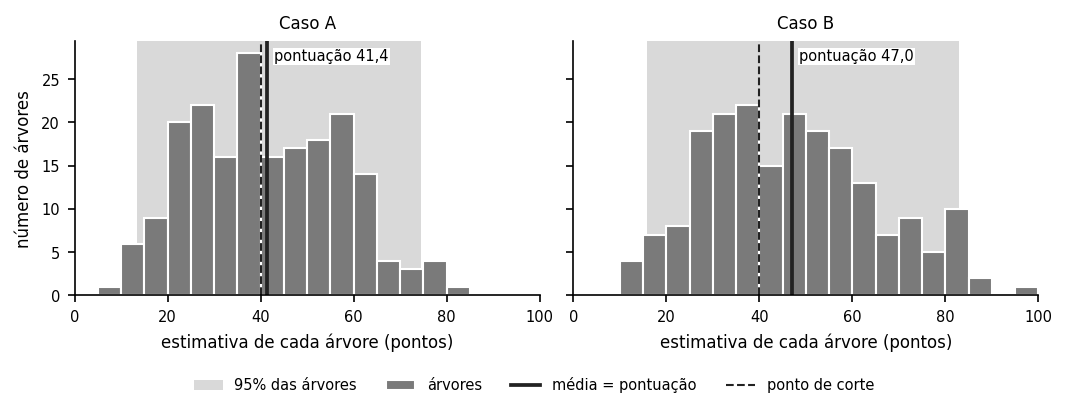

Legenda: histograma das estimativas das árvores de cada caso; faixa cinza clara = 95% das árvores. A decisão é tomada pela média, não pela contagem de árvores acima do corte.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("casos", "posicoes_casos", "X_teste", "X_teste_num", "modelo", "pipe_final", "prob_teste", "nomes_features", "mapa_variavel")

with Secao("Componente 10 – Caixa-preta (complementar)"):
    CASOS = ESTADO.casos
    forma("E, A", "o caminho do caso nas árvores e a média que forma a pontuação")
    for chave, pos in ESTADO.posicoes_casos.items():
        caso_df = X_teste.iloc[[pos]]
        x = X_teste_num[pos]
        xs = vetor_float32(x)
        prob = float(pipe_final.predict_proba(caso_df)[0, 1])
        conferir(f"prob_{chave}_pipeline_igual_lote", abs(prob - float(prob_teste[pos])) <= TOL_ADITIVIDADE, "o pipeline e a predição em lote deveriam coincidir")

        probs_arvores, folhas = [], []
        for arvore in modelo.estimators_:
            probs_arvores.append(float(arvore.predict_proba(xs)[0][1]))
            folhas.append(int(arvore.apply(xs)[0]))
        probs_arvores = np.array(probs_arvores)
        media_arvores = float(probs_arvores.mean())
        conferir(f"media_arvores_{chave}", abs(media_arvores - prob) <= 1e-9, f"média {media_arvores!r} x pontuação {prob!r}")

        profundidades_caminho = []
        for i_arv, arvore in enumerate(modelo.estimators_):
            passos, folha = passos_do_caminho(arvore, x)
            assert len(passos) == arvore.decision_path(xs).indices.size - 1 == folha["profundidade"] and folha["no"] == folhas[i_arv], f"caminho incompleto na árvore {i_arv} (caso {chave})"
            profundidades_caminho.append(len(passos))
        conferir(f"caminhos_completos_{chave}", len(profundidades_caminho) == modelo.n_estimators)

        mediana = float(np.median(probs_arvores))     # árvore de exemplo: a de estimativa mais próxima da mediana (desempate: menor índice)
        i_exemplo = int(sorted(range(len(probs_arvores)), key=lambda i: (abs(probs_arvores[i] - mediana), i))[0])
        passos_ex, folha_ex = passos_do_caminho(modelo.estimators_[i_exemplo], x)
        CASOS[chave].update(
            probs_arvores=probs_arvores,
            mediana=mediana, minimo=float(probs_arvores.min()), maximo=float(probs_arvores.max()),
            p2_5=float(np.quantile(probs_arvores, 0.025)), p97_5=float(np.quantile(probs_arvores, 0.975)),
            arvore_exemplo=dict(indice=i_exemplo, perguntas=[descrever_passo(p, nomes_features) for p in passos_ex], folha=folha_ex))
        c = CASOS[chave]
        print(f"\nCaso {chave} (índice original {c['indice_original']}): pontuação {pts(prob, 2)} = média das {len(probs_arvores)} árvores")
        print(f"  estimativas das árvores: mínimo {pts(c['minimo'], 0)}, mediana {pts(mediana, 0)}, máximo {pts(c['maximo'], 0)}; 95% delas entre {pts(c['p2_5'], 0)} e {pts(c['p97_5'], 0)}")
        print(f"  árvore de exemplo nº {i_exemplo} (estimativa mais próxima da mediana): {len(passos_ex)} perguntas; folha com {folha_ex['n_amostras']} casos distintos da amostra sorteada e estimativa {pts(folha_ex['estimativa'])}")
        for linha in c["arvore_exemplo"]["perguntas"]:
            print("    -", linha)

    fig, eixos = nova_figura(LARG_2COL, 2.6, 1, len(CASOS), sharey=True)
    for ax, (chave, c) in zip(np.atleast_1d(eixos), CASOS.items()):
        ax.axvspan(c["p2_5"] * 100, c["p97_5"] * 100, facecolor=COR_CLARA, edgecolor="none", zorder=0, label="95% das árvores")
        ax.hist(c["probs_arvores"] * 100, bins=np.linspace(0, 100, 21), color=COR_NEUTRA, edgecolor="white", zorder=1, label="árvores")
        ax.axvline(c["prob"] * 100, color=COR_ESCURA, linewidth=1.8, zorder=2, label="média = pontuação")
        ax.axvline(LIMIAR_RISCO * 100, color=COR_ESCURA, linestyle="--", linewidth=1.0, zorder=2, label="ponto de corte")
        ax.text(c["prob"] * 100 + 1.5, 0.97, f"pontuação {br(c['prob'] * 100)}", transform=ax.get_xaxis_transform(), va="top", fontsize=7,
                bbox=dict(fc="white", ec="none", pad=0.5))
        ax.set_title(f"Caso {chave}")
        ax.set_xlabel("estimativa de cada árvore (pontos)")
        ax.set_xlim(0, 100)
    np.atleast_1d(eixos)[0].set_ylabel("número de árvores")
    _h, _l = np.atleast_1d(eixos)[0].get_legend_handles_labels()
    fig.legend(_h, _l, loc="outside lower center", ncol=4, frameon=False)
    figura("C1", "estimativas_das_arvores", fig, "Estimativas das árvores e sua média, por caso",
           "Legenda: histograma das estimativas das árvores de cada caso; faixa cinza clara = 95% das árvores. A decisão é tomada pela média, "
           "não pela contagem de árvores acima do corte.", "E, A", destino="complementar")

### Componente 11 — Dados individuais do titular

**O que é.** As informações da pessoa usadas na decisão (não confundir com a base, que é o passado de muitas pessoas). A LGPD garante ao titular o acesso a esses dados e a correção dos que estiverem incompletos, inexatos ou desatualizados [Brasil 2018, art. 18, II e III]. Quando o titular requer a declaração clara e completa, ela indica também a origem dos dados e os critérios utilizados [Brasil 2018, art. 19, II]; estes, na leitura da Seção 3.1 do TCC, são os de Regras de negócio, Limiar de decisão e Fatores da decisão.

**Classe, público e LGPD.** **Obrigatório** (dado pessoal do titular) · T · art. 18, II e III; origem dos dados: art. 19, II. É devido mediante requerimento expresso [Brasil 2018, art. 18, § 3º], mesmo quando o art. 20 não incide.

**Neste notebook.** A forma ao titular é a **tabela campo | valor | unidade | uso | origem**, com todos os campos do cadastro e a marca das vedadas («no cadastro, não usada»), gerada pelo dicionário de dados (`ROTULOS_PT` e `UNIDADES`). Como a linha é histórica, não há origem documental nem data de coleta que o titular possa contestar: a coluna «origem» registra isso, e num uso real traria a fonte e a data de cada campo. O relatório ao titular (componente 15) cita a tabela e a anexa.

In [ ]:
exigir("casos", "X_completo")

ORIGEM_DADOS = "informado no pedido (aqui: linha histórica da base pública, sem fonte nem data de coleta)"

def tabela_dados_individuais(caso_df, vedadas):
    """Componente 11: os dados do titular em linguagem legível (campo, valor com unidade, unidade, uso, origem), na ordem do cadastro."""
    pessoa = caso_df.iloc[0]
    return pd.DataFrame([{"campo": ROTULOS_PT[col], "valor": valor_com_unidade(col, pessoa[col], curto=True), "unidade ou escala": UNIDADES.get(col, "categoria"),
                          "uso": "no cadastro, não usada (vedada)" if col in vedadas else "usada pelas regras e pelo modelo" if col in ("duration", "credit_amount") else "usada pelo modelo",
                          "origem": ORIGEM_DADOS} for col in caso_df.columns])

with Secao("Componente 11 – Dados individuais do titular"):
    for chave, c in ESTADO.casos.items():
        c["dados_individuais"] = tabela_dados_individuais(X_completo.loc[[c["indice_original"]]], VARIAVEIS_VEDADAS)
    chave_ex = next(iter(ESTADO.casos))
    forma("T", f"tabela dos dados do caso {chave_ex}, como o titular os veria para pedir acesso ou correção (art. 18, II e III)")
    print(f"Caso {chave_ex} (linha {ESTADO.casos[chave_ex]['indice_original']} da base); a origem de todos os campos é: {ORIGEM_DADOS}.")
    display(ESTADO.casos[chave_ex]["dados_individuais"].drop(columns="origem").head(5))
    print("Cinco primeiros campos; a tabela completa, com os 20 campos, está no anexo do relatório ao titular (componente 15).")
    d = ESTADO.casos[chave_ex]["dados_individuais"]
    print(f"{len(d)} campos: {int((d['uso'] == 'usada pelo modelo').sum()) + int(d['uso'].str.startswith('usada pelas regras').sum())} usados na decisão "
          f"e {int(d['uso'].str.startswith('no cadastro').sum())} guardados no cadastro sem uso (vedados).")


>>> Forma para titular (T): tabela dos dados do caso A, como o titular os veria para pedir acesso ou correção (art. 18, II e III)
Caso A (linha 889 da base); a origem de todos os campos é: informado no pedido (aqui: linha histórica da base pública, sem fonte nem data de coleta).


,campo,valor,unidade ou escala,uso
0,Situação da conta corrente,sem conta corrente,"categoria (faixas de saldo, DM; inclui «sem conta corrente»)",usada pelo modelo
1,Prazo do financiamento (meses),24 meses,meses,usada pelas regras e pelo modelo
2,Histórico de crédito,sem créditos ou todos pagos em dia,categoria,usada pelo modelo
3,Finalidade do crédito,móveis ou equipamentos,categoria,usada pelo modelo
4,Valor solicitado,2.439 DM,marcos alemães (DM),usada pelas regras e pelo modelo


Cinco primeiros campos; a tabela completa, com os 20 campos, está no anexo do relatório ao titular (componente 15).
20 campos: 18 usados na decisão e 2 guardados no cadastro sem uso (vedados).


### Componente 12 — Fatores da decisão

**O que é.** As variáveis que mais pesaram na decisão do caso, entendidas no TCC como os «critérios» aplicados a ela [Brasil 2018, art. 20, § 1º]. Na forma técnica, para a equipe, a área de negócio e o auditor, técnicas como o SHAP [Lundberg e Lee 2017] e o LIME [Ribeiro et al. 2016] mostram a contribuição de cada variável; como a avaliação das explicações é um eixo próprio da explicabilidade [Ali et al. 2023], a qualidade dessa explicação deve ser medida antes do uso. Na forma em linguagem simples, para o titular, a explicação deve ser seletiva, com poucas causas, e contrastiva, dizendo por que este resultado e não outro [Miller 2019]. Os fatores resumem os critérios, e não reproduzem as regras internas do modelo.

**Classe, público e LGPD.** **Obrigatório** (critério ou procedimento aplicado ao caso) · T (linguagem simples); E, N, A (técnica) · art. 20, § 1º («critérios»); art. 19, II («critérios utilizados»). As informações do § 1º são devidas sempre que solicitadas e observam os segredos comercial e industrial [Brasil 2018, art. 20, § 1º].

**Neste notebook.** Primeiro a **forma técnica** (E, N, A): SHAP por caso e global, LIME no mesmo caso, comparação entre as duas e avaliação funcional das explicações. Depois a **forma em linguagem simples** (T): até 5 fatores, com a conta que fecha na pontuação. **Associação não é causa** [Janzing et al. 2020]: «prazo longo está associado a mais risco» não prova que o prazo cause inadimplência.

#### Forma técnica (E, N, A)

| | SHAP (TreeSHAP, `tree_path_dependent`) | LIME (configuração deste notebook) |
| --- | --- | --- |
| **O que precisa** | Acesso às árvores do modelo | Só a função de previsão e estatísticas do treino |
| **Saída** | Contribuição de cada variável, em pontos de pontuação; a soma fecha na pontuação | Pesos de um modelo linear local, uma condição por variável, com R² local |
| **Alcance** | Local e global | Local |
| **Pontos fracos** | Depende do valor de referência e da correlação entre variáveis | Vizinhança sintética, sorteio e discretização: estabilidade medida abaixo |

O SHAP vem dos valores de Shapley e, para árvores, usa o TreeSHAP [Lundberg et al. 2020]. Métodos diferentes que explicam o mesmo modelo frequentemente discordam, e não há regra consensual para escolher entre eles [Krishna et al. 2024]. As duas ferramentas são aplicadas ao **mesmo caso**, no nível da **variável original**. Concordância entre elas **não prova fidelidade** (ambas aproximam o mesmo modelo).

##### SHAP por caso

Em cada caso: o **ponto de partida** é o valor base; barras **laranja** empurram a pontuação para cima e **azuis** para baixo; a soma **fecha** na pontuação, dentro da tolerância declarada. A tabela separa a contribuição da **própria categoria** da de **não estar nas demais** (colunas 0/1), e traz a **taxa observada de inadimplência** no treino da categoria ou, para números, da **faixa (quartil)** em que o valor cai, para que fatores contraintuitivos tenham explicação baseada em dados. A tabela e as Figuras NB4a e NB4b mostram os 5 fatores que vão ao titular, com os mesmos números; as demais variáveis entram na soma «outras».

In [ ]:
exigir("shap_teste", "valor_base", "casos", "X_treino", "y_treino", "variaveis_orig", "cols_da_variavel", "categorias")

# Categorias que juntam «não tem» e «não se sabe» (codetable.txt: «unknown/no savings account», «unknown / no property»). «Sem conta corrente» é um estado
# definido («no checking account»), não falta de informação, e não entra aqui.
SEM_INFORMACAO = {("savings_status", "no known savings"), ("property_magnitude", "no known property")}
NOTA_SEM_INFORMACAO = ("Na base, esta categoria junta quem não tem o item e quem não o informou (codificação da base), não necessariamente uma situação "
                       "ruim ou boa em si; o modelo aprendeu a taxa observada de inadimplência associada a ela.")

# Categorias cujo nome sugere um sentido de risco («menos» ou «mais»); a nota só é emitida se a taxa observada no treino contrariar esse sentido.
# Nesta base, imóvel e moradia própria têm inadimplência observada ACIMA da taxa geral (rótulos corrigidos da base: Grömping [2019]).
CONTRAINTUITIVAS = {("property_magnitude", "real estate"): "menos", ("housing", "own"): "menos"}

def sentido_contraintuitivo(var, valor):
    """«favorável» se a taxa observada fica abaixo da geral, «desfavorável» se acima; None se não contraria o sentido declarado."""
    t = taxas_por_categoria(var)
    linha = t[t["categoria"] == str(valor)]
    esperado = CONTRAINTUITIVAS.get((var, str(valor)))
    if linha.empty or esperado is None:
        return None
    abaixo = float(linha["taxa"].iloc[0]) < float(y_treino.mean())
    if abaixo == (esperado == "menos"):
        return None
    return "favorável" if abaixo else "desfavorável"

def nota_contraintuitiva(var, valor):
    """Nota calculada: taxa observada da categoria no treino comparada com a taxa geral do treino ("" se a taxa não contraria o nome)."""
    sentido = sentido_contraintuitivo(var, valor)
    if sentido is None:
        return ""
    t = taxas_por_categoria(var)
    linha = t[t["categoria"] == str(valor)]
    taxa, n, geral = float(linha["taxa"].iloc[0]), int(linha["n"].iloc[0]), float(y_treino.mean())
    relacao = "abaixo" if taxa < geral else "acima"
    return (f"No treino, «{valor_legivel(var, valor)}» tem inadimplência observada de {pct(taxa, 0)} ({n} casos), {relacao} da taxa geral de {pct(geral, 0)}; "
            f"o modelo aprendeu essa associação da base. Ela não indica que essa situação seja {sentido} nem qual valor seria o correto.")

def taxas_por_categoria(var):
    """Taxa observada de inadimplência por categoria, no histórico de TREINO."""
    tab = pd.DataFrame({"categoria": X_treino[var].astype(str).values, "y": y_treino.values}).groupby("categoria")["y"].agg(["size", "mean"])
    return tab.rename(columns={"size": "n", "mean": "taxa"}).reset_index()

def faixa_numerica(var, valor):
    """Faixa (por quartis do TREINO) em que o valor está, com n e taxa observada de inadimplência."""
    v = X_treino[var].astype(float)
    bordas = np.unique(np.quantile(v, [0, .25, .5, .75, 1]))
    if len(bordas) < 3:
        return None
    i = int(np.clip(np.searchsorted(bordas, float(valor), side="right") - 1, 0, len(bordas) - 2))
    lo, hi = bordas[i], bordas[i + 1]
    m = (v >= lo) & ((v < hi) if i < len(bordas) - 2 else (v <= hi))
    return dict(faixa=f"{num_br(lo)} a {num_br(hi)}", n=int(m.sum()), taxa=float(y_treino[m.values].mean()) if m.sum() else float("nan"))

def tabela_fatores(c):
    """Uma linha por variável: contribuição da variável, da própria categoria, das demais, e taxa observada."""
    phi, x = c["shap"]["phi"], c["x"]
    linhas = []
    for var in variaveis_orig:
        cols = cols_da_variavel[var]
        valor = c["caso_df"][var].iloc[0]
        linha = dict(variavel=var, rotulo=ROTULOS_PT[var], valor=valor_com_unidade(var, valor), phi_variavel=float(phi[cols].sum()),
                     phi_propria_categoria=np.nan, phi_demais_categorias=np.nan, n_categoria=np.nan, taxa_categoria=np.nan, faixa="", nota="", tipo_nota="",
                     peso_de_fora="", taxa_peso_de_fora=np.nan)
        if var in categorias:
            propria = [j for j in cols if x[j] == 1]
            assert len(propria) == 1, f"a variável {var} deveria ter exatamente uma categoria ativa"
            linha["phi_propria_categoria"] = float(phi[propria[0]])
            linha["phi_demais_categorias"] = float(phi[[j for j in cols if j != propria[0]]].sum())
            t = taxas_por_categoria(var)
            r = t[t["categoria"] == str(valor)].iloc[0]
            linha.update(n_categoria=int(r["n"]), taxa_categoria=float(r["taxa"]), faixa=valor_legivel(var, valor))
            # Peso que vem de NÃO estar em outra categoria: mais da metade da contribuição, no mesmo sentido, e a categoria da pessoa
            # não se distingue da taxa geral (IC95% de Wilson contém a taxa geral). Sem isso, «pago em dia, +1,6 pontos» parece contraditório.
            k_cat = int(round(float(r["taxa"]) * int(r["n"])))
            ic_cat, geral = wilson(k_cat, int(r["n"])), float(y_treino.mean())
            if (np.sign(linha["phi_demais_categorias"]) == np.sign(linha["phi_variavel"]) != 0
                    and abs(linha["phi_demais_categorias"]) > abs(linha["phi_variavel"]) / 2 and ic_cat[0] <= geral <= ic_cat[1]):
                demais = [(j, cat) for j, cat in zip(cols, categorias[var]) if j != propria[0]]
                j_max, cat_max = max(demais, key=lambda jc: np.sign(linha["phi_variavel"]) * phi[jc[0]])
                taxa_max = t[t["categoria"] == cat_max]
                if not taxa_max.empty:
                    linha.update(peso_de_fora=cat_max, taxa_peso_de_fora=float(taxa_max["taxa"].iloc[0]))
            if (var, str(valor)) in SEM_INFORMACAO:
                linha.update(nota=NOTA_SEM_INFORMACAO, tipo_nota="sem_informacao")
            elif (var, str(valor)) in CONTRAINTUITIVAS:
                linha.update(nota=nota_contraintuitiva(var, valor), tipo_nota="contraintuitiva" if nota_contraintuitiva(var, valor) else "")
        else:
            linha["phi_propria_categoria"] = linha["phi_variavel"]
            f = faixa_numerica(var, valor)
            if f:
                linha.update(n_categoria=f["n"], taxa_categoria=f["taxa"], faixa=f["faixa"])
        linhas.append(linha)
    return pd.DataFrame(linhas).assign(abs_phi=lambda d: d["phi_variavel"].abs()).sort_values("abs_phi", ascending=False).reset_index(drop=True)

N_FATORES_RELATORIO = 5     # escolha de projeto, sem fonte

def decimos(x):
    """Pontuação (escala 0-1) em DÉCIMOS de ponto, inteiro: é o que se exibe com 1 casa."""
    return int(round(float(x) * 1000))

def txt_decimos(t, sinal=False):
    """Décimos de ponto -> texto com 1 casa e vírgula (com sinal, se pedido; zero vira «+0,0»)."""
    return (f"{t / 10:+.1f}" if sinal else f"{t / 10:.1f}").replace(".", ",")

def conta_exibida(valor_base_, phis_top, prob):
    """Conta que FECHA no que o leitor vê: parcelas arredondadas a 1 casa; «outras» = resíduo (pontuação exibida − ponto de partida exibido − soma das parcelas exibidas)."""
    b, p_ = decimos(valor_base_), decimos(prob)
    fs = [decimos(v) for v in phis_top]
    return dict(base=b, fatores=fs, top=sum(fs), outros=p_ - b - sum(fs), pontuacao=p_)

with Secao("Componente 12 – SHAP por caso"):
    forma("E, N, A", "contribuições SHAP dos 5 fatores principais, com a conta que fecha")
    for chave, c in ESTADO.casos.items():
        phi = shap_teste[c["posicao"]]
        c["shap"] = dict(valor_base=valor_base, phi=phi, erro_aditividade=float(valor_base + phi.sum() - c["prob"]))
        conferir(f"shap_soma_{chave}", abs(c["shap"]["erro_aditividade"]) <= TOL_ADITIVIDADE, f"erro {c['shap']['erro_aditividade']:.3e}")
        tab = tabela_fatores(c)
        conferir(f"soma_por_variavel_{chave}", abs(tab["phi_variavel"].sum() - phi.sum()) <= 1e-9)
        top, outros = tab.head(N_FATORES_RELATORIO), tab.iloc[N_FATORES_RELATORIO:]
        c["fatores"] = dict(tabela=tab, top=top, outros_soma=float(outros["phi_variavel"].sum()), outros_n=int(len(outros)))
        fecha = valor_base + top["phi_variavel"].sum() + c["fatores"]["outros_soma"]
        conferir(f"relatorio_fecha_{chave}", abs(fecha - c["prob"]) <= TOL_ADITIVIDADE, f"{fecha!r} x {c['prob']!r}")
        ce = conta_exibida(valor_base, top["phi_variavel"].tolist(), c["prob"])
        conferir(f"conta_exibida_fecha_{chave}", ce["base"] + sum(ce["fatores"]) + ce["outros"] == ce["pontuacao"])
        conferir(f"conta_exibida_residuo_proximo_{chave}", abs(ce["outros"] - c["fatores"]["outros_soma"] * 1000) <= 0.5 * (len(ce["fatores"]) + 2) + 1e-9,
                 "o resíduo de arredondamento deveria ser no máximo meio décimo por parcela")
        c["fatores"]["conta_exibida"] = ce
        print(f"\n===== Caso {chave} (índice original {c['indice_original']}) =====")
        print(f"Ponto de partida {txt_decimos(ce['base'])} {txt_decimos(ce['top'], True)} ({len(top)} principais, as que vão ao relatório e à tabela) "
              f"{txt_decimos(ce['outros'], True)} (outras {len(outros)} variáveis, somadas; inclui o arredondamento da exibição) = {txt_decimos(ce['pontuacao'])} pontos | pontuação do modelo {pts(c['prob'], 2)}")
        mostrar = top[["rotulo", "valor", "phi_variavel", "phi_propria_categoria", "phi_demais_categorias", "faixa", "n_categoria", "taxa_categoria"]].copy()
        for col in ("phi_variavel", "phi_propria_categoria", "phi_demais_categorias"):      # 1 casa, como no relatório e na Figura NB4: as parcelas somam o «+N» da conta
            mostrar[col] = [decimos(v) / 10 if pd.notna(v) else np.nan for v in mostrar[col]]
        mostrar["taxa_categoria"] = (mostrar["taxa_categoria"] * 100).round(0)
        mostrar.columns = ["variável", "valor da pessoa", "contribuição (pontos)", "da própria categoria", "das demais categorias",
                           "categoria ou faixa (quartil) no treino", "n na categoria ou faixa", "inadimplência observada na categoria ou faixa (%)"]
        conferir(f"tabela_shap_soma_igual_conta_{chave}", sum(decimos(v) for v in top["phi_variavel"]) == ce["top"], "a tabela e a conta devem usar o mesmo arredondamento")
        display(mostrar)
        for _, l in top[top["nota"] != ""].iterrows():
            print(f"  NOTA — {l['rotulo']} = {l['valor']}: {l['nota']}")
        for _, l in top[top["peso_de_fora"] != ""].iterrows():
            print(f"  NOTA — {l['rotulo']} = {l['valor']}: {br(abs(l['phi_demais_categorias']) / abs(l['phi_variavel']) * 100, 0)}% do peso vem de NÃO estar em "
                  f"«{valor_legivel(l['variavel'], l['peso_de_fora'])}» (inadimplência observada {pct(l['taxa_peso_de_fora'], 0)}); a categoria da pessoa tem "
                  f"{pct(l['taxa_categoria'], 0)}, que não se distingue da taxa geral de {pct(y_treino.mean(), 0)} (IC95%). A forma ao titular diz isso.")


>>> Forma para equipe de desenvolvimento, área de negócio e auditor (E, N, A): contribuições SHAP dos 5 fatores principais, com a conta que fecha

===== Caso A (índice original 889) =====
Ponto de partida 30,1 +11,3 (5 principais, as que vão ao relatório e à tabela) +0,0 (outras 13 variáveis, somadas; inclui o arredondamento da exibição) = 41,4 pontos | pontuação do modelo 41,45 pontos


,variável,valor da pessoa,contribuição (pontos),da própria categoria,das demais categorias,categoria ou faixa (quartil) no treino,n na categoria ou faixa,inadimplência observada na categoria ou faixa (%)
0,Situação da conta corrente,sem conta corrente,10.5,6.4,4.1,sem conta corrente,214,52.0
1,Poupança / reservas,sem poupança ou desconhecida,2.5,1.7,0.8,sem poupança ou desconhecida,468,37.0
2,Moradia,alugada,-1.6,-1.2,-0.5,alugada,566,25.0
3,Patrimônio (bens),sem bens ou desconhecidos,-1.3,-1.0,-0.3,sem bens ou desconhecidos,226,20.0
4,Histórico de crédito,sem créditos ou todos pagos em dia,1.2,0.1,1.1,sem créditos ou todos pagos em dia,423,33.0


  NOTA — Poupança / reservas = sem poupança ou desconhecida: Na base, esta categoria junta quem não tem o item e quem não o informou (codificação da base), não necessariamente uma situação ruim ou boa em si; o modelo aprendeu a taxa observada de inadimplência associada a ela.
  NOTA — Patrimônio (bens) = sem bens ou desconhecidos: Na base, esta categoria junta quem não tem o item e quem não o informou (codificação da base), não necessariamente uma situação ruim ou boa em si; o modelo aprendeu a taxa observada de inadimplência associada a ela.
  NOTA — Histórico de crédito = sem créditos ou todos pagos em dia: 91% do peso vem de NÃO estar em «todos os créditos neste banco pagos em dia» (inadimplência observada 17%); a categoria da pessoa tem 33%, que não se distingue da taxa geral de 30% (IC95%). A forma ao titular diz isso.

===== Caso B (índice original 23) =====
Ponto de partida 30,1 +15,5 (5 principais, as que vão ao relatório e à tabela) +1,4 (outras 13 variáveis, somadas; inclui o

,variável,valor da pessoa,contribuição (pontos),da própria categoria,das demais categorias,categoria ou faixa (quartil) no treino,n na categoria ou faixa,inadimplência observada na categoria ou faixa (%)
0,Moradia,cedida,4.5,1.8,2.7,cedida,153,42.0
1,Situação da conta corrente,saldo negativo,3.7,1.4,2.3,saldo negativo,210,39.0
2,Prazo do financiamento (meses),36 meses,3.6,3.6,NaN,24 a 72,334,37.0
3,Poupança / reservas,sem poupança ou desconhecida,2.3,1.4,0.9,sem poupança ou desconhecida,468,37.0
4,Patrimônio (bens),imóvel,1.4,1.2,0.2,imóvel,122,43.0


  NOTA — Poupança / reservas = sem poupança ou desconhecida: Na base, esta categoria junta quem não tem o item e quem não o informou (codificação da base), não necessariamente uma situação ruim ou boa em si; o modelo aprendeu a taxa observada de inadimplência associada a ela.
  NOTA — Patrimônio (bens) = imóvel: No treino, «imóvel» tem inadimplência observada de 43% (122 casos), acima da taxa geral de 30%; o modelo aprendeu essa associação da base. Ela não indica que essa situação seja desfavorável nem qual valor seria o correto.


Figura NB4a – Caso A: contribuição de cada fator para a pontuação (SHAP)


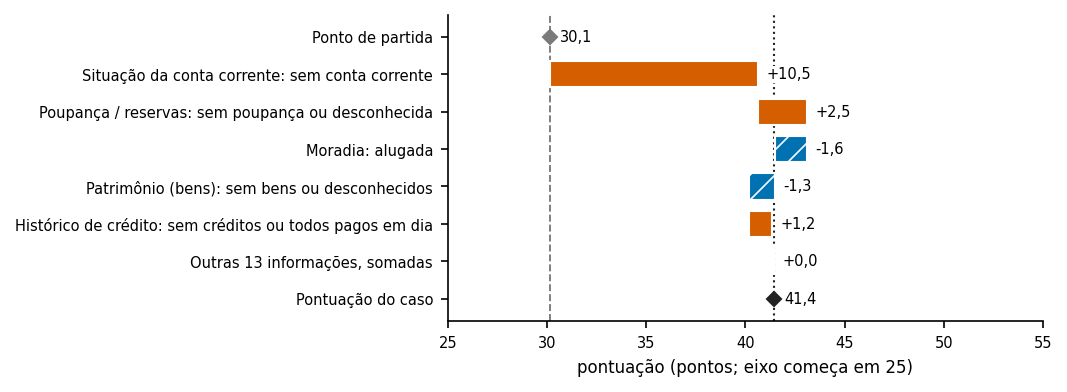

Legenda: do ponto de partida (losango cinza, média do modelo no treino) à pontuação do caso (losango preto), cada barra soma a contribuição de uma informação, em pontos; laranja e lisa = aumenta o risco; azul e hachurada = reduz. São os 5 fatores e a linha «outras» da forma ao titular, com os mesmos números. O eixo é truncado e é o mesmo nos dois casos. Descreve o modelo, não causas.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.
Figura NB4b – Caso B: contribuição de cada fator para a pontuação (SHAP)


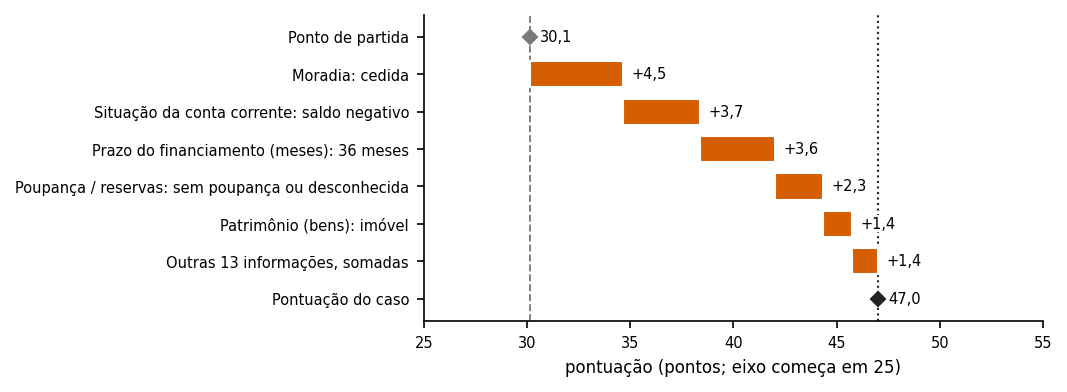

Legenda: do ponto de partida (losango cinza, média do modelo no treino) à pontuação do caso (losango preto), cada barra soma a contribuição de uma informação, em pontos; laranja e lisa = aumenta o risco; azul e hachurada = reduz. São os 5 fatores e a linha «outras» da forma ao titular, com os mesmos números. O eixo é truncado e é o mesmo nos dois casos. Descreve o modelo, não causas.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("casos", "shap_teste", "valor_base")

def itens_cascata(c, max_itens=N_FATORES_RELATORIO):
    """Os MESMOS itens e números do relatório ao titular: 5 fatores e «Outras N», com os valores exibidos (décimos de ponto) da conta que fecha."""
    tab, ce = c["fatores"]["tabela"], c["fatores"]["conta_exibida"]
    itens = [(f"{l['rotulo']}: {l['valor']}", float(l["phi_variavel"]), t) for (_, l), t in zip(tab.head(max_itens).iterrows(), ce["fatores"])]
    itens.append((f"Outras {len(tab) - max_itens} informações, somadas", float(tab.iloc[max_itens:]["phi_variavel"].sum()), ce["outros"]))
    return itens

def limites_cascata(casos):
    """Mesmo eixo para todos os casos (comparação direta): do menor ao maior nível atingido, com folga para os rótulos."""
    niveis = []
    for c in casos.values():
        acumulado = valor_base
        niveis += [valor_base, c["prob"]]
        for _, v, _ in itens_cascata(c):
            acumulado += v
            niveis.append(acumulado)
    return max(0, int(np.floor((min(niveis) * 100 - 3) / 5) * 5)), min(100, int(np.ceil((max(niveis) * 100 + 6) / 5) * 5))

def cascata(ax, c, lo, hi):
    """Cascata do ponto de partida até a pontuação, com a convenção de cores e texturas única."""
    itens = itens_cascata(c)
    ce = c["fatores"]["conta_exibida"]
    acumulado = valor_base
    # Ponto de partida e pontuação final são NÍVEIS (losango e linha), não variações: num eixo truncado, barras enganariam
    ax.axvline(valor_base * 100, color=COR_NEUTRA, ls="--", lw=0.9, zorder=0)
    ax.plot([valor_base * 100], [0], marker="D", color=COR_NEUTRA, markersize=5, zorder=3)
    ax.text(valor_base * 100 + 0.5, 0, txt_decimos(ce["base"]), va="center", fontsize=7, bbox=dict(fc="white", ec="none", pad=0.4), zorder=4)
    rotulos = ["Ponto de partida"]
    for i, (nome, v, t) in enumerate(itens, start=1):
        ax.barh(i, abs(v) * 100, left=min(acumulado, acumulado + v) * 100, height=0.7, color=cor_sinal(v), edgecolor="white", hatch=hachura_sinal(v))
        ax.text(max(acumulado, acumulado + v) * 100 + 0.4, i, txt_decimos(t, True), va="center", ha="left", fontsize=7, bbox=dict(fc="white", ec="none", pad=0.4), zorder=4)
        acumulado += v
        rotulos.append(nome)
    i_fim = len(itens) + 1
    ax.axvline(c["prob"] * 100, color=COR_ESCURA, ls=":", lw=1.0, zorder=0)
    ax.plot([c["prob"] * 100], [i_fim], marker="D", color=COR_ESCURA, markersize=5, zorder=3)
    ax.text(c["prob"] * 100 + 0.5, i_fim, txt_decimos(ce["pontuacao"]), va="center", fontsize=7, bbox=dict(fc="white", ec="none", pad=0.4), zorder=4)
    rotulos.append("Pontuação do caso")
    ax.set_yticks(range(len(rotulos)), rotulos)
    ax.set_ylim(i_fim + 0.6, -0.6)
    ax.set_xlim(lo, hi)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
    ax.set_xlabel(f"pontuação (pontos; eixo começa em {lo})")
    return itens

with Secao("Componente 12 – Figura SHAP"):
    lo_c, hi_c = limites_cascata(ESTADO.casos)
    for chave, c in ESTADO.casos.items():
        fig, ax = nova_figura(LARG_2COL, 2.5)
        itens = cascata(ax, c, lo_c, hi_c)
        top = c["fatores"]["top"]
        # L7: a figura mostra os mesmos fatores, na mesma ordem, com os mesmos números exibidos do relatório ao titular
        mesmos = (len(itens) - 1 == len(top) == N_FATORES_RELATORIO and itens[-1][0].startswith(f"Outras {c['fatores']['outros_n']} ")
                  and [x[2] for x in itens[:-1]] == c["fatores"]["conta_exibida"]["fatores"] and itens[-1][2] == c["fatores"]["conta_exibida"]["outros"])
        l1 = top.iloc[0]
        sentido = "elevou" if l1["phi_variavel"] > 0 else "reduziu"
        figura(f"4{'ab'[list(ESTADO.casos).index(chave)]}", f"shap_cascata_caso_{chave}", fig,
               f"Caso {chave}: contribuição de cada fator para a pontuação (SHAP)",
               f"Legenda: do ponto de partida (losango cinza, média do modelo no treino) à pontuação do caso (losango preto), cada barra soma a contribuição de uma "
               f"informação, em pontos; laranja e lisa = aumenta o risco; azul e hachurada = reduz. São os {N_FATORES_RELATORIO} fatores e a linha «outras» da forma ao titular, "
               "com os mesmos números. O eixo é truncado e é o mesmo nos dois casos. Descreve o modelo, não causas.",
               "E, N, A", confere_texto=bool(mesmos))

##### Complementar: visão global e relevância

> **Complementar** (leitura opcional; o essencial cabe em 1 frase e 1 número: fatores ao titular sem valor preditivo comprovado, um a um, e o valor do conjunto).

**Visão global.** A importância global é mostrada **por variável**, com duas medidas que respondem a perguntas diferentes: a média do valor absoluto do SHAP no teste (deslocamento da pontuação) e a **importância por permutação** (queda da AUC ao embaralhar a variável; Breiman [2001]); ver a Figura NBC2 (complementar). Com 200 casos de teste a permutação é ruidosa, por isso ela também é calculada fora da amostra no treino (as 5 partes da curva de confiabilidade, n = 800).

**Fiel ao modelo não é relevante.** Um fator que vai ao relatório pode ter peso grande no SHAP e permutação perto de zero ou negativa (faixa que inclui 0): a explicação continua fiel ao modelo, mas o fator **não tem valor preditivo comprovado** nesses dados. O código lista esses fatores e embaralha também o **conjunto** deles de uma vez, porque variáveis correlacionadas podem dividir a importância e parecer inúteis uma a uma. O aviso fica **só no texto técnico** (equipe e auditor): a medida indica ausência de evidência, não evidência de ausência, e o resultado oscila perto de zero; levado ao titular, induziria a ler «fui reprovado por fatores inúteis».

**Peso da idade.** O peso médio da idade no SHAP, usado pelo Desempenho por grupos (componente 5), é calculado aqui.


>>> Forma para equipe de desenvolvimento e auditor (E, A): importância global por SHAP e por permutação (Figura NBC2)


,SHAP médio |contribuição| (pontos),permutação no teste (queda da AUC),± 2 DP (teste),permutação fora da amostra no treino,± 2 EP (5 partes)
Situação da conta corrente,6.59,0.122,0.066,0.144,0.028
Poupança / reservas,2.53,0.001,0.019,0.013,0.014
Prazo do financiamento (meses),1.97,0.034,0.012,0.018,0.006
Moradia,1.89,-0.013,0.014,0.003,0.008
Histórico de crédito,1.71,0.023,0.015,0.012,0.004
Valor solicitado,1.10,0.024,0.017,0.006,0.002
Idade,0.99,0.009,0.011,0.005,0.004
Patrimônio (bens),0.91,0.002,0.007,0.004,0.005


Spearman entre as duas ordens globais (SHAP x permutação no teste): 0,53. As ordens podem divergir porque medem coisas diferentes (deslocamento da pontuação x perda de desempenho).
Fatores dos relatórios cuja permutação no teste tem faixa (± 2 DP) que inclui 0: Poupança / reservas (teste 0,001 ± 0,019; treino 0,013 ± 0,014); Moradia (teste -0,013 ± 0,014; treino 0,003 ± 0,008); Patrimônio (bens) (teste 0,002 ± 0,007; treino 0,004 ± 0,005).
... e também fora da amostra no treino (± 2 EP entre as 5 partes): Poupança / reservas, Moradia, Patrimônio (bens).
Permutação conjunta de moradia, patrimônio (bens), poupança / reservas: teste 0,003 ± 0,024; treino 0,028 ± 0,017 -> o conjunto TEM valor preditivo: uma a uma, as variáveis dividem a importância e parecem inúteis.
  Caso A: poupança / reservas, moradia, patrimônio (bens) estão entre os 5 fatores do relatório: um a um, sem valor preditivo comprovado no teste nem fora da amostra no treino; em conjunto, com valor preditivo.
  Caso B: morad

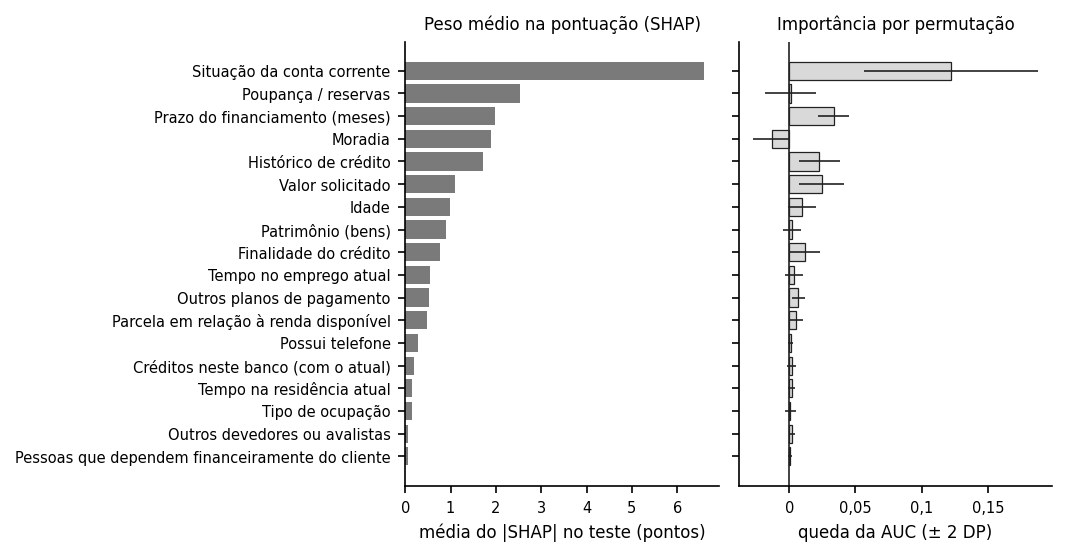

Legenda: importância global por variável original, sem sinal. Esquerda: média do valor absoluto da contribuição SHAP no teste. Direita: queda da AUC no teste ao embaralhar a variável; ± 2 desvios-padrão entre as 10 repetições da permutação. As ordens podem divergir porque medem coisas diferentes.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.
Idade: peso médio |SHAP| 1,0 pontos por decisão (posição 7 de 18 variáveis); sem a idade, 29 de 800 decisões mudariam (componente 5). Peso médio baixo não implica ausência de efeito desigual.


In [ ]:
exigir("shap_teste", "pipe_final", "X_teste", "y_teste", "X_treino", "y_treino", "variaveis_orig", "mapa_variavel", "casos")

def leitura_relevancia(sem_valor_ambos, conjunta):
    """Leitura CONDICIONADA à permutação conjunta (r12/3, R1): não afirma irrelevância quando o conjunto tem valor."""
    g = tuple(sorted(sem_valor_ambos))
    if g in conjunta:
        r = conjunta[g]
        t_ok, cv_ok = r["teste"] - 2 * r["dp_teste"] > 0, r["cv"] - 2 * r["ep_cv"] > 0
        if not r["sem_valor"]:
            return (f"uma a uma, sem valor preditivo comprovado; em conjunto, "
                    + (f"com valor fora da amostra no treino ({br(r['cv'], 3)} ± {br(2 * r['ep_cv'], 3)})" if cv_ok else f"inconclusivo fora da amostra no treino ({br(r['cv'], 3)} ± {br(2 * r['ep_cv'], 3)})")
                    + (f"; no teste, com valor ({br(r['teste'], 3)} ± {br(2 * r['dp_teste'], 3)})" if t_ok else f"; no teste, inconclusivo ({br(r['teste'], 3)} ± {br(2 * r['dp_teste'], 3)})")
                    + ": as variáveis dividem a importância. A explicação é fiel ao modelo; o que não se sustenta é ler cada fator isolado como irrelevante.")
        return ("uma a uma e em conjunto, sem valor preditivo comprovado nestes dados: a explicação é fiel ao modelo, mas o modelo se apoia em fatores cuja relevância "
                "estes dados não sustentam (ausência de evidência, não evidência de ausência).")
    return ("sem valor preditivo comprovado nestes dados (um só fator nas duas medidas, sem teste em conjunto): a explicação é fiel ao modelo; "
            "não ler o peso do fator como relevância comprovada.") if sem_valor_ambos else "nenhum fator falha nas duas medidas."

with Secao("Componente 12 – Importância global (complementar)"):
    forma("E, A", "importância global por SHAP e por permutação (Figura NBC2)")
    shap_var_teste = pd.DataFrame(shap_teste).T.groupby(mapa_variavel).sum().T
    importancia_shap = shap_var_teste.abs().mean().sort_values(ascending=False)
    perm = permutation_importance(pipe_final, X_teste, y_teste, scoring="roc_auc", n_repeats=PARAMETROS["n_rep_permutacao"], random_state=semente("permutacao_importancia"), n_jobs=1)
    imp_perm = pd.Series(perm.importances_mean, index=X_teste.columns)
    imp_perm_sd = pd.Series(perm.importances_std, index=X_teste.columns)
    rho_g = spearmanr(importancia_shap, imp_perm.reindex(importancia_shap.index)).correlation
    # Permutação fora da amostra no treino: as MESMAS 5 partes da curva de confiabilidade (n = 800), menos ruidosa que o teste
    perm_partes, modelos_partes = [], []
    for k_, (tr, va) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=semente("cv_calibracao")).split(X_treino, y_treino)):
        m_ = clone(pipe_final).fit(X_treino.iloc[tr], y_treino.iloc[tr])
        modelos_partes.append((m_, va))
        r_ = permutation_importance(m_, X_treino.iloc[va], y_treino.iloc[va], scoring="roc_auc", n_repeats=PARAMETROS["n_rep_permutacao"],
                                    random_state=semente(f"permutacao_cv|{k_}"), n_jobs=-1)
        perm_partes.append(pd.Series(r_.importances_mean, index=X_treino.columns))
    perm_cv = pd.concat(perm_partes, axis=1)
    imp_cv, ep_cv = perm_cv.mean(axis=1), perm_cv.std(axis=1, ddof=1) / np.sqrt(perm_cv.shape[1])
    ordem_i = importancia_shap.index
    tab_global = pd.DataFrame({"SHAP médio |contribuição| (pontos)": (importancia_shap * 100).round(2),
                               "permutação no teste (queda da AUC)": imp_perm.reindex(ordem_i).round(3), "± 2 DP (teste)": (2 * imp_perm_sd).reindex(ordem_i).round(3),
                               "permutação fora da amostra no treino": imp_cv.reindex(ordem_i).round(3), "± 2 EP (5 partes)": (2 * ep_cv).reindex(ordem_i).round(3)})
    tab_global.index = [ROTULOS_PT[v] for v in ordem_i]
    display(tab_global.head(8))
    print(f"Spearman entre as duas ordens globais (SHAP x permutação no teste): {br(rho_g, 2)}. As ordens podem divergir porque medem coisas diferentes (deslocamento da pontuação x perda de desempenho).")
    # Fatores que vão aos relatórios e cuja permutação tem faixa que inclui 0
    fatores_rel = list(dict.fromkeys(v for c in ESTADO.casos.values() for v in c["fatores"]["top"]["variavel"]))
    sem_valor_teste = [v for v in fatores_rel if imp_perm[v] - 2 * imp_perm_sd[v] <= 0]
    sem_valor_ambos = [v for v in sem_valor_teste if imp_cv[v] - 2 * ep_cv[v] <= 0]
    def _lista_perm(vs):
        return "; ".join(f"{ROTULOS_PT[v]} (teste {br(imp_perm[v], 3)} ± {br(2 * imp_perm_sd[v], 3)}; treino {br(imp_cv[v], 3)} ± {br(2 * ep_cv[v], 3)})" for v in vs) or "nenhum"
    print(f"Fatores dos relatórios cuja permutação no teste tem faixa (± 2 DP) que inclui 0: {_lista_perm(sem_valor_teste)}.")
    print(f"... e também fora da amostra no treino (± 2 EP entre as 5 partes): {', '.join(ROTULOS_PT[v] for v in sem_valor_ambos) or 'nenhum'}.")
    # Permutação CONJUNTA (as colunas do grupo embaralhadas juntas): variáveis correlacionadas podem dividir a importância e ficar perto de 0 uma a uma
    def queda_conjunta(modelo_, X_, y_, cols, rng_):
        base_ = roc_auc_score(y_, modelo_.predict_proba(X_)[:, 1])
        quedas_ = []
        for _ in range(PARAMETROS["n_rep_permutacao"]):
            Xp = X_.copy()
            Xp[cols] = X_[cols].iloc[rng_.permutation(len(X_))].values
            quedas_.append(base_ - roc_auc_score(y_, modelo_.predict_proba(Xp)[:, 1]))
        return np.array(quedas_)
    conjunta = {}
    for grupo in ([tuple(sorted(sem_valor_ambos))] if len(sem_valor_ambos) >= 2 else []):      # o grupo dos que falham uma a uma, embaralhado de uma vez
        q_t = queda_conjunta(pipe_final, X_teste, y_teste, list(grupo), gerador(f"perm_conjunta_teste|{grupo}"))
        q_cv = np.array([queda_conjunta(m_, X_treino.iloc[va], y_treino.iloc[va], list(grupo), gerador(f"perm_conjunta_cv|{grupo}|{j}")).mean()
                         for j, (m_, va) in enumerate(modelos_partes)])
        ep_g = q_cv.std(ddof=1) / np.sqrt(len(q_cv))
        conjunta[grupo] = dict(teste=float(q_t.mean()), dp_teste=float(q_t.std()), cv=float(q_cv.mean()), ep_cv=float(ep_g),
                               sem_valor=bool(q_t.mean() - 2 * q_t.std() <= 0 and q_cv.mean() - 2 * ep_g <= 0))
        print(f"Permutação conjunta de {', '.join(ROTULOS_PT[v].lower() for v in grupo)}: teste {br(q_t.mean(), 3)} ± {br(2 * q_t.std(), 3)}; treino {br(q_cv.mean(), 3)} ± {br(2 * ep_g, 3)} -> "
              + ("o conjunto também não mostra valor preditivo." if conjunta[grupo]["sem_valor"]
                 else "o conjunto TEM valor preditivo: uma a uma, as variáveis dividem a importância e parecem inúteis."))
    g_sv = tuple(sorted(sem_valor_ambos))
    for k, c in ESTADO.casos.items():       # linhas por caso: dependem do resultado conjunto (r12/3, R1)
        vs = [v for v in c["fatores"]["top"]["variavel"] if v in sem_valor_teste]
        if vs:
            print(f"  Caso {k}: {', '.join(ROTULOS_PT[v].lower() for v in vs)} {'está' if len(vs) == 1 else 'estão'} entre os {len(c['fatores']['top'])} fatores do relatório: "
                  f"{'um a um' if len(vs) > 1 else 'isolado'}, sem valor preditivo comprovado no teste" + (" nem fora da amostra no treino" if all(v in sem_valor_ambos for v in vs) else "")
                  + ("; em conjunto, " + ("também sem valor comprovado" if conjunta[g_sv]["sem_valor"] else "com valor preditivo") if g_sv in conjunta and set(vs) & set(g_sv) else "") + ".")
    if sem_valor_teste:
        print("Leitura: " + leitura_relevancia(sem_valor_ambos, conjunta) + " O aviso fica só no texto técnico, não vai ao titular.")
    ESTADO.importancia_global = dict(shap=importancia_shap.to_dict(), permutacao=imp_perm.to_dict(), permutacao_dp=imp_perm_sd.to_dict(), permutacao_cv=imp_cv.to_dict(),
                                     permutacao_cv_ep=ep_cv.to_dict(), spearman_shap_perm=float(rho_g), sem_valor_teste=sem_valor_teste, sem_valor_ambos=sem_valor_ambos, conjunta=conjunta)

    ordem_plot = list(importancia_shap.index)[::-1]
    fig, (a1, a2) = nova_figura(LARG_2COL, 3.6, 1, 2, sharey=True)
    a1.barh([ROTULOS_PT[v] for v in ordem_plot], [importancia_shap[v] * 100 for v in ordem_plot], color=COR_NEUTRA)
    a1.set_xlabel("média do |SHAP| no teste (pontos)")
    a1.set_title("Peso médio na pontuação (SHAP)")
    a2.barh([ROTULOS_PT[v] for v in ordem_plot], [imp_perm[v] for v in ordem_plot], xerr=[2 * imp_perm_sd[v] for v in ordem_plot], color=COR_CLARA,
            edgecolor=COR_ESCURA, linewidth=0.6, ecolor=COR_ESCURA, error_kw=dict(linewidth=0.8))
    a2.axvline(0, color=COR_ESCURA, linewidth=0.8)
    a2.set_xlabel("queda da AUC (± 2 DP)")
    eixo_x_br(a2)
    a2.set_title("Importância por permutação")
    top_s, top_p = importancia_shap.index[0], imp_perm.sort_values(ascending=False).index[0]
    figura("C2", "importancia_global", fig,
           "Importância global das variáveis: SHAP médio e permutação",
           f"Legenda: importância global por variável original, sem sinal. Esquerda: média do valor absoluto da contribuição SHAP no teste. Direita: queda da AUC no teste "
           f"ao embaralhar a variável; ± 2 desvios-padrão entre as {PARAMETROS['n_rep_permutacao']} repetições da permutação. As ordens podem divergir porque medem coisas diferentes.",
           "E, A", destino="complementar")

    # Peso da idade no SHAP (complementa o Desempenho por grupos, componente 5)
    pos_idade = list(importancia_shap.index).index("age") + 1
    ESTADO.idade.update(peso_medio_pontos=float(importancia_shap["age"] * 100), posicao=pos_idade)
    print(f"Idade: peso médio |SHAP| {dpts(importancia_shap['age']).lstrip('+')} por decisão (posição {pos_idade} de {len(importancia_shap)} variáveis); "
          f"sem a idade, {ESTADO.idade['decisoes_que_mudam']} de {ESTADO.idade['n']} decisões mudariam (componente 5). Peso médio baixo não implica ausência de efeito desigual.")

##### LIME no mesmo caso, em nível de variável original

> **Complementar** (leitura opcional; o essencial cabe em 1 frase e 1 número: o R² local do caso em que o LIME não deve ser usado).

O `LimeTabularExplainer` recebe as **variáveis originais** e a função de previsão **reconstrói o DataFrame original e chama o `Pipeline` completo**; assim, cada variável tem **um único peso**. A vizinhança **não** é sorteada em torno do caso: com `sample_around_instance=False`, os casos sintéticos vêm da **distribuição do treino**, ponderados pela proximidade ao caso. Discretização, largura do núcleo, `num_samples` e semente estão declarados em `PARAMETROS_LIME`. As variáveis são sorteadas independentemente (a vizinhança pode ter combinações pouco realistas) e o R² local mede a fidelidade nessa vizinhança sintética. Os pesos do LIME e as contribuições do SHAP **não têm a mesma escala**: comparam-se sinais e ordens.

**Estabilidade.** O mesmo caso é explicado com várias sementes, com os **mesmos** parâmetros. Medem-se a estabilidade do sinal, o desvio dos pesos, a sobreposição (Jaccard) das 3 variáveis principais e a frequência com que a variável de maior peso se repete (Figura NBC3, complementar).


>>> Forma para equipe de desenvolvimento e auditor (E, A): pesos do LIME e sua estabilidade entre sementes (Figura NBC3)
Parâmetros do LIME: {"discretize_continuous": true, "discretizer": "decile", "kernel_width": 3.182, "feature_selection": "highest_weights", "num_features": 18, "num_samples": 5000, "sample_around_instance": false, "distance_metric": "euclidean"}

Caso A: pesos do LIME para 'inadimplência observada' (positivo = mais risco), R² local = 0,54
  +0,129  Situação da conta corrente=sem conta corrente
  +0,057  Poupança / reservas=sem poupança ou desconhecida
  -0,047  Moradia=alugada
  -0,022  Outros planos de pagamento=nenhum
  +0,019  Histórico de crédito=sem créditos ou todos pagos em dia
  Estabilidade (30 sementes): R² local médio 0,55 (mínimo 0,53) | Jaccard médio do top-3 1,00 | variável de maior peso repetida em 100%

Caso B: pesos do LIME para 'inadimplência observada' (positivo = mais risco), R² local = 0,22
  +0,054  Poupança / reservas=sem poupança ou desconhec

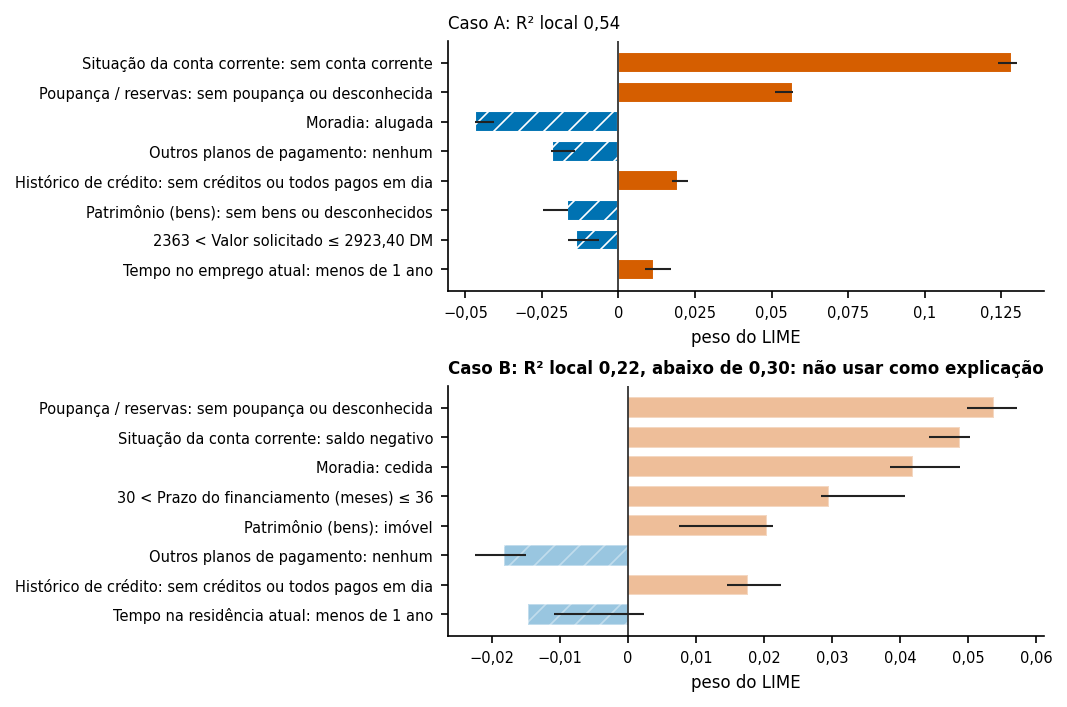

Legenda: os 8 maiores pesos do modelo linear local de cada caso (laranja e lisa = mais risco; azul e hachurada = menos); linha preta = faixa de 2,5% a 97,5% dos pesos entre 30 sementes com os mesmos parâmetros. Barras claras: R² local abaixo de 0,30 (convenção deste trabalho), caso em que o LIME não é usado como explicação.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("casos", "pipe_final", "X_treino", "X_teste", "colunas_usadas", "colunas_cat", "categorias")

LIME_KERNEL = float(0.75 * np.sqrt(len(colunas_usadas)))
PARAMETROS_LIME = dict(discretize_continuous=True, discretizer="decile", kernel_width=LIME_KERNEL, feature_selection="highest_weights",
                       num_features=len(colunas_usadas), num_samples=PARAMETROS["lime_amostras"], sample_around_instance=False, distance_metric="euclidean")
idx_cat_lime = [j for j, c in enumerate(colunas_usadas) if c in colunas_cat]
R2_LIME_BAIXO = 0.30    # convenção deste trabalho: abaixo disso, a reta local explica pouco e o LIME não é usado como explicação

def codificar_lime(df):
    """DataFrame original -> matriz (categorias como índices inteiros, números como float)."""
    saida = np.empty((len(df), len(colunas_usadas)))
    for j, col in enumerate(colunas_usadas):
        if col in categorias:
            mapa = {v: i for i, v in enumerate(categorias[col])}
            saida[:, j] = [mapa[str(v)] for v in df[col]]
        else:
            saida[:, j] = df[col].astype(float).values
    return saida

def decodificar_lime(matriz):
    """Matriz -> DataFrame com os valores originais (categorias em texto)."""
    matriz = np.asarray(matriz)
    dados = {}
    for j, col in enumerate(colunas_usadas):
        if col in categorias:
            lista = np.array(categorias[col], dtype=object)
            dados[col] = lista[np.clip(np.rint(matriz[:, j]).astype(int), 0, len(lista) - 1)]
        else:
            dados[col] = matriz[:, j].astype(float)
    return pd.DataFrame(dados, columns=colunas_usadas)

def prever_lime(matriz):
    return pipe_final.predict_proba(decodificar_lime(matriz))

def criar_explicador_lime(sem):
    return LimeTabularExplainer(
        training_data=X_treino_lime, feature_names=[ROTULOS_PT[c] for c in colunas_usadas],
        class_names=["pagou", "não pagou"], categorical_features=idx_cat_lime,
        categorical_names={j: [valor_legivel(colunas_usadas[j], v) for v in categorias[colunas_usadas[j]]] for j in idx_cat_lime},
        kernel_width=PARAMETROS_LIME["kernel_width"], mode="classification", discretize_continuous=True, discretizer="decile",
        feature_selection="highest_weights", sample_around_instance=False, random_state=sem)

def explicar_lime(x_cod, sem):
    """Explicação LIME de um caso (classe 1 = inadimplência observada) com os parâmetros declarados."""
    exp = criar_explicador_lime(sem).explain_instance(x_cod, prever_lime, labels=(1,), num_features=PARAMETROS_LIME["num_features"],
                                                      num_samples=PARAMETROS_LIME["num_samples"], distance_metric="euclidean")
    mapa = exp.as_map()[1]
    textos = [re.sub(r"(\d+)\.(\d+)", r"\1,\2", t) for t, _ in exp.as_list(label=1)]   # vírgula decimal
    assert len(mapa) == len(textos) == len(colunas_usadas), "o LIME deveria devolver um peso por variável"
    pesos, condicoes = {}, {}
    for (idx, w), texto in zip(mapa, textos):
        pesos[colunas_usadas[idx]] = float(w)
        condicoes[colunas_usadas[idx]] = texto
    score = getattr(exp, "score", None)
    score = score.get(1) if isinstance(score, dict) else score
    return dict(pesos=pesos, condicoes=condicoes, r2=float(score) if score is not None else float("nan"))

with Secao("Componente 12 – LIME e estabilidade (complementar)"):
    forma("E, A", "pesos do LIME e sua estabilidade entre sementes (Figura NBC3)")
    X_treino_lime, X_teste_lime = codificar_lime(X_treino), codificar_lime(X_teste)
    amostra_eq = np.arange(0, len(X_treino), 7)
    conferir("lime_predict_fn_equivale_pipeline", np.array_equal(prever_lime(X_treino_lime[amostra_eq]), pipe_final.predict_proba(X_treino.iloc[amostra_eq])),
             "predict_fn do LIME deve devolver o mesmo que o Pipeline.")
    print("Parâmetros do LIME:", json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in PARAMETROS_LIME.items()}, ensure_ascii=False))
    n_sem = PARAMETROS["n_sementes_lime"]
    for chave, c in ESTADO.casos.items():
        x_cod = X_teste_lime[c["posicao"]]
        sem = semente(f"lime|{c['indice_original']}")
        res = explicar_lime(x_cod, sem)
        c["lime"] = dict(**res, semente=sem)
        ordem = sorted(res["pesos"], key=lambda v: -abs(res["pesos"][v]))
        print(f"\nCaso {chave}: pesos do LIME para 'inadimplência observada' (positivo = mais risco), R² local = {br(res['r2'], 2)}")
        for v in ordem[:5]:
            print(f"  {('+' if res['pesos'][v] >= 0 else '') + br(res['pesos'][v], 3)}  {res['condicoes'][v]}")
        # estabilidade com os mesmos parâmetros
        sementes = [sem] + [semente(f"lime_estabilidade|{chave}|{k}") for k in range(n_sem - 1)]
        W, r2s = [[res["pesos"][v] for v in colunas_usadas]], [res["r2"]]
        for s in sementes[1:]:
            r = explicar_lime(x_cod, s)
            W.append([r["pesos"][v] for v in colunas_usadas])
            r2s.append(r["r2"])
        W = np.array(W)
        prod = W[0]
        nomes_arr = np.array(colunas_usadas)
        top3_prod = set(nomes_arr[np.argsort(-np.abs(prod))[:3]])
        jacc = [len(set(nomes_arr[np.argsort(-np.abs(l))[:3]]) & top3_prod) / len(set(nomes_arr[np.argsort(-np.abs(l))[:3]]) | top3_prod) for l in W]
        top1 = [colunas_usadas[int(np.argmax(np.abs(l)))] for l in W]
        sinal_igual = (np.sign(W) == np.sign(prod)).mean(axis=0)
        c["lime"]["estabilidade"] = dict(
            n_sementes=len(sementes), jaccard_top3_medio=float(np.mean(jacc)), frac_top1_igual=float(np.mean([t == top1[0] for t in top1])),
            r2_medio=float(np.mean(r2s)), r2_min=float(np.min(r2s)),
            por_variavel={v: dict(peso_producao=float(prod[j]), desvio=float(W[:, j].std(ddof=1)), p2_5=float(np.quantile(W[:, j], .025)),
                                  p97_5=float(np.quantile(W[:, j], .975)), frac_mesmo_sinal=float(sinal_igual[j])) for j, v in enumerate(colunas_usadas)})
        e = c["lime"]["estabilidade"]
        print(f"  Estabilidade ({e['n_sementes']} sementes): R² local médio {br(e['r2_medio'], 2)} (mínimo {br(e['r2_min'], 2)}) | Jaccard médio do top-3 {br(e['jaccard_top3_medio'], 2)} | variável de maior peso repetida em {pct(e['frac_top1_igual'], 0)}")
    ESTADO.update(X_treino_lime=X_treino_lime, X_teste_lime=X_teste_lime, r2_lime_baixo=R2_LIME_BAIXO)

    N_LIME_FIG = 8          # só os 8 pesos de maior valor absoluto por caso (figura complementar)
    UNID_LIME = {"credit_amount": " DM", "age": " anos"}
    def condicao_legivel(var, texto):
        """Condição do LIME em linguagem de leitura: «≤»/«≥», sem casas «,00», com unidade."""
        texto = texto.replace("<=", "≤").replace(">=", "≥").replace("=", ": ")
        texto = re.sub(r"(\d),00\b", r"\1", texto)
        if var in UNID_LIME and re.search(r"\d$", texto):
            texto += UNID_LIME[var]
        return textwrap.shorten(texto, 58, placeholder="…")
    fig, eixos = nova_figura(LARG_2COL, 4.6, len(ESTADO.casos), 1)
    for ax, (chave, c) in zip(np.atleast_1d(eixos), ESTADO.casos.items()):
        pesos = c["lime"]["pesos"]
        ordem = sorted(pesos, key=lambda v: abs(pesos[v]))[-N_LIME_FIG:]
        e = c["lime"]["estabilidade"]["por_variavel"]
        baixo = not np.isnan(c["lime"]["r2"]) and c["lime"]["r2"] < R2_LIME_BAIXO
        barras = ax.barh(range(len(ordem)), [pesos[v] for v in ordem], color=[cor_sinal(pesos[v]) for v in ordem], edgecolor="white", height=0.7,
                         alpha=0.4 if baixo else 1.0)
        for barra, v in zip(barras, ordem):
            barra.set_hatch(hachura_sinal(pesos[v]))
        ax.hlines(range(len(ordem)), [e[v]["p2_5"] for v in ordem], [e[v]["p97_5"] for v in ordem], color=COR_ESCURA, linewidth=1.0)
        ax.set_yticks(range(len(ordem)), [condicao_legivel(v, c["lime"]["condicoes"][v]) for v in ordem])
        ax.axvline(0, color=COR_ESCURA, linewidth=0.8)
        ax.set_xlabel("peso do LIME")
        eixo_x_br(ax)
        ax.set_title(f"Caso {chave}: R² local {br(c['lime']['r2'], 2)}" + (f", abaixo de {br(R2_LIME_BAIXO, 2)}: não usar como explicação" if baixo else ""),
                     loc="left", fontweight="bold" if baixo else "normal")
    figura("C3", "lime_pesos_estabilidade", fig, "Pesos do LIME e sua variação entre sementes, por caso",
           f"Legenda: os {N_LIME_FIG} maiores pesos do modelo linear local de cada caso (laranja e lisa = mais risco; azul e hachurada = menos); "
           f"linha preta = faixa de 2,5% a 97,5% dos pesos entre {PARAMETROS['n_sementes_lime']} sementes com os mesmos parâmetros. "
           f"Barras claras: R² local abaixo de {br(R2_LIME_BAIXO, 2)} (convenção deste trabalho), caso em que o LIME não é usado como explicação.",
           "E, A", destino="complementar")

##### Comparando as duas ferramentas

As **escalas e significados diferem** (SHAP: contribuição aditiva em pontos; LIME: peso de «estar nesta faixa/categoria» num modelo linear local): comparam-se **sinal e ordem**. Se as ferramentas **concordam**, isso não prova que estejam certas; se **discordam**, a discordância é informação a **relatar**, não a esconder. A correlação de Spearman sobre todas as variáveis é inflada pela cauda quase nula e por empates, por isso o que importa é a **sobreposição das 3 variáveis principais**, medida aqui nos dois casos e, na avaliação funcional, em todos os reprovados. Quando o **R² local** do LIME é baixo (abaixo de `R2_LIME_BAIXO`, convenção deste trabalho), a comparação mede em boa parte a falta de ajuste da reta, não uma divergência entre métodos; o código sinaliza esses casos.

In [ ]:
exigir("casos", "mapa_variavel", "variaveis_orig")

with Secao("Componente 12 – SHAP × LIME"):
    forma("E, A", "comparação de sinal e ordem entre SHAP e LIME")
    for chave, c in ESTADO.casos.items():
        shap_v = agregar_por_variavel(c["shap"]["phi"], mapa_variavel).reindex(variaveis_orig)
        lime_v = pd.Series(c["lime"]["pesos"]).reindex(variaveis_orig)
        rho = spearmanr(shap_v, lime_v).correlation
        top3_shap, top3_lime = list(shap_v.abs().sort_values(ascending=False).index[:3]), list(lime_v.abs().sort_values(ascending=False).index[:3])
        comum = [v for v in top3_shap if v in top3_lime]
        mesmo_sinal = int((np.sign(shap_v) == np.sign(lime_v)).sum())
        c["comparacao_lime"] = dict(spearman=float(rho), top3_shap=top3_shap, top3_lime=top3_lime, top3_em_comum=comum, n_mesmo_sinal=mesmo_sinal, n_variaveis=len(variaveis_orig))
        tab = pd.DataFrame({"SHAP (pontos)": (shap_v * 100).round(1), "posição SHAP": shap_v.abs().rank(ascending=False).astype(int),
                            "LIME (peso)": lime_v.round(3), "posição LIME": lime_v.abs().rank(ascending=False).astype(int),
                            "mesmo sinal": np.where(np.sign(shap_v) == np.sign(lime_v), "sim", "não")}).sort_values("posição SHAP").head(8)
        tab.index = [ROTULOS_PT[v] for v in tab.index]
        print(f"\n===== Caso {chave} =====")
        display(tab)
        print(f"Spearman {br(rho, 2)} | sinais iguais em {mesmo_sinal} de {len(variaveis_orig)} variáveis | 3 principais em comum: {len(comum)} de 3"
              f" ({', '.join(ROTULOS_PT[v] for v in comum) if comum else 'nenhuma'})")
        print("  3 principais no SHAP:", [ROTULOS_PT[v] for v in top3_shap], "| no LIME:", [ROTULOS_PT[v] for v in top3_lime])
        r2_caso = c["lime"]["r2"]
        if not np.isnan(r2_caso) and r2_caso < R2_LIME_BAIXO:
            print(f"  R² local do LIME = {br(r2_caso, 2)} (abaixo de {br(R2_LIME_BAIXO, 2)}): a reta explica pouco da variação local; esta comparação mede em boa parte "
                  "a falta de ajuste do LIME, não uma divergência entre métodos, e o LIME não deve ser usado como explicação deste caso.")

    # A comparação SHAP × LIME fica nas tabelas acima (a figura lado a lado repetiria as Figuras NB4a e NBC3).


>>> Forma para equipe de desenvolvimento e auditor (E, A): comparação de sinal e ordem entre SHAP e LIME

===== Caso A =====


,SHAP (pontos),posição SHAP,LIME (peso),posição LIME,mesmo sinal
Situação da conta corrente,10.5,1,0.129,1,sim
Poupança / reservas,2.5,2,0.057,2,sim
Moradia,-1.6,3,-0.047,3,sim
Patrimônio (bens),-1.3,4,-0.017,6,sim
Histórico de crédito,1.2,5,0.019,5,sim
Tempo no emprego atual,1.1,6,0.012,8,sim
Valor solicitado,-1.0,7,-0.014,7,sim
Prazo do financiamento (meses),0.9,8,0.007,13,sim


Spearman 0,95 | sinais iguais em 15 de 18 variáveis | 3 principais em comum: 3 de 3 (Situação da conta corrente, Poupança / reservas, Moradia)
  3 principais no SHAP: ['Situação da conta corrente', 'Poupança / reservas', 'Moradia'] | no LIME: ['Situação da conta corrente', 'Poupança / reservas', 'Moradia']

===== Caso B =====


,SHAP (pontos),posição SHAP,LIME (peso),posição LIME,mesmo sinal
Moradia,4.5,1,0.042,3,sim
Situação da conta corrente,3.7,2,0.049,2,sim
Prazo do financiamento (meses),3.6,3,0.030,4,sim
Poupança / reservas,2.3,4,0.054,1,sim
Patrimônio (bens),1.4,5,0.020,5,sim
Tempo no emprego atual,1.2,6,0.014,9,sim
Parcela em relação à renda disponível,1.0,7,0.010,11,sim
Valor solicitado,-1.0,8,-0.013,10,sim


Spearman 0,96 | sinais iguais em 17 de 18 variáveis | 3 principais em comum: 2 de 3 (Moradia, Situação da conta corrente)
  3 principais no SHAP: ['Moradia', 'Situação da conta corrente', 'Prazo do financiamento (meses)'] | no LIME: ['Poupança / reservas', 'Situação da conta corrente', 'Moradia']
  R² local do LIME = 0,22 (abaixo de 0,30): a reta explica pouco da variação local; esta comparação mede em boa parte a falta de ajuste do LIME, não uma divergência entre métodos, e o LIME não deve ser usado como explicação deste caso.


##### Avaliando as próprias explicações (avaliação funcional, exploratória)

> **Complementar** (leitura opcional; o essencial cabe em 1 frase e 1 número: a fração da queda do oráculo obtida pelo SHAP e pelo LIME; a Figura NB5 é opcional).

Uma explicação também pode estar errada. Há três níveis de avaliação [Doshi-Velez e Kim 2017]: com a aplicação real, com pessoas e **funcional** (sem pessoas, só com métricas). Aqui se faz a funcional, em **todos os reprovados** do teste; o nível **com pessoas não foi realizado**.

1. **Concordância SHAP × LIME por caso:** Spearman sobre todas as variáveis, **coincidência da variável nº 1** e **sobreposição das 3 principais** (a divergência aparece no topo, não na cauda).
2. **Teste de remoção por marginalização** (a remoção de variáveis como princípio comum dos métodos é formalizada por Covert et al. [2021]): as *k* variáveis apontadas por um método são substituídas por valores de outros casos do treino (amostra de fundo) e a pontuação média é recalculada. Mede a **sensibilidade do modelo**, não causa. Linhas de base: **ordem aleatória**, **importância global** e **oráculo guloso** (remove, a cada passo, a variável que mais reduz a pontuação; é limite de referência, não concorrente).
3. **Leitura:** reporta-se o **tamanho do efeito** (fração da queda do oráculo; Figura NB5), com IC95% por *bootstrap* de casos, que não inclui a variância do treino, do sorteio do LIME nem do fundo. A métrica usa marginalização sobre o fundo (função de valor intervencional), próxima, mas não idêntica, à do TreeSHAP `tree_path_dependent` usado aqui; tende a **favorecer métodos aditivos como o SHAP**, e o resultado não autoriza dizer que um método é "melhor". Como a comparação acima manda não usar o LIME com R² local baixo, as medidas são repetidas só nos casos com R² acima do limiar.


>>> Forma para equipe de desenvolvimento e auditor (E, A): teste de remoção e concordância em todos os reprovados (Figura NB5)

Casos reprovados avaliados: 44 | fundo de 100 linhas | 30 permutações aleatórias por caso | LIME num_samples = 5000
Pontuação média inicial dos casos avaliados: 45,8 pontos; com todas as variáveis removidas (média do fundo): 29,8 pontos

Queda média da pontuação (pontos) ao remover as k variáveis mais apontadas, com IC95% por bootstrap de casos:


,método,k=1,k=3,k=5
0,SHAP,"9,6 [9,0; 10,2]","15,2 [14,4; 15,8]","17,9 [17,1; 18,7]"
1,LIME,"9,3 [8,4; 10,1]","14,7 [14,0; 15,4]","17,6 [16,7; 18,4]"
2,Importância global,"9,4 [8,7; 10,1]","11,1 [10,0; 12,1]","13,7 [12,3; 15,0]"
3,Oráculo guloso,"9,6 [9,0; 10,2]","15,4 [14,7; 16,1]","18,0 [17,2; 18,8]"
4,Aleatório,"0,9 [0,8; 1,1]","2,7 [2,4; 3,0]","4,7 [4,3; 5,1]"


Em k = 3, fração da queda do oráculo guloso: SHAP 98%; LIME 95%; Importância global 72%; Oráculo guloso 100%; Aleatório 17%
   Diferença pareada SHAP − LIME em k = 3: +0,5 pontos, IC95% [0,2; 0,7], sobre uma queda total de 15,2 pontos (SHAP)

Concordância SHAP × LIME nos 44 casos: Spearman médio 0,93 (mínimo 0,80) | variável nº 1 coincide em 91% | 3 principais em comum: média de 2,3 de 3 (3 de 3 em 34% dos casos)
R² local do LIME abaixo de 0,30 (convenção da comparação acima) em 9 de 44 casos (mediana 0,53).
Leitura: a concordância nas 3 principais (78% das posições) é menor que o Spearman médio (0,93), que é inflado pela cauda quase nula; a variável nº 1 coincide mais (91%) que as 3 principais, ou seja, a divergência está sobretudo do 2º ao 3º fator; em 9 de 44 casos o R² local é baixo e a comparação mede em boa parte a falta de ajuste do LIME; a diferença SHAP − LIME na remoção é 3% da queda total do SHAP, e a métrica tende a favorecer o SHAP (função de valor próxima, não idêntica). 

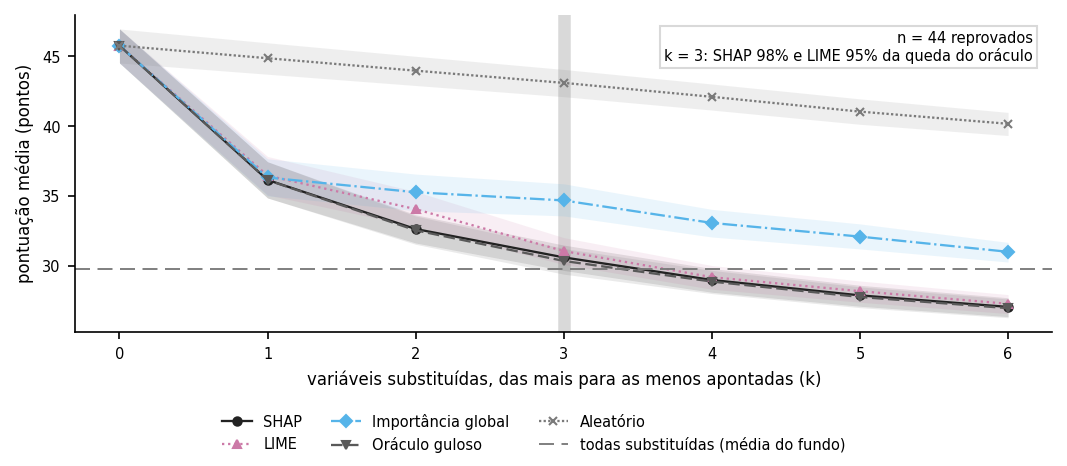

Legenda: pontuação média dos 44 reprovados do teste ao substituir as k variáveis mais apontadas por valores de 100 casos do treino. As curvas podem cair abaixo da linha «todas substituídas» porque saem primeiro as variáveis que sobem a pontuação, e as que a reduzem continuam no caso. Faixa vertical cinza: k = 3, usado na leitura. Bandas = IC95% por bootstrap de casos; não incluem a variância do treino, do sorteio do LIME nem do fundo. O oráculo guloso (cinza escuro, triângulo) é limite de referência, não método concorrente, e sua cor não indica sinal. Exploratório; mede sensibilidade do modelo, não causa.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("modelo", "X_teste_num", "X_treino_num", "X_teste", "X_treino", "prob_teste", "shap_teste", "explicador_shap", "casos", "X_teste_lime",
       "variaveis_orig", "cols_da_variavel", "mapa_variavel", "pipe_final", "colunas_usadas")

def ordem_por(serie):
    """Variáveis da que mais EMPURRA o risco para cima à que mais o reduz (empates: ordem original)."""
    return list(serie.sort_values(ascending=False, kind="stable").index)

def curvas_marginalizadas(rf, x, ordens, K, fundo, prob0, cols_da_variavel):
    """Para cada ordem, a pontuação MÉDIA sobre o fundo após substituir as k primeiras variáveis por valores do fundo (k = 0..K)."""
    n_bg, blocos, rotulos = len(fundo), [], []
    for nome, ordem in ordens.items():
        for k in range(1, K + 1):
            M = np.tile(x, (n_bg, 1))
            cols = [j for v in ordem[:k] for j in cols_da_variavel[v]]
            M[:, cols] = fundo[:, cols]
            blocos.append(M)
            rotulos.append((nome, k))
    medias = rf.predict_proba(np.vstack(blocos))[:, 1].reshape(len(blocos), n_bg).mean(axis=1)
    saida = {nome: np.full(K + 1, prob0, dtype=float) for nome in ordens}
    for (nome, k), v in zip(rotulos, medias):
        saida[nome][k] = v
    return saida

def oraculo_guloso(rf, x, K, fundo, variaveis, prob0, cols_da_variavel):
    """A cada passo, remove a variável cuja substituição mais reduz a pontuação média (sob a mesma marginalização)."""
    n_bg, removidas, curva = len(fundo), [], [prob0]
    for _ in range(K):
        candidatas = [v for v in variaveis if v not in removidas]
        blocos = []
        for v in candidatas:
            M = np.tile(x, (n_bg, 1))
            cols = [j for u in removidas + [v] for j in cols_da_variavel[u]]
            M[:, cols] = fundo[:, cols]
            blocos.append(M)
        medias = rf.predict_proba(np.vstack(blocos))[:, 1].reshape(len(candidatas), n_bg).mean(axis=1)
        melhor = int(np.argmin(medias))
        removidas.append(candidatas[melhor])
        curva.append(float(medias[melhor]))
    return removidas, np.array(curva)

with Secao("Componente 12 – Avaliação funcional das explicações (complementar)"):
    forma("E, A", "teste de remoção e concordância em todos os reprovados (Figura NB5)")
    K_MAX, K_PRINCIPAL = 6, 3
    NOMES_METODOS = ["SHAP", "LIME", "Importância global", "Oráculo guloso", "Aleatório"]
    idx_aval = [int(i) for i in np.where(prob_teste >= LIMIAR_RISCO)[0]]
    n_fundo = min(PARAMETROS["n_fundo"], len(X_treino_num))
    fundo_idx = np.sort(gerador("fundo_remocao").choice(len(X_treino_num), size=n_fundo, replace=False))
    fundo = X_treino_num[fundo_idx]
    risco_medio_fundo = float(modelo.predict_proba(fundo)[:, 1].mean())
    shap_treino = extrair_classe_mau(explicador_shap.shap_values(X_treino_num))
    shap_var_treino = pd.DataFrame(shap_treino).T.groupby(mapa_variavel).sum().T
    ordem_global = list(shap_var_treino.abs().mean().sort_values(ascending=False, kind="stable").index)     # importância global, calculada no treino

    # Teste de equivalência: marginalização numérica == substituição no DataFrame original passando pelo Pipeline
    c_a = ESTADO.casos["A"]
    teste_vars = ["credit_amount", "checking_status", "duration"]
    base_raw = pd.concat([c_a["caso_df"]] * n_fundo, ignore_index=True)
    fundo_raw = X_treino.iloc[fundo_idx].reset_index(drop=True)
    for v in teste_vars:
        base_raw[v] = fundo_raw[v].values
    via_pipeline = float(pipe_final.predict_proba(base_raw)[:, 1].mean())
    via_numerica = curvas_marginalizadas(modelo, c_a["x"], {"t": teste_vars}, 3, fundo, c_a["prob"], cols_da_variavel)["t"][3]
    conferir("marginalizacao_equivale_ao_pipeline", abs(via_pipeline - via_numerica) <= 1e-9, f"{via_pipeline!r} x {via_numerica!r}")
    rep_lime = explicar_lime(X_teste_lime[c_a["posicao"]], c_a["lime"]["semente"])
    conferir("lime_reprodutivel_com_a_mesma_semente", all(rep_lime["pesos"][v] == c_a["lime"]["pesos"][v] for v in colunas_usadas))

    riscos = {n: np.zeros((len(idx_aval), K_MAX + 1)) for n in NOMES_METODOS}
    rhos, top1_igual, top3_comum, r2_aval = [], [], [], []
    for n_i, i in enumerate(idx_aval):
        x, p0 = X_teste_num[i], float(prob_teste[i])
        ind_orig = int(X_teste.index[i])
        shap_v = agregar_por_variavel(shap_teste[i], mapa_variavel).reindex(variaveis_orig)
        exp_i = explicar_lime(X_teste_lime[i], semente(f"lime|{ind_orig}"))
        r2_aval.append(exp_i["r2"])
        lime_v = pd.Series(exp_i["pesos"]).reindex(variaveis_orig)
        rhos.append(spearmanr(shap_v, lime_v).correlation)
        t3s, t3l = list(shap_v.abs().sort_values(ascending=False).index[:3]), list(lime_v.abs().sort_values(ascending=False).index[:3])
        top1_igual.append(t3s[0] == t3l[0])
        top3_comum.append(len(set(t3s) & set(t3l)))
        ordens = {"SHAP": ordem_por(shap_v), "LIME": ordem_por(lime_v), "Importância global": ordem_global}
        rng_perm = gerador(f"aleatorio_remocao|{ind_orig}")
        for q in range(PARAMETROS["n_perm_aleatorias"]):
            ordens[f"Aleatório|{q}"] = [str(v) for v in rng_perm.permutation(variaveis_orig)]
        curvas = curvas_marginalizadas(modelo, x, ordens, K_MAX, fundo, p0, cols_da_variavel)
        for nome in ("SHAP", "LIME", "Importância global"):
            riscos[nome][n_i] = curvas[nome]
        riscos["Aleatório"][n_i] = np.array([curvas[k] for k in curvas if k.startswith("Aleatório|")]).mean(axis=0)
        riscos["Oráculo guloso"][n_i] = oraculo_guloso(modelo, x, K_MAX, fundo, variaveis_orig, p0, cols_da_variavel)[1]

    # ------------------------------------------------------------- resultados
    n_c = len(idx_aval)
    idx_boot = gerador("bootstrap_avaliacao").integers(0, n_c, size=(PARAMETROS["n_boot"], n_c))
    quedas = {n: riscos[n][:, [0]] - riscos[n] for n in NOMES_METODOS}          # queda (positiva = pontuação cai)
    curva_media = {n: riscos[n].mean(axis=0) for n in NOMES_METODOS}
    curva_ic = {n: np.quantile(riscos[n][idx_boot].mean(axis=1), [0.025, 0.975], axis=0) for n in NOMES_METODOS}
    print(f"\nCasos reprovados avaliados: {n_c} | fundo de {n_fundo} linhas | {PARAMETROS['n_perm_aleatorias']} permutações aleatórias por caso | LIME num_samples = {PARAMETROS['lime_amostras']}")
    print(f"Pontuação média inicial dos casos avaliados: {pts(np.mean(prob_teste[idx_aval]))}; com todas as variáveis removidas (média do fundo): {pts(risco_medio_fundo)}")

    K_TABELA = [k for k in (1, 3, 5) if k <= K_MAX]     # a figura mostra a curva completa
    linhas = []
    for nome in NOMES_METODOS:
        linha = {"método": nome}
        for k in K_TABELA:
            lo, hi = np.quantile(quedas[nome][idx_boot, k].mean(axis=1), [0.025, 0.975])
            linha[f"k={k}"] = f"{br(quedas[nome][:, k].mean() * 100)} [{br(lo * 100)}; {br(hi * 100)}]"
        linhas.append(linha)
    print("\nQueda média da pontuação (pontos) ao remover as k variáveis mais apontadas, com IC95% por bootstrap de casos:")
    display(pd.DataFrame(linhas))

    q_orac = quedas["Oráculo guloso"][:, K_PRINCIPAL].mean()
    eficiencia = {n: float(quedas[n][:, K_PRINCIPAL].mean() / q_orac) for n in NOMES_METODOS}
    print(f"Em k = {K_PRINCIPAL}, fração da queda do oráculo guloso: " + "; ".join(f"{n} {pct(v, 0)}" for n, v in eficiencia.items()))
    comparacoes = {}
    d = quedas["SHAP"][:, K_PRINCIPAL] - quedas["LIME"][:, K_PRINCIPAL]
    lo, hi = np.quantile(d[idx_boot].mean(axis=1), [0.025, 0.975])
    comparacoes["SHAP − LIME"] = dict(diferenca_pontos=float(d.mean() * 100), ic95=[float(lo * 100), float(hi * 100)])
    print(f"   Diferença pareada SHAP − LIME em k = {K_PRINCIPAL}: {dpts(d.mean())}, IC95% [{br(lo * 100)}; {br(hi * 100)}], sobre uma queda total de {br(quedas['SHAP'][:, K_PRINCIPAL].mean() * 100)} pontos (SHAP)")
    rhos = np.array([r for r in rhos if not np.isnan(r)])
    print(f"\nConcordância SHAP × LIME nos {n_c} casos: Spearman médio {br(rhos.mean(), 2)} (mínimo {br(rhos.min(), 2)}) | variável nº 1 coincide em {pct(np.mean(top1_igual), 0)} | "
          f"3 principais em comum: média de {br(np.mean(top3_comum))} de 3 (3 de 3 em {pct(np.mean(np.array(top3_comum) == 3), 0)} dos casos)")
    r2_aval = np.array(r2_aval, dtype=float)
    n_r2_baixo = int((r2_aval < R2_LIME_BAIXO).sum())          # NaN conta como não baixo
    frac_top1, frac_top3 = float(np.mean(top1_igual)), float(np.mean(top3_comum)) / 3
    queda_shap_k = float(quedas["SHAP"][:, K_PRINCIPAL].mean())
    rel_dif = float(d.mean()) / queda_shap_k if queda_shap_k else float("nan")
    print(f"R² local do LIME abaixo de {br(R2_LIME_BAIXO, 2)} (convenção da comparação acima) em {n_r2_baixo} de {n_c} casos" + (f" (mediana {br(float(np.nanmedian(r2_aval)), 2)})." if n_c else "."))
    leitura = []
    if frac_top3 < rhos.mean():
        leitura.append(f"a concordância nas 3 principais ({pct(frac_top3, 0)} das posições) é menor que o Spearman médio ({br(rhos.mean(), 2)}), que é inflado pela cauda quase nula")
    if frac_top1 > frac_top3:
        leitura.append(f"a variável nº 1 coincide mais ({pct(frac_top1, 0)}) que as 3 principais, ou seja, a divergência está sobretudo do 2º ao 3º fator")
    if n_r2_baixo:
        leitura.append(f"em {n_r2_baixo} de {n_c} casos o R² local é baixo e a comparação mede em boa parte a falta de ajuste do LIME")
    leitura.append(f"a diferença SHAP − LIME na remoção é {pct(rel_dif, 0)} da queda total do SHAP, e a métrica tende a favorecer o SHAP (função de valor próxima, não idêntica)")
    print("Leitura: " + "; ".join(leitura) + ". Indício exploratório, não prova.")
    # Mesmas medidas só nos casos em que o próprio notebook usaria o LIME (R² local ≥ R2_LIME_BAIXO; comparação acima)
    ok_r2 = ~(r2_aval < R2_LIME_BAIXO)
    n_ok = int(ok_r2.sum())
    restrito = None
    if n_ok:
        q_or_r = quedas["Oráculo guloso"][ok_r2, K_PRINCIPAL].mean()
        restrito = dict(n=n_ok, shap=float(quedas["SHAP"][ok_r2, K_PRINCIPAL].mean() / q_or_r), lime=float(quedas["LIME"][ok_r2, K_PRINCIPAL].mean() / q_or_r),
                        top1=float(np.mean(np.array(top1_igual)[ok_r2])), top3=float(np.mean(np.array(top3_comum)[ok_r2])))
        print(f"Só nos {n_ok} casos com R² local ≥ {br(R2_LIME_BAIXO, 2)}: SHAP {pct(restrito['shap'], 0)} e LIME {pct(restrito['lime'], 0)} da queda do oráculo (k = {K_PRINCIPAL}); "
              f"variável nº 1 igual em {pct(restrito['top1'], 0)}; 3 principais em comum, em média, {br(restrito['top3'])} de 3.")

    ESTADO.avaliacao = dict(n_casos=n_c, k_principal=K_PRINCIPAL, eficiencia_relativa_ao_oraculo=eficiencia, comparacoes=comparacoes,
                            spearman_medio=float(rhos.mean()), top1_igual=float(np.mean(top1_igual)), top3_comum_medio=float(np.mean(top3_comum)),
                            queda_k3_pontos={n: float(quedas[n][:, K_PRINCIPAL].mean() * 100) for n in NOMES_METODOS}, n_r2_baixo=n_r2_baixo,
                            restrito_r2=restrito)

    fig, ax = nova_figura(LARG_2COL, 3.0)
    ks = np.arange(K_MAX + 1)
    for nome in NOMES_METODOS:
        est = ESTILO_METODOS[nome]
        ax.plot(ks, curva_media[nome] * 100, label=nome, color=est["color"], marker=est["marker"], linestyle=est["linestyle"], markersize=4, linewidth=1.1)
        ax.fill_between(ks, curva_ic[nome][0] * 100, curva_ic[nome][1] * 100, color=est["color"], alpha=0.12, linewidth=0)
    ax.axhline(risco_medio_fundo * 100, color=COR_NEUTRA, linewidth=0.9, linestyle=(0, (8, 4)), label="todas substituídas (média do fundo)")
    ax.text(0.98, 0.95, f"n = {n_c} reprovados\nk = {K_PRINCIPAL}: SHAP {pct(eficiencia['SHAP'], 0)} e LIME {pct(eficiencia['LIME'], 0)} da queda do oráculo",
            transform=ax.transAxes, ha="right", va="top", fontsize=7, bbox=dict(fc="white", ec=COR_CLARA, pad=2))
    ax.axvline(K_PRINCIPAL, color=COR_CLARA, linewidth=6, zorder=0)
    ax.set_xticks(ks)
    ax.set_xlabel("variáveis substituídas, das mais para as menos apontadas (k)")
    ax.set_ylabel("pontuação média (pontos)")
    fig.legend(loc="outside lower center", ncol=3, frameon=False)
    perto = min(eficiencia["SHAP"], eficiencia["LIME"]) >= 0.80
    figura(5, "teste_de_remocao", fig,
           "Teste de remoção: pontuação média ao substituir as variáveis mais apontadas, por método",
           f"Legenda: pontuação média dos {n_c} reprovados do teste ao substituir as k variáveis mais apontadas por valores de {n_fundo} casos do treino. "
           "As curvas podem cair abaixo da linha «todas substituídas» porque saem primeiro as variáveis que sobem a pontuação, e as que a reduzem continuam no caso. "
           "Faixa vertical cinza: k = 3, usado na leitura. Bandas = IC95% por bootstrap de casos; não incluem a variância do treino, do sorteio do LIME nem do fundo. O oráculo guloso (cinza escuro, triângulo) é "
           "limite de referência, não método concorrente, e sua cor não indica sinal. Exploratório; mede sensibilidade do modelo, não causa.",
           "E, A")

In [ ]:
# Auditoria exploratória da cobertura SHAP/LIME nos 17 componentes.
# Esta célula NÃO treina modelos, não recalcula previsões e não altera ESTADO.
# Ela resume o que as células anteriores efetivamente produziram nesta implementação.
from IPython.display import display, Markdown
display(Markdown('### Complementar — cobertura observada dos 17 componentes'))

cobertura = {
    1: ("Não direto", "Não direto", "Regras e justificativas estão na tabela de regras; as atribuições do modelo não registram a política aplicada."),
    2: ("Não", "Não", "Origem, período e composição são metadados da base, documentados na ficha."),
    3: ("Não", "Não", "Algoritmo, hiperparâmetros e validação são registrados na ficha de treinamento."),
    4: ("Não", "Não", "AUC, matriz de confusão e calibração são calculadas por métricas próprias."),
    5: ("Não direto", "Não direto", "As taxas e os intervalos por grupo vêm da análise de grupos, não das atribuições locais."),
    6: ("Não", "Não", "Estabilidade é calculada comparando retreinamentos; SHAP/LIME aqui explicam um modelo por vez."),
    7: ("Não", "Não", "O critério de aceite é definido antes da avaliação e registrado separadamente."),
    8: ("Não", "Não", "O limiar e os custos são decisões de projeto; não são inferidos das atribuições das variáveis."),
    9: ("Parcial", "Não nesta implementação", "A relevância global por SHAP descreve parte do comportamento do modelo, mas não sua versão, uso pretendido ou limitações."),
    10: ("Não direto", "Não direto", "A ordem das etapas é descrita pela trilha de inferência; atribuições não substituem o registro de qual etapa decidiu."),
    11: ("Não", "Não", "Os dados do caso são apresentados em tabela; uma atribuição não fornece origem e uso de cada dado."),
    12: ("Direto", "Direto, condicionado à fidelidade local", "Ambos geram fatores por caso; o LIME não é usado quando seu R² local fica abaixo do corte definido no notebook."),
    13: ("Não", "Não", "As alterações possíveis são obtidas por busca contrafactual própria, não por valores de atribuição."),
    14: ("Não", "Não", "A checagem de dados possivelmente errados é feita por substituições; importância não identifica erro factual."),
    15: ("Não", "Não", "O direito e o canal de revisão são conteúdo jurídico e operacional documentado separadamente."),
    16: ("Reaproveitado", "Não", "O registro pode guardar fatores SHAP já calculados; isso não significa que SHAP produza o registro."),
    17: ("Não direto", "Não direto", "Mudanças por lote e indicadores de monitoramento são calculados separadamente."),
}

linhas = []
for item in MANUAL:
    n = item["n"]
    shap, lime, motivo = cobertura[n]
    linhas.append([n, item["componente"], shap, lime, motivo])

display(Markdown(
    "**Escopo:** a tabela registra a cobertura observada nas células deste notebook; “não” significa que a técnica não produziu diretamente o artefato requerido nesta implementação, não que seja impossível qualquer uso futuro. “Reaproveitado” não conta como cobertura produzida pela técnica.\n\n"
    + tabela_markdown(["Nº", "Componente", "SHAP", "LIME", "Motivo / artefato usado"], linhas)
))

# Comparação já calculada nas células anteriores: nenhum novo ajuste ou explicador é executado.
a = ESTADO.avaliacao
n = a["n_casos"]
q = a["eficiencia_relativa_ao_oraculo"]
d = a["comparacoes"]["SHAP − LIME"]
rr = a["restrito_r2"]
print(f"\nComponente 12 — {n} reprovações avaliadas: SHAP {pct(q['SHAP'], 0)} e LIME {pct(q['LIME'], 0)} da queda do oráculo no teste de remoção (k={a['k_principal']}).")
print(f"Diferença pareada SHAP − LIME: {br(d['diferenca_pontos'], 1)} pontos; IC95% [{br(d['ic95'][0], 1)}; {br(d['ic95'][1], 1)}].")
print(f"O R² local do LIME ficou abaixo de {br(R2_LIME_BAIXO, 2)} em {a['n_r2_baixo']} de {n} casos; só nos {rr['n']} casos acima do corte, SHAP reteve {pct(rr['shap'], 0)} e LIME {pct(rr['lime'], 0)} da queda do oráculo.")
print("Leitura: SHAP ficou ligeiramente à frente neste critério funcional, que tende a favorecer explicações aditivas; a diferença é pequena e exploratória, não demonstra superioridade geral. O LIME depende de ajuste local adequado; abaixo do corte definido, sua explicação não é usada.")


### Complementar — cobertura observada dos 17 componentes

**Escopo:** a tabela registra a cobertura observada nas células deste notebook; “não” significa que a técnica não produziu diretamente o artefato requerido nesta implementação, não que seja impossível qualquer uso futuro. “Reaproveitado” não conta como cobertura produzida pela técnica.

| Nº | Componente | SHAP | LIME | Motivo / artefato usado |
| --- | --- | --- | --- | --- |
| 1 | Regras de negócio | Não direto | Não direto | Regras e justificativas estão na tabela de regras; as atribuições do modelo não registram a política aplicada. |
| 2 | Base de dados de treinamento e teste | Não | Não | Origem, período e composição são metadados da base, documentados na ficha. |
| 3 | Treinamento | Não | Não | Algoritmo, hiperparâmetros e validação são registrados na ficha de treinamento. |
| 4 | Métricas de desempenho | Não | Não | AUC, matriz de confusão e calibração são calculadas por métricas próprias. |
| 5 | Desempenho por grupos | Não direto | Não direto | As taxas e os intervalos por grupo vêm da análise de grupos, não das atribuições locais. |
| 6 | Estabilidade da decisão | Não | Não | Estabilidade é calculada comparando retreinamentos; SHAP/LIME aqui explicam um modelo por vez. |
| 7 | Seleção e aceite do modelo | Não | Não | O critério de aceite é definido antes da avaliação e registrado separadamente. |
| 8 | Limiar de decisão | Não | Não | O limiar e os custos são decisões de projeto; não são inferidos das atribuições das variáveis. |
| 9 | Modelo treinado e versão | Parcial | Não nesta implementação | A relevância global por SHAP descreve parte do comportamento do modelo, mas não sua versão, uso pretendido ou limitações. |
| 10 | Inferência | Não direto | Não direto | A ordem das etapas é descrita pela trilha de inferência; atribuições não substituem o registro de qual etapa decidiu. |
| 11 | Dados individuais do titular | Não | Não | Os dados do caso são apresentados em tabela; uma atribuição não fornece origem e uso de cada dado. |
| 12 | Fatores da decisão | Direto | Direto, condicionado à fidelidade local | Ambos geram fatores por caso; o LIME não é usado quando seu R² local fica abaixo do corte definido no notebook. |
| 13 | Alterações possíveis | Não | Não | As alterações possíveis são obtidas por busca contrafactual própria, não por valores de atribuição. |
| 14 | Dados possivelmente errados | Não | Não | A checagem de dados possivelmente errados é feita por substituições; importância não identifica erro factual. |
| 15 | Direito e meio para solicitar revisão | Não | Não | O direito e o canal de revisão são conteúdo jurídico e operacional documentado separadamente. |
| 16 | Registro da decisão | Reaproveitado | Não | O registro pode guardar fatores SHAP já calculados; isso não significa que SHAP produza o registro. |
| 17 | Monitoramento | Não direto | Não direto | Mudanças por lote e indicadores de monitoramento são calculados separadamente. |


Componente 12 — 44 reprovações avaliadas: SHAP 98% e LIME 95% da queda do oráculo no teste de remoção (k=3).
Diferença pareada SHAP − LIME: 0,5 pontos; IC95% [0,2; 0,7].
O R² local do LIME ficou abaixo de 0,30 em 9 de 44 casos; só nos 35 casos acima do corte, SHAP reteve 98% e LIME 96% da queda do oráculo.
Leitura: SHAP ficou ligeiramente à frente neste critério funcional, que tende a favorecer explicações aditivas; a diferença é pequena e exploratória, não demonstra superioridade geral. O LIME depende de ajuste local adequado; abaixo do corte definido, sua explicação não é usada.


#### Forma em linguagem simples (T)

A **tradução** dos números técnicos para algo que a pessoa entende: um texto baseado nas contribuições do SHAP, **sem jargão**, seletivo e contrastivo [Miller 2019]. Não leva gráficos: **nenhuma figura deste notebook é entregue ao titular.** Também não leva um resumo global por regras, que esconderia os reprovados difíceis.

**Regras de tradução** (aplicadas pelo código; a regra 4 é verificada automaticamente no relatório do componente 15):
1. Nada de códigos como `checking_status = <0`: nome em português, valor real e unidade (meses, DM).
2. **Associações do modelo**, nunca causas («associado a uma pontuação mais alta»). No máximo **5 fatores** (escolha de projeto, sem fonte para o número) e uma linha «outras N informações, somadas», para a conta fechar do ponto de partida até a pontuação.
3. **Pontuação** na escala de 0 a 100 pontos, nunca «chance» nem «%». Categorias que juntam «não tem» e «não se sabe» levam a nota de codificação; quando o peso de um fator vem sobretudo de **não** estar em outra categoria, o texto diz qual e a taxa dela. O aviso de fatores sem valor preditivo comprovado (visão global, acima) fica só na forma técnica: é ausência de evidência, oscila perto de zero e, ao titular, seria lido como «fui reprovado por fatores inúteis».
4. Sem os termos técnicos da lista `JARGOES`.

In [ ]:
exigir("casos", "y_treino")

def frase_fator(l, t, compacto=False):
    """Fator com a contribuição EXIBIDA (t, em décimos de ponto, a mesma que entra na conta)."""
    if t == 0:      # arredonda para zero: não se diz «0,0 pontos mais alta»
        return f"{l['rotulo']}: {l['valor']}; peso menor que 0,1 ponto"
    if compacto and int(compacto) >= 2:
        return f"{l['rotulo'].replace(' (meses)', '')}: {l['valor']} ({txt_decimos(t, True)} pontos)"
    if compacto:
        return f"{l['rotulo']}: {l['valor']}; associado a {txt_decimos(t, True)} pontos"
    sentido = "mais alta" if l["phi_variavel"] > 0 else "mais baixa"
    return f"{l['rotulo']}: {l['valor']}; associado a uma pontuação {txt_decimos(abs(t))} pontos {sentido}"

TOL_EMPATE = 0.0005     # 0,05 ponto: abaixo disso, o 5º e o 6º fatores são tratados como empatados e o texto diz isso

def bloco_fatores(c, nivel=0, com_notas=True):
    """Forma ao titular dos Fatores da decisão: até 5 fatores, «outras N», a conta que fecha e as notas de codificação. Devolve linhas de Markdown."""
    fat, ce = c["fatores"], c["fatores"]["conta_exibida"]
    L = [f"**Principais fatores** (associações do sistema, não causas). Ponto de partida (média do modelo nos pedidos antigos): {txt_decimos(ce['base'])} pontos."]
    n_top = len(fat["top"])
    for k, ((_, l), t) in enumerate(zip(fat["top"].iterrows(), ce["fatores"]), start=1):
        frase = frase_fator(l, t, nivel)
        if l.get("peso_de_fora"):        # peso que vem de NÃO estar em outra categoria: sem isso, o fator parece contraditório
            frase += f"; pesa {'sobretudo ' if nivel < 3 else ''}porque não está no grupo «{valor_legivel(l['variavel'], l['peso_de_fora'])}» ({pct(l['taxa_peso_de_fora'], 0)} não pagaram)"
            if (l['variavel'], str(l['peso_de_fora'])) in set(CONTRAINTUITIVAS) | SEM_INFORMACAO:   # não sugerir que o outro grupo seria melhor (ou pior)
                frase += ", o que não indica situação " + ("melhor" if l["taxa_peso_de_fora"] < y_treino.mean() else "pior")
        if k == n_top and len(fat["tabela"]) > n_top:        # empate no corte dos 5 fatores: diz qual ficou de fora
            l6 = fat["tabela"].iloc[n_top]
            if abs(abs(l6["phi_variavel"]) - abs(l["phi_variavel"])) < TOL_EMPATE:
                v6 = txt_decimos(decimos(l6['phi_variavel']), True)
                frase += (f" (empate com {l6['rotulo'].lower()}: {v6})" if np.sign(l6["phi_variavel"]) == np.sign(l["phi_variavel"])
                          else f" ({l6['rotulo'].lower()} pesou o mesmo, em sentido contrário: {v6})")
        L.append("- " + frase + ".")
    L.append(f"- Outras {fat['outros_n']} informações, somadas: {txt_decimos(ce['outros'], True)} pontos.")
    L.append(f"\nConta: {txt_decimos(ce['base'])} {txt_decimos(ce['top'], True)} {txt_decimos(ce['outros'], True)} = {txt_decimos(ce['pontuacao'])} pontos.")
    notas = [l for _, l in fat["top"].iterrows() if l["nota"]] if com_notas else []
    sem_info = [l for l in notas if l["tipo_nota"] == "sem_informacao"]
    if nivel >= 2 and sem_info:        # uma só nota para todas as categorias «não tem ou não informou»
        L.append(f"Nota: em {' e '.join(l['rotulo'].lower() for l in sem_info)}, a categoria junta quem não tem e quem não informou "
                 f"({' e '.join(pct(l['taxa_categoria'], 0) for l in sem_info)} não pagaram).")
        notas = [l for l in notas if l["tipo_nota"] != "sem_informacao"]
    for l in notas:
        if l["tipo_nota"] == "sem_informacao":
            L.append(f"Nota: «{l['valor']}» junta quem não tem e quem não informou; {pct(l['taxa_categoria'], 0)} desse grupo ({int(l['n_categoria'])} casos) não pagou.")
        elif l["tipo_nota"] == "contraintuitiva":
            L.append(f"Nota: no histórico, {pct(l['taxa_categoria'], 0)} do grupo «{l['valor']}» ({int(l['n_categoria'])} casos) não pagou; o sistema aprendeu essa associação desta base antiga, "
                     f"mas «{l['valor']}» não é, em si, sinal de {'bom' if l['taxa_categoria'] < y_treino.mean() else 'mau'} pagamento.")
    return L

with Secao("Componente 12 – Forma em linguagem simples"):
    for chave, c in ESTADO.casos.items():
        forma("T", f"até {N_FATORES_RELATORIO} fatores do caso {chave}, com a conta (o mesmo bloco entra no relatório do componente 15)")
        display(Markdown("\n".join(bloco_fatores(c))))


>>> Forma para titular (T): até 5 fatores do caso A, com a conta (o mesmo bloco entra no relatório do componente 15)


**Principais fatores** (associações do sistema, não causas). Ponto de partida (média do modelo nos pedidos antigos): 30,1 pontos.
- Situação da conta corrente: sem conta corrente; associado a uma pontuação 10,5 pontos mais alta.
- Poupança / reservas: sem poupança ou desconhecida; associado a uma pontuação 2,5 pontos mais alta.
- Moradia: alugada; associado a uma pontuação 1,6 pontos mais baixa.
- Patrimônio (bens): sem bens ou desconhecidos; associado a uma pontuação 1,3 pontos mais baixa.
- Histórico de crédito: sem créditos ou todos pagos em dia; associado a uma pontuação 1,2 pontos mais alta; pesa sobretudo porque não está no grupo «todos os créditos neste banco pagos em dia» (17% não pagaram).
- Outras 13 informações, somadas: +0,0 pontos.

Conta: 30,1 +11,3 +0,0 = 41,4 pontos.
Nota: «sem poupança ou desconhecida» junta quem não tem e quem não informou; 37% desse grupo (468 casos) não pagou.
Nota: «sem bens ou desconhecidos» junta quem não tem e quem não informou; 20% desse grupo (226 casos) não pagou.


>>> Forma para titular (T): até 5 fatores do caso B, com a conta (o mesmo bloco entra no relatório do componente 15)


**Principais fatores** (associações do sistema, não causas). Ponto de partida (média do modelo nos pedidos antigos): 30,1 pontos.
- Moradia: cedida; associado a uma pontuação 4,5 pontos mais alta.
- Situação da conta corrente: saldo negativo; associado a uma pontuação 3,7 pontos mais alta.
- Prazo do financiamento (meses): 36 meses; associado a uma pontuação 3,6 pontos mais alta.
- Poupança / reservas: sem poupança ou desconhecida; associado a uma pontuação 2,3 pontos mais alta.
- Patrimônio (bens): imóvel; associado a uma pontuação 1,4 pontos mais alta.
- Outras 13 informações, somadas: +1,4 pontos.

Conta: 30,1 +15,5 +1,4 = 47,0 pontos.
Nota: «sem poupança ou desconhecida» junta quem não tem e quem não informou; 37% desse grupo (468 casos) não pagou.
Nota: no histórico, 43% do grupo «imóvel» (122 casos) não pagou; o sistema aprendeu essa associação desta base antiga, mas «imóvel» não é, em si, sinal de mau pagamento.

### Componente 13 — Alterações possíveis

**O que é.** Indicam o que precisaria ser diferente para o resultado mudar — a explicação contrafactual —, permitindo ao titular entender e contestar a decisão sem acesso ao modelo [Wachter et al. 2018]. É uma **simulação do modelo** («o que o sistema calcularia se este dado fosse outro»), não uma causa nem uma garantia. Como o modelo não é legível, a resposta precisa ser **procurada**: testam-se mudanças e vê-se se a pontuação cai abaixo do limiar.

**Classe, público e LGPD.** **Recomendável** (não é critério aplicado ao caso: descreve entradas hipotéticas, e não um critério aplicado ao caso) · T · sem dispositivo. A busca abaixo é cálculo de apoio; a forma do componente é a frase ao titular, impressa ao fim e repetida no relatório (componente 15).

**Neste notebook.**
- **Espaço de busca:** só o que a pessoa pode, em princípio, alterar (a noção de ação factível vem de Ustun et al. [2019]): prazo, valor solicitado, conta corrente, poupança e avalista. Não se sugerem mudanças em idade, ocupação, moradia, finalidade, histórico etc. A escala de esforço e a ordem da poupança são premissas ilustrativas. Duas categorias ficam **fora da ordem** (nem origem nem destino): «sem conta corrente», porque não se simula abrir uma conta, e «sem poupança ou desconhecida», porque junta quem não tem e quem não informou: partir dela seria simular uma **declaração**, não uma ação (para esse caso, ver Dados possivelmente errados, componente 14). Pela escala ilustrativa (1 degrau de categoria vale 0,25, o mesmo que reduzir o prazo em 25%), duas mudanças pequenas podem custar menos que uma grande: por isso o menor esforço pode ter 2 mudanças mesmo quando há solução com 1.
- **Busca exaustiva de 1 e de 2 mudanças.** Um candidato é aceito se (i) a pontuação ficar **3 pontos abaixo do corte**, (ii) ficar abaixo do corte em **≥ 90% dos retreinos com outra semente e ≥ 90% dos retreinos com treino reamostrado** (a menor das duas frações, a mesma regra da Estabilidade da decisão, componente 6) e (iii) as regras de política aprovarem. Combinações que **contêm** uma mudança única já suficiente são descartadas (minimalidade).
- **Escolha da simulação ao titular:** entre os candidatos aceitos com esforço até 0,25 acima do menor, a de **maior robustez** (menor das duas frações); empate, a de menor esforço. Assim não se entrega a opção mais frágil quando há outra quase tão simples e mais robusta.
- **Prazo e parcela:** o sistema não recalcula a parcela (valor/prazo) quando o prazo muda; por isso a redução do prazo fica **limitada a 50%** (a parcela, no máximo, dobra), e o relatório avisa que a parcela subiria. Escolha de projeto: é a opção mais simples que impede simulações absurdas (como de 24 para 6 meses, parcela 4 vezes maior).
- **Limite:** fora isso, a coerência entre variáveis (valor × prazo × parcela) não é verificada; "nenhuma outra mudança funciona" vale só para o espaço testado.

In [ ]:
exigir("casos", "retreinos_semente", "retreinos_reamostra", "pipe_final", "X_treino", "categorias", "colunas_usadas")

ORDEM_CHECKING = ["<0", "0<=X<200", ">=200 or salary"]                                 # «sem conta corrente» fora da ordem (nem origem nem destino)
ORDEM_POUPANCA = ["<100", "100<=X<500", "500<=X<1000", ">=1000"]     # premissa ordinal ilustrativa; «sem poupança ou desconhecida» fora da ordem (categoria mista)
ORDEM_PARTES = ["none", "co applicant", "guarantor"]
ORDENS = {"checking_status": ORDEM_CHECKING, "savings_status": ORDEM_POUPANCA, "other_parties": ORDEM_PARTES}
VARIAVEIS_ACIONAVEIS = ["duration", "credit_amount", "checking_status", "savings_status", "other_parties"]
NAO_TESTADAS = {v: "não acionável ou protegida" for v in colunas_usadas if v not in VARIAVEIS_ACIONAVEIS}
MARGEM_CONTRAFACTUAL = 0.03     # a pontuação precisa ficar pelo menos 3 pontos abaixo do corte
ROBUSTEZ_MIN = 0.90             # fração mínima de retreinos em que o pedido fica abaixo do corte, exigida nos DOIS conjuntos (outra semente e treino reamostrado)
REDUCAO_PRAZO_MAX = 0.50       # redução máxima do prazo na simulação: a parcela (não recalculada pelo sistema) no máximo dobra
TOL_ESFORCO_ROBUSTEZ = 0.25     # na escolha ao titular: entre candidatos com esforço até +0,25 do menor, prefere-se o mais robusto

def candidatos_da_pessoa(pessoa):
    opcoes = {}
    prazo = int(pessoa["duration"])
    prazo_min = max(int(X_treino["duration"].min()), math.ceil(prazo * (1 - REDUCAO_PRAZO_MAX)))      # N3: parcela no máximo dobra
    opcoes["duration"] = [p for p in range(prazo - 3, prazo_min - 1, -3) if p >= prazo_min]
    valor = float(pessoa["credit_amount"])
    opcoes["credit_amount"] = [float(round(valor * f, -1)) for f in (0.9, 0.8, 0.7, 0.6, 0.5)]
    for var, ordem in ORDENS.items():
        atual = str(pessoa[var])
        if atual in ordem:
            opcoes[var] = [o for o in ordem[ordem.index(atual) + 1:] if o in set(categorias[var])]
    return {k: v for k, v in opcoes.items() if v}

def esforco(pessoa, var, novo):
    """Escala ILUSTRATIVA: mudança relativa para números; 0,25 por degrau para categorias ordenadas."""
    if var in ("duration", "credit_amount"):
        return (float(pessoa[var]) - float(novo)) / float(pessoa[var])
    return 0.25 * (ORDENS[var].index(novo) - ORDENS[var].index(str(pessoa[var])))

def descricao_mudanca(pessoa, var, novo):
    return f"{ROTULOS_PT[var]}: de {valor_com_unidade(var, pessoa[var], curto=True)} para {valor_com_unidade(var, novo, curto=True)}"

def lista_e(itens):
    itens = list(itens)
    return (", ".join(itens[:-1]) + " e " + itens[-1]) if len(itens) > 1 else "".join(itens)

def frase_alteracoes(c, nivel=0):
    """Forma ao titular das Alterações possíveis: a simulação escolhida (mínima e robusta), em uma frase, ou a declaração de que nenhuma atende."""
    cf = c.get("contrafactuais", {})
    melhor = cf.get("melhor")
    ORIGENS = {"reamostra": "com outros dados de treino" if nivel < 2 else "com outros dados", "semente": "com outro sorteio interno"}
    titulo = "**O que poderia levar a outro resultado** (simulação do sistema, não garantia). " if nivel < 3 else "**O que poderia mudar o resultado** (simulação, não garantia). "
    testadas = lista_e(ROTULOS_PT[v].lower() for v in (list(cf.get("espaco_testado", {})) or VARIAVEIS_ACIONAVEIS)).replace(" (meses)", "")
    if not melhor:
        return titulo + (f"Entre as mudanças testadas ({testadas}), nenhuma baixa a pontuação com margem segura e de forma estável. "
                         "Isso não impede a revisão nem a correção de dados." if nivel < 3 else
                         f"Nenhuma das mudanças testadas ({testadas}) baixa a pontuação com margem segura e de forma estável.")
    o_min = "reamostra" if melhor["fracao_reamostra"] <= melhor["fracao_semente"] else "semente"      # cita a MENOR das duas frações
    o_max = "semente" if o_min == "reamostra" else "reamostra"
    return titulo + (f"{melhor['mudancas'] if nivel < 2 else melhor['mudancas'].replace(' (meses):', ':')}: {'pontuação simulada de ' if nivel < 3 else ''}{br(melhor['pontuacao_modelo'] * 100)} pontos, "
                     f"abaixo do corte em {pct(melhor['fracao_' + o_min], 0)} de {cf['n_' + o_min]} novos treinos {ORIGENS[o_min]}"
                     + ("" if nivel else f" (e em {pct(melhor['fracao_' + o_max], 0)} {ORIGENS[o_max]})")
                     + (", no limite de confiabilidade." if abs(melhor["fracao_retreinos_abaixo_limiar"] - ROBUSTEZ_MIN) < 1e-9 else ".")
                     + (" Com prazo menor, a parcela mensal sobe; a simulação não a recalcula." if "Prazo do financiamento" in melhor["mudancas"] else ""))

CAMPOS_CF = ("mudancas", "n_mudancas", "pontuacao_modelo", "fracao_retreinos_abaixo_limiar", "fracao_semente", "fracao_reamostra", "aprovado_pelas_regras", "esforco")

with Secao("Componente 13 – Alterações possíveis"):
    print("Cálculo de apoio (busca de simulações); a forma do componente, ao titular, vem ao fim.")
    modelos_semente, modelos_reamostra = list(retreinos_semente), list(retreinos_reamostra)
    modelos_robustez = modelos_semente + modelos_reamostra
    for chave, c in ESTADO.casos.items():
        pessoa = c["caso_df"].iloc[0]
        opcoes = candidatos_da_pessoa(pessoa)
        linhas_cand, mudancas = [], []
        for tamanho in (1, 2):
            for variaveis in itertools.combinations(opcoes.keys(), tamanho):
                for valores in itertools.product(*[opcoes[v] for v in variaveis]):
                    linha = {col: valor_nativo(pessoa[col]) for col in colunas_usadas}
                    for v, n_ in zip(variaveis, valores):
                        linha[v] = n_
                    linhas_cand.append(linha)
                    mudancas.append((variaveis, valores))
        c["contrafactuais"] = dict(n_candidatos=len(mudancas), n_aceitos=0, melhor=None, melhor_por_variavel={}, melhores_pares=[], n_modelos_robustez=len(modelos_robustez),
                                   n_semente=len(modelos_semente), n_reamostra=len(modelos_reamostra), espaco_testado={v: [str(x) for x in opcoes[v]] for v in opcoes}, variaveis_nao_testadas=NAO_TESTADAS)
        if not mudancas:
            print(f"Caso {chave}: nenhum candidato no espaço de busca.")
            continue
        df_cand = pd.DataFrame(linhas_cand, columns=colunas_usadas)
        prob_prod = pipe_final.predict_proba(df_cand)[:, 1]
        frac_sem = (np.array([m.predict_proba(df_cand)[:, 1] for m in modelos_semente]) < LIMIAR_RISCO).mean(axis=0)
        frac_rea = (np.array([m.predict_proba(df_cand)[:, 1] for m in modelos_reamostra]) < LIMIAR_RISCO).mean(axis=0)
        frac_ok = np.minimum(frac_sem, frac_rea)        # a MENOR das duas frações, como a classe de estabilidade (componente 6)
        regras_ok = np.array([decidir_por_regras(df_cand.iloc[k])[0] == "aprovado" for k in range(len(df_cand))])
        registros = []
        for k, (variaveis, valores) in enumerate(mudancas):
            aceito = bool(prob_prod[k] < LIMIAR_RISCO - MARGEM_CONTRAFACTUAL and frac_ok[k] >= ROBUSTEZ_MIN and regras_ok[k])
            registros.append(dict(n_mudancas=len(variaveis), variaveis="+".join(variaveis), mudancas="; ".join(descricao_mudanca(pessoa, v, n_) for v, n_ in zip(variaveis, valores)),
                                  pontuacao_modelo=float(prob_prod[k]), fracao_retreinos_abaixo_limiar=float(frac_ok[k]), fracao_semente=float(frac_sem[k]), fracao_reamostra=float(frac_rea[k]),
                                  aprovado_pelas_regras=bool(regras_ok[k]),
                                  esforco=float(sum(esforco(pessoa, v, n_) for v, n_ in zip(variaveis, valores))), aceito=aceito, pares=list(zip(variaveis, valores))))
        tab = pd.DataFrame(registros)
        unitarias_ok = {r["pares"][0] for r in registros if r["n_mudancas"] == 1 and r["aceito"]}     # pares (variável, valor) que bastam sozinhos
        tab["minimo"] = [r["n_mudancas"] == 1 or not any(p in unitarias_ok for p in r["pares"]) for r in registros]
        tab["aceito_minimo"] = tab["aceito"] & tab["minimo"]
        n_redundantes = int((tab["aceito"] & ~tab["minimo"]).sum())
        c["contrafactuais"].update(n_aceitos=int(tab["aceito_minimo"].sum()), n_redundantes_descartados=n_redundantes)

        melhor_por_variavel = {}
        for v in VARIAVEIS_ACIONAVEIS:
            sub = tab[(tab["n_mudancas"] == 1) & (tab["variaveis"] == v)]
            if sub.empty:
                fora_da_ordem = v in ORDENS and str(pessoa[v]) not in ORDENS[v]
                melhor_por_variavel[v] = dict(status=f"não testada: o valor atual («{valor_legivel(v, pessoa[v])}») fica fora da ordem do espaço de busca" if fora_da_ordem
                                              else "sem alternativa testável (a pessoa já está no nível mais alto do espaço testado)")
                continue
            aceitos = sub[sub["aceito"]]
            r = aceitos.sort_values("esforco").iloc[0] if len(aceitos) else sub.sort_values("pontuacao_modelo").iloc[0]
            melhor_por_variavel[v] = dict(status="atende" if len(aceitos) else "nenhuma alternativa testada atende aos critérios", **{k: r[k] for k in CAMPOS_CF})
        pares_ok = tab[(tab["n_mudancas"] == 2) & tab["aceito_minimo"]].sort_values("esforco").head(3)
        ok = tab[tab["aceito_minimo"]].sort_values("esforco")
        escolhido = menor_esf = None
        if len(ok):      # B1: entre os de esforço até +TOL do menor, o mais robusto (menor das duas frações); empate: menor esforço
            menor_esf = ok.iloc[0]
            perto = ok[ok["esforco"] <= menor_esf["esforco"] + TOL_ESFORCO_ROBUSTEZ + 1e-12]
            escolhido = perto.sort_values(["fracao_retreinos_abaixo_limiar", "esforco"], ascending=[False, True], kind="stable").iloc[0]
        c["contrafactuais"].update(melhor_por_variavel=melhor_por_variavel, melhores_pares=[{k: r[k] for k in CAMPOS_CF} for _, r in pares_ok.iterrows()],
                                   melhor=({k: escolhido[k] for k in CAMPOS_CF} if escolhido is not None else None),
                                   menor_esforco=({k: menor_esf[k] for k in CAMPOS_CF} if menor_esf is not None else None))

        print(f"\n===== Caso {chave}: pontuação {pts(c['prob'])} | corte {pts(LIMIAR_RISCO, 0)} | meta: abaixo de {pts(LIMIAR_RISCO - MARGEM_CONTRAFACTUAL, 0)} e abaixo do corte em ≥ {pct(ROBUSTEZ_MIN, 0)} "
              f"dos {len(modelos_semente)} retreinos com outra semente E dos {len(modelos_reamostra)} com treino reamostrado =====")
        print(f"Candidatos avaliados: {len(tab)} ({int((tab['n_mudancas'] == 1).sum())} com 1 mudança, {int((tab['n_mudancas'] == 2).sum())} com 2) | atendem a tudo e são mínimos: {c['contrafactuais']['n_aceitos']} "
              f"({n_redundantes} combinações descartadas por conterem uma mudança única já suficiente)")
        for v, r in melhor_por_variavel.items():
            if "mudancas" in r:
                print(f"- {ROTULOS_PT[v]}: {r['status']}. Melhor: {r['mudancas']} -> {pts(r['pontuacao_modelo'])}; abaixo do corte em {pct(r['fracao_semente'], 0)} (outra semente) "
                      f"e {pct(r['fracao_reamostra'], 0)} (treino reamostrado) dos retreinos; regras: {'aprovado' if r['aprovado_pelas_regras'] else 'REPROVADO'}")
            else:
                print(f"- {ROTULOS_PT[v]}: {r['status']}")
        if len(pares_ok):
            print("Combinações mínimas de 2 mudanças que atendem:")
            for _, r in pares_ok.iterrows():
                print(f"   {r['mudancas']} -> {pts(r['pontuacao_modelo'])} ({pct(r['fracao_semente'], 0)} e {pct(r['fracao_reamostra'], 0)} dos retreinos)")
        m, me = c["contrafactuais"]["melhor"], c["contrafactuais"]["menor_esforco"]
        print("Simulação escolhida (maior robustez entre as de esforço até "
              f"+{br(TOL_ESFORCO_ROBUSTEZ, 2)} do menor):", f"{m['mudancas']} -> {pts(m['pontuacao_modelo'])}; {pct(m['fracao_semente'], 0)} (outra semente) e {pct(m['fracao_reamostra'], 0)} (treino reamostrado)"
              if m else "nenhum candidato atende aos critérios no espaço testado")
        if m and me is not None and m["mudancas"] != me["mudancas"]:
            print(f"   Preterida a de menor esforço ({me['mudancas']}; robustez mínima {pct(me['fracao_retreinos_abaixo_limiar'], 0)}).")
        if m and abs(m["fracao_retreinos_abaixo_limiar"] - ROBUSTEZ_MIN) < 1e-9:
            print(f"   Atenção: esta simulação fica exatamente no limite de robustez ({pct(ROBUSTEZ_MIN, 0)} dos retreinos, no conjunto mais severo).")
        if m and int(((tab["n_mudancas"] == 1) & tab["aceito"]).sum()) and int(m["n_mudancas"]) == 2:
            print("   Há soluções de 1 mudança, mas a escolhida tem 2: pela escala ilustrativa, duas mudanças pequenas custam menos que uma grande.")
        print("Variáveis NÃO testadas (não acionáveis ou protegidas):", ", ".join(ROTULOS_PT[v] for v in NAO_TESTADAS))

    for chave, c in ESTADO.casos.items():
        forma("T", f"uma simulação do caso {chave}, em uma frase")
        display(Markdown(frase_alteracoes(c)))

Cálculo de apoio (busca de simulações); a forma do componente, ao titular, vem ao fim.

===== Caso A: pontuação 41,4 pontos | corte 40 pontos | meta: abaixo de 37 pontos e abaixo do corte em ≥ 90% dos 30 retreinos com outra semente E dos 30 com treino reamostrado =====
Candidatos avaliados: 49 (11 com 1 mudança, 38 com 2) | atendem a tudo e são mínimos: 0 (0 combinações descartadas por conterem uma mudança única já suficiente)
- Prazo do financiamento (meses): nenhuma alternativa testada atende aos critérios. Melhor: Prazo do financiamento (meses): de 24 meses para 12 meses -> 37,0 pontos; abaixo do corte em 93% (outra semente) e 53% (treino reamostrado) dos retreinos; regras: aprovado
- Valor solicitado: nenhuma alternativa testada atende aos critérios. Melhor: Valor solicitado: de 2.439 DM para 2.200 DM -> 41,4 pontos; abaixo do corte em 7% (outra semente) e 23% (treino reamostrado) dos retreinos; regras: aprovado
- Situação da conta corrente: não testada: o valor atual («sem conta c

**O que poderia levar a outro resultado** (simulação do sistema, não garantia). Entre as mudanças testadas (prazo do financiamento, valor solicitado e outros devedores ou avalistas), nenhuma baixa a pontuação com margem segura e de forma estável. Isso não impede a revisão nem a correção de dados.


>>> Forma para titular (T): uma simulação do caso B, em uma frase


**O que poderia levar a outro resultado** (simulação do sistema, não garantia). Situação da conta corrente: de saldo negativo para saldo de 200 DM ou mais, ou salário há 1 ano ou mais: pontuação simulada de 31,5 pontos, abaixo do corte em 97% de 30 novos treinos com outros dados de treino (e em 100% com outro sorteio interno).

### Componente 14 — Dados possivelmente errados

**O que é.** Indicam quais informações, se estiverem incorretas, poderiam mudar o resultado. Isso ajuda o titular a exercer o direito de correção [Brasil 2018, art. 18, III], sem ser exigido por ele.

**Classe, público e LGPD.** **Recomendável** (não atende a P2) · T · apoia o art. 18, III. A tabela e a Figura NB6 abaixo são cálculo de apoio, para a equipe e o auditor conferirem a lista; a forma do componente é a lista ao titular.

**Neste notebook: «e se este dado estiver errado?».** Um titular pode contestar um dado incorreto. Para cada campo, a pontuação é recalculada com **cada valor alternativo plausível** (todas as categorias do treino; para números, os percentis 5, 25, 50, 75 e 95), **mudando um campo por vez**. A tabela mostra a faixa da pontuação e dois critérios: (a) **algum valor leva a pontuação abaixo do corte** (critério fraco, só descritivo) e (b) **algum valor muda o resultado com folga**, pelo **mesmo critério das Alterações possíveis (componente 13)**: pontuação pelo menos 3 pontos abaixo do corte, abaixo do corte em pelo menos 90% dos retreinos com outra semente **e** dos retreinos com treino reamostrado (a menor das duas frações) e aprovação pelas regras de política. É uma simulação do modelo: indica quais campos vale conferir, não qual valor é o correto.

**O que vai ao titular.** O relatório só diz que corrigir um dado "muda o resultado" para os campos que passam no critério (b), e só com valores **admissíveis**: ficam fora os de associação contraintuitiva (Fatores da decisão) e os que juntam «não tem» e «não se sabe» (por exemplo, «sem poupança ou desconhecida»), porque «corrigir» para a ausência de um dado é declarar uma ausência que a base não distingue de «não se sabe»; a preocupação com declarações estratégicas é uma hipótese que este notebook não testou, e o filtro é limitação da estratégia de apresentação, não exigência legal. Pelo mesmo motivo, quando o **valor informado** é uma dessas categorias mistas, o campo não entra na lista, mesmo que outro valor mude o resultado: corrigir a partir da ausência seria só declarar um dado. O relatório então diz «se você tem [o item] e isso não consta do cadastro, informe ao controlador; ele pode pedir documentos que confirmem». A correção é direito do titular; a promessa de efeito não decorre desse direito. O direito de pedir a correção de qualquer dado incorreto (art. 18, III) não depende do efeito da correção sobre a pontuação nem do filtro. Se nenhum campo passa, o relatório diz isso e nomeia os campos que mais mudam a **pontuação**, sem prometer mudança do resultado, para que a informação continue clara e adequada. A Figura NB6 mostra o caso A e distingue os dois critérios; ela subsidia a lista entregue ao titular, mas **não é entregue a ele**, por precaução do projeto: a hipótese de que a sensibilidade de cada campo facilitaria declarações estratégicas não foi testada.

Cálculo de apoio (para E e A conferirem a lista); a forma do componente, ao titular, vem ao fim.

===== Caso A: pontuação atual 41,4 pontos; corte 40 pontos =====
Campos de maior amplitude e todos os que podem levar abaixo do corte (9 de 18):


,campo,valor informado,menor pontuação com outro valor,maior pontuação com outro valor,(a) abaixo do corte?,"(b) muda o resultado com folga (≥ 3 pontos, ≥ 90% nos dois conjuntos de retreinos, regras)?",(c) com valor admissível (vai ao titular)?
0,Situação da conta corrente,sem conta corrente,"20,1 (saldo de 200 DM ou mais, ou salário há 1 ano ou mais)","33,1 (saldo negativo)",sim,sim,sim
1,Prazo do financiamento (meses),24 meses,"35,5 (6)","46,8 (48)",sim,não,não
2,Histórico de crédito,sem créditos ou todos pagos em dia,"36,4 (todos os créditos neste banco pagos em dia)","43,6 (conta crítica ou créditos em outro banco)",sim,não,não
3,Valor solicitado,2.439 DM (marcos alemães),"41,4 (2363)","47,0 (9277)",não,não,não
4,Poupança / reservas,sem poupança ou desconhecida,"32,5 (a partir de 1.000 DM)","36,6 (abaixo de 100 DM)",sim,sim,não (valor informado misto)
5,Finalidade do crédito,móveis ou equipamentos,"39,7 (carro novo)","43,0 (outra finalidade)",sim,não,não
6,Idade,35 anos,"40,8 (58)","43,9 (22)",não,não,não
7,Tempo no emprego atual,menos de 1 ano,"39,4 (de 4 a 7 anos)","41,3 (desempregado)",sim,não,não
12,Parcela em relação à renda disponível,menos de 20% da renda disponível,"39,7 (de 25% a 35%)","40,1 (35% ou mais)",sim,não,não


(a) Algum valor alternativo (isolado) leva a pontuação abaixo do corte: Situação da conta corrente, Prazo do financiamento (meses), Histórico de crédito, Finalidade do crédito, Poupança / reservas, Tempo no emprego atual, Parcela em relação à renda disponível
(b) Algum valor muda o resultado com folga (critério do componente 13): Situação da conta corrente, Poupança / reservas
(c) ... com valor admissível, e vai ao relatório: Situação da conta corrente
  Valor informado misto em «Poupança / reservas» («sem poupança ou desconhecida»): outro valor mudaria o resultado com folga, mas corrigir a partir da ausência seria só declarar; o relatório não promete efeito e pede para informar ao controlador.
Abaixo do corte, mas sem folga, sem robustez, só com valor não admissível ou com valor informado misto (fora da promessa ao titular): Prazo do financiamento (meses), Histórico de crédito, Finalidade do crédito, Poupança / reservas, Tempo no emprego atual, Parcela em relação à renda disponível

=

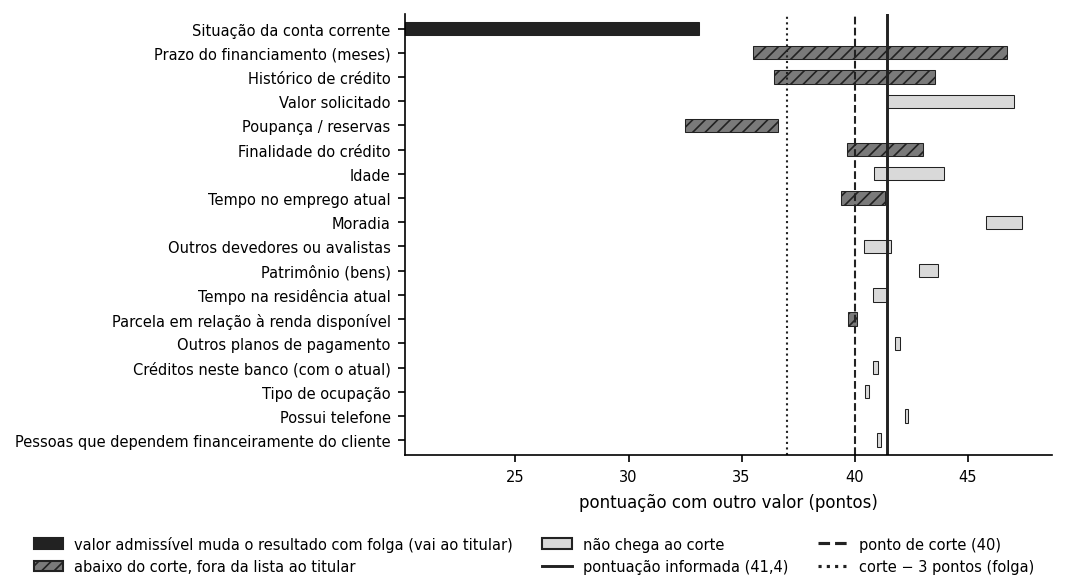

Legenda: faixa da pontuação do caso A quando cada campo assume outros valores plausíveis (admissíveis ou não), um campo por vez. A faixa cobre só os valores alternativos; a linha cheia é o valor informado, por isso a faixa pode não contê-lo. Preto: algum valor admissível passa no critério do componente 13 (folga de 3 pontos, 90% nos dois conjuntos de retreinos, regras) e o campo entra na lista do relatório. Hachurado: abaixo do corte, mas sem folga, sem robustez, só com valor não admissível (de associação contraintuitiva ou «sem informação», como «sem poupança ou desconhecida») ou com valor informado «sem informação» (fora da lista: o relatório pede para informar ao controlador). Simulação do modelo, não garantia; não é entregue ao titular.
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.

>>> Forma para titular (T): campos do caso A que, se errados, poderiam mudar o resultado


**Dados que vale conferir.** Na simulação, corrigir este dado, se estiver errado, pode mudar o resultado com margem segura, conforme o valor correto: situação da conta corrente. Se você tem poupança / reservas e isso não consta do cadastro, informe ao controlador; ele pode pedir documentos que confirmem.


>>> Forma para titular (T): campos do caso B que, se errados, poderiam mudar o resultado


**Dados que vale conferir.** Na simulação, corrigir este dado, se estiver errado, pode mudar o resultado com margem segura, conforme o valor correto: situação da conta corrente.

In [ ]:
exigir("casos", "pipe_final", "X_treino", "colunas_usadas", "categorias", "retreinos_semente", "retreinos_reamostra")

def fora_da_promessa(var, valor):
    """Valor que não sustenta promessa ao titular: «sem informação» (mesmo critério do componente 13, que não o usa como destino) ou de associação contraintuitiva."""
    chave = (var, str(valor))
    return chave in SEM_INFORMACAO or (chave in CONTRAINTUITIVAS and bool(nota_contraintuitiva(var, valor)))

def origem_mista(var, pessoa):
    """Valor INFORMADO que junta «não tem» e «não informou»: corrigir a partir dele seria só declarar um dado (componente 13, mesma regra)."""
    return (var, str(pessoa[var])) in SEM_INFORMACAO

def campos_para_titular(detalhe, pessoa=None):
    """Campos que vão ao relatório: algum valor ADMISSÍVEL passa no critério forte (folga, robustez, regras) e o valor informado não é categoria mista."""
    return [v for v, d in detalhe.items() if any(not fora_da_promessa(v, a) for a in d["com_folga"]) and not (pessoa is not None and origem_mista(v, pessoa))]

def frase_dados_errados(c, nivel=0):
    """Forma ao titular dos Dados possivelmente errados: os campos que, se errados, poderiam mudar o resultado (mesmo critério das simulações)."""
    sd = c.get("sensibilidade_dados", {})
    sens = sd.get("campos_contestaveis") or []
    if sens and nivel >= 3:
        dados = f"Se errado, corrigir {' ou '.join(ROTULOS_PT[v].lower() for v in sens)} pode mudar o resultado com margem segura (simulação)."
    elif sens and nivel >= 2:
        dados = f"Corrigir {'um destes dados' if len(sens) > 1 else 'este dado'}, se errado, pode mudar o resultado com margem segura (simulação): {lista_e(ROTULOS_PT[v].lower() for v in sens)}."
    elif sens:
        dados = (f"Na simulação, corrigir {'um destes dados' if len(sens) > 1 else 'este dado'}, se estiver errado, pode mudar o resultado com margem segura, conforme o valor correto: "
                 f"{lista_e(ROTULOS_PT[v].lower() for v in sens)}.")
    elif sd.get("campos_pontuacao"):
        dados = f"Na simulação, nenhum dado corrigido sozinho muda o resultado com margem segura; os que mais mudam a pontuação: {lista_e(ROTULOS_PT[v].lower() for v in sd['campos_pontuacao'])}."
    else:
        dados = "Na simulação, nenhum dado corrigido sozinho muda o resultado."
    mistos = sd.get("campos_origem_mista") or []      # valor atual junta «não tem» e «não informou»: corrigir é direito (art. 18, III), mas não se promete efeito
    if mistos:
        itens = " ou ".join(ROTULOS_PT[v].lower() for v in mistos)
        dados += (f" Se você tem {itens} e isso não consta do cadastro, informe ao controlador; ele pode pedir documentos que confirmem." if nivel < 3
                  else f" Se tem {itens} fora do cadastro, informe ao controlador.")
    return "**Dados que vale conferir.** " + dados

N_CAMPOS_PONTUACAO = 2      # sem campo que passe no critério forte: quantos campos de maior efeito na pontuação o relatório nomeia
TOL_SEM_EFEITO = 0.0005     # amplitude menor que 0,05 ponto: «sem efeito» (omitido da figura)

def desenhar_figura_6(chave):
    """Figura NB6: faixa da pontuação por campo. Preto = campos da lista ao titular (a MESMA lista do relatório: campos_contestaveis)."""
    c = ESTADO.casos[chave]
    sd = c["sensibilidade_dados"]
    det = sd["por_campo"]
    com_efeito = [v for v in det if det[v]["maximo"] - det[v]["minimo"] >= TOL_SEM_EFEITO or abs(det[v]["maximo"] - c["prob"]) >= TOL_SEM_EFEITO]
    sem_efeito = [v for v in det if v not in com_efeito]
    ordem = sorted(com_efeito, key=lambda v: det[v]["maximo"] - det[v]["minimo"])
    fig, ax = nova_figura(LARG_2COL, 0.75 + 0.17 * len(ordem))
    for i, v in enumerate(ordem):
        forte, fraco = v in sd["campos_contestaveis"], det[v]["pode_virar_decisao"]
        largura = max((det[v]["maximo"] - det[v]["minimo"]) * 100, 0.15)
        ax.barh(i, largura, left=det[v]["minimo"] * 100, height=0.55, color=COR_ESCURA if forte else (COR_NEUTRA if fraco else COR_CLARA),
                edgecolor=COR_ESCURA, linewidth=0.5, hatch="" if forte else ("////" if fraco else ""))
    ax.axvline(c["prob"] * 100, color=COR_ESCURA, linewidth=1.4)
    ax.axvline(LIMIAR_RISCO * 100, color=COR_ESCURA, linestyle="--", linewidth=1.0)
    ax.axvline((LIMIAR_RISCO - MARGEM_CONTRAFACTUAL) * 100, color=COR_ESCURA, linestyle=":", linewidth=1.0)
    ax.set_yticks(range(len(ordem)), [ROTULOS_PT[v] for v in ordem])
    ax.set_ylim(-0.6, len(ordem) - 0.4)
    ax.set_xlabel("pontuação com outro valor (pontos)")
    eixo_x_br(ax)
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    fig.legend([Patch(facecolor=COR_ESCURA, edgecolor=COR_ESCURA), Patch(facecolor=COR_NEUTRA, edgecolor=COR_ESCURA, hatch="////"),
                Patch(facecolor=COR_CLARA, edgecolor=COR_ESCURA), Line2D([], [], color=COR_ESCURA, linewidth=1.4),
                Line2D([], [], color=COR_ESCURA, linestyle="--"), Line2D([], [], color=COR_ESCURA, linestyle=":")],
               ["valor admissível muda o resultado com folga (vai ao titular)", "abaixo do corte, fora da lista ao titular", "não chega ao corte",
                f"pontuação informada ({br(c['prob'] * 100)})", f"ponto de corte ({br(LIMIAR_RISCO * 100, 0)})",
                f"corte − {br(MARGEM_CONTRAFACTUAL * 100, 0)} pontos (folga)"],
               loc="outside lower center", ncol=3, frameon=False)
    n_forte = len(sd["campos_contestaveis"])
    titulo = f"Caso {chave}: pontuação ao trocar um campo por outro valor admissível"
    legenda = (f"Legenda: faixa da pontuação do caso {chave} quando cada campo assume outros valores plausíveis (admissíveis ou não), um campo por vez. A faixa cobre só os valores alternativos; "
               "a linha cheia é o valor informado, por isso a faixa pode não contê-lo. Preto: algum valor admissível passa no critério do componente 13 (folga de "
               f"{br(MARGEM_CONTRAFACTUAL * 100, 0)} pontos, {pct(ROBUSTEZ_MIN, 0)} nos dois conjuntos de retreinos, regras) e o campo entra na lista do relatório. "
               "Hachurado: abaixo do corte, mas sem folga, sem robustez, só com valor não admissível (de associação contraintuitiva ou «sem informação», como «sem poupança ou desconhecida») "
               "ou com valor informado «sem informação» (fora da lista: o relatório pede para informar ao controlador). "
               + (f"Omitidos {len(sem_efeito)} campos sem efeito: {', '.join(ROTULOS_PT[v].lower() for v in sem_efeito)}. " if sem_efeito else "")
               + "Simulação do modelo, não garantia; não é entregue ao titular.")
    confere = bool({v for v in ordem if v in sd["campos_contestaveis"]} == set(sd["campos_contestaveis"]))
    return fig, titulo, legenda, confere

with Secao("Componente 14 – Dados possivelmente errados"):
    print("Cálculo de apoio (para E e A conferirem a lista); a forma do componente, ao titular, vem ao fim.")
    modelos_semente, modelos_reamostra = list(retreinos_semente), list(retreinos_reamostra)        # os mesmos do componente 13
    modelos_robustez = modelos_semente + modelos_reamostra
    for chave, c in ESTADO.casos.items():
        pessoa = c["caso_df"].iloc[0]
        linhas_df, origem = [], []
        for var in colunas_usadas:
            atual = pessoa[var]
            if var in categorias:
                alternativas = [a for a in categorias[var] if a != str(atual)]
            else:
                qs = np.unique(np.quantile(X_treino[var].astype(float), [.05, .25, .5, .75, .95]))
                inteiro = pd.api.types.is_integer_dtype(X_treino[var])
                alternativas = sorted({int(round(q)) if inteiro else float(q) for q in qs} - {valor_nativo(atual)})
            for a in alternativas:
                l = {col: valor_nativo(pessoa[col]) for col in colunas_usadas}
                l[var] = a
                linhas_df.append(l)
                origem.append((var, valor_nativo(a)))
        df_alt = pd.DataFrame(linhas_df, columns=colunas_usadas)
        probs_tudo = pipe_final.predict_proba(df_alt)[:, 1]
        frac_tudo = np.minimum((np.array([m.predict_proba(df_alt)[:, 1] for m in modelos_semente]) < LIMIAR_RISCO).mean(axis=0),      # a MENOR das duas frações (componente 13)
                               (np.array([m.predict_proba(df_alt)[:, 1] for m in modelos_reamostra]) < LIMIAR_RISCO).mean(axis=0))
        regras_tudo = np.array([decidir_por_regras(df_alt.iloc[k])[0] == "aprovado" for k in range(len(df_alt))])
        linhas, detalhe = [], {}
        for var in colunas_usadas:
            atual = pessoa[var]          # valor informado DESTE campo (o laço anterior deixava o da última coluna)
            idx = [k for k, (v, _) in enumerate(origem) if v == var]
            if not idx:
                continue
            alternativas = [origem[k][1] for k in idx]
            probs, frac, regras = probs_tudo[idx], frac_tudo[idx], regras_tudo[idx]
            forte = (probs < LIMIAR_RISCO - MARGEM_CONTRAFACTUAL) & (frac >= ROBUSTEZ_MIN) & regras       # MESMO critério do componente 13
            i_min, i_max = int(np.argmin(probs)), int(np.argmax(probs))
            nao_ci = [k for k, a in enumerate(alternativas) if not fora_da_promessa(var, a)]      # efeito na pontuação só com valores admissíveis
            detalhe[var] = dict(minimo=float(probs.min()), maximo=float(probs.max()), pode_virar_decisao=bool((probs < LIMIAR_RISCO).any()),
                                muda_com_folga=bool(forte.any()), alternativa_min=valor_nativo(alternativas[i_min]),
                                abaixo_do_corte=[a for a, p_ in zip(alternativas, probs) if p_ < LIMIAR_RISCO],
                                com_folga=[a for a, f_ in zip(alternativas, forte) if f_],
                                efeito_max=float(max([abs(probs[k] - c["prob"]) for k in nao_ci], default=0.0)))
            linhas.append({"campo": ROTULOS_PT[var], "valor informado": valor_com_unidade(var, atual),
                           "menor pontuação com outro valor": f"{br(probs.min() * 100)} ({valor_legivel(var, alternativas[i_min])})",
                           "maior pontuação com outro valor": f"{br(probs.max() * 100)} ({valor_legivel(var, alternativas[i_max])})",
                           "(a) abaixo do corte?": "sim" if detalhe[var]["pode_virar_decisao"] else "não",
                           f"(b) muda o resultado com folga (≥ {br(MARGEM_CONTRAFACTUAL * 100, 0)} pontos, ≥ {pct(ROBUSTEZ_MIN, 0)} nos dois conjuntos de retreinos, regras)?": "sim" if detalhe[var]["muda_com_folga"] else "não",
                           "(c) com valor admissível (vai ao titular)?": ("não (valor informado misto)" if origem_mista(var, pessoa) and detalhe[var]["muda_com_folga"]
                                                                          else "sim" if any(not fora_da_promessa(var, a) for a in detalhe[var]["com_folga"]) else "não"),
                           "_amplitude": probs.max() - probs.min()})
        tab = pd.DataFrame(linhas).sort_values("_amplitude", ascending=False).drop(columns="_amplitude").reset_index(drop=True)
        campos_decisivos = [v for v, d in detalhe.items() if d["pode_virar_decisao"]]
        # Ao titular, «muda o resultado» só com o critério forte e valor admissível: nem «sem informação» (ex.: «sem poupança ou desconhecida») nem contraintuitivo (por exemplo, «imóvel», com inadimplência acima da geral)
        campos_contestaveis = campos_para_titular(detalhe, pessoa)
        # valor informado misto que mudaria o resultado com folga: sem promessa; o relatório pede para informar ao controlador (M2)
        campos_origem_mista = [v for v, d in detalhe.items() if origem_mista(v, pessoa) and any(not fora_da_promessa(v, a) for a in d["com_folga"])]
        campos_pontuacao = sorted((v for v in detalhe if not origem_mista(v, pessoa)), key=lambda v: -detalhe[v]["efeito_max"])[:N_CAMPOS_PONTUACAO]
        c["sensibilidade_dados"] = dict(por_campo=detalhe, campos_decisivos=campos_decisivos, campos_contestaveis=campos_contestaveis, campos_origem_mista=campos_origem_mista,
                                        campos_pontuacao=campos_pontuacao, n_modelos_robustez=len(modelos_robustez))
        print(f"\n===== Caso {chave}: pontuação atual {pts(c['prob'])}; corte {pts(LIMIAR_RISCO, 0)} =====")
        if chave == "A":
            mostrar_14b = tab[(tab.index < 8) | (tab["(a) abaixo do corte?"] == "sim")]
            print(f"Campos de maior amplitude e todos os que podem levar abaixo do corte ({len(mostrar_14b)} de {len(tab)}):")
            display(mostrar_14b)
        print("(a) Algum valor alternativo (isolado) leva a pontuação abaixo do corte:", ", ".join(ROTULOS_PT[v] for v in campos_decisivos) if campos_decisivos else "nenhum")
        print("(b) Algum valor muda o resultado com folga (critério do componente 13):", ", ".join(ROTULOS_PT[v] for v, d in detalhe.items() if d["muda_com_folga"]) or "nenhum")
        print("(c) ... com valor admissível, e vai ao relatório:", ", ".join(ROTULOS_PT[v] for v in campos_contestaveis) if campos_contestaveis else "nenhum")
        for v in campos_origem_mista:
            print(f"  Valor informado misto em «{ROTULOS_PT[v]}» («{valor_legivel(v, pessoa[v])}»): outro valor mudaria o resultado com folga, mas corrigir a partir da ausência seria só declarar; "
                  "o relatório não promete efeito e pede para informar ao controlador.")
        for v, d in detalhe.items():
            so_sem_info = [a for a in d["com_folga"] if (v, str(a)) in SEM_INFORMACAO]
            if so_sem_info and v not in campos_contestaveis:
                print(f"  Nota: em «{ROTULOS_PT[v]}», só «{valor_legivel(v, so_sem_info[0])}» muda o resultado com folga; o valor junta «não tem» e «não se sabe» e fica fora da lista ao titular.")
        if not campos_contestaveis:
            print("   O relatório diz que nenhum dado corrigido sozinho muda o resultado com folga e nomeia os campos que mais mudam a pontuação:",
                  ", ".join(ROTULOS_PT[v] for v in campos_pontuacao))
        for var, cat in sorted(CONTRAINTUITIVAS):
            if var in campos_decisivos and str(detalhe[var]["alternativa_min"]) == cat and nota_contraintuitiva(var, cat):
                print(f"  Nota: o valor que mais reduz a pontuação em «{ROTULOS_PT[var]}» é «{valor_legivel(var, cat)}». {nota_contraintuitiva(var, cat)}")
        fracos = [v for v in campos_decisivos if v not in campos_contestaveis]
        print("Abaixo do corte, mas sem folga, sem robustez, só com valor não admissível ou com valor informado misto (fora da promessa ao titular):", ", ".join(ROTULOS_PT[v] for v in fracos) if fracos else "nenhum")

    fig, titulo_s, legenda_s, confere_s = desenhar_figura_6("A")
    # L7: os campos em preto são exatamente os que o relatório ao titular promete
    figura(6, "sensibilidade_dos_dados", fig, titulo_s, legenda_s, "E, A", confere_texto=confere_s)

    for chave, c in ESTADO.casos.items():
        forma("T", f"campos do caso {chave} que, se errados, poderiam mudar o resultado")
        display(Markdown(frase_dados_errados(c)))

### Componente 15 — Direito e meio para solicitar revisão

**O que é.** O direito de solicitar a revisão da decisão [Brasil 2018, art. 20, caput], a informação de que ele existe e a indicação de um meio para exercê-lo. A lei garante o direito sem fixar o canal. O encarregado, a quem cabe aceitar reclamações e comunicações dos titulares [Brasil 2018, art. 41, § 2º, I], é escolha de projeto compatível com esse dispositivo, que trata do atendimento aos titulares em geral e não cria canal próprio para a revisão de decisões automatizadas. Ao titular, informa-se como e a quem pedir a revisão. **O resultado em si não é componente: é o que os demais explicam**; por isso ele aparece aqui e na Inferência, junto do meio para pedir a revisão.

**Classe, público e LGPD.** **Obrigatório** (direito, informação sobre ele e indicação de um meio de exercê-lo; P2c) · T · art. 20, caput (direito). O canal específico (formulário próprio, fluxo interno) é implementação recomendada, e não exigência do dispositivo; que informar o direito e indicar um meio seja devido ao titular é interpretação deste trabalho. Se a decisão não é unicamente automatizada ou não afeta os interesses do titular (P1), o direito de revisão do art. 20 não se aplica àquele caso. A hipótese D1 (Seção 3.1) admite que a participação humana efetiva na decisão final pode afastar a caracterização de decisão unicamente automatizada; o simples encaminhamento à revisão não comprova essa participação, e este notebook não executa a revisão. Por isso o relatório do caso A cita os arts. 19 e 20 e o art. 18 e não afirma que a revisão foi efetiva.

**Neste notebook.** O canal é **fictício** (`[CANAL FICTÍCIO DE REVISÃO]`), dirigido ao encarregado. O encaminhamento dos casos instáveis à revisão humana, **antes** da decisão, é regra de projeto, **simulada** (componente 6): a revisão não é executada e o desfecho não é reproduzido. Ele não substitui o canal, que serve para pedir a revisão **depois** da decisão. O mesmo meio é indicado para pedidos de revisão e de correção de dados, como escolha de implementação, sem que isso seja exigência da LGPD.

#### Relatório ao titular

O relatório reúne, para cada caso, as formas ao titular dos seis componentes **obrigatórios do manual** — Inferência, Regras de negócio, Limiar de decisão, Fatores da decisão, Dados individuais do titular e Direito e meio para solicitar revisão — e dos **recomendáveis com o titular no público** — Alterações possíveis e Dados possivelmente errados —, cada bloco com o nome do componente entre colchetes no código. É montado por um modelo de frase com lacunas (preenchido pelo código, sem geração de texto livre), fiel aos números. A meta é de **até 350 palavras** no texto; o aviso «modelo ilustrativo» e a tabela dos dados (componente 11, em **anexo**) ficam fora da contagem, a tabela porque é entregue mediante requerimento e tem tamanho fixo. Acima da meta, o código encurta frases em até três níveis, sem tirar nenhum componente. As informações são devidas sempre que solicitadas [Brasil 2018, art. 20, § 1º]; entregar o relatório sem pedido, como aqui, é boa prática. O caso A é encaminhado à revisão humana, o que é simulado. Se a participação humana fosse efetiva (hipótese D1), o art. 20 poderia não incidir, e Regras de negócio, Limiar de decisão, Fatores da decisão e Dados individuais continuariam devidos, mediante requerimento, pelos arts. 18 e 19; sem participação efetiva, os seis seriam devidos. O relatório do caso A cita os arts. 19 e 20 e o art. 18, não afirma que a revisão foi efetiva e mantém todos os blocos.

In [ ]:
exigir("casos")

# JARGOES (lista de termos técnicos) é definida na Seção 0 e vale também para o critério L2 das figuras
CANAL_REVISAO = "[CANAL FICTÍCIO DE REVISÃO]"
MAX_PALAVRAS_RELATORIO = 350

def cabecalho_resultado(c, nivel=0):
    """O resultado (não é componente: é o que os demais explicam). Reprovado instável é encaminhado (simulado) à revisão humana ANTES da decisão final."""
    if c["decisao_regras"] != "aprovado":
        return frase_regra_titular(c["motivos_regras"])          # o mesmo texto do exemplo do componente 1
    if c.get("em_revisao_humana"):
        return ("**Resultado: encaminhado à revisão humana.** A inteligência artificial indicou reprovação, mas esse resultado mudou entre novos treinos do modelo; "
                "o pedido é encaminhado a uma pessoa antes da decisão final." if nivel < 3 else "**Resultado: encaminhado à revisão humana** (reprovação indicada pela inteligência artificial, instável).")
    return f"**Resultado: crédito {c['decisao']}.** Decisão automática, tomada pela inteligência artificial."

def frase_canal(c, nivel=0):
    """Forma ao titular do Direito e meio para solicitar revisão: como e a quem pedir a revisão (o canal é fictício)."""
    quando = "Depois da decisão final, se discordar, você pode pedir" if c.get("em_revisao_humana") else "Você pode pedir"
    base = f"{quando} a revisão pelo canal {CANAL_REVISAO}, dirigido ao encarregado de dados pessoais."
    # ramo único: o art. 20 é citado em todos os casos; D1 é hipótese e o encaminhamento simulado não comprova participação humana efetiva
    extra = (" Pelo mesmo canal, peça informações sobre os critérios e procedimentos (arts. 19 e 20 da LGPD), acesso aos seus dados e correção dos que estiverem errados (art. 18)."
             if nivel < 3 else " Ali também se pedem os critérios (arts. 19 e 20 da LGPD) e a correção de dados (art. 18).")
    return "**Como pedir revisão.** " + base + extra

def frase_dados_individuais(c, nivel=0):
    """Forma ao titular dos Dados individuais: a tabela vai em anexo; o texto diz quantos campos, quais não são usados e a origem (art. 19, II)."""
    d = c["dados_individuais"]
    vedados = [r["campo"].lower() for _, r in d.iterrows() if r["uso"].startswith("no cadastro")]
    usados = len(d) - len(vedados)
    if nivel >= 2:
        return f"**Seus dados.** Estão no anexo ({len(d)} campos; {usados} usados, {len(vedados)} guardados sem uso). Origem: informados no pedido (aqui, base pública antiga)."
    return (f"**Seus dados.** Os {len(d)} dados do seu cadastro estão no anexo: {usados} foram usados na decisão, e {len(vedados)} ({lista_e(vedados)}) ficam no cadastro sem uso. "
            "Origem: informados no pedido de crédito (aqui, uma linha de base pública antiga).")

def relatorio_titular(chave, nivel=0):
    """Relatório ao titular (Markdown) gerado SÓ do ESTADO; nenhum número é digitado. Devolve (texto, anexo).
    Blocos, na ordem: resultado; [Inferência]; [Regras de negócio]; [Limiar de decisão]; [Fatores da decisão]; [Dados individuais do titular];
    [Alterações possíveis]; [Dados possivelmente errados]; [Direito e meio para solicitar revisão]. `nivel` 1 a 3 encurta frases, sem tirar nenhum bloco."""
    c = ESTADO.casos[chave]
    pessoa = c["caso_df"].iloc[0]
    L = ["# Relatório de explicação da decisão", "", cabecalho_resultado(c, nivel), ""]
    L.append("**Como o sistema decide.** " + frase_procedimento(c, nivel))                                   # [Inferência]
    if c["decisao_regras"] == "aprovado":
        L.append("\n**Regras aplicadas ao seu pedido.** " + frase_regras_nao_acionadas(pessoa, curto=nivel >= 1))  # [Regras de negócio]
        L.append("\n**Ponto de corte e sua pontuação.** " + frase_limiar_titular(c["prob"], curto=True))          # [Limiar de decisão]
        L.append("\n" + "\n".join(bloco_fatores(c, nivel)))                                                   # [Fatores da decisão]
    L.append("\n" + frase_dados_individuais(c, nivel))                                                        # [Dados individuais do titular]
    if c["decisao_regras"] == "aprovado":
        L.append("\n" + frase_alteracoes(c, nivel))                                                           # [Alterações possíveis]
    L.append("\n" + frase_dados_errados(c, nivel))                                                            # [Dados possivelmente errados]
    L.append("\n" + frase_canal(c, nivel))                                                                    # [Direito e meio para solicitar revisão]
    d = c["dados_individuais"]
    anexo = ("**Anexo — seus dados** (campo, valor, unidade ou escala, uso)\n\n"
             + tabela_markdown(["campo", "valor", "unidade ou escala", "uso"], d[["campo", "valor", "unidade ou escala", "uso"]].values.tolist()))
    return "\n".join(L), anexo

BLOCOS_TITULAR = {"Inferência": "**Como o sistema decide.**", "Regras de negócio": "**Regras aplicadas ao seu pedido.**",
                  "Limiar de decisão": "**Ponto de corte e sua pontuação.**", "Fatores da decisão": "**Principais fatores**",
                  "Dados individuais do titular": "**Seus dados.**", "Alterações possíveis": "**O que poderia",
                  "Dados possivelmente errados": "**Dados que vale conferir.**", "Direito e meio para solicitar revisão": "**Como pedir revisão.**"}

def contar_palavras(t):
    return len(re.findall(r"\w+", t))

with Secao("Componente 15 – Direito e meio para solicitar revisão e relatório ao titular"):
    forma("T", "como e a quem pedir a revisão, com o resultado: trechos «Resultado» e «Como pedir revisão» de cada relatório abaixo")

    for chave, c in ESTADO.casos.items():
        texto, anexo = relatorio_titular(chave)
        n_palavras, nivel_usado = contar_palavras(texto), 0
        for nivel in (1, 2, 3):                         # acima da meta: encurta em até três níveis; nenhum bloco é retirado
            if n_palavras <= MAX_PALAVRAS_RELATORIO:
                break
            texto, anexo = relatorio_titular(chave, nivel)
            n_palavras, nivel_usado = contar_palavras(texto), nivel
        c["relatorio_nivel"] = nivel_usado
        m_conta = re.search(r"Conta: (-?\d+,\d) ([+-]\d+,\d) ([+-]\d+,\d) = (-?\d+,\d) pontos", texto)
        conferir(f"relatorio_{chave}_conta_fecha_no_texto", m_conta is not None and
                 sum(int(g.replace(",", "")) for g in m_conta.groups()[:3]) == int(m_conta.group(4).replace(",", "")), "a soma exibida deve ser igual à pontuação exibida")
        achados = [j for j in JARGOES if j in (texto + anexo).lower()]
        conferir(f"relatorio_{chave}_sem_jargao", not achados, f"termos técnicos no relatório: {achados}")
        faltam_blocos = [k for k, marca in BLOCOS_TITULAR.items() if marca not in texto]
        conferir(f"relatorio_{chave}_cita_arts_18_19_20", "19 e 20" in texto and "art. 18" in texto,
                 "o relatório deve citar os arts. 19 e 20 e o art. 18 e não afirmar que a revisão humana foi efetiva (D1 é hipótese)")
        conferir(f"relatorio_{chave}_tem_os_componentes_do_titular", not faltam_blocos, f"faltam: {faltam_blocos}")
        obrig_t = {m["componente"] for m in MANUAL if m["classe"] == "O"}
        conferir(f"relatorio_{chave}_cobre_os_obrigatorios", obrig_t <= set(BLOCOS_TITULAR), "todo obrigatório deve ter bloco no relatório")
        print(f"\n########## Relatório do caso {chave}: {n_palavras} palavras no texto (meta: até {MAX_PALAVRAS_RELATORIO}; nível de compactação {nivel_usado}); o aviso «modelo ilustrativo» e o anexo ficam fora da contagem ##########\n")
        aviso = f"> MODELO ILUSTRATIVO: base pública, sem relação com instituição real; não é parecer jurídico. Caso: linha {c['indice_original']} da base. A revisão humana descrita é simulada."
        display(Markdown(aviso + "\n\n" + texto + "\n\n" + anexo))
        ESTADO.checks[f"relatorio_{chave}_curto"] = n_palavras <= MAX_PALAVRAS_RELATORIO   # meta de redação: registra, não interrompe
        if n_palavras > MAX_PALAVRAS_RELATORIO:
            print(f"AVISO: relatório {chave} com {n_palavras} palavras, acima da meta de {MAX_PALAVRAS_RELATORIO}.")
        c.update(relatorio_titular=texto, relatorio_anexo=anexo, relatorio_palavras=n_palavras)


>>> Forma para titular (T): como e a quem pedir a revisão, com o resultado: trechos «Resultado» e «Como pedir revisão» de cada relatório abaixo

########## Relatório do caso A: 347 palavras no texto (meta: até 350; nível de compactação 3); o aviso «modelo ilustrativo» e o anexo ficam fora da contagem ##########



> MODELO ILUSTRATIVO: base pública, sem relação com instituição real; não é parecer jurídico. Caso: linha 889 da base. A revisão humana descrita é simulada.

# Relatório de explicação da decisão

**Resultado: encaminhado à revisão humana** (reprovação indicada pela inteligência artificial, instável).

**Como o sistema decide.** Regras de prazo e valor; se nenhuma reprova, como aqui, um modelo dá uma pontuação (0 a 100) que reprova com 40 ou mais; reprovação instável é encaminhada a uma pessoa, como aqui.

**Regras aplicadas ao seu pedido.** Nenhuma reprovou: prazo de 24 meses (reprova acima de 36); valor de 2.439 DM (reprova acima de 8.000).

**Ponto de corte e sua pontuação.** 41,4 pontos, 1,4 acima do corte de 40 (hipotético); não é probabilidade.

**Principais fatores** (associações do sistema, não causas). Ponto de partida (média do modelo nos pedidos antigos): 30,1 pontos.
- Situação da conta corrente: sem conta corrente (+10,5 pontos).
- Poupança / reservas: sem poupança ou desconhecida (+2,5 pontos).
- Moradia: alugada (-1,6 pontos).
- Patrimônio (bens): sem bens ou desconhecidos (-1,3 pontos).
- Histórico de crédito: sem créditos ou todos pagos em dia (+1,2 pontos); pesa porque não está no grupo «todos os créditos neste banco pagos em dia» (17% não pagaram).
- Outras 13 informações, somadas: +0,0 pontos.

Conta: 30,1 +11,3 +0,0 = 41,4 pontos.
Nota: em poupança / reservas e patrimônio (bens), a categoria junta quem não tem e quem não informou (37% e 20% não pagaram).

**Seus dados.** Estão no anexo (20 campos; 18 usados, 2 guardados sem uso). Origem: informados no pedido (aqui, base pública antiga).

**O que poderia mudar o resultado** (simulação, não garantia). Nenhuma das mudanças testadas (prazo do financiamento, valor solicitado e outros devedores ou avalistas) baixa a pontuação com margem segura e de forma estável.

**Dados que vale conferir.** Se errado, corrigir situação da conta corrente pode mudar o resultado com margem segura (simulação). Se tem poupança / reservas fora do cadastro, informe ao controlador.

**Como pedir revisão.** Depois da decisão final, se discordar, você pode pedir a revisão pelo canal [CANAL FICTÍCIO DE REVISÃO], dirigido ao encarregado de dados pessoais. Ali também se pedem os critérios (arts. 19 e 20 da LGPD) e a correção de dados (art. 18).

**Anexo — seus dados** (campo, valor, unidade ou escala, uso)

| campo | valor | unidade ou escala | uso |
| --- | --- | --- | --- |
| Situação da conta corrente | sem conta corrente | categoria (faixas de saldo, DM; inclui «sem conta corrente») | usada pelo modelo |
| Prazo do financiamento (meses) | 24 meses | meses | usada pelas regras e pelo modelo |
| Histórico de crédito | sem créditos ou todos pagos em dia | categoria | usada pelo modelo |
| Finalidade do crédito | móveis ou equipamentos | categoria | usada pelo modelo |
| Valor solicitado | 2.439 DM | marcos alemães (DM) | usada pelas regras e pelo modelo |
| Poupança / reservas | sem poupança ou desconhecida | categoria (faixas de saldo, DM; inclui «sem poupança ou desconhecida») | usada pelo modelo |
| Tempo no emprego atual | menos de 1 ano | categoria | usada pelo modelo |
| Parcela em relação à renda disponível | menos de 20% da renda disponível | faixa da parcela em % da renda disponível (4 faixas) | usada pelo modelo |
| Estado civil e sexo (rótulo da base) | mulher não solteira ou homem solteiro | categoria; VEDADA no modelo (Regras de negócio); sexo só parcialmente recuperável (Desempenho por grupos) | no cadastro, não usada (vedada) |
| Outros devedores ou avalistas | nenhum | categoria | usada pelo modelo |
| Tempo na residência atual | 7 anos ou mais | faixa de anos (4 faixas) | usada pelo modelo |
| Patrimônio (bens) | sem bens ou desconhecidos | categoria | usada pelo modelo |
| Idade | 35 anos | anos | usada pelo modelo |
| Outros planos de pagamento | nenhum | categoria | usada pelo modelo |
| Moradia | alugada | categoria | usada pelo modelo |
| Créditos neste banco (com o atual) | 1 crédito | faixa de quantidade (1; 2 ou 3; 4 ou 5; 6 ou mais) | usada pelo modelo |
| Tipo de ocupação | qualificado | categoria | usada pelo modelo |
| Pessoas que dependem financeiramente do cliente | de 0 a 2 pessoas | faixa (0 a 2; 3 ou mais) | usada pelo modelo |
| Possui telefone | sim, em nome do cliente | categoria | usada pelo modelo |
| Trabalhador estrangeiro | não | categoria; VEDADA no modelo (Regras de negócio); auditada em Desempenho por grupos (n pequeno) | no cadastro, não usada (vedada) |


########## Relatório do caso B: 337 palavras no texto (meta: até 350; nível de compactação 3); o aviso «modelo ilustrativo» e o anexo ficam fora da contagem ##########



> MODELO ILUSTRATIVO: base pública, sem relação com instituição real; não é parecer jurídico. Caso: linha 23 da base. A revisão humana descrita é simulada.

# Relatório de explicação da decisão

**Resultado: crédito reprovado.** Decisão automática, tomada pela inteligência artificial.

**Como o sistema decide.** Regras de prazo e valor; se nenhuma reprova, como aqui, um modelo dá uma pontuação (0 a 100) que reprova com 40 ou mais; reprovação instável é encaminhada a uma pessoa.

**Regras aplicadas ao seu pedido.** Nenhuma reprovou: prazo de 36 meses (reprova acima de 36); valor de 2.384 DM (reprova acima de 8.000).

**Ponto de corte e sua pontuação.** 47,0 pontos, 7,0 acima do corte de 40 (hipotético); não é probabilidade.

**Principais fatores** (associações do sistema, não causas). Ponto de partida (média do modelo nos pedidos antigos): 30,1 pontos.
- Moradia: cedida (+4,5 pontos).
- Situação da conta corrente: saldo negativo (+3,7 pontos).
- Prazo do financiamento: 36 meses (+3,6 pontos).
- Poupança / reservas: sem poupança ou desconhecida (+2,3 pontos).
- Patrimônio (bens): imóvel (+1,4 pontos).
- Outras 13 informações, somadas: +1,4 pontos.

Conta: 30,1 +15,5 +1,4 = 47,0 pontos.
Nota: em poupança / reservas, a categoria junta quem não tem e quem não informou (37% não pagaram).
Nota: no histórico, 43% do grupo «imóvel» (122 casos) não pagou; o sistema aprendeu essa associação desta base antiga, mas «imóvel» não é, em si, sinal de mau pagamento.

**Seus dados.** Estão no anexo (20 campos; 18 usados, 2 guardados sem uso). Origem: informados no pedido (aqui, base pública antiga).

**O que poderia mudar o resultado** (simulação, não garantia). Situação da conta corrente: de saldo negativo para saldo de 200 DM ou mais, ou salário há 1 ano ou mais: 31,5 pontos, abaixo do corte em 97% de 30 novos treinos com outros dados.

**Dados que vale conferir.** Se errado, corrigir situação da conta corrente pode mudar o resultado com margem segura (simulação).

**Como pedir revisão.** Você pode pedir a revisão pelo canal [CANAL FICTÍCIO DE REVISÃO], dirigido ao encarregado de dados pessoais. Ali também se pedem os critérios (arts. 19 e 20 da LGPD) e a correção de dados (art. 18).

**Anexo — seus dados** (campo, valor, unidade ou escala, uso)

| campo | valor | unidade ou escala | uso |
| --- | --- | --- | --- |
| Situação da conta corrente | saldo negativo | categoria (faixas de saldo, DM; inclui «sem conta corrente») | usada pelo modelo |
| Prazo do financiamento (meses) | 36 meses | meses | usada pelas regras e pelo modelo |
| Histórico de crédito | sem créditos ou todos pagos em dia | categoria | usada pelo modelo |
| Finalidade do crédito | eletrodoméstico | categoria | usada pelo modelo |
| Valor solicitado | 2.384 DM | marcos alemães (DM) | usada pelas regras e pelo modelo |
| Poupança / reservas | sem poupança ou desconhecida | categoria (faixas de saldo, DM; inclui «sem poupança ou desconhecida») | usada pelo modelo |
| Tempo no emprego atual | menos de 1 ano | categoria | usada pelo modelo |
| Parcela em relação à renda disponível | menos de 20% da renda disponível | faixa da parcela em % da renda disponível (4 faixas) | usada pelo modelo |
| Estado civil e sexo (rótulo da base) | homem casado ou viúvo | categoria; VEDADA no modelo (Regras de negócio); sexo só parcialmente recuperável (Desempenho por grupos) | no cadastro, não usada (vedada) |
| Outros devedores ou avalistas | nenhum | categoria | usada pelo modelo |
| Tempo na residência atual | menos de 1 ano | faixa de anos (4 faixas) | usada pelo modelo |
| Patrimônio (bens) | imóvel | categoria | usada pelo modelo |
| Idade | 33 anos | anos | usada pelo modelo |
| Outros planos de pagamento | nenhum | categoria | usada pelo modelo |
| Moradia | cedida | categoria | usada pelo modelo |
| Créditos neste banco (com o atual) | 1 crédito | faixa de quantidade (1; 2 ou 3; 4 ou 5; 6 ou mais) | usada pelo modelo |
| Tipo de ocupação | não qualificado, residente | categoria | usada pelo modelo |
| Pessoas que dependem financeiramente do cliente | de 0 a 2 pessoas | faixa (0 a 2; 3 ou mais) | usada pelo modelo |
| Possui telefone | não | categoria | usada pelo modelo |
| Trabalhador estrangeiro | não | categoria; VEDADA no modelo (Regras de negócio); auditada em Desempenho por grupos (n pequeno) | no cadastro, não usada (vedada) |

### Componente 16 — Registro da decisão

**O que é.** O registro de cada decisão tomada. A LGPD exige do controlador e do operador o registro das operações de tratamento de dados pessoais [Brasil 2018, art. 37], sem especificar um registro por decisão. Arquiteturas de MLOps preveem um componente que registra as ações do sistema, inclusive os pedidos dos usuários e as previsões [Amou Najafabadi et al. 2024, Tabela 2]. Tomar a previsão registrada como decisão é leitura do TCC, e **o conteúdo de cada registro é proposta deste trabalho**.

**Classe, público e LGPD.** **Recomendável** (não é meio de o titular pedir a revisão: é condição para o controlador responder aos pedidos dos arts. 18 e 20, e não meio para o titular solicitar) · E, N, A · art. 37 (por extensão deste trabalho). Na prática, sem ele não é possível cumprir os componentes obrigatórios depois de um retreinamento.

**Neste notebook.** Os 200 pedidos do conjunto de teste são tratados como **pedidos simulados** (são linhas históricas, não pedidos reais) e passam pelo mesmo procedimento da Inferência. Cada decisão gera um registro com: identificador; data e hora (UTC, momento da execução desta simulação, e não a data do crédito original); versões do modelo, da base e do esquema; limiar e regras vigentes; dados de entrada e o *hash* SHA-256 deles; regras acionadas; pontuação; decisão do modelo; estabilidade; se foi encaminhado à revisão humana (simulado); resultado; e os três fatores de maior peso (quando o modelo decidiu). Os registros são gravados em `saidas/registro_decisoes.jsonl` (um JSON por linha) e `saidas/registro_decisoes.csv`. O registro guarda dados pessoais em claro; por isso ele mesmo é um tratamento sujeito a medidas de segurança e a acesso restrito. Formas: **E**, o esquema; **N**, a contagem por resultado; **A**, a reconstrução de uma decisão a partir do registro.

In [ ]:
exigir("casos", "X_teste", "prob_teste", "regras_teste", "classe_estab_teste", "mantida_semente", "mantida_reamostra", "shap_teste", "mapa_variavel",
       "versao_modelo", "dados_info", "colunas_usadas")

VERSAO_ESQUEMA_REGISTRO = "1.0"     # esquema proposto por este trabalho

def sha256_entrada(entrada):
    """Hash SHA-256 dos dados de entrada, em JSON canônico (chaves ordenadas): identifica exatamente o que o sistema recebeu."""
    return sha256_bytes(json.dumps(entrada, sort_keys=True, ensure_ascii=False).encode("utf-8"))

def montar_registro(indice, entrada, motivos, pontuacao, estab, phi_var, momento):
    """Um registro de decisão (conteúdo proposto por este trabalho). `pontuacao` = None quando uma regra reprovou (o modelo não é usado)."""
    if motivos:
        resultado, dec_modelo, em_revisao = "reprovado por regra", None, False
    else:
        dec_modelo = aplicar_limiar(pontuacao)
        em_revisao = dec_modelo == "reprovado" and estab["classe"] == "instável"
        resultado = ("encaminhado à revisão humana" if em_revisao else "reprovado pelo modelo") if dec_modelo == "reprovado" else "aprovado"
    fatores = None
    if phi_var is not None and not motivos:
        top3 = phi_var.reindex(phi_var.abs().sort_values(ascending=False).index[:3])
        fatores = [dict(variavel=v, contribuicao_pontos=round(float(p) * 100, 2)) for v, p in top3.items()]
    return dict(
        id_decisao="dec-" + sha256_bytes(f"{indice}|{momento}|{ESTADO.versao_modelo}".encode())[:12], data_hora_utc=momento,
        versao_esquema=VERSAO_ESQUEMA_REGISTRO, versao_modelo=ESTADO.versao_modelo, sha256_base=ESTADO.dados_info["sha256_asc"],
        limiar=LIMIAR_RISCO, regras_vigentes=list(REGRAS_TEXTO), id_pedido=int(indice),
        entrada=entrada, sha256_entrada=sha256_entrada(entrada), regras_acionadas=list(motivos),
        pontuacao=(None if motivos else round(float(pontuacao), 6)), decisao_modelo=dec_modelo,
        estabilidade=(None if (motivos or dec_modelo != "reprovado") else dict(classe=estab["classe"], mantida_semente=round(estab["ms"], 4), mantida_reamostra=round(estab["mr"], 4))),
        em_revisao_humana=bool(em_revisao), resultado=resultado, fatores_principais=fatores, canal_de_revisao_informado=CANAL_REVISAO)

with Secao("Componente 16 – Registro da decisão"):
    momento = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")
    shap_var = pd.DataFrame(shap_teste).T.groupby(mapa_variavel).sum().T
    registros = []
    for i in range(len(X_teste)):
        entrada = {col: valor_nativo(X_teste.iloc[i][col]) for col in colunas_usadas}
        _, motivos = ESTADO.regras_teste[i]
        estab = dict(classe=ESTADO.classe_estab_teste[i], ms=float(mantida_semente[i]), mr=float(mantida_reamostra[i]))
        registros.append(montar_registro(X_teste.index[i], entrada, motivos, float(prob_teste[i]), estab, shap_var.iloc[i], momento))
    caminho_jsonl, caminho_csv = os.path.join(PASTA_SAIDAS, "registro_decisoes.jsonl"), os.path.join(PASTA_SAIDAS, "registro_decisoes.csv")
    with open(caminho_jsonl, "w", encoding="utf-8") as arq:
        for r in registros:
            arq.write(json.dumps(r, ensure_ascii=False) + "\n")
    planos = [{k: (json.dumps(v, ensure_ascii=False) if isinstance(v, (dict, list)) else v) for k, v in r.items()} for r in registros]
    with open(caminho_csv, "w", encoding="utf-8", newline="") as arq:
        w = csv.DictWriter(arq, fieldnames=list(planos[0]))
        w.writeheader()
        w.writerows(planos)
    print(f"{len(registros)} registros gravados em {caminho_jsonl} e {caminho_csv} (pedidos SIMULADOS: linhas do conjunto de teste).")

    # Coerência: o registro dos casos A e B coincide com o procedimento da Inferência aplicado a eles
    por_id = {r["id_pedido"]: r for r in registros}
    for chave, c in ESTADO.casos.items():
        r = por_id[c["indice_original"]]
        conferir(f"registro_{chave}_coerente_com_inferencia", r["resultado"].split(" (")[0] == c["resultado"].split(" (")[0]
                 and abs(r["pontuacao"] - c["prob"]) < 1e-6 and r["em_revisao_humana"] == c["em_revisao_humana"], f"{r['resultado']} x {c['resultado']}")

    conferir("registro_revisao_igual_componente_6", sum(r["em_revisao_humana"] for r in registros) == ESTADO.estabilidade_global["revisao_sistema"]["n"],
             "a carga de revisão do registro deve ser a mesma do componente 6 (fluxo do sistema)")
    forma("E", "esquema do registro (campos, tipo e exemplo do caso A)")
    rA = por_id[ESTADO.casos["A"]["indice_original"]]
    display(pd.DataFrame([{"campo": k, "tipo": type(v).__name__ if v is not None else "nulo",
                           "exemplo (caso A)": (json.dumps(v, ensure_ascii=False)[:90] + ("…" if len(json.dumps(v, ensure_ascii=False)) > 90 else "")) if isinstance(v, (dict, list)) else v}
                          for k, v in rA.items()]))

    forma("N", "contagem das decisões por resultado (lote simulado)")
    cont = pd.Series([r["resultado"] for r in registros]).value_counts()
    display(pd.DataFrame({"resultado": cont.index, "decisões": cont.values, "fração": [pct(v / len(registros), 0) for v in cont.values]}))

    forma("A", "reconstrução de uma decisão a partir do registro gravado")
    lido = next(json.loads(l) for l in open(caminho_jsonl, encoding="utf-8") if json.loads(l)["id_pedido"] == rA["id_pedido"])
    hash_ok = sha256_entrada(lido["entrada"]) == lido["sha256_entrada"]
    versao_ok = lido["versao_modelo"] == ESTADO.versao_modelo and lido["sha256_base"] == ESTADO.dados_info["sha256_asc"]
    df_rec = pd.DataFrame([lido["entrada"]])[colunas_usadas]
    for col in colunas_usadas:                       # restaura os tipos do treino (categorias com as mesmas categorias)
        if isinstance(X_teste[col].dtype, pd.CategoricalDtype):
            df_rec[col] = pd.Categorical(df_rec[col], categories=X_teste[col].cat.categories)
    import joblib
    reg_mod = next(m for m in json.load(open(os.path.join(PASTA_SAIDAS, "registro_modelos.json"), encoding="utf-8")) if m["versao_modelo"] == lido["versao_modelo"])
    artefato_ok = sha256_bytes(open(reg_mod["artefato"]["caminho"], "rb").read()) == reg_mod["artefato"]["sha256"]
    modelo_arquivado = joblib.load(reg_mod["artefato"]["caminho"])          # o modelo da VERSÃO registrada, carregado do arquivo (não o da memória)
    p_arquivo = float(modelo_arquivado.predict_proba(df_rec)[0, 1])
    refeito = aplicar_procedimento(df_rec)
    reconstruida = bool(hash_ok and versao_ok and artefato_ok and abs(p_arquivo - lido["pontuacao"]) < 1e-6 and aplicar_limiar(p_arquivo) == lido["decisao_modelo"]
                        and refeito["em_revisao_humana"] == lido["em_revisao_humana"])
    conferir("registro_reconstroi_decisao_A", reconstruida)
    print(f"Registro {lido['id_decisao']} (pedido {lido['id_pedido']}): hash da entrada confere: {hash_ok}; versões do modelo e da base iguais às em uso: {versao_ok}; "
          f"arquivo do modelo {lido['versao_modelo']} confere com o SHA-256 do registro de modelos: {artefato_ok}; "
          f"pontuação refeita com o modelo arquivado {pts(p_arquivo, 2)} x registrada {pts(lido['pontuacao'], 2)}; resultado refeito «{refeito['resultado']}» -> decisão reconstruída: {'sim' if reconstruida else 'NÃO'}.")
    print("Sem o registro e sem o modelo arquivado da versão registrada, esta reconstrução não seria possível depois de um retreinamento. "
          "A verificação de estabilidade usa os retreinos, que aqui não são arquivados; seu resultado vem do próprio registro.")
    ESTADO.registro_decisoes = dict(n=len(registros), arquivos=[caminho_jsonl, caminho_csv], contagem=cont.to_dict(), exemplo_A=rA, reconstruida_A=reconstruida)

200 registros gravados em saidas/registro_decisoes.jsonl e saidas/registro_decisoes.csv (pedidos SIMULADOS: linhas do conjunto de teste).

>>> Forma para equipe de desenvolvimento (E): esquema do registro (campos, tipo e exemplo do caso A)


,campo,tipo,exemplo (caso A)
0,id_decisao,str,dec-8684d2282838
1,data_hora_utc,str,2026-11-17T15:47:10+00:00
2,versao_esquema,str,1.0
3,versao_modelo,str,rf-6d8abcfb63d1
4,sha256_base,str,5f363343f356ca38a0236baab849e472846399b2176ccc5bd686483dd8a7562f
5,limiar,float,0.4
6,regras_vigentes,list,"[""R1: prazo acima de 36 meses → reprova"", ""R2: valor solicitado acima de 8.000 DM → reprov…"
7,id_pedido,int,889
8,entrada,dict,"{""checking_status"": ""no checking"", ""duration"": 24, ""credit_history"": ""no credits/all paid …"
9,sha256_entrada,str,62379fa362a38d3bb87f439df68b4256ca070c5dd19ff37b7c812f060e1562a4



>>> Forma para área de negócio (N): contagem das decisões por resultado (lote simulado)


,resultado,decisões,fração
0,aprovado,145,72%
1,reprovado por regra,25,12%
2,reprovado pelo modelo,21,10%
3,encaminhado à revisão humana,9,4%



>>> Forma para auditor (A): reconstrução de uma decisão a partir do registro gravado
Registro dec-8684d2282838 (pedido 889): hash da entrada confere: True; versões do modelo e da base iguais às em uso: True; arquivo do modelo rf-6d8abcfb63d1 confere com o SHA-256 do registro de modelos: True; pontuação refeita com o modelo arquivado 41,45 pontos x registrada 41,45 pontos; resultado refeito «encaminhado à revisão humana (simulado; reprovação indicada pelo modelo, instável)» -> decisão reconstruída: sim.
Sem o registro e sem o modelo arquivado da versão registrada, esta reconstrução não seria possível depois de um retreinamento. A verificação de estabilidade usa os retreinos, que aqui não são arquivados; seu resultado vem do próprio registro.


## Passo 5 — Monitoramento

Acompanha o sistema depois de implantado. Reúne o **componente 17**, Monitoramento (recomendável; equipe, área de negócio e auditor), demonstrado com lotes simulados.


### Componente 17 — Monitoramento

**O que é.** O acompanhamento do sistema em operação, para verificar se os dados e o desempenho continuam como na aceitação; a degradação detectada orienta a manutenção ou o retreinamento do modelo [Studer et al. 2021, seção 3.6].

**Classe, público e LGPD.** **Recomendável** (não atende a P2 nem a P3) · E, N, A · sem dispositivo.

**Neste notebook (lotes SIMULADOS; não há dados reais de operação).** A referência é o **treino** (para a pontuação, as previsões fora da amostra no treino, as mesmas da curva de confiabilidade). Dois lotes «novos» são simulados a partir da própria base: o **lote 1** é o conjunto de teste (200 pedidos, sem mudança deliberada); o **lote 2** é uma **reamostragem declarada** do teste, com reposição e probabilidade proporcional ao prazo, para simular a chegada de mais pedidos de prazo longo. Para cada variável e para a pontuação, calcula-se o **índice de estabilidade da população** (PSI), PSI = Σ (*a*ᵢ − *e*ᵢ) · ln(*a*ᵢ / *e*ᵢ), em que *e*ᵢ e *a*ᵢ são as frações da referência e do lote em cada faixa (decis da referência para números; categorias para as demais), estatística usada por bancos para medir quanto uma variável mudou em relação aos dados de desenvolvimento [Yurdakul e Naranjo 2020]. As faixas de alerta 0,10 e 0,25 são convenção de mercado, sem apoio estatístico, como mostram os mesmos autores; aqui servem só para ilustrar. Por isso cada PSI é comparado também com o **limite do acaso**, o percentil 95 da aproximação PSI ≈ χ²(B − 1) · (1/n + 1/m), com B faixas e lotes de n e m casos [Yurdakul e Naranjo 2020]: com 10 faixas, 800 e 200 casos, cerca de 0,11. Um PSI até 10% acima desse limite é rotulado «no limite do acaso» (convenção deste trabalho). Faixas vazias recebem fração mínima de 0,0001 (convenção deste notebook). O desempenho é acompanhado por **taxa de aprovação** e **AUC por lote**; o lote 1 é dividido em 4 sublotes de 50 pedidos, sorteados, como se chegassem em sequência. Em operação real, o rótulo (pagou ou não) só chega meses depois da decisão; aqui ele é conhecido porque os pedidos são históricos.


>>> Forma para equipe de desenvolvimento e auditor (E, A): PSI por variável e da pontuação (referência: treino) e AUC por lote
Rótulos: «dentro do acaso» = PSI até o limite de 95%; «no limite do acaso» = até 10% acima dele (convenção deste trabalho); acima disso, a faixa de mercado. O limite vale para os dois lotes (ambos com 200 casos); no lote 2, que é reamostragem do teste com reposição, a aproximação serve só como referência.


,variável,PSI lote 1 (teste),PSI lote 2 (teste reamostrado: mais prazo longo),limite de 95% do acaso (lote de 200)
0,Prazo do financiamento (meses),"0,037 (dentro do acaso)","0,612 (acima do acaso; mudança grande)","0,088"
1,Moradia,"0,032 (dentro do acaso)","0,250 (acima do acaso; mudança grande)","0,037"
2,Pontuação de risco (fora da amostra no treino como referência),"0,112 (no limite do acaso)","0,186 (acima do acaso; mudança moderada)","0,106"
3,Tipo de ocupação,"0,018 (dentro do acaso)","0,177 (acima do acaso; mudança moderada)","0,049"
4,Idade,"0,054 (dentro do acaso)","0,174 (acima do acaso; mudança moderada)","0,106"
5,Valor solicitado,"0,085 (dentro do acaso)","0,160 (acima do acaso; mudança moderada)","0,106"
6,Finalidade do crédito,"0,043 (dentro do acaso)","0,144 (acima do acaso; mudança moderada)","0,106"
7,Patrimônio (bens),"0,014 (dentro do acaso)","0,138 (acima do acaso; mudança moderada)","0,049"
8,Tempo no emprego atual,"0,003 (dentro do acaso)","0,074 (acima do acaso; pouca mudança)","0,059"
9,Histórico de crédito,"0,035 (dentro do acaso)","0,066 (acima do acaso; pouca mudança)","0,059"


Variáveis com PSI ≥ 0,10 (faixa de mercado): lote 1: Pontuação de risco (fora da amostra no treino como referência); lote 2: Prazo do financiamento (meses), Moradia, Pontuação de risco (fora da amostra no treino como referência), Tipo de ocupação, Idade, Valor solicitado, Finalidade do crédito, Patrimônio (bens).


,lote,pedidos,maus,aprovação pelo sistema,AUC
0,"lote 1, sublote 1",50,15,64%,"0,634"
1,"lote 1, sublote 2",50,14,74%,"0,825"
2,"lote 1, sublote 3",50,14,80%,"0,687"
3,"lote 1, sublote 4",50,17,72%,"0,825"
4,lote 1 (teste),200,60,72%,"0,742"
5,lote 2 (teste reamostrado: mais prazo longo),200,74,53%,"0,812"


Referência: AUC de validação cruzada 0,792 (aceite ≥ 0,70); aprovação fora da amostra no treino 71%. Sublotes de 50 pedidos têm AUC muito ruidosa: um valor isolado abaixo do aceite não basta para retreinar.
Leitura do lote 1 (sem mudança deliberada): PSI da pontuação 0,112, levemente acima do limite de 95% esperado por acaso com 800 e 200 casos e 10 faixas (≈ 0,106, pela aproximação da fonte do PSI: Yurdakul e Naranjo [2020]). A faixa de mercado de 0,10 não leva em conta o tamanho dos lotes; por isso a tabela compara cada PSI também com esse limite.

>>> Forma para área de negócio (N): taxa de aprovação por lote e alerta, em linguagem de negócio
No lote simulado com mais pedidos de prazo longo, o sistema aprovaria 53% dos pedidos, contra 71% na referência; o índice de mudança das pontuações foi 0,19, acima do que o acaso explicaria (≈ 0,11), e o do prazo, 0,61. Alerta: a população de pedidos mudou o bastante para a equipe reavaliar o modelo e o limiar antes de seguir.
Figura NB7 – Moni

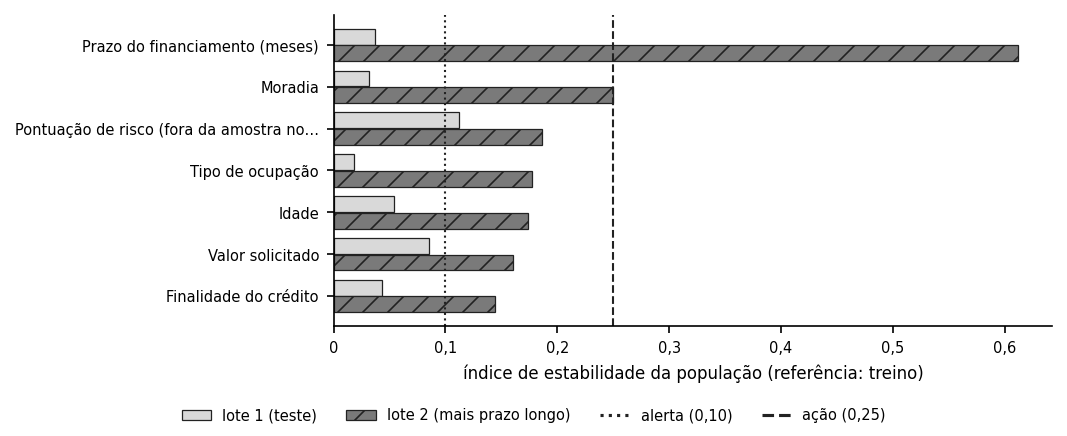

Legenda: índice de estabilidade da população (PSI) das 7 variáveis de maior mudança no lote 2, nos dois lotes SIMULADOS (lote 1 = teste; lote 2 = teste reamostrado com probabilidade proporcional ao prazo). Linhas: faixas de alerta de mercado (0,10 e 0,25), sem apoio estatístico; ilustrativas. Com lotes de 200 casos, o acaso sozinho chega a cerca de 0,11 (percentil 95, 10 faixas).
Fonte: elaborada pela autora com dados da South German Credit [2020], na execução deste notebook.


In [ ]:
exigir("X_treino", "y_treino", "X_teste", "y_teste", "p_oof", "prob_teste", "pipe_final", "colunas_usadas", "regras_teste", "auc_cv")

PSI_ALERTA, PSI_ACAO = 0.10, 0.25      # convenção de mercado, sem apoio estatístico [Yurdakul e Naranjo 2020]; ilustrativas
EPS_PSI = 1e-4

def psi(referencia, lote, categorica):
    """PSI = soma de (a - e) * ln(a / e) por faixa; faixas = decis da referência (números) ou categorias. Devolve (psi, faixas)."""
    ref, nov = pd.Series(referencia).reset_index(drop=True), pd.Series(lote).reset_index(drop=True)
    if categorica:
        cats = sorted(set(ref.astype(str)) | set(nov.astype(str)))
        e = ref.astype(str).value_counts(normalize=True).reindex(cats, fill_value=0).values
        a = nov.astype(str).value_counts(normalize=True).reindex(cats, fill_value=0).values
    else:
        bordas = np.unique(np.quantile(ref.astype(float), np.linspace(0, 1, 11)))[1:-1]
        e = np.bincount(np.digitize(ref.astype(float), bordas), minlength=len(bordas) + 1) / len(ref)
        a = np.bincount(np.digitize(nov.astype(float), bordas), minlength=len(bordas) + 1) / len(nov)
    e, a = np.clip(e, EPS_PSI, None), np.clip(a, EPS_PSI, None)
    return float(np.sum((a - e) * np.log(a / e))), len(e)

def limite_acaso_psi(n_faixas, n_ref, n_lote, nivel=0.95):
    """Limite do PSI esperado só por acaso, pela aproximação PSI ≈ χ²(B − 1) · (1/n + 1/m) [Yurdakul e Naranjo 2020]: percentil 95."""
    from scipy.stats import chi2
    return float(chi2.ppf(nivel, n_faixas - 1) * (1 / n_ref + 1 / n_lote))

def nivel_psi(v):
    return "mudança grande" if v >= PSI_ACAO else ("mudança moderada" if v >= PSI_ALERTA else "pouca mudança")

def aprovados_pelo_sistema(X_, p_):
    regras_ok = np.array([decidir_por_regras(X_.iloc[k])[0] == "aprovado" for k in range(len(X_))])
    return regras_ok & (p_ < LIMIAR_RISCO)

with Secao("Componente 17 – Monitoramento"):
    # Lote 2: reamostragem DECLARADA do teste, com probabilidade proporcional ao prazo (simula mais pedidos de prazo longo)
    rng_l2 = gerador("monitoramento_lote2")
    peso = X_teste["duration"].astype(float).values
    idx_l2 = rng_l2.choice(len(X_teste), size=len(X_teste), replace=True, p=peso / peso.sum())
    X_l2, y_l2 = X_teste.iloc[idx_l2], y_teste.iloc[idx_l2]
    p_l2 = pipe_final.predict_proba(X_l2)[:, 1]
    lotes = {"lote 1 (teste)": (X_teste, y_teste, prob_teste), "lote 2 (teste reamostrado: mais prazo longo)": (X_l2, y_l2, p_l2)}

    linhas_psi = []
    for var in ["pontuação"] + list(colunas_usadas):
        linha = {"variável": "Pontuação de risco (fora da amostra no treino como referência)" if var == "pontuação" else ROTULOS_PT[var]}
        for nome, (X_, y_, p_) in lotes.items():
            if var == "pontuação":
                v, nf = psi(p_oof, p_, categorica=False)
            else:
                v, nf = psi(X_treino[var], X_[var], categorica=not pd.api.types.is_numeric_dtype(X_treino[var]))
            linha[f"PSI {nome}"] = round(v, 3)
            linha[f"_lim {nome}"] = limite_acaso_psi(nf, len(p_oof) if var == "pontuação" else len(X_treino), len(X_))
        linha["_var"] = var
        linhas_psi.append(linha)
    tab_psi = pd.DataFrame(linhas_psi)
    col1, col2 = [c for c in tab_psi.columns if c.startswith("PSI ")]
    lim1, lim2 = [c for c in tab_psi.columns if c.startswith("_lim ")]
    tab_psi = tab_psi.sort_values(col2, ascending=False).reset_index(drop=True)

    sub = np.array_split(gerador("monitoramento_sublotes").permutation(len(X_teste)), 4)
    linhas_lote = []
    for k, s in enumerate(sub, start=1):
        Xs, ys, ps = X_teste.iloc[s], y_teste.iloc[s], prob_teste[s]
        linhas_lote.append(dict(lote=f"lote 1, sublote {k}", n=len(s), aprov=float(aprovados_pelo_sistema(Xs, ps).mean()), auc=float(roc_auc_score(ys, ps)), maus=int(ys.sum())))
    for nome, (X_, y_, p_) in lotes.items():
        linhas_lote.append(dict(lote=nome, n=len(X_), aprov=float(aprovados_pelo_sistema(X_, p_).mean()), auc=float(roc_auc_score(y_, p_)), maus=int(y_.sum())))
    aprov_ref = float(aprovados_pelo_sistema(X_treino, p_oof).mean())

    forma("E, A", "PSI por variável e da pontuação (referência: treino) e AUC por lote")
    def leitura(v, lim):
        if v <= lim:
            return f"{br(v, 3)} (dentro do acaso)"
        return f"{br(v, 3)} ({'no limite do acaso' if v <= 1.1 * lim else 'acima do acaso; ' + nivel_psi(v)})"
    mostrar = tab_psi.head(10).copy()
    for c_, l_ in ((col1, lim1), (col2, lim2)):
        mostrar[c_] = [leitura(v, lim) for v, lim in zip(mostrar[c_], mostrar[l_])]
    mostrar["limite de 95% do acaso (lote de 200)"] = [br(v, 3) for v in mostrar[lim1]]
    print(f"Rótulos: «dentro do acaso» = PSI até o limite de 95%; «no limite do acaso» = até 10% acima dele (convenção deste trabalho); acima disso, a faixa de mercado. "
          "O limite vale para os dois lotes (ambos com 200 casos); no lote 2, que é reamostragem do teste com reposição, a aproximação serve só como referência.")
    display(mostrar.drop(columns=["_var", lim1, lim2]))
    print(f"Variáveis com PSI ≥ {br(PSI_ALERTA, 2)} (faixa de mercado): lote 1: {', '.join(tab_psi.loc[tab_psi[col1] >= PSI_ALERTA, 'variável']) or 'nenhuma'}; "
          f"lote 2: {', '.join(tab_psi.loc[tab_psi[col2] >= PSI_ALERTA, 'variável']) or 'nenhuma'}.")
    display(pd.DataFrame([{"lote": l["lote"], "pedidos": l["n"], "maus": l["maus"], "aprovação pelo sistema": pct(l["aprov"], 0),
                           "AUC": br(l["auc"], 3)} for l in linhas_lote]))
    print(f"Referência: AUC de validação cruzada {br(ESTADO.auc_cv, 3)} (aceite ≥ {br(AUC_MIN_ACEITE, 2)}); aprovação fora da amostra no treino {pct(aprov_ref, 0)}. "
          "Sublotes de 50 pedidos têm AUC muito ruidosa: um valor isolado abaixo do aceite não basta para retreinar.")
    psi_l1 = float(tab_psi.loc[tab_psi["_var"] == "pontuação", col1].iloc[0])
    lim_pont = float(tab_psi.loc[tab_psi["_var"] == "pontuação", lim1].iloc[0])
    print(f"Leitura do lote 1 (sem mudança deliberada): PSI da pontuação {br(psi_l1, 3)}, levemente acima do limite de 95% esperado por acaso com {len(p_oof)} e {len(X_teste)} casos "
          f"e 10 faixas (≈ {br(lim_pont, 3)}, pela aproximação da fonte do PSI: Yurdakul e Naranjo [2020]). A faixa de mercado de 0,10 não leva em conta o tamanho dos lotes; "
          "por isso a tabela compara cada PSI também com esse limite.")

    forma("N", "taxa de aprovação por lote e alerta, em linguagem de negócio")
    l2 = linhas_lote[-1]
    psi_pont_l2 = float(tab_psi.loc[tab_psi["_var"] == "pontuação", col2].iloc[0])
    print(f"No lote simulado com mais pedidos de prazo longo, o sistema aprovaria {pct(l2['aprov'], 0)} dos pedidos, contra {pct(aprov_ref, 0)} na referência; "
          f"o índice de mudança das pontuações foi {br(psi_pont_l2, 2)}, {'acima do' if psi_pont_l2 > lim_pont else 'dentro do'} que o acaso explicaria (≈ {br(lim_pont, 2)}), e o do prazo, "
          f"{br(float(tab_psi.loc[tab_psi['_var'] == 'duration', col2].iloc[0]), 2)}. "
          + ("Alerta: a população de pedidos mudou o bastante para a equipe reavaliar o modelo e o limiar antes de seguir." if psi_pont_l2 > lim_pont
             else "Sem alerta pela pontuação; acompanhar o próximo lote."))

    # Figura NB7: PSI das variáveis de maior mudança no lote 2, nos dois lotes
    top = tab_psi.head(7).iloc[::-1]
    fig, ax = nova_figura(LARG_2COL, 2.8)
    yy = np.arange(len(top))
    ax.barh(yy + 0.2, top[col1], height=0.38, color=COR_CLARA, edgecolor=COR_ESCURA, linewidth=0.6, label="lote 1 (teste)")
    ax.barh(yy - 0.2, top[col2], height=0.38, color=COR_NEUTRA, edgecolor=COR_ESCURA, linewidth=0.6, hatch="//", label="lote 2 (mais prazo longo)")
    for v_, est in ((PSI_ALERTA, ":"), (PSI_ACAO, "--")):
        ax.axvline(v_, color=COR_ESCURA, linestyle=est, linewidth=1.0)
    ax.set_yticks(yy, [textwrap.shorten(v, 40, placeholder="…") for v in top["variável"]])
    ax.set_xlabel("índice de estabilidade da população (referência: treino)")
    eixo_x_br(ax)
    from matplotlib.lines import Line2D
    h_, l_ = ax.get_legend_handles_labels()
    fig.legend(h_ + [Line2D([], [], color=COR_ESCURA, linestyle=":"), Line2D([], [], color=COR_ESCURA, linestyle="--")],
               l_ + [f"alerta ({br(PSI_ALERTA, 2)})", f"ação ({br(PSI_ACAO, 2)})"], loc="outside lower center", ncol=4, frameon=False)
    figura(7, "monitoramento_psi", fig,
           "Monitoramento: PSI das variáveis e da pontuação nos lotes simulados",
           f"Legenda: índice de estabilidade da população (PSI) das {len(top)} variáveis de maior mudança no lote 2, nos dois lotes SIMULADOS (lote 1 = teste; lote 2 = teste "
           "reamostrado com probabilidade proporcional ao prazo). Linhas: faixas de alerta de mercado (0,10 e 0,25), sem apoio estatístico; ilustrativas. "
           "Com lotes de 200 casos, o acaso sozinho chega a cerca de 0,11 (percentil 95, 10 faixas).",
           "E, N, A")
    ESTADO.monitoramento = dict(psi=tab_psi.drop(columns="variável").set_index("_var").to_dict(), lotes=linhas_lote, aprov_ref=aprov_ref, psi_pontuacao_l2=psi_pont_l2,
                                psi_pontuacao_l1=psi_l1, limite_acaso_pontuacao=lim_pont)

## Conclusão: o manual aplicado ao caso, resultados e limites

### Quadro do manual: componente → exemplo real

Uma linha por componente da Seção 4.1 do TCC, na mesma ordem, com classe, público e forma, o **exemplo real calculado nesta execução** (nenhum número é digitado) e a recomendação de projeto do componente.

In [ ]:
exigir("casos", "regras", "limiar", "custos", "dados_info", "selecao", "aceite", "matriz", "versao_modelo", "linha_de_base", "estabilidade_global",
       "camadas", "grupos", "proxies", "calibracao", "X_treino", "X_teste", "colunas_usadas", "registro_decisoes", "monitoramento", "registro_modelo")

def sem_marcas(t):
    """Texto sem marcação Markdown, para citar dentro do quadro."""
    return re.sub(r"\s+", " ", t.replace("**", "").replace("\n", " ")).strip()

def exemplos_reais():
    """Exemplo de cada componente no caso de crédito, só com valores do ESTADO (n -> texto)."""
    di, cs, mz, cu, lb = ESTADO.dados_info, ESTADO.casos, ESTADO.matriz, ESTADO.custos, ESTADO.linha_de_base
    kA = next(iter(cs)); A = cs[kA]
    nivA = A.get("relatorio_nivel", 0)
    rg = ESTADO.regras
    ex = {}
    ex[1] = (f"T: «{frase_regras_nao_acionadas(A['caso_df'].iloc[0], curto=True)}» (caso {kA}); E, N, A: " + "; ".join(rg["texto"])
             + f", que reprovam {rg['n_reprovados']} de {milhar(rg['n'])} casos ({pct(rg['n_reprovados'] / rg['n'])}); 2 variáveis vedadas")
    ex[2] = (f"{milhar(di['n_linhas'])} casos, {pct(di['fracao_inadimplencia'], 0)} de maus (sobreamostrados); SHA-256 {di['sha256_asc'][:12]}… "
             f"({'igual ao' if di['sha256_igual_referencia'] else 'DIFERENTE do'} de referência); {len(ESTADO.X_treino)} treino e {len(ESTADO.X_teste)} teste")
    se = ESTADO.selecao
    ex[3] = (f"Random Forest, profundidade {se['escolhida']['max_depth']}, mínimo {se['escolhida']['min_samples_leaf']} por folha; {se['n_dentro_1ep']} de {se['n_configuracoes']} "
             f"configurações dentro de 1 erro-padrão, escolhida a mais simples ({se['posicao_escolhida']}ª pela AUC); {len(ESTADO.colunas_usadas)} variáveis")
    ex[4] = (f"AUC de validação cruzada {br(ESTADO.auc_cv, 3)} e {br(ESTADO.metricas_teste['AUC']['valor'], 3)} no teste; VP {mz['vp']}, FP {mz['fp']}, FN {mz['fn']}, VN {mz['vn']}; "
             f"N: de cada 100 reprovados, {round(100 * mz['fp'] / (mz['vp'] + mz['fp']))} eram bons pagadores; ECE {br(ESTADO.calibracao['ece_oof'], 3)} (pontuação não é probabilidade)")
    sinal = [r for r in ESTADO.grupos if r["sinal_fpr"] or r["sinal_reprovacao"]]
    ex[5] = ((f"{sinal[0]['grupo']}: FPR {pct(sinal[0]['fpr'], 0)} × {pct(sinal[0]['fpr_restante'], 0)} (Figura NB2)" if sinal else "nenhum grupo sinalizado (Figura NB2)")
             + "; AUC de proxy: " + "; ".join(f"{k} {br(v['auc'], 2)}" for k, v in ESTADO.proxies.items()))
    pc, eg = ESTADO.estabilidade_global["por_classe"], ESTADO.estabilidade_global
    ex[6] = (f"{eg['n_decisao_sensivel_ou_instavel']} dos {eg['n_reprovados_teste']} reprovados do teste mantêm a decisão em menos de 95% dos retreinos "
             f"(modelo isolado); N, no fluxo do sistema: a regra «instável → revisão humana» enviaria {eg['revisao_sistema']['n']} pedidos, {eg['revisao_sistema']['fp']} deles bons pagadores "
             f"(o mesmo número do Registro)")
    ac = ESTADO.aceite
    ex[7] = (f"critério fixado antes: AUC de validação cruzada ≥ {br(ac['minimo'], 2)}; obtida {br(ac['auc'], 3)} -> {'aceito' if ac['aceito'] else 'NÃO aceito'}; "
             f"linha de base logística {br(lb['auc_lr'], 3)} × {br(lb['auc_rf'], 3)} ({'empate' if lb['empata'] else 'diferença'})")
    ex[8] = (f"T: «{frase_limiar_titular(A['prob'], curto=True)}» (caso {kA}); E, N, A: {pts(LIMIAR_RISCO, 0)}, hipotético; com custo 5:1, o de custo mínimo seria "
             f"{br(cu['limiar_minimo_5_1'] * 100, 0)} pontos")
    ex[9] = (f"versão {ESTADO.versao_modelo} (SHA-256 das árvores), entrada em saidas/registro_modelos.json com uso pretendido «ilustrativo»; T: não se descreve")
    ex[10] = (f"T ({kA}): «{sem_marcas(frase_procedimento(A, nivA))}»; E, N, A: regras {A['decisao_regras']} → pontuação {pts(A['prob'])} → limiar: {A['decisao']} → "
              f"estabilidade {A['estabilidade']['classe']} → {A['resultado']}; no teste, {ESTADO.camadas['so_modelo']} reprovações só pelo modelo")
    d = A["dados_individuais"]
    top0 = A["fatores"]["top"].iloc[0]
    ex[11] = (f"caso {kA}: tabela com {len(d)} campos ({int(d['uso'].str.startswith('no cadastro').sum())} vedados), anexada ao relatório; ex.: "
              f"{top0['rotulo'].lower()} = {top0['valor']}; origem: {ORIGEM_DADOS}")
    ceA = A["fatores"]["conta_exibida"]
    r2 = {k: c["lime"]["r2"] for k, c in cs.items() if "lime" in c}
    baixos = [k for k, v in r2.items() if not np.isnan(v) and v < ESTADO.r2_lime_baixo]
    ex[12] = (f"T ({kA}): «{top0['rotulo']}: {top0['valor']} ({txt_decimos(ceA['fatores'][0], True)} pontos)» e a conta {txt_decimos(ceA['base'])} "
              f"{txt_decimos(ceA['top'], True)} {txt_decimos(ceA['outros'], True)} = {txt_decimos(ceA['pontuacao'])}; E, N, A: Figuras NB4a, NB4b e NB5"
              + "".join(f"; R² local do LIME no caso {k} = {br(r2[k], 2)}: não usar" for k in baixos))
    ex[13] = "; ".join((f"caso {k}: {c['contrafactuais']['melhor']['mudancas']} -> {pts(c['contrafactuais']['melhor']['pontuacao_modelo'])}, "
                        f"{pct(c['contrafactuais']['melhor']['fracao_semente'], 0)} × {pct(c['contrafactuais']['melhor']['fracao_reamostra'], 0)} dos retreinos"
                        if c["contrafactuais"].get("melhor") else f"caso {k}: nenhuma mudança testada atende, e o relatório diz isso") for k, c in cs.items())
    sens = A.get("sensibilidade_dados", {}).get("campos_contestaveis") or []
    ex[14] = (f"caso {kA}: " + (f"corrigir {lista_e(ROTULOS_PT[v].lower() for v in sens)} pode mudar o resultado com folga" if sens
                                else "nenhum campo corrigido sozinho muda o resultado com folga") + " (Figura NB6 como apoio)")
    ex[15] = (f"caso {kA}: «{sem_marcas(cabecalho_resultado(A, nivA))}»; canal {CANAL_REVISAO} (fictício), dirigido ao encarregado; relatório de "
              f"{A['relatorio_palavras']} palavras (nível {nivA})")
    rd = ESTADO.registro_decisoes
    ex[16] = (f"{rd['n']} registros (pedidos simulados) em JSONL e CSV; " + ", ".join(f"{v} {k}" for k, v in rd["contagem"].items())
              + f"; decisão do caso {kA} reconstruída a partir do registro: {'sim' if rd['reconstruida_A'] else 'não'}")
    mo = ESTADO.monitoramento
    ex[17] = (f"PSI da pontuação: {br(mo['psi_pontuacao_l1'], 3)} no lote 1 (teste; limite do acaso ≈ {br(mo['limite_acaso_pontuacao'], 3)}) e {br(mo['psi_pontuacao_l2'], 3)} no lote 2 (mais prazo longo); "
              f"aprovação {pct(mo['lotes'][-1]['aprov'], 0)} no lote 2 × {pct(mo['aprov_ref'], 0)} na referência (Figura NB7)")
    return ex

def recomendacoes_projeto():
    """Decisões de projeto, cada uma na linha do componente a que se refere."""
    cal, cm = ESTADO.calibracao, ESTADO.camadas
    return {
        1: f"regras só para política (prazo, valor, vedações); variável preditiva fica no modelo; no teste, reprovações só por regra {cm['so_regras']}, só pelo modelo {cm['so_modelo']}, por ambos {cm['ambos']}",
        2: "declarar que a taxa da amostra não é a da carteira e registrar o *hash* da base e da divisão",
        3: "registrar algoritmo, hiperparâmetros e como foram escolhidos; escolha por validação cruzada só no treino",
        4: f"sem «%» enquanto a pontuação não for calibrada (ECE {br(cal['ece_oof'], 3)}); se calibrar, refazer a explicação sobre o modelo calibrado",
        5: "vedar não basta: testar *proxy* e erros por grupo antes de operar; declarar o que não é recuperável",
        6: "retreinar e medir a fração de decisões mantidas; se o encaminhamento à revisão integrar o fluxo, declará-lo na Inferência",
        7: "fixar o critério de aceite antes do resultado e comparar com um modelo interpretável nas mesmas partições [Rudin 2019]",
        8: f"derivar o corte dos custos reais e registrar quem o definiu e quando (com 5:1, o de custo mínimo seria {br(ESTADO.custos['limiar_minimo_5_1'] * 100, 0)} pontos)",
        9: f"registrar versão por *hash*, uso pretendido e semente mestra ({SEMENTE_MESTRA}): é rastreabilidade (qual modelo decidiu), não explicação (por que)",
        10: "uma frase ao titular com a ordem das camadas; à equipe, a camada que decidiu cada reprovação",
        11: "tabela legível com uso e origem de cada campo; vedadas marcadas",
        12: f"SHAP para E, N, A; LIME só com estabilidade e R² local medidos; ao titular, até {N_FATORES_RELATORIO} fatores e a conta, nunca o gráfico",
        13: "exigir folga, robustez nos dois conjuntos de retreinos, minimalidade e aprovação pelas regras",
        14: "prometer efeito só com valor admissível; para valor informado «sem informação», pedir comprovante",
        15: f"dizer como e a quem pedir a revisão (encarregado); relatório de até {MAX_PALAVRAS_RELATORIO} palavras com todos os blocos devidos ao titular",
        16: "registrar entradas, *hash*, versões, regras, pontuação, limiar, resultado, revisão e fatores; testar a reconstrução",
        17: "acompanhar PSI da pontuação e das variáveis e AUC por lote; comparar o PSI com o limite do acaso para o tamanho dos lotes, não só com as faixas 0,10/0,25",
    }

with Secao("Conclusão – quadro do manual"):
    EXEMPLOS = exemplos_reais()
    RECOMENDACOES = recomendacoes_projeto()
    faltam = [m["n"] for m in MANUAL if m["n"] not in EXEMPLOS or m["n"] not in RECOMENDACOES]
    conferir("quadro_cobre_os_17_componentes", not faltam and len(MANUAL) == 17, f"sem exemplo ou recomendação: {faltam}")
    linhas_q = [[m["n"], m["componente"], f"**{m['classe']}**", m["publico"], m["lgpd"], m["forma"], EXEMPLOS[m["n"]], RECOMENDACOES[m["n"]]] for m in MANUAL]
    ESTADO.quadro_manual = [dict(zip(["n", "componente", "classe", "publico", "lgpd", "forma", "exemplo", "recomendacao"], l)) for l in linhas_q]
    conferir("quadro_sem_exemplo_vazio", all(l[6] and "None" not in l[6] and "nan" not in l[6].lower().split() for l in linhas_q))
    display(Markdown("**Quadro do manual – componente → exemplo real**\n\n" + tabela_markdown(
        ["Nº", "Componente", "Classe", "Público", "LGPD [Brasil 2018]", "Forma", "Exemplo real nesta execução", "Recomendação de projeto"], linhas_q)))
    print(f"{len(linhas_q)} componentes ({sum(m['classe'] == 'O' for m in MANUAL)} obrigatórios, {sum(m['classe'] == 'R' for m in MANUAL)} recomendáveis).")

**Quadro do manual – componente → exemplo real**

| Nº | Componente | Classe | Público | LGPD [Brasil 2018] | Forma | Exemplo real nesta execução | Recomendação de projeto |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Regras de negócio | **O** | T, E, N, A | art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados") | T → regra aplicada ao caso, em uma frase; E, N, A → conjunto das regras e justificativa (tabela) | T: «Nenhuma reprovou: prazo de 24 meses (reprova acima de 36); valor de 2.439 DM (reprova acima de 8.000).» (caso A); E, N, A: R1: prazo acima de 36 meses → reprova; R2: valor solicitado acima de 8.000 DM → reprova, que reprovam 127 de 1.000 casos (12,7%); 2 variáveis vedadas | regras só para política (prazo, valor, vedações); variável preditiva fica no modelo; no teste, reprovações só por regra 11, só pelo modelo 30, por ambos 14 |
| 2 | Base de dados de treinamento e teste | **R** | E, A | apoia o art. 20, § 2º | E, A → ficha da base (origem, período, composição, limitações, *hash*, divisão treino/teste) | 1.000 casos, 30% de maus (sobreamostrados); SHA-256 5f363343f356… (igual ao de referência); 800 treino e 200 teste | declarar que a taxa da amostra não é a da carteira e registrar o *hash* da base e da divisão |
| 3 | Treinamento | **R** | E, A | — | E, A → algoritmo, hiperparâmetros escolhidos por validação cruzada, variáveis usadas e vedadas | Random Forest, profundidade 4, mínimo 10 por folha; 9 de 9 configurações dentro de 1 erro-padrão, escolhida a mais simples (8ª pela AUC); 18 variáveis | registrar algoritmo, hiperparâmetros e como foram escolhidos; escolha por validação cruzada só no treino |
| 4 | Métricas de desempenho | **R** | E, N, A | — | E, A → matriz de confusão, métricas com IC95%, AUC, calibração; N → resumo em frequências («de cada 100 reprovados…») | AUC de validação cruzada 0,792 e 0,742 no teste; VP 25, FP 19, FN 35, VN 121; N: de cada 100 reprovados, 43 eram bons pagadores; ECE 0,081 (pontuação não é probabilidade) | sem «%» enquanto a pontuação não for calibrada (ECE 0,081); se calibrar, refazer a explicação sobre o modelo calibrado |
| 5 | Desempenho por grupos | **R** | E, N, A | apoia o art. 6º, IX, e o art. 20, § 2º | E, A → taxas por grupo com IC95%, teste de *proxy* e figura; N → grupos sinalizados, em uma frase | até 24 anos: FPR 33% × 10% (Figura NB2); AUC de proxy: trabalhador estrangeiro 0,82; mulher solteira (x homens das categorias 1 e 3) 0,82 | vedar não basta: testar *proxy* e erros por grupo antes de operar; declarar o que não é recuperável |
| 6 | Estabilidade da decisão | **R** | E, N, A | — | E, A → fração de retreinos que mantém cada decisão, por classe; N → carga de revisão humana que a regra geraria | 28 dos 44 reprovados do teste mantêm a decisão em menos de 95% dos retreinos (modelo isolado); N, no fluxo do sistema: a regra «instável → revisão humana» enviaria 9 pedidos, 7 deles bons pagadores (o mesmo número do Registro) | retreinar e medir a fração de decisões mantidas; se o encaminhamento à revisão integrar o fluxo, declará-lo na Inferência |
| 7 | Seleção e aceite do modelo | **R** | E, N, A | — | E, A → critério fixado antes, valor obtido, teste reservado, linha de base; N → aceito ou não, em uma frase | critério fixado antes: AUC de validação cruzada ≥ 0,70; obtida 0,792 -> aceito; linha de base logística 0,795 × 0,792 (empate) | fixar o critério de aceite antes do resultado e comparar com um modelo interpretável nas mesmas partições [Rudin 2019] |
| 8 | Limiar de decisão | **O** | T, E, N, A | art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados") | T → valor do corte e pontuação do caso em relação a ele; E, N, A → valor vigente, quem definiu e custos (tabela) | T: «41,4 pontos, 1,4 acima do corte de 40 (hipotético); não é probabilidade.» (caso A); E, N, A: 40 pontos, hipotético; com custo 5:1, o de custo mínimo seria 26 pontos | derivar o corte dos custos reais e registrar quem o definiu e quando (com 5:1, o de custo mínimo seria 26 pontos) |
| 9 | Modelo treinado e versão | **R** | E, A | apoia o art. 20, § 2º | E, A → registro de modelos (versão por *hash*, uso pretendido, parâmetros) e funcionamento interno; T → não se descreve | versão rf-6d8abcfb63d1 (SHA-256 das árvores), entrada em saidas/registro_modelos.json com uso pretendido «ilustrativo»; T: não se descreve | registrar versão por *hash*, uso pretendido e semente mestra (42): é rastreabilidade (qual modelo decidiu), não explicação (por que) |
| 10 | Inferência | **O** | T, E, N, A | art. 20, § 1º ("procedimentos") | T → uma frase com a ordem regras → modelo → limiar (→ estabilidade); E, N, A → passos do caso e camada que decidiu | T (A): «Regras de prazo e valor; se nenhuma reprova, como aqui, um modelo dá uma pontuação (0 a 100) que reprova com 40 ou mais; reprovação instável é encaminhada a uma pessoa, como aqui.»; E, N, A: regras aprovado → pontuação 41,4 pontos → limiar: reprovado → estabilidade instável → encaminhado à revisão humana (simulado; reprovação indicada pelo modelo, instável); no teste, 30 reprovações só pelo modelo | uma frase ao titular com a ordem das camadas; à equipe, a camada que decidiu cada reprovação |
| 11 | Dados individuais do titular | **O** | T | art. 18, II e III; origem dos dados: art. 19, II | T → tabela campo, valor, unidade, uso e origem | caso A: tabela com 20 campos (2 vedados), anexada ao relatório; ex.: situação da conta corrente = sem conta corrente; origem: informado no pedido (aqui: linha histórica da base pública, sem fonte nem data de coleta) | tabela legível com uso e origem de cada campo; vedadas marcadas |
| 12 | Fatores da decisão | **O** | T (linguagem simples); E, N, A (técnica) | art. 20, § 1º ("critérios"); art. 19, II ("critérios utilizados") | T → até 5 fatores em linguagem simples, com a conta; E, N, A → SHAP e LIME, comparação e avaliação funcional | T (A): «Situação da conta corrente: sem conta corrente (+10,5 pontos)» e a conta 30,1 +11,3 +0,0 = 41,4; E, N, A: Figuras NB4a, NB4b e NB5; R² local do LIME no caso B = 0,22: não usar | SHAP para E, N, A; LIME só com estabilidade e R² local medidos; ao titular, até 5 fatores e a conta, nunca o gráfico |
| 13 | Alterações possíveis | **R** | T | — | T → uma simulação mínima e robusta, em uma frase («simulação, não garantia») | caso A: nenhuma mudança testada atende, e o relatório diz isso; caso B: Situação da conta corrente: de saldo negativo para saldo de 200 DM ou mais, ou salário há 1 ano ou mais -> 31,5 pontos, 100% × 97% dos retreinos | exigir folga, robustez nos dois conjuntos de retreinos, minimalidade e aprovação pelas regras |
| 14 | Dados possivelmente errados | **R** | T | apoia o art. 18, III | T → lista dos campos que, se errados, poderiam mudar o resultado | caso A: corrigir situação da conta corrente pode mudar o resultado com folga (Figura NB6 como apoio) | prometer efeito só com valor admissível; para valor informado «sem informação», pedir comprovante |
| 15 | Direito e meio para solicitar revisão | **O** | T | art. 20, caput (direito de solicitar revisão); art. 41, § 2º, I (apoio quanto ao meio) | T → como e a quem pedir a revisão, em uma frase, com o resultado | caso A: «Resultado: encaminhado à revisão humana (reprovação indicada pela inteligência artificial, instável).»; canal [CANAL FICTÍCIO DE REVISÃO] (fictício), dirigido ao encarregado; relatório de 347 palavras (nível 3) | dizer como e a quem pedir a revisão (encarregado); relatório de até 350 palavras com todos os blocos devidos ao titular |
| 16 | Registro da decisão | **R** | E, N, A | art. 37 (por extensão deste trabalho) | E → esquema do registro (JSON/CSV); N → contagem por resultado; A → reconstrução de uma decisão a partir do registro | 200 registros (pedidos simulados) em JSONL e CSV; 145 aprovado, 25 reprovado por regra, 21 reprovado pelo modelo, 9 encaminhado à revisão humana; decisão do caso A reconstruída a partir do registro: sim | registrar entradas, *hash*, versões, regras, pontuação, limiar, resultado, revisão e fatores; testar a reconstrução |
| 17 | Monitoramento | **R** | E, N, A | — | E, A → PSI por variável e da pontuação, AUC por lote; N → taxa de aprovação por lote e alerta | PSI da pontuação: 0,112 no lote 1 (teste; limite do acaso ≈ 0,106) e 0,186 no lote 2 (mais prazo longo); aprovação 53% no lote 2 × 71% na referência (Figura NB7) | acompanhar PSI da pontuação e das variáveis e AUC por lote; comparar o PSI com o limite do acaso para o tamanho dos lotes, não só com as faixas 0,10/0,25 |

17 componentes (6 obrigatórios, 11 recomendáveis).


### Resultados

Os números abaixo são **calculados nesta execução** (nenhum é digitado) a partir dos componentes 4 a 17. Os itens marcados *(complementar)* são de leitura opcional.

In [ ]:
exigir("casos", "calibracao", "auc_cv", "metricas_teste", "matriz", "fp_entre_reprovados", "estabilidade_global", "avaliacao", "grupos", "camadas",
       "custos", "versao_modelo", "dados_info", "selecao", "idade", "aceite", "proxies", "linha_de_base", "importancia_global", "registro_decisoes", "monitoramento")

def inicial_maiuscula(t):
    return t[:1].upper() + t[1:]

with Secao("Conclusão"):
    cal, av, cm = ESTADO.calibracao, ESTADO.avaliacao, ESTADO.camadas
    m = ESTADO.metricas_teste
    conf = pd.DataFrame(cal["confiabilidade_oof"])
    grandes = conf[conf["n"] >= 30]
    f_baixa, f_alta = (grandes.iloc[0], grandes.iloc[-1]) if len(grandes) else (conf.iloc[0], conf.iloc[-1])
    instavel = ESTADO.estabilidade_global
    pc = instavel["por_classe"]
    mz = ESTADO.matriz
    ms = cm["matriz_sistema"]
    fp_casos = [k for k, c in ESTADO.casos.items() if str(c.get("celula_matriz", "")).startswith("FP")]
    sinalizados = [r for r in ESTADO.grupos if r["sinal_fpr"] or r["sinal_reprovacao"]]
    cf = {k: ESTADO.casos[k]["contrafactuais"]["melhor"] for k in ESTADO.casos}
    n_sin = len(sinalizados)
    r2_lime = {k: c["lime"]["r2"] for k, c in ESTADO.casos.items()}
    r2_baixos = [k for k, v in r2_lime.items() if not np.isnan(v) and v < ESTADO.r2_lime_baixo]
    lb, ig, rr = ESTADO.linha_de_base, ESTADO.importancia_global, av.get("restrito_r2")
    sv_casos = {k: [v for v in c["fatores"]["top"]["variavel"] if v in ig["sem_valor_teste"]] for k, c in ESTADO.casos.items()}

    achados = [
        f"**Desempenho.** AUC de {br(m['AUC']['valor'], 2)} no teste (resultado principal; IC95% {br(m['AUC']['ic95'][0], 2)} a {br(m['AUC']['ic95'][1], 2)}, uma só divisão) e {br(ESTADO.auc_cv, 2)} na validação cruzada do treino (complementar; critério de aceite ≥ {br(ESTADO.aceite['minimo'], 2)} {'atingido' if ESTADO.aceite['aceito'] else 'NÃO atingido'}). "
        f"Matriz de confusão no teste (corte de {br(LIMIAR_RISCO * 100, 0)} pontos): VP {mz['vp']}, FP {mz['fp']}, FN {mz['fn']}, VN {mz['vn']}. "
        + (f"{mz['fp']} dos {mz['vp'] + mz['fp']} reprovados ({pct(mz['fp'] / (mz['vp'] + mz['fp']), 0)}) eram bons pagadores (FP)" if mz["vp"] + mz["fp"] else "Nenhum pedido do teste foi reprovado")
        + (f", e {mz['fn']} dos {mz['vp'] + mz['fn']} inadimplentes ({pct(mz['fn'] / (mz['vp'] + mz['fn']), 0)}) foram aprovados (FN)." if mz["vp"] + mz["fn"] else ".")
        + f" Linha de base (componente 7), nas mesmas partições: regressão logística regularizada com AUC {br(lb['auc_lr'], 3)} × {br(lb['auc_rf'], 3)} do Random Forest "
        + ("(sem evidência clara de superioridade da floresta; sem teste formal de equivalência)" if lb["empata"] else f"({'a logística' if lb['dif_auc'] > 0 else 'o Random Forest'} ordena melhor)")
        + f" e ECE {br(lb['ece_lr'], 3)} × {br(cal['ece_oof'], 3)}"
        + ("; para uso real, isso favoreceria o modelo interpretável [Rudin 2019], e o Random Forest fica como objeto do manual." if lb["empata"] and lb["lr_calibrada"] and not cal["calibrado_ok"] else "."),
        f"**Calibração** *(complementar)*. O critério {'foi aprovado' if cal['calibrado_ok'] else 'reprovou'} (ECE {br(cal['ece_oof'], 3)}). Na faixa de {f_baixa['faixa']} pontos, a pontuação média foi {br(f_baixa['pontuacao_media'] * 100)} e a inadimplência observada {pct(f_baixa['taxa_observada'])}; "
        f"na de {f_alta['faixa']}, {br(f_alta['pontuacao_media'] * 100)} contra {pct(f_alta['taxa_observada'])}. A melhor calibração testada ({cal['melhor_alternativa']}) reduziria o Brier em {pct(cal['melhoria_relativa'])}.",
        f"**Estabilidade.** {instavel['n_decisao_sensivel_ou_instavel']} dos {instavel['n_reprovados_teste']} reprovados do teste ({pct(instavel['fracao'], 0)}) mantêm a decisão em menos de 95% dos retreinos; "
        + ", ".join(f"a decisão do caso {k} é {c['estabilidade']['classe']}" for k, c in ESTADO.casos.items())
        + f" (modelo isolado). No fluxo do sistema, com as regras antes do modelo, a regra de revisão humana (reprovação instável; boa prática) enviaria {instavel['revisao_sistema']['n']} "
        + f"dos {instavel['revisao_sistema']['n_reprovados_pelo_modelo_e_aprovados_pelas_regras']} pedidos aprovados pelas regras e reprovados pelo modelo, {instavel['revisao_sistema']['fp']} deles bons pagadores (FP), o mesmo número do Registro"
        + ((f"; no histórico, os casos {' e '.join(fp_casos)} são FP" if len(fp_casos) > 1 else f"; no histórico, o caso {fp_casos[0]} é FP") + " (bom pagador reprovado)." if fp_casos else "."),
        f"**SHAP × LIME** *(complementar)*. Nos {av['n_casos']} reprovados, o Spearman médio é {br(av['spearman_medio'], 2)}, mas a variável nº 1 coincide em {pct(av['top1_igual'], 0)} e as 3 principais, em média, em {br(av['top3_comum_medio'])} de 3. "
        f"No teste de remoção (k = {av['k_principal']}), o SHAP obtém {pct(av['eficiencia_relativa_ao_oraculo']['SHAP'], 0)} da queda do oráculo e o LIME, {pct(av['eficiencia_relativa_ao_oraculo']['LIME'], 0)}. "
        + f"R² local do LIME abaixo de {br(ESTADO.r2_lime_baixo, 2)} em {av['n_r2_baixo']} dos {av['n_casos']} reprovados; nos casos do estudo, "
        + "; ".join(f"caso {k} {br(v, 2)}" for k, v in r2_lime.items())
        + (f"; no{'s casos' if len(r2_baixos) > 1 else ' caso'} {' e '.join(r2_baixos)}, o R² baixo limita a comparação." if r2_baixos else ".")
        + (f" Só nos {rr['n']} casos com R² ≥ {br(ESTADO.r2_lime_baixo, 2)}: SHAP {pct(rr['shap'], 0)} e LIME {pct(rr['lime'], 0)} da queda do oráculo; 3 principais em comum, {br(rr['top3'])} de 3." if rr else ""),
        "**Fidelidade, relevância isolada e relevância em conjunto** *(complementar)*. Fatores ao titular cuja importância por permutação no teste tem faixa (± 2 DP) que inclui 0: "
        + (", ".join(f"{ROTULOS_PT[v].lower()} ({br(ig['permutacao'][v], 3)})" for v in ig["sem_valor_teste"]) if ig["sem_valor_teste"] else "nenhum")
        + (f"; fora da amostra no treino, também {', '.join(ROTULOS_PT[v].lower() for v in ig['sem_valor_ambos'])}" if ig["sem_valor_ambos"] else "; fora da amostra no treino, nenhum deles")
        + ". " + (inicial_maiuscula("; ".join(f"no caso {k}, {len(vs)} dos {len(ESTADO.casos[k]['fatores']['top'])} fatores" for k, vs in sv_casos.items() if vs)) + ". " if any(sv_casos.values()) else "")
        + (inicial_maiuscula(leitura_relevancia(ig["sem_valor_ambos"], ig["conjunta"])) + " O aviso fica no texto técnico e não vai ao titular."
           if ig["sem_valor_teste"] else "Todos os fatores ao titular têm valor preditivo no teste."),
        f"**Idade e grupos.** Sem a idade, {ESTADO.idade['decisoes_que_mudam']} de {ESTADO.idade['n']} decisões mudariam. "
        + "Proxies (AUC fora da amostra ao reconstruir o atributo vedado): " + "; ".join(f"{k} {br(v['auc'], 2)} (IC95% {br(v['ic95'][0], 2)} a {br(v['ic95'][1], 2)}; {v['n_grupo']} no grupo)" for k, v in ESTADO.proxies.items()) + ". "
        + ("Grupos sinalizados: " + "; ".join(f"{r['grupo']} (n = {r['n']}; reprovação {pct(r['taxa_reprovacao'], 0)} contra {pct(r['restante']['rep'] / r['restante']['n'], 0)}; "
                                                f"FPR, bons pagadores reprovados, {pct(r['fpr'], 0)} contra {pct(r['fpr_restante'], 0)} em {r['comparacao']})" for r in sinalizados) + "." if sinalizados else "Nenhum grupo sinalizado.")
        + " O sexo só é comparável em parte (mulheres solteiras contra homens já casados) e há só "
        + f"{next((r['n'] for r in ESTADO.grupos if r['grupo'] == 'trabalhador estrangeiro'), 0)} estrangeiros.",
        "**Simulações mínimas** (≥ " + pct(ROBUSTEZ_MIN, 0) + " nos dois conjuntos de retreinos). " + "; ".join((f"caso {k}: {v['mudancas']} ({pts(v['pontuacao_modelo'])}; {pct(v['fracao_semente'], 0)} com outra semente e {pct(v['fracao_reamostra'], 0)} com treino reamostrado)" if v
                                             else f"caso {k}: nenhuma mudança testada atende aos critérios, e o relatório diz isso")
                                            for k, v in cf.items()) + ".",
        f"**Camadas do sistema.** O sistema adotado (regras + modelo) tem no teste VP {ms['vp']}, FP {ms['fp']}, FN {ms['fn']}, VN {ms['vn']}; das reprovações, {cm['so_modelo']} dependem só do modelo, "
        f"{cm['so_regras']} só das regras e {cm['ambos']} em que o modelo isolado também reprova. Só as primeiras exigem explicar o modelo; nas demais, o fluxo usa a regra e o modelo não é aplicado. A incidência do art. 20 depende da participação humana efetiva (D1). "
        + (f"Das {cm['so_modelo']} reprovadas só pelo modelo, {cm['fp_por_camada']['só modelo']} são FP (bons pagadores); "
           f"um bom pagador reprovado receberia um relatório montado do mesmo modo, e o relatório não permite ao titular saber se é um deles: a explicação descreve o modelo, não revela o erro dele." if cm["so_modelo"] else ""),
        f"**Relatórios ao titular.** " + "; ".join(f"caso {k}: {c['relatorio_palavras']} palavras (nível de compactação {c['relatorio_nivel']}), com os 6 componentes obrigatórios do manual e os 2 recomendáveis ao titular"
                                                  + (" (encaminhado à revisão humana, simulada: sob a hipótese D1, 4 componentes seriam devidos pelos arts. 18 e 19, e o direito de revisão e a Inferência, por boa prática; sem participação humana efetiva, os 6 seriam devidos)" if c.get("em_revisao_humana") else " (decisão automática: os 6 devidos)")
                                                  for k, c in ESTADO.casos.items()) + "; a tabela dos dados vai em anexo, fora da contagem.",
        f"**Registro da decisão.** {ESTADO.registro_decisoes['n']} decisões simuladas registradas ("
        + ", ".join(f"{v} {k}" for k, v in ESTADO.registro_decisoes["contagem"].items()) + f"); a decisão do caso A foi reconstruída a partir do registro: {'sim' if ESTADO.registro_decisoes['reconstruida_A'] else 'não'}.",
        f"**Monitoramento** (lotes simulados). PSI da pontuação {br(ESTADO.monitoramento['psi_pontuacao_l1'], 3)} no lote 1 (teste; levemente acima do limite de 95% do acaso, ≈ {br(ESTADO.monitoramento['limite_acaso_pontuacao'], 3)}) e {br(ESTADO.monitoramento['psi_pontuacao_l2'], 3)} no lote 2 "
        f"(mais prazo longo); aprovação pelo sistema {pct(ESTADO.monitoramento['lotes'][-2]['aprov'], 0)} e {pct(ESTADO.monitoramento['lotes'][-1]['aprov'], 0)}, contra {pct(ESTADO.monitoramento['aprov_ref'], 0)} na referência.",
    ]
    texto = "### Resultados\n\n" + "\n".join(f"{i}. {a}" for i, a in enumerate(achados, start=1))
    # Parâmetros de desenho: valores lidos das constantes do código (nada digitado); defende-se a existência do parâmetro, não o valor
    params = [
        ("Limiar de decisão (ponto de corte)", f"{br(LIMIAR_RISCO * 100, 0)} pontos", f"ilustrativo; não vem de custos (com 5:1, o de custo mínimo seria {br(ESTADO.custos['limiar_minimo_5_1'] * 100, 0)} pontos, componente 8)"),
        ("Critério de aceite", f"AUC de validação ≥ {br(AUC_MIN_ACEITE, 2)}", "fixado antes do resultado; mínimo para o modelo seguir"),
        ("Calibração", f"ECE ≤ {br(ECE_MAX, 2)}; faixas com n ≥ {N_MIN_FAIXA}; calibrar se o Brier cair ≥ {pct(MELHORIA_MIN_CALIBRAR, 0)}", "faixas pequenas têm IC largo; abaixo do limiar de ganho, não se calibra; acima, troca declarada (Métricas de desempenho)"),
        ("Estabilidade da decisão", f"estável ≥ {pct(ESTAVEL_MIN, 0)}; instável < {pct(INSTAVEL_ABAIXO, 0)}, vai à revisão humana", f"instável: a decisão muda em mais de 1 a cada {round(1 / (1 - INSTAVEL_ABAIXO))} retreinos"),
        ("Simulações e dados errados", f"folga de {br(MARGEM_CONTRAFACTUAL * 100, 0)} pontos; abaixo do corte em ≥ {pct(ROBUSTEZ_MIN, 0)} dos retreinos com outra semente e ≥ {pct(ROBUSTEZ_MIN, 0)} com treino reamostrado; "
         f"ao titular, a mais robusta com esforço até +{br(TOL_ESFORCO_ROBUSTEZ, 2)} do menor", "não prometer mudança que um retreino desfaz; mesma regra (menor das duas frações) da estabilidade"),
        ("Uso do LIME", f"R² local ≥ {br(R2_LIME_BAIXO, 2)}", "abaixo disso, a reta explica pouco da vizinhança"),
        ("Relatório ao titular", f"até {N_FATORES_RELATORIO} fatores; até {MAX_PALAVRAS_RELATORIO} palavras", "explicação seletiva e curta; número escolhido, sem fonte"),
        ("Faixas etárias", f"até {IDADE_JOVEM_MAX}, {IDADE_JOVEM_MAX + 1} a {IDADE_IDOSO_MIN - 1}, {IDADE_IDOSO_MIN} ou mais anos", f"ilustrativas; o corte de {IDADE_JOVEM_MAX + 1} anos é testado no componente 5"),
        ("Razões de custo", ", ".join(f"{r:g}:1" for r in ESTADO.custos["razoes"]), "5:1 vem da matriz de custo da documentação original (componente 8); as outras, para comparação; o corte de custo mínimo vale para a proporção de maus desta amostra"),
        ("Proxy de atributo vedado", f"AUC ≥ {br(PROXY_FORTE, 2)}", "a partir daí, as demais variáveis reconstroem bem o atributo"),
        ("Retreinos", f"{PARAMETROS['n_retreinos_semente']} com outra semente + {PARAMETROS['n_retreinos_reamostra']} com treino reamostrado", "custo de execução"),
        ("Monitoramento", f"PSI com decis da referência; alerta {br(PSI_ALERTA, 2)}, ação {br(PSI_ACAO, 2)}; limite do acaso no percentil 95, com tolerância de 10% para «no limite do acaso»; lote 2 reamostrado com probabilidade proporcional ao prazo", "faixas de mercado sem apoio estatístico; lotes simulados"),
        ("Registro da decisão", f"esquema {VERSAO_ESQUEMA_REGISTRO}; 3 fatores por decisão do modelo", "conteúdo proposto por este trabalho"),
    ]
    texto += ("\n\n### Parâmetros de desenho (ilustrativos; complementar)\n\nConvenções deste trabalho, fixadas antes dos resultados; defende-se a existência de cada parâmetro, não o valor.\n\n"
              "| Parâmetro | Valor | Motivo |\n| --- | --- | --- |\n" + "\n".join("| " + " | ".join(l) + " |" for l in params))
    display(Markdown(texto))

    # Reprodutibilidade: versões efetivamente usadas (a primeira célula instala estas versões se o arquivo existir)
    req = [f"{p}=={ESTADO.versoes[p]}" for p in ("scikit-learn", "shap", "lime") if ESTADO.versoes.get(p, "desconhecida")[:1].isdigit()]
    req += [f"# registro: {p} {ESTADO.versoes[p]}" for p in ("python", "numpy", "pandas", "scipy", "matplotlib")]
    with open("requirements_executado.txt", "w", encoding="utf-8") as arquivo:
        arquivo.write("\n".join(req) + "\n")
    print("\nrequirements_executado.txt gravado:", "; ".join(req))
    mais_lenta = max(ESTADO.tempos, key=ESTADO.tempos.get)
    print(f"Tempo de execução das seções: {br(sum(ESTADO.tempos.values()), 0)} s no total; a mais demorada foi «{mais_lenta}» ({br(ESTADO.tempos[mais_lenta], 0)} s).")

### Resultados

1. **Desempenho.** AUC de 0,74 no teste (resultado principal; IC95% 0,67 a 0,81, uma só divisão) e 0,79 na validação cruzada do treino (complementar; critério de aceite ≥ 0,70 atingido). Matriz de confusão no teste (corte de 40 pontos): VP 25, FP 19, FN 35, VN 121. 19 dos 44 reprovados (43%) eram bons pagadores (FP), e 35 dos 60 inadimplentes (58%) foram aprovados (FN). Linha de base (componente 7), nas mesmas partições: regressão logística regularizada com AUC 0,795 × 0,792 do Random Forest (sem evidência clara de superioridade da floresta; sem teste formal de equivalência) e ECE 0,033 × 0,081; para uso real, isso favoreceria o modelo interpretável [Rudin 2019], e o Random Forest fica como objeto do manual.
2. **Calibração** *(complementar)*. O critério reprovou (ECE 0,081). Na faixa de 10 a 20 pontos, a pontuação média foi 15,7 e a inadimplência observada 5,9%; na de 40 a 50, 44,1 contra 61,3%. A melhor calibração testada (sigmoide (Platt)) reduziria o Brier em 6,6%.
3. **Estabilidade.** 28 dos 44 reprovados do teste (64%) mantêm a decisão em menos de 95% dos retreinos; a decisão do caso A é instável, a decisão do caso B é pouco estável (modelo isolado). No fluxo do sistema, com as regras antes do modelo, a regra de revisão humana (reprovação instável; boa prática) enviaria 9 dos 30 pedidos aprovados pelas regras e reprovados pelo modelo, 7 deles bons pagadores (FP), o mesmo número do Registro.
4. **SHAP × LIME** *(complementar)*. Nos 44 reprovados, o Spearman médio é 0,93, mas a variável nº 1 coincide em 91% e as 3 principais, em média, em 2,3 de 3. No teste de remoção (k = 3), o SHAP obtém 98% da queda do oráculo e o LIME, 95%. R² local do LIME abaixo de 0,30 em 9 dos 44 reprovados; nos casos do estudo, caso A 0,54; caso B 0,22; no caso B, o R² baixo limita a comparação. Só nos 35 casos com R² ≥ 0,30: SHAP 98% e LIME 96% da queda do oráculo; 3 principais em comum, 2,4 de 3.
5. **Fidelidade, relevância isolada e relevância em conjunto** *(complementar)*. Fatores ao titular cuja importância por permutação no teste tem faixa (± 2 DP) que inclui 0: poupança / reservas (0,001), moradia (-0,013), patrimônio (bens) (0,002); fora da amostra no treino, também poupança / reservas, moradia, patrimônio (bens). No caso A, 3 dos 5 fatores; no caso B, 3 dos 5 fatores. Uma a uma, sem valor preditivo comprovado; em conjunto, com valor fora da amostra no treino (0,028 ± 0,017); no teste, inconclusivo (0,003 ± 0,024): as variáveis dividem a importância. A explicação é fiel ao modelo; o que não se sustenta é ler cada fator isolado como irrelevante. O aviso fica no texto técnico e não vai ao titular.
6. **Idade e grupos.** Sem a idade, 29 de 800 decisões mudariam. Proxies (AUC fora da amostra ao reconstruir o atributo vedado): trabalhador estrangeiro 0,82 (IC95% 0,75 a 0,89; 37 no grupo); mulher solteira (x homens das categorias 1 e 3) 0,82 (IC95% 0,77 a 0,86; 92 no grupo). Grupos sinalizados: até 24 anos (n = 150; reprovação 43% contra 20%; FPR, bons pagadores reprovados, 33% contra 10% em 25 a 59 anos (referência)). O sexo só é comparável em parte (mulheres solteiras contra homens já casados) e há só 37 estrangeiros.
7. **Simulações mínimas** (≥ 90% nos dois conjuntos de retreinos). caso A: nenhuma mudança testada atende aos critérios, e o relatório diz isso; caso B: Situação da conta corrente: de saldo negativo para saldo de 200 DM ou mais, ou salário há 1 ano ou mais (31,5 pontos; 100% com outra semente e 97% com treino reamostrado).
8. **Camadas do sistema.** O sistema adotado (regras + modelo) tem no teste VP 28, FP 27, FN 32, VN 113; das reprovações, 30 dependem só do modelo, 11 só das regras e 14 em que o modelo isolado também reprova. Só as primeiras exigem explicar o modelo; nas demais, o fluxo usa a regra e o modelo não é aplicado. A incidência do art. 20 depende da participação humana efetiva (D1). Das 30 reprovadas só pelo modelo, 17 são FP (bons pagadores); um bom pagador reprovado receberia um relatório montado do mesmo modo, e o relatório não permite ao titular saber se é um deles: a explicação descreve o modelo, não revela o erro dele.
9. **Relatórios ao titular.** caso A: 347 palavras (nível de compactação 3), com os 6 componentes obrigatórios do manual e os 2 recomendáveis ao titular (encaminhado à revisão humana, simulada: sob a hipótese D1, 4 componentes seriam devidos pelos arts. 18 e 19, e o direito de revisão e a Inferência, por boa prática; sem participação humana efetiva, os 6 seriam devidos); caso B: 337 palavras (nível de compactação 3), com os 6 componentes obrigatórios do manual e os 2 recomendáveis ao titular (decisão automática: os 6 devidos); a tabela dos dados vai em anexo, fora da contagem.
10. **Registro da decisão.** 200 decisões simuladas registradas (145 aprovado, 25 reprovado por regra, 21 reprovado pelo modelo, 9 encaminhado à revisão humana); a decisão do caso A foi reconstruída a partir do registro: sim.
11. **Monitoramento** (lotes simulados). PSI da pontuação 0,112 no lote 1 (teste; levemente acima do limite de 95% do acaso, ≈ 0,106) e 0,186 no lote 2 (mais prazo longo); aprovação pelo sistema 72% e 53%, contra 71% na referência.

### Parâmetros de desenho (ilustrativos; complementar)

Convenções deste trabalho, fixadas antes dos resultados; defende-se a existência de cada parâmetro, não o valor.

| Parâmetro | Valor | Motivo |
| --- | --- | --- |
| Limiar de decisão (ponto de corte) | 40 pontos | ilustrativo; não vem de custos (com 5:1, o de custo mínimo seria 26 pontos, componente 8) |
| Critério de aceite | AUC de validação ≥ 0,70 | fixado antes do resultado; mínimo para o modelo seguir |
| Calibração | ECE ≤ 0,05; faixas com n ≥ 30; calibrar se o Brier cair ≥ 5% | faixas pequenas têm IC largo; abaixo do limiar de ganho, não se calibra; acima, troca declarada (Métricas de desempenho) |
| Estabilidade da decisão | estável ≥ 95%; instável < 80%, vai à revisão humana | instável: a decisão muda em mais de 1 a cada 5 retreinos |
| Simulações e dados errados | folga de 3 pontos; abaixo do corte em ≥ 90% dos retreinos com outra semente e ≥ 90% com treino reamostrado; ao titular, a mais robusta com esforço até +0,25 do menor | não prometer mudança que um retreino desfaz; mesma regra (menor das duas frações) da estabilidade |
| Uso do LIME | R² local ≥ 0,30 | abaixo disso, a reta explica pouco da vizinhança |
| Relatório ao titular | até 5 fatores; até 350 palavras | explicação seletiva e curta; número escolhido, sem fonte |
| Faixas etárias | até 24, 25 a 59, 60 ou mais anos | ilustrativas; o corte de 25 anos é testado no componente 5 |
| Razões de custo | 1.5:1, 3:1, 5:1 | 5:1 vem da matriz de custo da documentação original (componente 8); as outras, para comparação; o corte de custo mínimo vale para a proporção de maus desta amostra |
| Proxy de atributo vedado | AUC ≥ 0,70 | a partir daí, as demais variáveis reconstroem bem o atributo |
| Retreinos | 30 com outra semente + 30 com treino reamostrado | custo de execução |
| Monitoramento | PSI com decis da referência; alerta 0,10, ação 0,25; limite do acaso no percentil 95, com tolerância de 10% para «no limite do acaso»; lote 2 reamostrado com probabilidade proporcional ao prazo | faixas de mercado sem apoio estatístico; lotes simulados |
| Registro da decisão | esquema 1.0; 3 fatores por decisão do modelo | conteúdo proposto por este trabalho |


requirements_executado.txt gravado: scikit-learn==1.6.1; shap==0.54.1; lime==0.2.0.1; # registro: python 3.13.18; # registro: numpy 2.4.6; # registro: pandas 2.2.3; # registro: scipy 1.16.3; # registro: matplotlib 3.10.0
Tempo de execução das seções: 286 s no total; a mais demorada foi «Componente 12 – Importância global (complementar)» (44 s).


### Figuras: público, destino e checklist de legibilidade

Uma linha por figura, preenchida pelo código de `figura()`. Critérios: **L1** título de 4 a 15 palavras; **L2** eixos rotulados com unidade e sem termo técnico do glossário marcado «(não aparece)»; **L3** uma mensagem (1 painel, até 7 itens; L2 e L3 só se aplicam a figura destinada ao titular, e nenhuma é); **L4** sinal também por textura (legível em cinza; «n/a» sem barras de sinal); **L5** legenda autônoma (revisão humana); **L6** fonte de pelo menos 7 pt na largura final; **L7** números iguais aos do relatório ao titular (quando a figura tem par no relatório). O checklist mede **legibilidade formal**, não **compreensão**: esta só se mede com pessoas [Doshi-Velez e Kim 2017], o que fica para trabalhos futuros.

In [ ]:
exigir("figuras")
marca = {True: "sim", False: "não", None: "n/a"}
linhas_fig = []
for f in ESTADO.figuras:
    linhas_fig.append(f"| NB{f['numero']} | {f['titulo']} | {f['publico']} | {DESTINOS[f['destino']]} | " + " | ".join(
        "rev. humana" if k == "L5_legenda_autonoma" else marca[f[k]] for k in ("L1_titulo_frase", "L2_eixos_sem_jargao", "L3_uma_mensagem", "L4_cinza_textura",
                                                                               "L5_legenda_autonoma", "L6_fonte_min", "L7_bate_com_relatorio"))
                      + f" | {br(f['_fonte_min'], 1)} pt |")
display(Markdown("| Figura | Título | Público | Destino | L1 | L2 | L3 | L4 | L5 | L6 | L7 | Fonte mín. |\n| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |\n"
                 + "\n".join(linhas_fig)))
conferir("figuras_nenhuma_ao_titular", all("T" not in [p.strip() for p in f["publico"].split(",")] for f in ESTADO.figuras))
print(f"{len(ESTADO.figuras)} figuras; arquivos PNG (300 dpi) e PDF em {os.path.join(PASTA_SAIDAS, 'figuras')}. "
      "L2 e L3 são critérios de figura para leigo: ficam «n/a» porque nenhuma figura vai ao titular, que recebe só o relatório em texto.")

| Figura | Título | Público | Destino | L1 | L2 | L3 | L4 | L5 | L6 | L7 | Fonte mín. |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| NB1 | Calibração: pontuação e inadimplência observada, por faixa de pontuação | E, A | complementar (leitura opcional) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |
| NB2 | Reprovação e erros por grupo, com IC95% | E, N, A | principal (demonstra a forma do componente) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |
| NB3 | Estabilidade da decisão nos retreinos (A: instável; B: pouco estável) | E, A | principal (demonstra a forma do componente) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |
| NBC1 | Estimativas das árvores e sua média, por caso | E, A | complementar (leitura opcional) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |
| NB4a | Caso A: contribuição de cada fator para a pontuação (SHAP) | E, N, A | principal (demonstra a forma do componente) | sim | n/a | n/a | sim | rev. humana | sim | sim | 7,0 pt |
| NB4b | Caso B: contribuição de cada fator para a pontuação (SHAP) | E, N, A | principal (demonstra a forma do componente) | sim | n/a | n/a | n/a | rev. humana | sim | sim | 7,0 pt |
| NBC2 | Importância global das variáveis: SHAP médio e permutação | E, A | complementar (leitura opcional) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |
| NBC3 | Pesos do LIME e sua variação entre sementes, por caso | E, A | complementar (leitura opcional) | sim | n/a | n/a | sim | rev. humana | sim | n/a | 7,0 pt |
| NB5 | Teste de remoção: pontuação média ao substituir as variáveis mais apontadas, por método | E, A | principal (demonstra a forma do componente) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |
| NB6 | Caso A: pontuação ao trocar um campo por outro valor admissível | E, A | principal (demonstra a forma do componente) | sim | n/a | n/a | n/a | rev. humana | sim | sim | 7,0 pt |
| NB7 | Monitoramento: PSI das variáveis e da pontuação nos lotes simulados | E, N, A | principal (demonstra a forma do componente) | sim | n/a | n/a | n/a | rev. humana | sim | n/a | 7,0 pt |

11 figuras; arquivos PNG (300 dpi) e PDF em saidas/figuras. L2 e L3 são critérios de figura para leigo: ficam «n/a» porque nenhuma figura vai ao titular, que recebe só o relatório em texto.


### Para quem e de que forma explicar

A tabela abaixo reagrupa a Tabela do manual por público, com as figuras de cada um. A classificação de cada componente está na Tabela do manual (início) e no Quadro acima.

In [ ]:
# Para quem e de que forma: a Tabela do manual reagrupada por público (gerada do MANUAL, sem texto digitado à parte)
exigir("figuras")

def componentes_do_publico(codigo):
    saida = []
    for m in MANUAL:
        pubs = m["publico"]
        if m["n"] == 12:      # Fatores: T na linguagem simples; E, N, A na forma técnica
            tem = codigo == "T" or codigo in ("E", "N", "A")
        else:
            tem = codigo in [p.strip() for p in pubs.split(",")]
        if tem:
            saida.append(f"{m['n']}. {m['componente']} ({m['classe']})")
    return saida

figs_por_publico = {cod: sorted({"NB" + str(f["numero"]) for f in ESTADO.figuras if cod in [p.strip() for p in f["publico"].split(",")]}, key=lambda s: (s[2:].startswith("C"), int(re.sub(r"\D", "", s)), s)) for cod in "ENA"}
linhas_p = []
for cod in "TENA":
    comps = componentes_do_publico(cod)
    linhas_p.append([f"{NOMES_PUBLICO[cod].capitalize()} ({cod})", len(comps), "; ".join(comps),
                     "nenhuma (só texto: relatório e tabela dos dados)" if cod == "T" else ", ".join(figs_por_publico[cod]) or "—"])
conferir("titular_recebe_6_obrigatorios", sum(1 for s in componentes_do_publico("T") if s.endswith("(O)")) == 6)
display(Markdown("**Componentes por público** (O = obrigatório perante o titular; para E, N e A, o que um obrigatório oferece é recomendável)\n\n"
                 + tabela_markdown(["Público", "Componentes", "Quais", "Figuras"], linhas_p)))
print(f"Verificações automáticas desta execução: {sum(bool(v) for v in ESTADO.checks.values())} de {len(ESTADO.checks)} passaram.")


**Componentes por público** (O = obrigatório perante o titular; para E, N e A, o que um obrigatório oferece é recomendável)

| Público | Componentes | Quais | Figuras |
| --- | --- | --- | --- |
| Titular (T) | 8 | 1. Regras de negócio (O); 8. Limiar de decisão (O); 10. Inferência (O); 11. Dados individuais do titular (O); 12. Fatores da decisão (O); 13. Alterações possíveis (R); 14. Dados possivelmente errados (R); 15. Direito e meio para solicitar revisão (O) | nenhuma (só texto: relatório e tabela dos dados) |
| Equipe de desenvolvimento (E) | 13 | 1. Regras de negócio (O); 2. Base de dados de treinamento e teste (R); 3. Treinamento (R); 4. Métricas de desempenho (R); 5. Desempenho por grupos (R); 6. Estabilidade da decisão (R); 7. Seleção e aceite do modelo (R); 8. Limiar de decisão (O); 9. Modelo treinado e versão (R); 10. Inferência (O); 12. Fatores da decisão (O); 16. Registro da decisão (R); 17. Monitoramento (R) | NB1, NB2, NB3, NB4a, NB4b, NB5, NB6, NB7, NBC1, NBC2, NBC3 |
| Área de negócio (N) | 10 | 1. Regras de negócio (O); 4. Métricas de desempenho (R); 5. Desempenho por grupos (R); 6. Estabilidade da decisão (R); 7. Seleção e aceite do modelo (R); 8. Limiar de decisão (O); 10. Inferência (O); 12. Fatores da decisão (O); 16. Registro da decisão (R); 17. Monitoramento (R) | NB2, NB4a, NB4b, NB7 |
| Auditor (A) | 13 | 1. Regras de negócio (O); 2. Base de dados de treinamento e teste (R); 3. Treinamento (R); 4. Métricas de desempenho (R); 5. Desempenho por grupos (R); 6. Estabilidade da decisão (R); 7. Seleção e aceite do modelo (R); 8. Limiar de decisão (O); 9. Modelo treinado e versão (R); 10. Inferência (O); 12. Fatores da decisão (O); 16. Registro da decisão (R); 17. Monitoramento (R) | NB1, NB2, NB3, NB4a, NB4b, NB5, NB6, NB7, NBC1, NBC2, NBC3 |

Verificações automáticas desta execução: 123 de 123 passaram.


### Limites

(1) Caso hipotético, base pública antiga, de outro país e com os maus sobreamostrados, um só modelo explicado (a regressão logística entra só como linha de base no componente 7) e uma só base. (2) Critérios ilustrativos (limiar, regras, margens, número de fatores, faixas do PSI). (3) SHAP e LIME descrevem associações e podem discordar; a estabilidade da decisão e as explicações valem para esta execução (sementes fixadas). (4) Os pedidos do Registro da decisão e os lotes do Monitoramento são **simulados** a partir da própria base. (5) A compreensão por leigos **não foi testada** (nível «com pessoas» de Doshi-Velez e Kim [2017]), a validade jurídica do relatório não foi avaliada e o canal de revisão é fictício. (6) A classificação obrigatório/recomendável é interpretação do TCC (Seção 3.1), não parecer jurídico. (7) O encaminhamento de casos instáveis à revisão humana é simulado: a revisão não é executada e não há evidência de participação humana efetiva (D1 é hipótese). **Trabalhos futuros:** teste com usuários, outros modelos, dados atuais e locais, validação jurídica.

## Glossário

| Termo técnico | Ao titular | Explicação simples |
| --- | --- | --- |
| Componente | (não aparece) | Parte do sistema de decisão (dado, regra, processo, artefato, medida ou meio) sobre a qual se explica algo a alguém |
| Variável (*feature*) | **informação** | Dado usado na análise (prazo, valor solicitado etc.) |
| Rótulo | **inadimplência observada** | Resposta conhecida no histórico: «pagou» ou «não pagou» |
| Pontuação de risco | **pontuação** | Número de 0 a 100 pontos que o modelo calcula; **não é probabilidade** (calibração, em Métricas de desempenho) |
| Limiar de decisão | **ponto de corte** | Pontuação a partir da qual o pedido é reprovado; escolha de negócio |
| SHAP, valor base | **peso na pontuação**, **ponto de partida** | Reparte a diferença entre a pontuação do caso e o ponto de partida (valor base) entre as variáveis. Mostra associação, **não causa** |
| LIME | (não aparece) | Ajusta uma reta (modelo linear) a casos sintéticos, dando mais peso aos mais parecidos com o caso; os pesos são a explicação |
| Contrafactual | **simulação** | «E se fosse diferente?»: resultado do modelo para uma mudança hipotética, **não garantia** |
| AUC | (não aparece) | Chance de um inadimplente receber pontuação maior que a de um adimplente (0,5 = acaso; 1 = ordenação perfeita) |
| IC95% | (não aparece) | Faixa plausível de uma métrica (Wilson para proporções; *bootstrap* para as demais) |
| VP, FP, FN, VN | (não aparece) | Células da matriz de confusão (Métricas de desempenho), com classe positiva = «não paga»: verdadeiro positivo, falso positivo, falso negativo, verdadeiro negativo |
| FP (falso positivo) | **bom pagador reprovado** | Pedido reprovado de quem, no histórico, pagou; FN (falso negativo) é o inadimplente aprovado |
| Retreino | **novo treino** | O mesmo procedimento de treinamento repetido com outro sorteio ou outra amostra do treino (Estabilidade da decisão) |
| PSI | (não aparece) | Índice de estabilidade da população: compara a distribuição de uma variável entre dois conjuntos (Monitoramento) |

## Referências

Lista em ordem alfabética, no mesmo padrão das referências do TCC; contém exatamente as obras citadas no notebook.

- Adadi, A. and Berrada, M. (2018). Peeking inside the black-box: A survey on explainable artificial intelligence (XAI). IEEE Access, 6:52138–52160. https://doi.org/10.1109/ACCESS.2018.2870052.

- Ali, S. et al. (2023). Explainable artificial intelligence (XAI): What we know and what is left to attain trustworthy artificial intelligence. Information Fusion, 99:101805. https://doi.org/10.1016/j.inffus.2023.101805.

- Amershi, S. et al. (2019). Software engineering for machine learning: a case study. In Proceedings of the 41st International Conference on Software Engineering: Software Engineering in Practice (ICSE-SEIP), pages 291–300. IEEE. https://doi.org/10.1109/ICSE-SEIP.2019.00042.

- Amou Najafabadi, F. et al. (2024). An analysis of MLOps architectures: a systematic mapping study. In Software Architecture: 18th European Conference, ECSA 2024, Lecture Notes in Computer Science, vol. 14889, pages 69–85. Springer. https://doi.org/10.1007/978-3-031-70797-1_5.

- Barocas, S. and Selbst, A. D. (2016). Big data's disparate impact. California Law Review, 104(3):671–732.

- Brasil (2018). Lei nº 13.709, de 14 de agosto de 2018: Lei Geral de Proteção de Dados Pessoais (LGPD). Diário Oficial da União, Brasília, DF, 15 ago. 2018. Texto com as alterações da Lei nº 13.853, de 8 de julho de 2019. https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm. Acesso em: 9 nov. 2026.

- Brasil (2019). Lei nº 13.853, de 8 de julho de 2019: altera a Lei nº 13.709, de 14 de agosto de 2018, para dispor sobre a proteção de dados pessoais e para criar a Autoridade Nacional de Proteção de Dados. Diário Oficial da União, Brasília, DF, 9 jul. 2019. https://www.planalto.gov.br/ccivil_03/_ato2019-2022/2019/lei/l13853.htm. Acesso em: 9 nov. 2026.

- Breiman, L. (2001). Random forests. Machine Learning, 45(1):5–32. https://doi.org/10.1023/A:1010933404324.

- Covert, I., Lundberg, S., and Lee, S.-I. (2021). Explaining by removing: a unified framework for model explanation. Journal of Machine Learning Research, 22(209):1–90. https://jmlr.org/papers/v22/20-1316.html.

- Doshi-Velez, F. and Kim, B. (2017). Towards a rigorous science of interpretable machine learning. arXiv:1702.08608. https://arxiv.org/abs/1702.08608.

- Elkan, C. (2001). The foundations of cost-sensitive learning. In Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI), pages 973–978. Morgan Kaufmann.

- Fawcett, T. (2006). An introduction to ROC analysis. Pattern Recognition Letters, 27(8):861–874. https://doi.org/10.1016/j.patrec.2005.10.010.

- Feldman, M., Friedler, S. A., Moeller, J., Scheidegger, C., and Venkatasubramanian, S. (2015). Certifying and removing disparate impact. In Proceedings of the 21st ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, pages 259–268. ACM. https://arxiv.org/abs/1412.3756.

- Gebru, T. et al. (2021). Datasheets for datasets. Communications of the ACM, 64(12):86–92. https://doi.org/10.1145/3458723.

- Grömping, U. (2019). South German Credit Data: correcting a widely used data set. Reports in Mathematics, Physics and Chemistry, 4/2019. Beuth University of Applied Sciences Berlin.

- Hastie, T., Tibshirani, R., and Friedman, J. (2009). The Elements of Statistical Learning: Data Mining, Inference, and Prediction. Springer, 2nd edition.

- Hofmann, H. (1994). Statlog (German Credit Data). UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77.

- Janzing, D., Minorics, L., and Blöbaum, P. (2020). Feature relevance quantification in explainable AI: a causal problem. In Proceedings of the 23rd International Conference on Artificial Intelligence and Statistics (AISTATS), Proceedings of Machine Learning Research, 108:2907–2916. https://proceedings.mlr.press/v108/janzing20a.html.

- Kreuzberger, D., Kühl, N., and Hirschl, S. (2023). Machine learning operations (MLOps): overview, definition, and architecture. IEEE Access, 11:31866–31879. https://doi.org/10.1109/ACCESS.2023.3262138.

- Krishna, S. et al. (2024). The disagreement problem in explainable machine learning: a practitioner's perspective. Transactions on Machine Learning Research. https://openreview.net/forum?id=jESY2WTZCe.

- Laato, S. et al. (2022). How to explain AI systems to end users: a systematic literature review and research agenda. Internet Research, 32(7):1–31. https://doi.org/10.1108/INTR-08-2021-0600.

- Lundberg, S. M. and Lee, S.-I. (2017). A unified approach to interpreting model predictions. In Advances in Neural Information Processing Systems 30, pages 4765–4774. Curran Associates.

- Lundberg, S. M. et al. (2020). From local explanations to global understanding with explainable AI for trees. Nature Machine Intelligence, 2(1):56–67. https://doi.org/10.1038/s42256-019-0138-9.

- Marx, C., Calmon, F., and Ustun, B. (2020). Predictive multiplicity in classification. In Proceedings of the 37th International Conference on Machine Learning (ICML), Proceedings of Machine Learning Research, 119:6765–6774.

- Miller, T. (2019). Explanation in artificial intelligence: insights from the social sciences. Artificial Intelligence, 267:1–38. https://doi.org/10.1016/j.artint.2018.07.007.

- Mitchell, M. et al. (2019). Model cards for model reporting. In Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT*), pages 220–229. ACM. https://doi.org/10.1145/3287560.3287596.

- Nazir, R., Bucaioni, A., and Pelliccione, P. (2024). Architecting ML-enabled systems: challenges, best practices, and design decisions. Journal of Systems and Software, 207:111860. https://doi.org/10.1016/j.jss.2023.111860.

- Niculescu-Mizil, A. and Caruana, R. (2005). Predicting good probabilities with supervised learning. In Proceedings of the 22nd International Conference on Machine Learning (ICML), pages 625–632. ACM.

- Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. Journal of Machine Learning Research, 12:2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html.

- Ribeiro, M. T., Singh, S., and Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. In Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, pages 1135–1144. ACM. https://doi.org/10.1145/2939672.2939778.

- Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. Nature Machine Intelligence, 1(5):206–215. https://doi.org/10.1038/s42256-019-0048-x.

- South German Credit (2020). UCI Machine Learning Repository. Conjunto de dados, licença CC BY 4.0. https://doi.org/10.24432/C5QG88.

- Studer, S. et al. (2021). Towards CRISP-ML(Q): a machine learning process model with quality assurance methodology. Machine Learning and Knowledge Extraction, 3(2):392–413. https://doi.org/10.3390/make3020020.

- Ustun, B., Spangher, A., and Liu, Y. (2019). Actionable recourse in linear classification. In Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT*), pages 10–19. ACM. https://arxiv.org/abs/1809.06514.

- Wachter, S., Mittelstadt, B., and Russell, C. (2018). Counterfactual explanations without opening the black box: automated decisions and the GDPR. Harvard Journal of Law & Technology, 31(2):841–887.

- Yurdakul, B. and Naranjo, J. (2020). Statistical properties of the population stability index. Journal of Risk Model Validation, 14(4):89–100. https://doi.org/10.21314/JRMV.2020.227.
